# Project 2 on Machine Learning: classification and regression, writing our own neural network code

**Data Analysis and Machine Learning FYS-STK3155/FYS4155, University of Oslo, fall 2026**

**Authors:** Pietro Monacelli, Georgios Kotrotsios, Giorgio Spreafico, Elia Valenti

**Deadline: November 6 (midnight), 2026.** Published October 6, 2026.

This notebook is the Jupyter version of the project text (`Project2.pdf`). The
code cells are *starting points*, not solutions: they set up the Runge data of
project 1 and show how to fetch the MNIST data for part e). Everything else is
yours to write.


## Deliverables

First, join a group in Canvas with your group partners. Pick an available group for Project 2 in the **People** page.

In Canvas, deliver as a group and include:

- A PDF of your report which follows the guidelines covered below, in the exercises of week 39 and in the Tuesday session of week 40. Additional requirements include:

  - It should be around 5000 words; use the word counter in Overleaf for this. This often corresponds to 10–12 pages. References and appendices are excluded from the word count. Appendices should read like regular text and can include additional calculations you have made.

  - It should include around 10–15 figures. You can include more figures in appendices and/or as supplemental material in your repository. Including additional figures in appendices requires also that you add text which explains the additional material.

- A comment linking to your GitHub repository (or a folder in one of your GitHub repositories) for this project. The repository must include

  - a PDF file of the report;

  - a folder named `Code`, where you put Python files for your functions and notebooks for reproducing your results. Remember to use a seed for generating random data and for train-test splits when generating final results;

  - a `README` file with the names of the group members, a short description of the project, a description of how to install the required packages to run your code (from a `requirements.txt` file or similar, such as a plain text description), and the names and descriptions of the various notebooks in the `Code` folder and the results they produce.


## Preamble: note on writing reports, using reference material, AI and other tools

We want you to answer the three different projects by handing in reports written like a standard scientific/technical report. The links at <https://github.com/EducationalMaterialUiO/MachineLearningUiO/tree/main/doc/Projects> contain more information. There you can find examples of previous reports, the projects themselves, how we grade reports etc. How to write reports will also be discussed during the various lab sessions. Please do ask us if you are in doubt. In that folder you will find how we evaluate the projects. You will receive a feedback with a final score for each project.

When using codes and material from other sources, you should refer to these in the bibliography of your report, indicating wherefrom you for example got the code, whether this is from the lecture notes, software like **Scikit-Learn**, **JAX**, **TensorFlow**, **PyTorch** or other sources. These sources should always be cited correctly. How to cite some of the libraries is often indicated from their corresponding GitHub sites or websites; see for example how to cite Scikit-Learn at <https://scikit-learn.org/dev/about.html>.

You may use Large Language models (LLMs) like [ChatGPT](https://openai.com/chatgpt/), [Claude](https://claude.ai) or similar as a *supportive measure* when writing the report and developing your code, that is, as a tool that helps you understand, check and improve work which is your own, and not as a substitute for doing the analysis, writing the code or drawing the conclusions yourself. In the report, you should after the conclusions, write a declaration on how you have used LLMs following the instructions at <https://github.com/EducationalMaterialUiO/MachineLearningUiO/blob/main/LLM_Usage_Declaration_Guidelines.md>. Failing to do so, <u>leads to an automatic deduction of five (5) points out of the final score of 100 for the project</u>. Remember that *you* are responsible for every line of code and every claim in the report: be prepared to explain and defend all of it. If you use LLMs, please take a look at the guidelines at <https://github.com/EducationalMaterialUiO/MachineLearningUiO/tree/main/doc/UsingLLMs> on how to use these tools efficiently.

If you would like to study other data sets, feel free to propose other sets. What we have proposed here are mere suggestions from our side. If you opt for another data set, consider using a set which has been studied in the scientific literature. This makes it easier for you to compare and analyze your results. Comparing with existing results from the scientific literature is also an essential element of the scientific discussion. The University of California at Irvine with its Machine Learning repository at <https://archive.ics.uci.edu/ml/index.php> is an excellent site to look up for examples and inspiration. [Kaggle.com](https://www.kaggle.com/) is an equally interesting site. Feel free to explore these sites and/or ask us for inputs relevant to your discipline.


## Classification and regression, writing our own neural network code

The main aim of this project is to study both classification and regression problems by developing our own feed-forward neural network (FFNN) code. The lecture material and the exercises of weeks 41 and 42 (see <https://github.com/EducationalMaterialUiO/MachineLearningUiO/tree/main/doc/WeeklyMaterial/week41> and <https://github.com/EducationalMaterialUiO/MachineLearningUiO/tree/main/doc/WeeklyMaterial/week42>), together with Chapter 8 of the lecture notes (see <https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html>), should contain enough information for you to get started with writing your own code.

We will also reuse our codes on gradient descent methods from project 1.

The data sets that we propose here are (the default sets)

- **Regression** (fitting a continuous function). In this part you will need to bring back your results from project 1 and compare these with what you get from the neural network code to be developed here. The data sets could be

  - the simple one-dimensional Runge function from project 1, that is $f(x) = \frac{1}{1+25x^2}$. We recommend using a simpler function when developing your neural network code for regression problems. Feel however free to discuss and study other functions, such as the two-dimensional Runge function $f(x,y)=\left[(10x - 5)^2 + (10y - 5)^2 + 1 \right]^{-1}$, or even more complicated two-dimensional functions (see the supplementary material of <https://www.nature.com/articles/s41467-025-61362-4> for an extensive list of two-dimensional functions).

- **Classification.** We will consider a multiclass classification problem given by the full MNIST data set of handwritten digits, see <https://www.tensorflow.org/datasets/catalog/mnist> for a description of the data set and how to cite it.

The project is organized so that it follows the lectures and exercises of weeks 41 and 42 and Chapter 8 of the lecture notes:

- Part a): the cost functions, their gradients and the activation functions we need (Sections [8.6](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#activation-functions) and [8.7](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#the-cost-function-and-the-optimisation-problem), and Sections 5.3 and 5.6 of Chapter 5 for the cross entropy and the softmax function).

- Part b): the feed-forward pass and the back propagation algorithm, and the first comparison with OLS from project 1 (Sections [8.5](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#notation-and-the-feed-forward-pass), [8.8](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#backpropagation), [8.10](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#weight-initialisation) and [8.13](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#a-neural-network-from-scratch); weeks 40 and 41).

- Parts c) and d): activation functions, depth and width, and the $L_1$ and $L_2$ penalties (Sections [8.6](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#activation-functions), [8.9](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#vanishing-and-exploding-gradients) and [8.12](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#regularisation-and-hyperparameters); week 42).

- Part e): classification with the softmax output layer and the cross entropy (Sections [8.11](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#classification-with-neural-networks) and [8.14](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#examples), and Section 5.12 on how to measure the quality of a classifier; weeks 41 and 42).

- Part f): the critical evaluation (Section [8.15](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#limitations-and-a-top-down-view)).

The analytical parts (part a) belong in the theory section of your report. The project-style exercise at the end of Chapter 8 (Section [8.18](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#exercises)) follows the same steps as this project and can be used as a checklist.


## What you should take away from this project

Beyond the figures and tables in your report, these are the insights we want you to be able to state, explain and defend after working through the project. Use them as a checklist when you write your conclusions.

1.  **A neural network replaces hand-made features by learned ones.** In project 1 the design matrix contained powers of $x$ that you chose. A network takes the raw input and learns its own features in the hidden layers; the universal approximation theorem (Section [8.4](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#the-universal-approximation-theorem)) tells you that this is possible, not that it is easy.

2.  **Backpropagation is reverse-mode automatic differentiation applied to a layered function.** The four equations of Section [8.8.4](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#the-four-equations-of-backpropagation) are nothing but the chain rule organized so that one forward and one backward sweep give the gradient with respect to every weight and bias, at a cost of roughly two forward passes, independently of the number of parameters. You should be able to derive them and to check your implementation against `jax.grad`.

3.  **The output activation and the cost function come in matched pairs.** Linear output with the MSE, sigmoid with the binary cross entropy and softmax with the multiclass cross entropy all give the same output error $\boldsymbol{\delta}^L=\boldsymbol{a}^L-\boldsymbol{y}$ (up to the normalization). Mixing the pairs (for instance a sigmoid output with the MSE) gives tiny gradients exactly where the network is confidently wrong.

4.  **The optimizer does not care where the gradient comes from.** Plain gradient descent, stochastic gradient descent, RMSprop and Adam from project 1 carry over unchanged; what changes is that the cost function is no longer convex, so the learning rate, the initialization and the minibatch size now decide whether you converge at all, and to which minimum.

5.  **Initialization and scaling are not details.** Unscaled inputs or weights of the wrong size saturate the sigmoid, and the gradient vanishes (Sections [8.9](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#vanishing-and-exploding-gradients) and [8.10](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#weight-initialisation)). Standardized inputs, Xavier or He initialization and the ReLU family exist precisely to keep the gradients alive.

6.  **Hyperparameters must be searched systematically, and on validation data.** The learning rate $\gamma$, the penalty $\lambda$, the depth, the width and the activation function interact. A grid of two parameters at a time, shown as a heat map, is far more informative than a handful of hand-picked runs, and the test set is used only once, at the end.

7.  **Overfitting looks the same as in project 1.** A growing gap between training and test error as the number of parameters grows is the same bias-variance story as for the polynomial degree, and the $L_1$ and $L_2$ penalties play the same role as in Ridge and Lasso regression; early stopping is a form of regularization that costs nothing.

8.  **More flexible is not automatically better.** For a smooth one-dimensional function, OLS with a well-chosen polynomial degree is a closed-form, cheap and hard-to-beat benchmark. The neural network earns its cost only when the features are not known in advance, as for the pixels of MNIST. Your report should say when each method is the right tool.

9.  **A number is meaningless without a baseline.** An accuracy of 97% on MNIST is good only if you know that guessing gives 10%, that logistic regression on raw pixels gives roughly 92% and that convolutional networks reach above 99%. A confusion matrix tells you which errors remain; the accuracy alone does not.

10. **A code you cannot verify is a code you cannot trust.** Gradient checks against automatic differentiation, recovering the closed-form OLS solution with a linear network, and comparing with Scikit-Learn or PyTorch are the tests that turn your implementation into a result you can defend. Seeds and documented hyperparameters make the result reproducible.

We will start with a regression problem and we will reuse our codes on gradient descent methods from project 1.


### Part a): Analytical warm-up

When using our gradient machinery from project 1, we will need the expressions for the cost/loss functions and their respective gradients. The functions whose gradients we need are:

1.  the mean-squared error (MSE) with and without the $L_1$ and $L_2$ norms (regression problems);

2.  the binary cross entropy (aka log loss) for binary classification problems with and without the $L_1$ and $L_2$ norms;

3.  the multiclass cross entropy cost/loss function (aka softmax cross entropy or just softmax loss function).

Set up these three cost/loss functions and their respective derivatives and explain the various terms. In this project you will however only use the MSE and the softmax cross entropy. The cross entropy and the softmax function are discussed in Sections 5.3 and 5.6 of the lecture notes, the cost functions for neural networks in Section [8.7](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#the-cost-function-and-the-optimisation-problem), and the regularization terms in Section [8.12](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#regularisation-and-hyperparameters).

We will test three activation functions for our neural network setup, these are

1.  the Sigmoid (aka *logit*) function,

2.  the RELU function and

3.  the Leaky RELU function.

Set up their expressions and their first derivatives. The activation functions are discussed in Section [8.6](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#activation-functions) of the lecture notes (the sigmoid in Section 8.6.1, the RELU family in Section 8.6.2), and in the lecture material of week 41 at <https://github.com/EducationalMaterialUiO/MachineLearningUiO/tree/main/doc/WeeklyMaterial/week41>.


## Code for part a): cost functions, their gradients and the activation functions

**Sources for this part (course material and Project 1, cited in the bibliography):**

| Cell | Piece | Source | Status |
|---|---|---|---|
| a.0 | MSE with $L_1$ and $L_2$ penalties and its gradient | lecture notes Sections 8.7 and 8.12, Eqs. (8.31), (8.32); Eqs. (4.13), (4.16), (4.17); our Project 1, parts e) and g) | text, our derivation in our conventions |
| a.0 | binary cross entropy, its gradient, the penalties | lecture notes Section 5.3, Eq. (5.13); Section 5.4, Eq. (5.17); Section 5.5, Eq. (5.23) | text |
| a.0 | softmax and multiclass cross entropy, the Jacobian of the softmax, $\boldsymbol\delta^L=\boldsymbol a^L-\boldsymbol y$ | lecture notes Section 5.6, Eqs. (5.27) to (5.30); Section 8.8.4, Eq. (8.69); `week41monday.ipynb`, Part 3 | text |
| a.0 | sigmoid, ReLU and leaky ReLU with their derivatives | lecture notes Section 8.6, Eqs. (8.22) to (8.24) | text |
| a.2 | the activation functions in code | `week41monday.ipynb`, Part 2 (`sigmoid`, `identity`, `softmax`, `ACTIVATIONS`); `week42tuesday.ipynb` (`ReLU`, `ReLU_der`, `sigmoid_der`); lecture notes Section 8.13 (`leaky_relu`) | adapted |
| a.3 | cost functions, their derivatives, the penalties, the gradients of the three linear models | `week41monday.ipynb`, Part 2 (`cost`, penalties in `backpropagation`); `week42tuesday.ipynb` (`mse`, `mse_der`); `week44monday.ipynb` (`cross_entropy_c`); `week39monday.ipynb` (`gradient` of logistic regression); lecture notes Section 5.8 (`LogisticRegression`, gradient of softmax regression); our Project 1, parts e) and g); Eqs. (5) and (8) of a.0 for the derivatives of the two cross entropies (their expressions are in the table of `week41monday.ipynb`, Part 3) | adapted; two derivatives new |
| a.4 | every derivative checked against `jax.grad` | `exercisesweek42.ipynb`, exercises 3b and 3c; `week41monday.ipynb`, Part 2 (`jax_cost`, `jax_check`); `week42monday.ipynb`, Section 1 ("Always check your gradient") | new code, adapted |
| a.5 | figures of the activations and of the output error for matched and mismatched pairs | `week42monday.ipynb`, Sections 2 and 3; `week41monday.ipynb`, Part 3 (`fig_delta_heads`) | adapted |

**Conventions used in the whole notebook.** $n$ is the number of samples in the (mini)batch, $\tilde y_i=a^L_i$ the
network output, $\boldsymbol\Theta=\{\boldsymbol W^l,\boldsymbol b^l\}$ all weights and biases, and $\lambda\ge0$ the
penalty. As in the project text and in Project 1 the regression cost is the **mean squared error, without the factor $\tfrac12$** of the half squared error of Eq. (8.32), and the penalties act on the **weights only**, as in Section 8.12
of the lecture notes and in the course code (`week41monday.ipynb`). (The summary at the end of the project text speaks of a
norm of the weights and biases; penalising the biases as well would be a small change in `FFNN.cost` and
`FFNN.compute_gradient`, and a.6, point 6, says why we do not.) The cross entropies are averaged over the samples,
as in the course code. With these choices a network with no hidden layer and a linear output has exactly the cost
Eq. (4.16) of Project 1, part e), so its $\lambda$ is the $\lambda$ of Project 1 parts e) to h), that is
$\lambda_{\rm b)} / n$ in the convention of Project 1 part b) (`Ridge(alpha=lambda)`), and its $L_1$ penalty is the
Lasso cost Eq. (3.57) of Project 1, part g).

> **LLM note:** All code cells of part a) were written with Claude Opus 5.5 (claude.ai, October 2026) at Level 4,
> using the course material listed above as the base. Every cell says what was taken from the course and what was
> changed. The derivations in a.0 were drafted with Claude (text Level 3 if used as it is in the report); we checked
> every expression numerically against `jax.grad` in a.4.

#### a.0 Theory (for the theory section of the report)
> **LLM note:** Drafted with Claude (text Level 3 if used as it is), following lecture notes Sections 5.3 to 5.6,
> 8.6, 8.7, 8.8.4 and 8.12. Every gradient below is checked against `jax.grad` in a.4.

**1. Mean squared error, with and without the $L_2$ and $L_1$ penalties (regression).**

$$
C_{\rm MSE}(\boldsymbol\Theta)=\frac1n\sum_{i=1}^{n}\left(y_i-\tilde y_i\right)^2
\;+\;\underbrace{\lambda\sum_l\|\boldsymbol W^l\|_2^2}_{L_2\text{ (Ridge, weight decay)}}
\quad\text{or}\quad
+\;\underbrace{\lambda\sum_l\|\boldsymbol W^l\|_1}_{L_1\text{ (Lasso)}} .
\tag{1}
$$

The first term of Eq. (1) is the average squared residual, the quantity that OLS minimises and that we report as the
MSE. The penalty adds a price for large weights: $\|\boldsymbol W\|_2^2=\sum_{ij}w_{ij}^2$ grows quadratically and
shrinks all weights smoothly, $\|\boldsymbol W\|_1=\sum_{ij}|w_{ij}|$ grows linearly and can set weights exactly to
zero. $\lambda$ sets the balance between fitting the data and keeping the weights small (Section 8.12). The
derivatives are

$$
\frac{\partial C_{\rm MSE}}{\partial \tilde y_i}=\frac{2}{n}\left(\tilde y_i-y_i\right),
\qquad
\frac{\partial}{\partial w}\,\lambda w^2 = 2\lambda w,
\qquad
\frac{\partial}{\partial w}\,\lambda |w| = \lambda\,\mathrm{sign}(w)\ \ (w\neq0),
\tag{2}
$$

and at $w=0$ any value in $[-\lambda,\lambda]$ is a valid subgradient; we use $\mathrm{sign}(0)=0$, as in Project 1,
part g). For a linear model $\tilde{\boldsymbol y}=\boldsymbol X\boldsymbol\theta$ (OLS, Ridge and Lasso of Project 1)
the chain rule applied to Eq. (2) gives the familiar

$$
\nabla_{\boldsymbol\theta}C_{\rm MSE}=\frac{2}{n}\boldsymbol X^T\left(\boldsymbol X\boldsymbol\theta-\boldsymbol y\right)
+2\lambda\boldsymbol\theta
\quad\text{or}\quad
+\lambda\,\mathrm{sign}(\boldsymbol\theta),
\tag{3}
$$

that is Eqs. (4.13) and (4.17) of the lecture notes, and the subgradient of the Lasso cost (3.57) used in Project 1.
The lecture notes write the regression cost as the half squared error $\frac{1}{2n}\sum_i(a^L_i-y_i)^2$, Eq. (8.32),
whose output derivative is $(a^L_i-y_i)/n$; our MSE is twice that, and the factor 2 is absorbed in the learning rate.

**2. Binary cross entropy (log loss), with and without the penalties.** With one sigmoid output node,
$p_i=\sigma(z_i)$ is the probability of class 1, and

$$
C_{\rm BCE}(\boldsymbol\Theta)=-\frac1n\sum_{i=1}^{n}\Bigl[y_i\ln p_i+(1-y_i)\ln\left(1-p_i\right)\Bigr]
\;+\;\lambda\sum_l\|\boldsymbol W^l\|_2^2\ \ \text{or}\ \ +\lambda\sum_l\|\boldsymbol W^l\|_1 .
\tag{4}
$$

Eq. (4) is the negative log likelihood of $n$ independent Bernoulli outcomes, Eq. (5.13) of the lecture notes, here
divided by $n$: for a sample of class 1 only $-\ln p_i$ survives, which is zero when $p_i=1$ and grows without bound as
$p_i\to0$; for class 0 the same holds for $-\ln(1-p_i)$. The derivatives are

$$
\frac{\partial C_{\rm BCE}}{\partial p_i}=\frac1n\,\frac{p_i-y_i}{p_i(1-p_i)},
\qquad
\frac{\partial C_{\rm BCE}}{\partial z_i}=\frac{\partial C_{\rm BCE}}{\partial p_i}\,\sigma'(z_i)
=\frac1n\,\frac{p_i-y_i}{p_i(1-p_i)}\,p_i(1-p_i)=\frac1n\left(p_i-y_i\right),
\tag{5}
$$

because $\sigma'=\sigma(1-\sigma)$. For logistic regression, $z_i=\boldsymbol x_i^T\boldsymbol\theta$, Eq. (5) gives

$$
\nabla_{\boldsymbol\theta}C_{\rm BCE}=\frac1n\boldsymbol X^T(\boldsymbol p-\boldsymbol y)+2\lambda\boldsymbol\theta
\quad\text{or}\quad
+\lambda\,\mathrm{sign}(\boldsymbol\theta),
\tag{6}
$$

which is Eq. (5.17) of the lecture notes divided by $n$, with the penalties of Eq. (5.23).

**3. Multiclass cross entropy (softmax cross entropy).** With $K$ output nodes and the softmax, Eqs. (5.27) and (8.75),

$$
a_{ik}=\frac{e^{z_{ik}}}{\sum_{j=0}^{K-1}e^{z_{ij}}},
\qquad
C_{\rm CE}(\boldsymbol\Theta)=-\frac1n\sum_{i=1}^{n}\sum_{k=0}^{K-1}y_{ik}\ln a_{ik}\;(+\ \text{penalty}),
\tag{7}
$$

with one hot targets $y_{ik}$ (Eq. (5.28), divided by $n$). Only the log probability of the correct class survives,
$C=-\frac1n\sum_i\ln a_{i,k_i}$. The softmax is not an elementwise function: its Jacobian is
$\partial a_{ik}/\partial z_{ij}=a_{ik}(\delta_{kj}-a_{ij})$, and with
$\partial C/\partial a_{ik}=-y_{ik}/(n\,a_{ik})$ the chain rule gives

$$
\frac{\partial C_{\rm CE}}{\partial z_{ij}}=\sum_k\left(-\frac{y_{ik}}{n\,a_{ik}}\right)a_{ik}\left(\delta_{kj}-a_{ij}\right)
=\frac1n\Bigl(-y_{ij}+a_{ij}\sum_k y_{ik}\Bigr)=\frac1n\left(a_{ij}-y_{ij}\right),
\tag{8}
$$

since $\sum_k y_{ik}=1$. For multinomial logistic regression, $\boldsymbol Z=\boldsymbol X\boldsymbol\Theta$, Eq. (8)
gives

$$
\nabla_{\boldsymbol\Theta}C_{\rm CE}=\frac1n\boldsymbol X^T(\boldsymbol A-\boldsymbol Y),
\tag{9}
$$

which is Eq. (5.29) of the lecture notes divided by $n$. In the code the largest score of each row is subtracted
before exponentiating, Eq. (5.30), which changes nothing in the result and prevents overflow. In this project we use
the MSE (parts b to d) and the softmax cross entropy (part e).

**Matched pairs (takeaway 3 of the project text).** For the linear output with the MSE, the sigmoid with the binary
cross entropy and the softmax with the multiclass cross entropy, Eqs. (2), (5) and (8) show that the output error that
starts backpropagation is prediction minus target:

$$
\boldsymbol\delta^L=\frac{\partial C}{\partial\boldsymbol z^L}=c\,\left(\boldsymbol a^L-\boldsymbol y\right),
\qquad
c=\frac2n\ \text{(MSE)},\qquad c=\frac1n\ \text{(the two cross entropies)},
\tag{10}
$$

which is Eq. (8.69) of the lecture notes, where $c=1$ for a sum and the half squared error. For a mismatched pair,
for example a sigmoid output with the MSE, $\delta^L=\frac2n(a^L-y)\,\sigma'(z^L)$: the factor $\sigma'(z^L)\le1/4$
vanishes where the network is confidently wrong, as it does where it is right (a.5).

**Activation functions and their derivatives** (Section 8.6):

| function | $f(z)$ | $f'(z)$ | comment |
|---|---|---|---|
| sigmoid, Eq. (8.22) | $\sigma(z)=\dfrac{1}{1+e^{-z}}$ | $\sigma(z)\left[1-\sigma(z)\right]\le\tfrac14$ | saturates for large $|z|$, output not centred |
| ReLU, Eq. (8.23) | $\max(0,z)$ | $1$ for $z>0$, $0$ for $z<0$ | not differentiable at $0$, we use $f'(0)=0$; units can die |
| leaky ReLU, Eq. (8.24) | $z$ for $z>0$, $\alpha z$ for $z\le0$ | $1$ for $z>0$, $\alpha$ for $z\le0$ | $\alpha=0.01$, the gradient never vanishes completely |
| identity (regression output) | $z$ | $1$ | |
| softmax (classification output) | Eq. (7) | Jacobian $a_{ik}(\delta_{kj}-a_{ij})$ | only used together with the cross entropy |

The sigmoid is evaluated as $\sigma(z)=\tfrac12\left[1+\tanh(z/2)\right]$, which is the same function (the identity
$\tanh(z)=2\sigma(2z)-1$ of Section 8.6.1) but cannot overflow for large negative $z$, where $e^{-z}$ would.

#### a.1 Imports and global settings
> **LLM note:** Written with Claude (Level 4). Standard imports only; the seed and the 80/20 split are those of
> Project 1 (cell a.1 there).

In [1]:
# Part a) is analytical and belongs in the theory section of your report.
# You may want to define the cost functions, their gradients and the
# activation functions (with derivatives) here as Python functions.
import time                                               # wall clock time of the training runs
import warnings                                           # to silence documented Scikit-Learn convergence warnings
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns                                     # heat maps, as suggested in the project text
import jax
jax.config.update("jax_enable_x64", True)                 # 64 bit floats in JAX: the checks can then agree to ~1e-16
import jax.numpy as jnp                                   # NumPy like functions that jax.grad can differentiate
from sklearn.model_selection import train_test_split, KFold  # the split and the folds of Project 1

# seed of Project 1 and of the course notebooks: data, splits, initial weights, shuffling
SEED = 2026
TEST_SIZE = 0.2                                           # 80 % training / 20 % test data, the split of Project 1
# slope of the leaky ReLU for z <= 0, the value suggested with Eq. (8.24)
LEAKY_ALPHA = 0.01
plt.rcParams.update({"figure.dpi": 100})                  # figure resolution in the notebook

#### a.1b Settings for the report figures
**Source:** none. Defines the folder `Figures`, the names and colours used in every figure for the report, and the helper `save_figure`. No new results.
> **LLM note:** Written with Claude (Level 4).

In [2]:
# ---- Settings and helpers for the figures of the report (used by every "Figure for the report" cell) ----
import os                                                 # folder for the figures of the report
from matplotlib.lines import Line2D                       # legend entries drawn by hand
from matplotlib.ticker import FormatStrFormatter, NullFormatter  # plain tick labels on log axes

FIG_DIR = "Figures"                                       # figures for the report (folder of selected results)
os.makedirs(FIG_DIR, exist_ok=True)                       # create the folder if it does not exist
NICE = {"sigmoid": "sigmoid", "relu": "ReLU", "leaky_relu": "leaky ReLU",  # names for legends and titles
        "plain": "plain GD", "rmsprop": "RMSprop", "adam": "Adam"}
COLOR_A = {"sigmoid": "C0", "relu": "C3", "leaky_relu": "C2"}  # one colour per activation, in every figure
COLOR_M = {"plain": "C0", "rmsprop": "C2", "adam": "C3"}  # one colour per update rule, in every figure


def save_figure(fig, name):
    """
    Save a figure for the report in FIG_DIR, as PDF (vector graphics, for LaTeX) and as PNG.

    LLM-assisted
    ------------
    Tool: Claude (Claude Opus 5.5, claude.ai)
    Role: Wrote the helper that saves the figures of the report.
    """
    for ext in ("pdf", "png"):                            # the same figure in both formats
        fig.savefig(os.path.join(FIG_DIR, f"{name}.{ext}"), dpi=300, bbox_inches="tight")


def plain_log_ticks(ax, ticks):
    """
    Put the given ticks on the logarithmic y axis of ax and write them as plain numbers (0.02 instead of 2x10^-2).

    LLM-assisted
    ------------
    Tool: Claude (Claude Opus 5.5, claude.ai)
    Role: Wrote the tick helper of the report figures.
    """
    ax.set_yticks(ticks)                                  # the ticks we want
    ax.yaxis.set_major_formatter(FormatStrFormatter("%g"))  # plain numbers
    ax.yaxis.set_minor_formatter(NullFormatter())         # no labels on the minor ticks

#### a.2 The activation functions and their derivatives
**Source:** `sigmoid`, `identity` and `softmax` follow Part 2 of `week41monday.ipynb` and Section 8.13 of the lecture
notes; `relu`, `relu_der` and `sigmoid_der` are written as `ReLU`, `ReLU_der` and `sigmoid_der` of `week42tuesday.ipynb`
(`np` instead of `jnp`); `leaky_relu` and its derivative follow the `leaky_relu`, `leaky_relu_prime` of Section 8.13.
**Modifications:** (1) the sigmoid is written with $\tanh$ instead of the `np.where` construction of the course code:
it is equally safe against overflow and gives the same numbers to rounding (checked below: $2.2\cdot10^{-16}$ on
$[-30,30]$). (2) `ACTIVATIONS` maps every name to the pair $(f, f')$, as the dictionary `ACTIVATIONS` of
`week41monday.ipynb`, but with the leaky ReLU and the softmax added. The softmax has no elementwise derivative (its
Jacobian is a full matrix); we never need it, because it is only used with the cross entropy, where
$\boldsymbol\delta^L=c\,(\boldsymbol a^L-\boldsymbol y)$, Eq. (10) of a.0.
> **LLM note:** Written with Claude (Level 4), adapted from `week41monday.ipynb`, `week42tuesday.ipynb` and lecture
> notes Section 8.13.

In [3]:
def sigmoid(z):
    """
    LLM-assisted
    ------------
    Tool: Claude (Claude Opus 5.5, claude.ai, October 2026)
    Role: Wrote the sigmoid in the tanh form instead of the np.where form of week41monday.ipynb.
    """
    # Eq. (8.22): sigma(z) = 1 / (1 + exp(-z)), written as (1 + tanh(z/2)) / 2, which is the same function
    # (tanh(z) = 2 sigma(2z) - 1, Section 8.6.1) but never overflows: exp(-z) would for large negative z
    return 0.5 * (1.0 + np.tanh(0.5 * z))


def sigmoid_der(z):
    s = sigmoid(z)                                        # sigma(z) for every entry
    # Eq. (8.22): sigma'(z) = sigma(z) [1 - sigma(z)], at most 1/4 (at z = 0)
    return s * (1.0 - s)


def relu(z):
    return np.where(z > 0, z, 0.0)                        # Eq. (8.23): z where z > 0, zero elsewhere


def relu_der(z):
    # 1 for z > 0, 0 for z < 0; at z = 0 the derivative does not exist and we
    # use 0, as the course code (the value is never hit exactly in practice)
    return np.where(z > 0, 1.0, 0.0)


def leaky_relu(z, alpha=LEAKY_ALPHA):
    return np.where(z > 0, z, alpha * z)                  # Eq. (8.24): z for z > 0, alpha z for z <= 0


def leaky_relu_der(z, alpha=LEAKY_ALPHA):
    # 1 for z > 0, alpha for z <= 0: the gradient is never exactly zero
    return np.where(z > 0, 1.0, alpha)


def identity(z):
    # linear output for regression: the output can take any real value
    return z


def identity_der(z):
    return np.ones_like(z)                                # f'(z) = 1 everywhere


def softmax(z):
    # Eq. (5.27) / (8.75) for every row (sample) of z; the shift of Eq. (5.30) keeps every exponent <= 0
    e = np.exp(z - np.max(z, axis=1, keepdims=True))      # subtract the largest score of each row, then exponentiate
    return e / np.sum(e, axis=1, keepdims=True)           # divide by the row sum: every row now sums to one


# name -> (f, f'), as the dictionary ACTIVATIONS of week41monday.ipynb; the softmax derivative is never used
ACTIVATIONS = {"sigmoid": (sigmoid, sigmoid_der),
               "relu": (relu, relu_der),
               "leaky_relu": (leaky_relu, leaky_relu_der),
               "identity": (identity, identity_der),
               "softmax": (softmax, None)}

# check of the tanh form against the textbook formula, on values where 1/(1 + exp(-z)) does not overflow
z_check = np.linspace(-30, 30, 1001)
print("max |sigmoid (tanh form) - 1/(1+exp(-z))| =", np.max(np.abs(sigmoid(z_check) - 1 / (1 + np.exp(-z_check)))))

max |sigmoid (tanh form) - 1/(1+exp(-z))| = 2.220446049250313e-16


#### a.3 The cost functions, their derivatives and the penalties
**Source:** `mse` and `mse_der` are those of `week42tuesday.ipynb` (`mse_der` divides by `predict.size`, as
`mse_der_batch` of `exercisesweek42_solutions.ipynb`, exercise 6); `binary_cross_entropy` and `cross_entropy` follow
`cost` in Part 2 of `week41monday.ipynb` (Eqs. (5.13) and (5.28), averaged, with the logarithm protected by
`np.clip`), the latter written as a sum divided by $n$ as `cross_entropy_c` of `week44monday.ipynb`; the penalty terms
and their gradients $2\lambda\boldsymbol W$ and $\lambda\,\mathrm{sign}(\boldsymbol W)$ are those of `cost` and
`backpropagation` in `week41monday.ipynb`, and `COSTS` follows the dictionaries `ACTIVATIONS` and `OUTPUT` there.
`grad_linear_mse` is `grad_ols_analytic`, `grad_ridge_analytic` (e.1) and `grad_lasso` (g.2) of our Project 1;
`grad_logistic_bce` is `gradient` of `week39monday.ipynb`; `grad_softmax_ce` is Eq. (9) of a.0, the gradient of
softmax regression in `LogisticRegression` of lecture notes Section 5.8. `binary_cross_entropy_der` and
`cross_entropy_der` are Eqs. (5) and (8) derived in a.0: their expressions are in the table of `week41monday.ipynb`,
Part 3, but no course cell implements them, since the course code uses only the combined output error
$(\boldsymbol a-\boldsymbol y)/n$. **Modifications:** (1) the regression cost is the MSE without the factor $\tfrac12$
of the half squared error of the course code (a.0); (2) every derivative is written out as a function of the network
output, so that a.4 can check it and the network of part b) can use it for a mismatched output/cost pair (for the
matched pairs the network uses Eq. (10) directly); (3) the penalty is chosen with `kind` (`"l2"` or `"l1"`) instead of
two separate values of $\lambda$; (4) the gradients of the three linear models of a.0, each with an optional $L_2$ or
$L_1$ penalty, are functions of $\boldsymbol\theta$ for the check in a.4; (5) the arguments of the course functions are
renamed `a` (output) and `y` (target).
> **LLM note:** Written with Claude (Level 4), adapted from the sources above; the two derivatives of the cross
> entropies are new code.

In [4]:
# Sources: the course notebooks in doc/WeeklyMaterial/ (cells counted from the top, starting at 1, markdown included),
# our Project1.ipynb (sections a.2, e.1, g.1, g.2), and the equations (1)-(10) of the theory cell a.0 above.
# Equation numbers with a dot, such as (5.13), are those of the lecture notes.


# a.0, Eq. (1), first term. Source: week42tuesday.ipynb, cell 2, `mse` (np instead of jnp); the same as `MSE` of our
# Project1.ipynb, a.2 (copied there from week35tuesday.ipynb, cell 3), with the order of the arguments swapped.
def mse(a, y):
    return np.mean((a - y) ** 2)                          # (1/n) sum_i (a_i - y_i)^2, the MSE of Project 1


# a.0, Eq. (2), first expression. Source: week42tuesday.ipynb, cell 2, `mse_der` (same expression, arguments renamed);
# the same as `mse_der_batch` of exercisesweek42_solutions.ipynb, cell 46.
def mse_der(a, y):
    return 2.0 * (a - y) / a.size                         # dC/da_i = (2/n)(a_i - y_i); a.size = n for one output column


# a.0, Eq. (4) without the penalty. Source: week41monday.ipynb, cell 8, `cost`, branch head == "binary" (same expression, arguments renamed).
def binary_cross_entropy(a, y):
    p = np.clip(a, 1e-12, 1.0 - 1e-12)                    # keep log(p) and log(1 - p) finite if p is rounded to 0 or 1
    return -np.mean(y * np.log(p) + (1.0 - y) * np.log(1.0 - p))  # Eq. (4) = lecture notes Eq. (5.13), divided by n


# a.0, Eq. (5), first expression. Derived by hand in a.0, not taken from a course cell: the course notebooks use only
# the combined result (p - y)/n (e.g. week41monday.ipynb, cell 8, `backpropagation`). Multiplied elementwise by
# sigma'(z) = p(1 - p) it gives exactly that result, the right-hand side of Eq. (5), and Eq. (10).
# The expression itself is in the table of week41monday.ipynb, Part 3 (cell 14).
def binary_cross_entropy_der(a, y):
    """
    LLM-assisted
    ------------
    Tool: Claude (Claude Opus 5.5, claude.ai, October 2026)
    Role: Wrote the derivative of Eq. (5) of a.0.
    """
    p = np.clip(a, 1e-12, 1.0 - 1e-12)                    # same protection as in the cost
    return (p - y) / (p * (1.0 - p)) / a.size             # dC/dp_i = (1/n)(p_i - y_i) / (p_i (1 - p_i)), Eq. (5)


# a.0, Eq. (7) without the penalty. Source: week41monday.ipynb, cell 8, `cost`, softmax branch (same clip), written as
# sum / n like `cross_entropy_c` of week44monday.ipynb, cell 18 (the same value as the mean of the row sums).
def cross_entropy(a, y):
    p = np.clip(a, 1e-12, 1.0)                            # a softmax output can underflow to 0; log(0) would be -inf
    return -np.sum(y * np.log(p)) / a.shape[0]            # Eq. (7) = lecture notes Eq. (5.28) divided by n; y one hot


# a.0, the derivative dC/da_ik stated just before Eq. (8). Derived by hand in a.0 (the expression -y_k/a_k is in the
# table of week41monday.ipynb, Part 3, cell 14); no course cell implements it.
# The softmax is not elementwise: in the backward pass this derivative must go through the softmax Jacobian, which
# gives Eq. (8), delta = (a - y)/n. It must not be multiplied elementwise by an f'(z); the course code uses Eq. (8)
# directly (week42tuesday.ipynb, cells 18-19, `backpropagation_softmax`).
def cross_entropy_der(a, y):
    """
    LLM-assisted
    ------------
    Tool: Claude (Claude Opus 5.5, claude.ai, October 2026)
    Role: Wrote the derivative stated before Eq. (8) of a.0.
    """
    p = np.clip(a, 1e-12, 1.0)                            # same protection as in the cost
    return -y / p / a.shape[0]                            # dC/da_ik = -(1/n) y_ik / a_ik, used in Eq. (8)


# name -> (C, dC/da), used by the network of part b). Same pattern as the dictionaries ACTIVATIONS and OUTPUT
# of week41monday.ipynb, cell 7.
COSTS = {"mse": (mse, mse_der),
         "bce": (binary_cross_entropy, binary_cross_entropy_der),
         "cross_entropy": (cross_entropy, cross_entropy_der)}


# a.0, the penalty terms of Eqs. (1), (4) and (7). Source: week41monday.ipynb, cell 8, `cost`
# (reg = lmbd2 * sum(W**2) + lmbd1 * sum(|W|)), here split into one penalty chosen by `kind`.
def penalty_value(W, lmbda, kind):
    """
    LLM-assisted
    ------------
    Tool: Claude (Claude Opus 5.5, claude.ai, October 2026)
    Role: Split the penalty of week41monday.ipynb into one penalty chosen by kind.
    """
    # lambda ||W||_2^2 (kind "l2") or lambda ||W||_1 (kind "l1"), for one weight array W
    return lmbda * np.sum(W ** 2) if kind == "l2" else lmbda * np.sum(np.abs(W))


# a.0, Eq. (2), second and third expressions, with sign(0) = 0 (text after Eq. (2); our Project1.ipynb, g.1 and g.2).
# Source: week41monday.ipynb, cell 8, `backpropagation` (dW += 2*lmbd2*W + lmbd1*sign(W)), here split by `kind`.
def penalty_grad(W, lmbda, kind):
    """
    LLM-assisted
    ------------
    Tool: Claude (Claude Opus 5.5, claude.ai, October 2026)
    Role: Split the penalty gradient of week41monday.ipynb into one chosen by kind.
    """
    # derivative of penalty_value: 2 lambda W for L2, lambda sign(W) for L1 (sign(0) = 0 is a valid subgradient)
    return 2.0 * lmbda * W if kind == "l2" else lmbda * np.sign(W)


# The three linear models of a.0 (no hidden layer), with an optional penalty on theta: gradients by hand

# a.0, Eq. (3). Source: our Project1.ipynb, e.1, `grad_ols_analytic` (same expression) and `grad_ridge_analytic`,
# and g.2, `grad_lasso`. The expression comes from the starter cell of Project 1 (course Project1.ipynb, cell 15)
# and from `gradient` of week37tuesday.ipynb, cell 6.
def grad_linear_mse(theta, X, y, lmbda=0.0, kind="l2"):
    """
    LLM-assisted
    ------------
    Tool: Claude (Claude Opus 5.5, claude.ai, October 2026)
    Role: Joined the gradients of Project 1 (e.1, g.2) in one function with an optional penalty.
    """
    return 2.0 / len(y) * X.T @ (X @ theta - y) + penalty_grad(theta, lmbda, kind)  # Eq. (3) = lecture notes (4.13), (4.17)


# a.0, Eq. (6). Source: week39monday.ipynb, cell 8, `gradient` (same expression, "Eq. (5.17) divided by n"),
# plus the penalty gradient of Eq. (2).
def grad_logistic_bce(theta, X, y, lmbda=0.0, kind="l2"):
    """
    LLM-assisted
    ------------
    Tool: Claude (Claude Opus 5.5, claude.ai, October 2026)
    Role: Added the optional penalty to gradient of week39monday.ipynb.
    """
    return X.T @ (sigmoid(X @ theta) - y) / len(y) + penalty_grad(theta, lmbda, kind)  # Eq. (6) = lecture notes (5.17)/n, (5.23)


# a.0, Eq. (9), derived in a.0 from Eq. (8), plus the penalty gradient of Eq. (2). The same expression, with the L2
# penalty, is the multiclass gradient of LogisticRegression in lecture notes Section 5.8; it is also
# `backpropagation` of week41monday.ipynb, cell 8, with no hidden layer (delta = (a - Y)/n, dW = X^T delta + penalty).
def grad_softmax_ce(Theta, X, Y, lmbda=0.0, kind="l2"):
    """
    LLM-assisted
    ------------
    Tool: Claude (Claude Opus 5.5, claude.ai, October 2026)
    Role: Wrote Eq. (9) of a.0 with an optional penalty.
    """
    return X.T @ (softmax(X @ Theta) - Y) / X.shape[0] + penalty_grad(Theta, lmbda, kind)  # Eq. (9) = lecture notes (5.29)/n

#### a.4 Every derivative of a.0 against automatic differentiation
**Source:** the checks of the activation and cost derivatives follow exercises 3b and 3c of `exercisesweek42.ipynb`:
`jax.grad(mse, argnums=0)` for the derivative of a cost with respect to the output, and `jax.grad` of the sum of an
elementwise function for its elementwise derivative. The checks of the gradients with the $L_2$ and $L_1$ penalties
follow `jax_cost` and `jax_check` of `week41monday.ipynb` (cells 12–13). The check of the matched pairs follows
"Always check your gradient" of `week42monday.ipynb` (Section 1), where the agreement with `jax.grad` confirms that
the output error is prediction minus target. **Modifications:** the costs, penalties and activations of this project;
random inputs with seed `SEED`; independent references written with `jax.numpy` and `jax.nn`, since our functions
are NumPy code that `jax.grad` cannot differentiate; the three linear models of a.0 instead of a network (the network
is checked in b.4); each penalty checked separately, with nonzero $\boldsymbol\theta$, where $|\theta|$ is
differentiable; the MSE without the factor $\tfrac12$ of the course, so $c=2/n$; the last block checks the matched
pairs directly: `jax.grad` of the *composed* cost $C(f_{\rm out}(\boldsymbol z))$ with respect to $\boldsymbol z$ must
equal $c\,(\boldsymbol a-\boldsymbol y)$, Eq. (10). The ReLU family is tested away from $z=0$, where it has no
derivative, so that its value there is a convention, which need not be the same in our code and in JAX.
> **LLM note:** Written with Claude (Level 4). New code, adapted from the checks of the course notebooks above.

In [5]:
rng = np.random.default_rng(SEED)                         # one generator for all random test inputs of this cell
z = rng.normal(0.0, 3.0, size=(6, 4))                     # 24 preactivations, spread over the interesting range
z = np.where(np.abs(z) < 1e-3, 0.5, z)                    # move any value too close to the kink of the ReLU family

# JAX's own implementations of the activations (independent of ours), which jax.grad can differentiate
jax_act = {"sigmoid": jax.nn.sigmoid,
           "relu": jax.nn.relu,
           "leaky_relu": lambda t: jax.nn.leaky_relu(t, negative_slope=LEAKY_ALPHA),
           "identity": lambda t: t}
print("activation derivatives, max |ours - jax.grad|:")
for name, f_jax in jax_act.items():
    d_jax = jax.grad(lambda t: jnp.sum(f_jax(t)))(z)      # gradient of sum f(z) = elementwise f'(z)
    print(f"   {name:10s} {np.max(np.abs(ACTIVATIONS[name][1](z) - np.asarray(d_jax))):.1e}")

# cost derivatives with respect to the network output a
y_reg = rng.normal(size=(8, 1)); a_reg = rng.normal(size=(8, 1))  # regression targets and outputs
y_bin = rng.integers(0, 2, size=(8, 1)).astype(float); a_bin = rng.uniform(0.05, 0.95, size=(8, 1))  # 0/1, probabilities
y_cat = np.eye(3)[rng.integers(0, 3, size=8)]; a_cat = softmax(rng.normal(size=(8, 3)))  # one hot, softmax rows
jax_cost = {"mse": lambda a, y: jnp.mean((a - y) ** 2),   # the three costs in jnp, as functions of (a, y)
            "bce": lambda a, y: -jnp.mean(y * jnp.log(a) + (1 - y) * jnp.log(1 - a)),
            "cross_entropy": lambda a, y: -jnp.sum(y * jnp.log(a)) / a.shape[0]}
print("cost derivatives dC/da, max |ours - jax.grad|:")
for name, (a_, y_) in {"mse": (a_reg, y_reg), "bce": (a_bin, y_bin), "cross_entropy": (a_cat, y_cat)}.items():
    d_jax = jax.grad(jax_cost[name])(a_, y_)              # derivative with respect to the first argument, the output a
    print(f"   {name:14s} {np.max(np.abs(COSTS[name][1](a_, y_) - np.asarray(d_jax))):.1e}")

# full gradients of the three linear models with and without penalties, with respect to theta
X_lin = rng.normal(size=(30, 5))                          # 30 samples, 5 features
theta = rng.normal(size=5); Theta = rng.normal(size=(5, 3))  # parameters (nonzero: |theta| is differentiable)
# real, 0/1 and one hot targets
y_lin = rng.normal(size=30); y01 = rng.integers(0, 2, size=30).astype(float); Y3 = np.eye(3)[rng.integers(0, 3, 30)]
pen = lambda t, lmbda, kind: lmbda * (jnp.sum(t ** 2) if kind == "l2" else jnp.sum(jnp.abs(t)))  # penalty in JAX
# for each model: (our gradient, the same cost in JAX as a function of (theta, lambda, kind), theta, target)
models = {"linear + MSE": (grad_linear_mse, lambda t, l, k: jnp.mean((X_lin @ t - y_lin) ** 2) + pen(t, l, k),
                           theta, y_lin),
          "logistic + BCE": (grad_logistic_bce,
                             lambda t, l, k: -jnp.mean(y01 * jnp.log(jax.nn.sigmoid(X_lin @ t))
                                                       + (1 - y01) * jnp.log(1 - jax.nn.sigmoid(X_lin @ t))) + pen(t, l, k),
                             theta, y01),
          "softmax + CE": (grad_softmax_ce,
                           lambda t, l, k: -jnp.sum(Y3 * jax.nn.log_softmax(X_lin @ t, axis=1)) / 30 + pen(t, l, k),
                           Theta, Y3)}
print("gradients of the linear models with respect to theta, max |ours - jax.grad|:")
for name, (g_ours, c_jax, t0, target) in models.items():
    for lmbda, kind in [(0.0, "l2"), (0.1, "l2"), (0.1, "l1")]:
        d_jax = jax.grad(c_jax)(t0, lmbda, kind)          # gradient with respect to theta (argument 0)
        diff = np.max(np.abs(g_ours(t0, X_lin, target, lmbda, kind) - np.asarray(d_jax)))  # largest deviation from JAX
        print(f"   {name:15s} lambda = {lmbda:3.1f} ({kind}): {diff:.1e}")

# the matched pairs: dC/dz of the composed cost against prediction minus target
# output preactivations z
z_reg, z_bin, z_cat = rng.normal(size=(8, 1)), rng.normal(size=(8, 1)), rng.normal(size=(8, 3))
# for each matched pair: (the cost C(f(z)) in JAX as a function of z, our shortcut c (a - y), z)
pairs = {"identity + MSE": (lambda t: jnp.mean((t - y_reg) ** 2), 2.0 * (z_reg - y_reg) / 8, z_reg),
         "sigmoid + BCE": (lambda t: jax_cost["bce"](jax.nn.sigmoid(t), y_bin), (sigmoid(z_bin) - y_bin) / 8, z_bin),
         "softmax + CE": (lambda t: -jnp.sum(y_cat * jax.nn.log_softmax(t, axis=1)) / 8, (softmax(z_cat) - y_cat) / 8, z_cat)}
print("matched pairs, max |dC/dz (jax.grad) - c (a - y)|:")
for name, (c_of_z, shortcut, z_) in pairs.items():
    print(f"   {name:15s} {np.max(np.abs(np.asarray(jax.grad(c_of_z)(z_)) - shortcut)):.1e}")

activation derivatives, max |ours - jax.grad|:
   sigmoid    9.7e-17
   relu       0.0e+00
   leaky_relu 0.0e+00
   identity   0.0e+00
cost derivatives dC/da, max |ours - jax.grad|:
   mse            0.0e+00
   bce            2.8e-17
   cross_entropy  0.0e+00
gradients of the linear models with respect to theta, max |ours - jax.grad|:
   linear + MSE    lambda = 0.0 (l2): 8.9e-16
   linear + MSE    lambda = 0.1 (l2): 8.9e-16
   linear + MSE    lambda = 0.1 (l1): 8.9e-16
   logistic + BCE  lambda = 0.0 (l2): 4.5e-17
   logistic + BCE  lambda = 0.1 (l2): 4.5e-17
   logistic + BCE  lambda = 0.1 (l1): 4.2e-17
   softmax + CE    lambda = 0.0 (l2): 5.6e-17
   softmax + CE    lambda = 0.1 (l2): 5.6e-17
   softmax + CE    lambda = 0.1 (l1): 1.1e-16
matched pairs, max |dC/dz (jax.grad) - c (a - y)|:
   identity + MSE  0.0e+00
   sigmoid + BCE   6.9e-18
   softmax + CE    1.4e-17


#### a.5 The activation functions, and the output error of matched and mismatched pairs
**Source:** the left panels follow the figure of Section 2 of `week42monday.ipynb` (cell 10: activations and
derivatives, with the bound $1/4$ of the sigmoid derivative). The right panel is panel (b) of `fig_delta_heads` of
`week41monday.ipynb`, Part 3 (cell 15), with the shaded region $a<0.1$ ("confidently wrong") of the corresponding
figure of Section 3 of `week42monday.ipynb` (cell 15); the printed comparison at $z=-5$ is the one of
`week41monday.ipynb`, cell 16. **Modifications:** the activations of part a) (sigmoid, ReLU and leaky ReLU, from a.2)
instead of sigmoid, tanh and ReLU, drawn with different line styles because ReLU and leaky ReLU coincide for $z>0$,
and the leaky ReLU drawn with $\alpha=0.1$ instead of the $\alpha=0.01$ of the network, which would be
indistinguishable from the ReLU; our MSE (factor 2, Eq. (10) with $n=1$) instead of the half squared error, so the
mismatched curve is $|2(a-1)\,\sigma'(z)|$, the linear curve is $|2(z-1)|$ (scaled by $1/10$ instead of $1/8$), and
the ratio at $z=-5$ is 75 instead of the 150 of the course; only the output errors, without the panel with the
losses; all three panels on $-5\le z\le5$ in one figure, drawn in the notebook instead of being saved as a slide.
> **LLM note:** Written with Claude (Level 4), adapted from `week42monday.ipynb` and `week41monday.ipynb`.

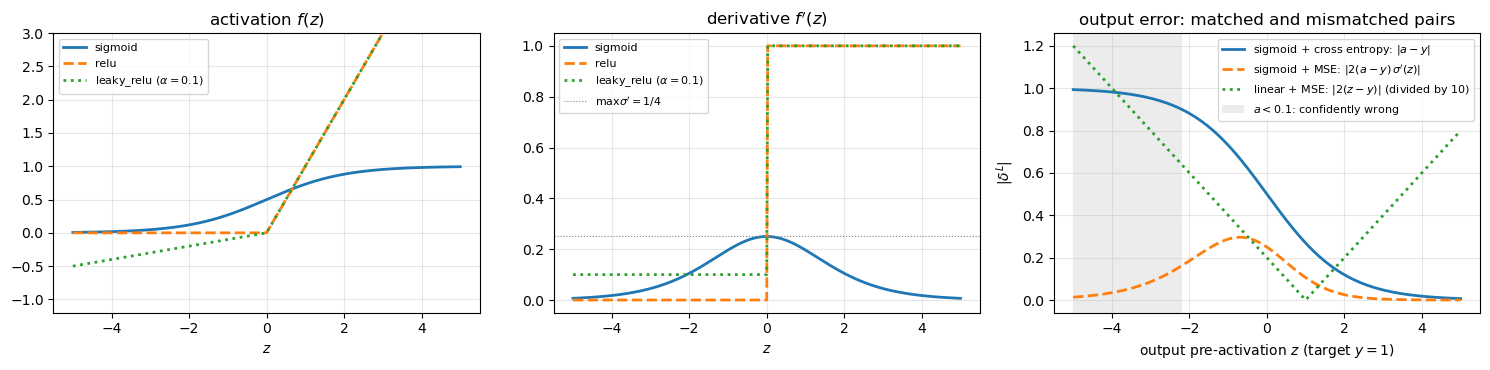

z = -5, y = 1: |delta| sigmoid + cross entropy = 0.9933, sigmoid + MSE = 0.0132, ratio = 75


In [6]:
z_plot = np.linspace(-5, 5, 401)                          # preactivations for the plots
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
# the leaky ReLU is drawn with alpha = 0.1 (the network uses LEAKY_ALPHA = 0.01, which would lie on top of the ReLU)
for name, style, kw in [("sigmoid", "-", {}), ("relu", "--", {}), ("leaky_relu", ":", {"alpha": 0.1})]:
    f, f_der = ACTIVATIONS[name]                          # the function and its derivative (a.2)
    lab = name + (r" ($\alpha=0.1$)" if kw else "")      # say in the legend which alpha is drawn
    axes[0].plot(z_plot, f(z_plot, **kw), style, lw=2, label=lab)  # the function
    axes[1].plot(z_plot, f_der(z_plot, **kw), style, lw=2, label=lab)  # its derivative
axes[0].set_title("activation $f(z)$")
axes[0].set_ylim(-1.2, 3)
axes[1].set_title("derivative $f'(z)$")
axes[1].axhline(0.25, color="gray", lw=0.8, ls=":", label=r"$\max\sigma'=1/4$")
for ax in axes[:2]:
    ax.set_xlabel("$z$")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

# right: the output error delta^L that starts backpropagation, target y = 1, one output node, n = 1
a_sig = sigmoid(z_plot)                                   # output of a sigmoid output node
axes[2].plot(z_plot, np.abs(a_sig - 1.0), lw=2, label=r"sigmoid + cross entropy: $|a-y|$")
axes[2].plot(z_plot, np.abs(2.0 * (a_sig - 1.0) * sigmoid_der(z_plot)), "--", lw=2,
             label=r"sigmoid + MSE: $|2(a-y)\,\sigma'(z)|$")
axes[2].plot(z_plot, np.abs(2.0 * (z_plot - 1.0)) / 10, ":", lw=2, label=r"linear + MSE: $|2(z-y)|$ (divided by 10)")
axes[2].axvspan(-5, np.log(0.1 / 0.9), color="gray", alpha=0.15, lw=0,
                label=r"$a < 0.1$: confidently wrong")   # region where a < 0.1: confidently wrong
axes[2].set_xlabel("output pre-activation $z$ (target $y = 1$)")
axes[2].set_ylabel(r"$|\delta^L|$")
axes[2].set_title("output error: matched and mismatched pairs")
axes[2].legend(fontsize=8)
axes[2].grid(alpha=0.3)
plt.tight_layout()
plt.show()

z5 = -5.0                                                 # a confidently wrong output: sigma(-5) = 0.0067 for target 1
print(f"z = -5, y = 1: |delta| sigmoid + cross entropy = {abs(sigmoid(z5) - 1):.4f}, "
      f"sigmoid + MSE = {abs(2 * (sigmoid(z5) - 1) * sigmoid_der(z5)):.4f}, "
      f"ratio = {abs(sigmoid(z5) - 1) / abs(2 * (sigmoid(z5) - 1) * sigmoid_der(z5)):.0f}")

#### a.5 Figure for the report
**Source:** the functions of a.2 and `z_plot` of a.5. **Modifications:** the colours of the activations used in every figure, y labels, the matched and mismatched pairs in blue and the linear output in black. No new results.
> **LLM note:** Written with Claude (Level 4). New plotting code.

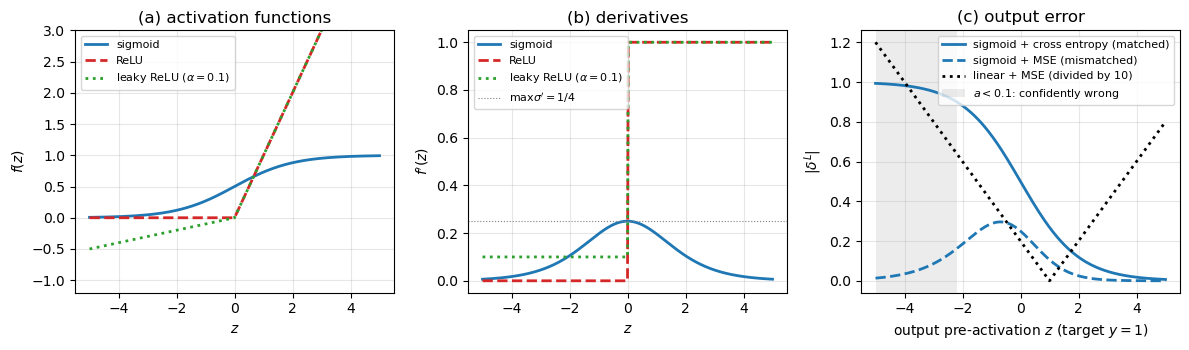

In [7]:
# ---- Figure for the report: a.5 redrawn (the functions of a.2; nothing is recomputed) ----
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for name, style, kw in [("sigmoid", "-", {}), ("relu", "--", {}), ("leaky_relu", ":", {"alpha": 0.1})]:
    f, f_der = ACTIVATIONS[name]                          # the function and its derivative (a.2)
    lab = NICE[name] + (r" ($\alpha=0.1$)" if kw else "")  # say in the legend which alpha is drawn
    axes[0].plot(z_plot, f(z_plot, **kw), style, lw=2, color=COLOR_A[name], label=lab)
    axes[1].plot(z_plot, f_der(z_plot, **kw), style, lw=2, color=COLOR_A[name], label=lab)
axes[0].set_ylim(-1.2, 3); axes[0].set_ylabel("$f(z)$"); axes[0].set_title("(a) activation functions")
axes[1].axhline(0.25, color="gray", lw=0.8, ls=":", label=r"$\max\sigma'=1/4$")
axes[1].set_ylabel("$f'(z)$"); axes[1].set_title("(b) derivatives")
for ax in axes[:2]:
    ax.set_xlabel("$z$"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
a_sig = sigmoid(z_plot)                                   # output of a sigmoid output node
axes[2].plot(z_plot, np.abs(a_sig - 1.0), "-", color="C0", lw=2, label="sigmoid + cross entropy (matched)")
axes[2].plot(z_plot, np.abs(2.0 * (a_sig - 1.0) * sigmoid_der(z_plot)), "--", color="C0", lw=2,
             label="sigmoid + MSE (mismatched)")
axes[2].plot(z_plot, np.abs(2.0 * (z_plot - 1.0)) / 10, ":", color="k", lw=2, label="linear + MSE (divided by 10)")
axes[2].axvspan(-5, np.log(0.1 / 0.9), color="gray", alpha=0.15, lw=0, label=r"$a<0.1$: confidently wrong")
axes[2].set_xlabel("output pre-activation $z$ (target $y=1$)"); axes[2].set_ylabel(r"$|\delta^L|$")
axes[2].set_title("(c) output error"); axes[2].legend(fontsize=8); axes[2].grid(alpha=0.3)
plt.tight_layout()
save_figure(fig, "a5_activations_output_error")
plt.show()

#### a.6 Observations (integrated version, notes for the report)
> **LLM note:** Drafted with Claude from the outputs above and from our question-and-answer session with Claude,
> in which we went through part a) step by step (text Level 3 if used as it is). Rewrite in your own
> words for the report, and check every number against your own run. **[own]** marks reasoning that is not taken from
> the course material.

**What the checks show (a.4, a.5)**

1. **The gradients of a.0 are right (a.4).** Every derivative written by hand agrees with `jax.grad` of independent JAX
   versions (`jax.nn` for the activations, the costs rewritten in `jax.numpy`) to rounding, that is to about $10^{-16}$:
   the derivatives of the activations (ReLU and leaky ReLU exactly, away from $z=0$, where they have no derivative and
   the value is a convention), the derivatives of the three costs with respect to the output, and the full gradients of
   linear regression with the MSE, logistic regression with the binary cross entropy and softmax regression with the
   multiclass cross entropy, Eqs. (3), (6) and (9), each without penalty and with $L_2$ and $L_1$ penalties
   ($\lambda=0.1$). The largest differences in our run were $9.7\cdot10^{-17}$, $2.8\cdot10^{-17}$ and
   $8.9\cdot10^{-16}$; at this level the differences are rounding errors, so only the order of magnitude is
   meaningful [own reading]. These are the two ingredients that
   backpropagation needs in part b): the derivative of the cost with respect to the output, and $f'(z)$ [own].

2. **Matched pairs (a.4, last block).** The derivative of the composed cost $C(f_{\rm out}(\boldsymbol z))$ with respect to
   $\boldsymbol z$ equals $c\,(\boldsymbol a-\boldsymbol y)$, with $c=2/n$ for our MSE and $c=1/n$ for the two cross
   entropies, to rounding ($1.4\cdot10^{-17}$ at most), for the identity with the MSE, the sigmoid with the binary cross
   entropy and the softmax with the multiclass cross entropy. This confirms Eqs. (5), (8) and (10) of a.0. The output
   error $\boldsymbol\delta^L=\partial C/\partial\boldsymbol z^L$ is where backpropagation starts, and because it is simply
   prediction minus target, the network of part b) never needs the $K\times K$ Jacobian of the softmax (Eq. (8.69) of the
   lecture notes; takeaway 3 of the project text).

3. **A mismatched pair (a.5, right).** For a sigmoid output with target 1 and $z=-5$ ($a=\sigma(-5)$, close to 0: confidently wrong),
   $|\delta^L|$ is 0.9933 with the cross entropy and 0.0132 with the MSE, a ratio of 75 (a.5); the ratio is
   $1/(2\sigma'(z))$ [own]. (The lecture finds a factor 150 with the half squared error; our MSE
   has the extra factor 2.) With the MSE the error vanishes where the network is confidently wrong, just as it does where
   it is right, because $\sigma'(z)\to0$ in both tails, so the model learns almost nothing from its worst mistakes; with
   the matched pair it is largest where the network is most wrong (Section 5.3 of the lecture notes, "Why not squared
   error?", and Fig. 5.3). For a linear output with the MSE, $\delta^L=\tfrac2n(\tilde y-y)$ grows linearly with the
   residual: a miss twice as large gives a correction twice as large, which is what regression needs.

4. **The activations (a.5, left and middle).** The derivative of the sigmoid never exceeds $1/4$ (at $z=0$) and is almost
   zero for large $|z|$ (a.5, left); the ReLU passes the error unchanged for $z>0$ and blocks it for $z<0$; the
   leaky ReLU keeps a small slope $\alpha$ there ($\alpha=0.01$ in the network; the figure draws $\alpha=0.1$, since
   $0.01$ cannot be told apart from the ReLU at that scale). In the backward pass every layer multiplies the error by
   $f'(\boldsymbol z^l)$, Eq. (8.66), so the error that reaches the first layer contains one such factor per layer,
   Eq. (8.71): at most $1/4$ per layer with the sigmoid, 1 for the active nodes with the ReLU family. This is the
   vanishing gradient that c.4 measures (Section 8.9 of the lecture notes).

5. **Numerical safety.** Three details keep every number finite. (i) [own] The sigmoid is evaluated as
   $\tfrac12[1+\tanh(z/2)]$, the same function by the identity $\tanh(z)=2\sigma(2z)-1$ of Section 8.6.1. Unlike the
   textbook form $1/(1+e^{-z})$ it cannot overflow for large negative $z$, and it agrees with it to $2.2\cdot10^{-16}$ in
   absolute terms on $[-30,30]$. It is not more accurate than the course's own form (`week41monday.ipynb`, cell 7, which
   uses $e^{-|z|}$): for very negative $z$ the sum $1+\tanh(z/2)$ adds two almost opposite numbers, so the tanh form
   loses relative accuracy where the course's form keeps it [own reading]. For our networks the absolute agreement is
   what matters, and a.2 checks it ($2.2\cdot10^{-16}$) [own reading]. (ii) The softmax subtracts the largest score of each row before exponentiating,
   Eq. (5.30): this changes no probability, and without it large scores would make the exponentials overflow and give
   $\infty/\infty$, that is NaN. (iii) The probabilities inside the logarithms of the cross entropies are clipped to at
   least $10^{-12}$, as in the course code (`week41monday.ipynb`, cell 8), so the loss of one sample is at most
   $\ln 10^{12}$ instead of infinite.

6. **Our conventions [own].** (i) Our MSE has no factor $\tfrac12$ (Eq. (8.32) of the lecture notes has it). This doubles
   the gradient of the data term: plain gradient descent then needs half the learning rate to take the same
   steps, while RMSprop and Adam hardly notice (their step is divided by a running measure of the size of the gradient).
   With a penalty it also changes the balance between the data term and the penalty: our $\lambda$ corresponds to
   $\lambda/2$ in the convention of the course code (`week41monday.ipynb`), so values of $\lambda$ cannot be compared one
   to one with the course's. (ii) We chose it so that a network without hidden layers and with a linear output has
   exactly the cost of Project 1, Eq. (4.16), with the same $\lambda$; b.4 confirms this by reproducing the closed forms
   of Project 1 to about $10^{-15}$. (iii) The penalties act on the weights only (Section 8.12): a bias only shifts the
   output of a node up or down, like the intercept of Project 1, and does not make the fitted function more flexible;
   penalising it would pull the predictions towards zero whatever the data say, which is why the intercept was not
   penalised in Project 1 (Section 3.13). The summary of the project text speaks of "the weights and biases"; the report
   should say that we follow the lecture notes here.

**The concepts behind part a) (our discussion)**

7. **What part a) is for.** Training repeats one loop: a forward pass (in every layer a weighted sum
   $\boldsymbol z^l=\boldsymbol a^{l-1}\boldsymbol W^l+\boldsymbol b^l$ followed by an activation
   $\boldsymbol a^l=f(\boldsymbol z^l)$, Eq. (8.21)), the cost that compares the output with the target, a backward pass
   that gives the gradient with respect to every weight and bias (backpropagation, Section 8.8.4), and an update with
   one of the optimisers of Project 1. Part a) supplies the pieces of the backward pass: the derivative of each cost with
   respect to the output, which starts it, and the derivative $f'(z)$ of each activation, which enters at every layer.

8. **The cost follows from the target.** Each cost is a negative log-likelihood: Gaussian noise on a real target gives
   the MSE, a 0/1 target (Bernoulli) gives the binary cross entropy, and one of $K$ classes (categorical) gives the
   multiclass cross entropy ("the cost function is not a free design decision", introduction of the lecture notes;
   Sections 3.6, 5.3 and 5.6). The likelihood of the training set is the product of the probabilities that the model
   gives to the observed labels; the logarithm turns the product into a sum, and the minus sign turns maximising into
   minimising, Eqs. (5.11) to (5.13).

9. **What the cross entropy measures.** The loss of one sample is $-\ln$(probability given to the true class): close to 0 when
   that probability is close to 1, and without bound as the probability goes to 0. It
   punishes confident mistakes heavily, while the squared error of a probability can never exceed 1 (Fig. 5.3 of the
   lecture notes). Averaged over many uncertain cases its minimum is at the true probability, a proper scoring rule
   (Section 5.10.2, Proposition 5.1): if the label is 1 in a fraction $p$ of the cases that look alike, the average loss
   is smallest for the prediction $p$, so overconfidence costs on average. On the training
   set, however, where every label is known, the cross entropy keeps rewarding more confidence, and with separable
   classes the unpenalised weights grow without bound (Section 5.5). The penalty $\lambda$ and early stopping keep this in
   check.

10. **The two variants of the cross entropy.** The binary cross entropy (log loss) has one sigmoid output node,
    $p=P(y=1)$, a 0/1 target and the loss $-[y\ln p+(1-y)\ln(1-p)]$, where $y$ and $1-y$ switch one of the two terms off.
    The multiclass cross entropy has $K$ softmax output nodes, a one hot target and the loss $-\sum_k y_k\ln a_k$. Both
    are $-\ln$(probability of the true class), and both give the output error prediction minus target. For $K=2$ the
    softmax of two scores is the sigmoid of their difference, $\sigma(z_1-z_0)$, and the multiclass cross entropy becomes
    the binary one (Section 5.6), so the binary case needs one output node instead of two. The technical difference is
    that the sigmoid acts on each node separately, while the softmax couples the $K$ outputs (raising one probability
    lowers the others), so its derivative is a $K\times K$ Jacobian. Softmax with the cross entropy assumes exactly one
    class per sample (one digit per image); a sample with several labels at once would need $K$ separate sigmoids, each
    with its own binary cross entropy [own]. In this project the binary cross entropy is only derived and checked (a.4,
    b.4); the multiclass one is used for MNIST in part e).

11. **What the softmax does.** It turns the $K$ scores $z_k$ of the output layer, which can be any real numbers, into $K$
    probabilities: it exponentiates each score (every value becomes positive and the order is kept) and divides by the
    sum (the values now add up to one), Eq. (5.27). Only the differences between the scores matter: adding the same number to every
    score changes nothing (Section 5.6), which is why the shift of Eq. (5.30) is allowed. It is a smooth version of
    picking the largest score [own]: the predicted class, the one with the largest probability, is always the one with
    the largest score, but unlike a hard maximum the softmax changes smoothly with the scores and can be differentiated.

12. **What an activation function does, and how the three differ.** Each node computes a weighted sum of its inputs plus
    a bias and then applies $f$. Without a non-linear $f$ a network of any depth collapses to a single linear map
    (Sections 8.2 and 8.4 of the lecture notes), no better than linear regression on $x$. With it, a sigmoid node
    $\sigma(wx+b)$ is a smooth step at $x=-b/w$, and the output layer adds such steps up [own picture]; a ReLU node is a
    hinge, and $N$ ReLU nodes give a piecewise linear function with at most $N+1$ pieces (Lemma 8.1, Section 8.4.1). The
    derivative decides how much error flows back (item 4). In the output layer the activation is chosen by the target
    and paired with the cost (item 2): the identity for regression, the softmax for classification. The three hidden
    activations of the project:

| | sigmoid | ReLU | leaky ReLU |
|---|---|---|---|
| $f(z)$ | $1/(1+e^{-z})$, values in $(0,1)$ | $\max(0,z)$, values in $[0,\infty)$ | $z$ for $z>0$, $\alpha z$ for $z\le0$ |
| $f'(z)$ | $\sigma(1-\sigma)\le\tfrac14$ | 1 for $z>0$, 0 for $z<0$ | 1 for $z>0$, $\alpha=0.01$ for $z\le0$ |
| strength | smooth and bounded | does not saturate for $z>0$, so deep networks train | as the ReLU, and the gradient is never exactly zero |
| weakness | saturates for large $\lvert z\rvert$; output not centred, mean near ½ (Section 8.6.1); vanishing gradients in deep networks (Section 8.9) | no derivative at 0 (we use 0); a node with $z<0$ for every sample gets zero gradient for good, the "dying ReLU" (Section 8.6.2) | the same kinks as the ReLU |

13. **Notes for the report [own].** The project text calls the sigmoid the "logit"; the logit $\ln[p/(1-p)]$ is the
    inverse of the sigmoid, and the lecture notes call $\sigma$ "the logistic or sigmoid function" (Section 8.6.1), so we
    do not use "logit" for it. The symbol $\delta$ has two meanings in a.0: the Kronecker delta $\delta_{kj}$ of Eq. (8)
    (1 if $k=j$, 0 otherwise) and the output error $\boldsymbol\delta^L$ of Eq. (10); the report should say so or use
    another symbol for one of them.

### Reminder about the gradient machinery from project 1

In the setup of a neural network code you will need your gradient descent codes from project 1. For neural networks we will recommend using stochastic gradient descent (Section 4.7 of the lecture notes) with either the RMSprop or the Adam algorithms for updating the learning rates (Sections 4.10 and 4.11). But you should feel free to try plain gradient descent as well. As in project 1 and in the lecture notes we call the learning rate $\gamma$ (many texts call it $\eta$).

We recommend reading chapter 8 on optimization from the textbook of Goodfellow, Bengio and Courville at <https://www.deeplearningbook.org/>. This chapter contains many useful insights and discussions on the optimization part of machine learning. A useful reference on the back propagation algorithm is Nielsen’s book at <http://neuralnetworksanddeeplearning.com/>.

You will find the Python [Seaborn package](https://seaborn.pydata.org/generated/seaborn.heatmap.html) useful when plotting the results as function of the learning rate $\gamma$ and the hyperparameter $\lambda$.


### Part b): Writing your own neural network code

Your aim now, and this is the central part of this project, is to write your own FFNN code implementing the back propagation algorithm discussed in the lecture material of week 41 (see <https://github.com/EducationalMaterialUiO/MachineLearningUiO/tree/main/doc/WeeklyMaterial/week41>) and week 42 (see <https://github.com/EducationalMaterialUiO/MachineLearningUiO/tree/main/doc/WeeklyMaterial/week42>), and in Section [8.8](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#backpropagation) of the lecture notes. The notation and the feed-forward pass are set up in Section [8.5](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#notation-and-the-feed-forward-pass), the general dense-layer case and the four equations of backpropagation in Sections [8.8.3](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#the-general-case-dense-layers) and [8.8.4](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#the-four-equations-of-backpropagation), and the full algorithm in Section [8.8.5](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#the-algorithm). A complete network from scratch, including a check of the gradient against automatic differentiation, is discussed in Section [8.13](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#a-neural-network-from-scratch). The exercises of week 41 (`exercisesweek41.ipynb`) give you a template for the code: samples are stored in the rows of the input, the weight matrix of a layer has shape (inputs, outputs), and the feed-forward step of a layer reads `a @ W + b`.

We will focus on a regression problem first, using the one-dimensional Runge function

$$
f(x) = \frac{1}{1+25x^2},
$$

from project 1.

Use only the mean-squared error as cost function (no regularization terms) and write an FFNN code for a regression problem with a flexible number of hidden layers and nodes using only the Sigmoid function as activation function for the hidden layers. Initialize the weights using a normal distribution (see Section [8.10](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#weight-initialisation) for how the width of that distribution should depend on the number of inputs of a layer). How would you initialize the biases? And which activation function would you select for the final output layer? And how would you set up your design/feature matrix? Hint: does it have to represent a polynomial approximation as you did in project 1?

Train your network and compare the results with those from your OLS regression code from project 1 using the one-dimensional Runge function. When comparing your neural network code with the OLS results from project 1, use the same data sets which gave you the best MSE score. Moreover, use the polynomial order from project 1 that gave you the best result. Compare these results with your neural network with one and two hidden layers using $50$ and $100$ hidden nodes, respectively.

Comment your results and give a critical discussion of the results obtained with the OLS code from project 1 and your own neural network code. Make an analysis of the learning rates employed to find the optimal MSE score. Test both stochastic gradient descent with RMSprop and Adam and plain gradient descent with different learning rates.

You should, as you did in project 1, scale your data (Section 3.13 of the lecture notes).


(100, 1) (100,)


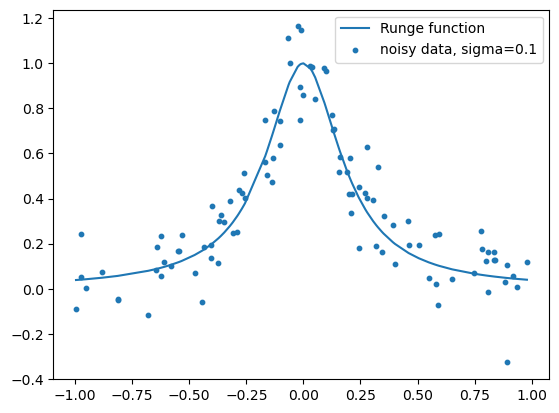

In [8]:
# The data of project 1, as a starting point for part b)
import numpy as np
import matplotlib.pyplot as plt

def runge(x):
    return 1.0 / (1.0 + 25.0 * x**2)

rng = np.random.default_rng(2026)      # fix the seed for reproducible results
n = 100
x = np.sort(rng.uniform(-1.0, 1.0, n))
sigma = 0.1
y = runge(x) + rng.normal(0.0, sigma, n)

# For the network the input is the raw x (one feature), samples in rows
X = x.reshape(-1, 1)
print(X.shape, y.shape)
plt.plot(x, runge(x), label="Runge function")
plt.scatter(x, y, s=10, label=f"noisy data, sigma={sigma}")
plt.legend(); plt.show()


## Code for part b): our own feed forward neural network, and the comparison with OLS from Project 1

The cell above is the course's starter cell, unchanged: it draws the Runge data with seed 2026, $n=100$, $\sigma=0.1$.
The cells below do the rest of part b).

**Where each piece comes from** (course material and Project 1 are cited in the bibliography):

| Cell | Piece | Source | Status |
|---|---|---|---|
| b.1 | `runge`, `MSE`, `R2`, `make_data`, `polynomial_features`, `scale_train_test`, `ols_svd`, `ridge_svd` | our `Project1.ipynb`, cells a.2 to a.5 and the first code cell of part b) (`ridge_svd`) | copied, unchanged |
| b.1 | the data set and the 80/20 split of Project 1; the network input is the raw $x$, standardised; a dense grid inside the training range | `Project1.ipynb` a.3, a.6, a.9; project text, part b) | reused |
| b.2 | the network class: list of layers, feed forward with storage, backpropagation, gradient outside the update | `exercisesweek42_solutions.ipynb`, exercises 5 to 8 (`NeuralNetwork`, `backpropagation_batch`, `output_error`); `week41monday.ipynb`, Part 2 (`create_layers`, `feed_forward`, `backpropagation` with penalties); lecture notes Sections 8.5, 8.8.3 to 8.8.5, 8.10, 8.13 | adapted |
| b.3 | `optimiser_step` (plain, AdaGrad, RMSprop, Adam) | `Project1.ipynb` f.1, itself `week38tuesday.ipynb`, Case 1, Step 2 | copied (argument named `gamma` again, a few comments added or reworded, the momentum branch removed) |
| b.3 | `make_batches`; the training loop `train_network`, with early stopping | `Project1.ipynb` h.1 (`make_batches`, `sgd`), from `week38tuesday.ipynb`, Case 2, Steps 1 and 2; lecture notes Section 8.12 (early stopping) | copied / adapted |
| b.4 | gradient check against `jax.grad` and finite differences | `week41monday.ipynb`, Part 2 (`gradient_check`, `jax_cost`, `jax_check`); lecture notes Eq. (4.102) and Section 8.8.5 | adapted |
| b.4 | a network without hidden layers reproduces the closed forms of Project 1 | project text, takeaway 10; `Project1.ipynb` e.3 and g.2 | new code |
| b.5 | OLS benchmark: Project 1's best degree, and the degree chosen by cross validation on the training data | `Project1.ipynb` a.7, d.1 (`make_ols_pipeline`, `make_ridge_pipeline`, `cv_mse`), i.1 (`make_lasso_pipeline`, `cv_mse_converged`), i.3 (`cv_mse_se`); `week44tuesday.ipynb`, Case 2, Step 5 | copied, unchanged |
| b.5 | cross validation of the network with the scaling inside the folds | `week44tuesday.ipynb`, Part A (CV on the 80 non-test points, refit, test once) and Case 2 (same `KFold` for every model); `Project1.ipynb` d.1 | new code, same idea |
| b.6 | learning rates for plain GD, RMSprop and Adam, full batch and SGD | `Project1.ipynb` f.2, h.2 and h.4; `week38tuesday.ipynb`, Case 1, Step 4; `week44tuesday.ipynb`, Case 2 (defaults of `Week41Regressor`: one hidden layer of 50 sigmoid nodes, 1000 epochs; Step 3 for the settings within one standard error) | adapted |
| b.7 | one and two hidden layers of 50 and 100 nodes against OLS; Scikit-Learn's `MLPRegressor` | project text, part b) and takeaway 10; lecture notes Section 8.14 ("Using established libraries" and "Handwritten digits", comparison with `MLPClassifier`) | new code |

**Setup.** The data set is the one of Project 1 that gave our best OLS result: $n=100$ points, $x$ uniform on
$[-1,1]$, $\sigma=0.1$, seed 2026, and the same 80/20 split (`random_state=2026`): 80 training and 20 test points.
The best polynomial order of Project 1 was **degree 8** (test MSE 0.0187, cell a.7 there). That degree was chosen on the
test set in Project 1, which is optimistic. In this project every hyperparameter of the network is chosen by **5 fold
cross validation on the 80 training points**, with the scaling refitted inside every fold (`week44tuesday.ipynb`,
Case 2), and the test set is used only to report the selected models. For a fair benchmark we also select the OLS degree
in the same way, on the same folds. We use $k=5$ folds of 16 points: in Project 1 (d.2) 5 and 10 folds selected the same
model, every scan of a network costs $k$ trainings per cell, and 10 folds would leave only 8 points to validate on in each
fold. **Selection rule, used in the whole notebook:** the setting with the lowest CV error (for MNIST, the highest
validation accuracy). The cells also report which settings lie within one standard error of it; among those, the one
standard error rule of Section 3.14, Eq. (3.96) (used in `week44tuesday.ipynb`, Part A and Case 2, Step 3), would take
the simplest model, and the observations of parts c) and d) say where that would change the choice.

**The design matrix of the network.** It does *not* need polynomial features: the input is the raw $x$, one column,
standardised with the training statistics as in Project 1 (`scale_train_test`), and $y$ is centred with its training
mean, which is added back to every prediction (the intercept of Project 1). The hidden layers build their own features
of $x$ (takeaway 1 of the project text). **Output activation:** the identity, because the target is a real number and
the identity with the MSE is a matched pair, $\delta^L=\frac2n(a^L-y)$ (Eq. (10) of a.0); a sigmoid output could not
even take negative values, and its $\sigma'$ would shrink the gradient (a.5). **Initialisation** (Section 8.10): weights
from a normal distribution with variance $1/M_{l-1}$ for sigmoid networks (Eq. (8.72) with $\mathrm{Var}(z)=\mathrm{Var}(a)$, the forward condition of Glorot and Bengio)
and $2/M_{l-1}$ (He, Eq. (8.74)) for the ReLU family, $M_{l-1}$ being the number of inputs of the layer, as in
`create_layers` of `week41monday.ipynb`; biases $0.01$, a small constant as in the course code: random weights already
break the symmetry, so the biases need not be random.

> **LLM note:** All code cells of part b) were written with Claude Opus 5.5 (claude.ai, October 2026) at Level 4,
> using the course material and our Project 1 code listed above as the base. We asked for an explanation of each line
> and checked the results against `jax.grad`, finite differences, the closed forms of Project 1 and Scikit-Learn.

#### b.1 The functions of Project 1, the data set and the split
**Source:** the eight functions are copied unchanged from our `Project1.ipynb` (cells a.2, a.3, a.4 and a.5, and the
first code cell of part b) for `ridge_svd`), with their original comments; "below", "test below" and "cell a.11" in their docstrings
refer to the cells of Project 1. `runge` is the function of the Project 1 starter cell and `MSE`, `R2` are those of
`week35tuesday.ipynb`, with comments written with Claude (Project 1, a.2); the other five carry their LLM declarations
in the docstrings. The 80/20 split is the one of Project 1, a.6 (same `train_test_split` call and seed), and the dense
grid inside the training range is the one of Project 1, a.9. **Modifications:** the design matrix is the raw $x$ as
one column, standardised with `scale_train_test`, instead of the polynomial features (project text, part b); the grid
is scaled with the training statistics like the test points. The data are drawn again with `make_data` and compared
with the arrays of the course's starter cell above: the starter cell uses `rng.normal(0.0, sigma, n)`, Project 1 used
`sigma * rng.standard_normal(n)`, and with the same seed the two must give the same numbers, so the data set is exactly
the one of Project 1.
> **LLM note:** The copied functions are those of Project 1, with the declarations above; the new lines of this cell
> were written with Claude (Level 4).

In [9]:
# Your code for part b) here
# ---- copied unchanged from Project1.ipynb (cells a.2, a.3, a.4, a.5, and the first code cell of part b) ----
def runge(x):
    # Runge's function f(x) = 1 / (1 + 25 x^2); works element-wise on a whole NumPy array
    return 1.0 / (1.0 + 25.0 * x**2)


def MSE(y_data, y_model):
    # residuals y_i - y~_i, squared one by one, then averaged over the n points
    return np.mean((y_data - y_model) ** 2)


def R2(y_data, y_model):
    # numerator:   residual sum of squares, sum_i (y_i - y~_i)^2  -> what the model misses
    # denominator: total sum of squares,    sum_i (y_i - ybar)^2  -> spread of the data around its mean
    # R2 = 1 is a perfect fit, R2 = 0 is no better than always predicting the mean.
    # The ORDER of the arguments matters: the denominator must be built from the TRUE data y_data.
    return 1.0 - np.sum((y_data - y_model) ** 2) / np.sum((y_data - np.mean(y_data)) ** 2)


def make_data(n, sigma, seed=SEED):
    """
    n points with x ~ Uniform[-1, 1] and y = f(x) + sigma * eps, eps ~ N(0, 1).

    LLM-assisted
    ------------
    Tool: Claude (Claude Opus 5.5, claude.ai, September 2026)
    Role: Turned the data cell of the Project1.ipynb starter into a function of (n, sigma, seed).
    Verification: plotted against the noise-free function below.
    """
    rng = np.random.default_rng(seed)        # new random generator with a fixed seed -> same numbers on every call
    x = np.sort(rng.uniform(-1.0, 1.0, n))   # n uniform inputs on [-1, 1]; sorted only so that line plots look clean
    eps = rng.standard_normal(n)             # n draws from N(0, 1)
    y = runge(x) + sigma * eps               # scaling by sigma gives noise with variance sigma^2
    return x, y


def polynomial_features(x, degree):
    """
    Design matrix with the columns x, x^2, ..., x^degree (no column of ones).

    LLM-assisted
    ------------
    Tool: Claude (Claude Opus 5.5, claude.ai, September 2026)
    Role: Adapted np.vander from week35tuesday.ipynb; removed the column of ones.
    """
    # np.vander(..., increasing=True) returns the columns x^0, x^1, ..., x^degree.
    # [:, 1:] drops the first column (x^0 = 1): the intercept is handled by centring instead.
    return np.vander(x, N=degree + 1, increasing=True)[:, 1:]


def scale_train_test(X_train, X_test, y_train):
    """
    Standardise the columns of X and centre y, with TRAINING statistics only.

    Returns X_train_s, X_test_s, y_train_c, y_mean. The model prediction is
    X_s @ theta + y_mean, so y_mean plays the role of the intercept.

    LLM-assisted
    ------------
    Tool: Claude (Claude Opus 5.5, claude.ai, September 2026)
    Role: Rewrote the scaling of week35tuesday.ipynb (Cases 1 and 4) as a function
          that also transforms the test matrix.
    Verification: predictions identical to OLS with an explicit intercept column
                  and to Scikit-Learn (cell a.11).
    """
    X_mean = X_train.mean(axis=0)   # mean of every column, computed from the training rows only
    X_std = X_train.std(axis=0)     # standard deviation of every column (ddof=0, as StandardScaler), training rows only
    y_mean = y_train.mean()         # mean of the training targets -> this becomes the intercept

    X_train_s = (X_train - X_mean) / X_std   # training columns now have mean 0 and standard deviation 1
    X_test_s = (X_test - X_mean) / X_std     # test columns shifted and divided by the SAME training numbers:
                                             # the test set must stay unseen, exactly like new data would be
    y_train_c = y_train - y_mean             # centred training targets (mean 0)
    return X_train_s, X_test_s, y_train_c, y_mean


def ols_svd(X, y):
    """
    OLS parameters theta = X^+ y through the thin SVD X = U diag(s) V^T.

    Working with X itself (not X^T X) avoids squaring the condition number.

    LLM-assisted
    ------------
    Tool: Claude (Claude Opus 5.5, claude.ai, September 2026)
    Role: Adapted ridge_svd (week35tuesday.ipynb, Case 2) to lambda = 0 and added
          the pseudoinverse cutoff of np.linalg.lstsq.
    Verification: agrees with np.linalg.pinv and np.linalg.lstsq (test below).
    """
    U, s, Vt = np.linalg.svd(X, full_matrices=False)    # thin SVD: U is n x p, s holds p singular values
                                                        # (largest first), Vt is p x p
    cutoff = np.finfo(float).eps * max(X.shape) * s[0] # machine epsilon x largest dimension x largest singular value
    keep = s > cutoff                                   # True for directions that carry information,
                                                        # False for directions that are pure rounding noise
    coeffs = (U[:, keep].T @ y) / s[keep]               # components of y along the kept u_i, divided by s_i
    return Vt[keep].T @ coeffs                          # map back to parameter space: theta = sum_i coeff_i * v_i


def ridge_svd(X, y, lam):
    """
    Ridge parameters theta = (X^T X + lam I)^{-1} X^T y through the thin SVD, Eq. (3.46).
    Cost: ||y - X theta||^2 + lam ||theta||^2 (no 1/n), same as sklearn Ridge(alpha=lam).

    LLM-assisted
    ------------
    Tool: Claude (Claude Opus 5.5, claude.ai, September 2026)
    Role: Comments only; the function is ridge_svd from week35tuesday.ipynb, Case 2.
    Verification: lam = 0 reproduces ols_svd; agrees with the normal equations and sklearn (below).
    """
    U, s, Vt = np.linalg.svd(X, full_matrices=False)   # thin SVD X = U diag(s) V^T, as in ols_svd
    factor = s / (s**2 + lam)                           # Eq. (3.46): OLS has 1/s_i, Ridge has s_i/(s_i^2 + lam)
    return Vt.T @ (factor * (U.T @ y))                  # theta = sum_i factor_i * (u_i^T y) * v_i
# ---- end of the code copied from Project 1 ----

x_template, y_template = x.copy(), y.copy()               # the arrays of the course's starter cell above
x, y = make_data(n=100, sigma=0.1)                        # the data set of Project 1: n = 100, sigma = 0.1, seed 2026
print("starter cell and Project 1 give the same data:", np.array_equal(x, x_template), np.array_equal(y, y_template))

# the 80/20 split of Project 1 (same seed): 80 training points for everything, 20 test points for the final report
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=TEST_SIZE, random_state=SEED)
# design matrix of the network: the raw x as ONE column, standardised with the training statistics, y centred
X_train_s, X_test_s, y_train_c, y_mean = scale_train_test(x_train[:, None], x_test[:, None], y_train)
Y_train_c = y_train_c[:, None]                            # targets as a column, the shape of the network output (n, 1)
x_grid = np.linspace(x_train.min(), x_train.max(), 500) # dense grid inside the training range (Project 1, a.9)
X_grid_s = scale_train_test(x_train[:, None], x_grid[:, None], y_train)[1]  # the grid, scaled like the test points
print(f"{len(x_train)} training points, {len(x_test)} test points; "
      f"training mean of x = {x_train.mean():.3f}, std = {x_train.std():.3f}, mean of y = {y_mean:.3f}")

starter cell and Project 1 give the same data: True True
80 training points, 20 test points; training mean of x = 0.029, std = 0.491, mean of y = 0.374


#### b.2 The neural network
**Source:** the class follows the `NeuralNetwork` class of `exercisesweek42_solutions.ipynb`, exercise 8: it stores the
parameters and the functions that define the network and nothing else, and the gradient method stays outside the
class; `feed_forward_saver` keeps every layer input and every $\boldsymbol z^l$; `compute_gradient` is the batched
backpropagation of exercise 6 there (`backpropagation_batch`: the error propagates as `delta @ W.T`, the gradients are
`layer_input.T @ delta` and `delta.sum(axis=0)`), with the shortcut `output_error` of exercise 7 for matched pairs. The
initialisation (variance $1/M_{l-1}$, He variance $2/M_{l-1}$ for ReLU, biases 0.01) and the penalties on the weights
follow `create_layers` and `backpropagation` of `week41monday.ipynb`, Part 2.

**Modifications:** (1) one activation per layer, given by name and looked up with its derivative in the dictionary of
a.2, since the project text asks for a changeable activation function in each layer; the He variance is used for the
leaky ReLU as well; (2) a changeable cost from a.3, as the project text asks: for the matched pairs the output error is
$\boldsymbol\delta^L=c\,(\boldsymbol a^L-\boldsymbol y)$, Eq. (10) of a.0, chosen automatically from the pair (output
activation, cost) in `MATCHED`, with $c=2/n$ or $1/n$ because our costs are averages (exercise 7 has
$\boldsymbol a^L-\boldsymbol y$, since its cross entropy is a sum); for the other pairs the general
$\boldsymbol\delta^L=f'(\boldsymbol z^L)\circ\partial C/\partial\boldsymbol a^L$, Eq. (8.65), which needs an elementwise
output activation, so the softmax is used only with the cross entropy; (3) an optional $L_2$ or $L_1$ penalty on the
weights only, one at a time (Section 8.12); (4) all weights and biases are stored in one vector `theta`, and `layers`
holds $(\boldsymbol W^l,\boldsymbol b^l)$ pairs that are *views* into it, so that `optimiser_step` of Project 1 works
with no change to its arithmetic (b.3; takeaway 4 of the project text). Hence the class has no `update_weights`, and
the JAX methods of exercise 8 are left out, since b.4 has its own JAX cost.
> **LLM note:** Written with Claude (Level 4), adapted from `exercisesweek42_solutions.ipynb` (exercises 5 to 8) and
> `week41monday.ipynb` (Part 2).

In [10]:
# matched output/cost pairs of a.0, Eq. (10): the output error delta^L = dC/dz^L is c (a - y), without any f'
MATCHED = {("identity", "mse"): lambda a, y: 2.0 * (a - y) / a.size,  # c = 2/n for our MSE
           ("sigmoid", "bce"): lambda a, y: (a - y) / a.size,  # c = 1/n
           ("softmax", "cross_entropy"): lambda a, y: (a - y) / a.shape[0]}  # c = 1/n, n = number of rows


class FFNN:
    """
    Fully connected feed forward neural network trained by backpropagation (samples in rows, W of shape (in, out)).

    layer_sizes : [M_0, M_1, ..., M_L], e.g. [1, 50, 1]: one input, one hidden layer of 50 nodes, one output
    activations : L names from ACTIVATIONS, one per layer; the last one is the output activation
    cost        : "mse", "bce" or "cross_entropy" (COSTS of a.3)
    lmbda       : weight of the optional penalty (0 = no penalty); penalty: "l2" or "l1", on the weights only
    seed        : seed of the initial weights

    LLM-assisted
    ------------
    Tool: Claude (Claude Opus 5.5, claude.ai, October 2026)
    Role: Wrote the class from NeuralNetwork of exercisesweek42_solutions.ipynb (exercise 8) and create_layers /
          backpropagation of week41monday.ipynb; added per layer activations, changeable cost, L1/L2 penalties and the
          single parameter vector theta with (W, b) views.
    Verification: gradients against jax.grad and finite differences (b.4); no hidden layer reproduces the closed forms
                  of Project 1 (b.4); comparison with Scikit-Learn (b.7, e.7).
    """

    def __init__(self, layer_sizes, activations, cost="mse", lmbda=0.0, penalty="l2", seed=SEED):
        # one name per weight layer
        assert len(activations) == len(layer_sizes) - 1, "one activation per layer (hidden layers and output)"
        self.layer_sizes = list(layer_sizes)              # number of nodes per layer, inputs first, outputs last
        self.activations = list(activations)              # activation of layers 1, ..., L
        self.cost_name = cost                             # name of the cost function
        self.lmbda, self.penalty = lmbda, penalty         # optional penalty on the weights
        rng = np.random.default_rng(seed)                 # own generator: the same seed gives the same initial network
        L = len(self.layer_sizes) - 1                     # number of layers with weights (hidden layers + output layer)
        params = []                                       # flattened W^1, b^1, W^2, b^2, ... in this order
        for l, (n_in, n_out) in enumerate(zip(self.layer_sizes[:-1], self.layer_sizes[1:])):
            # Section 8.10: the variance is set by the hidden activation (the output layer uses the one of the last
            # hidden layer, whose activations are its inputs), as create_layers of week41monday.ipynb
            act = self.activations[min(l, L - 2)] if L > 1 else "identity"
            var = 2.0 / n_in if act in ("relu", "leaky_relu") else 1.0 / n_in  # He (8.74) or 1/M_{l-1} (8.72)
            W = rng.normal(0.0, np.sqrt(var), size=(n_in, n_out))  # weights of shape (inputs, outputs), Eq. (8.21)
            b = np.full(n_out, 0.01)                      # biases: a small constant, as in the course code
            params += [W.ravel(), b]                      # flatten W row by row, then append b
        self.theta = np.concatenate(params)               # ALL parameters in one vector, like theta in Project 1
        self.layers = self._views(self.theta)             # (W, b) pairs that are views into theta, not copies

    def _views(self, theta):
        # cut the vector theta into the (W, b) of every layer; reshape of a slice is a view, so changing theta
        # in place changes W and b as well
        layers, i = [], 0                                 # the (W, b) pairs, and our position in theta
        for n_in, n_out in zip(self.layer_sizes[:-1], self.layer_sizes[1:]):
            W = theta[i:i + n_in * n_out].reshape(n_in, n_out)  # the next n_in * n_out numbers, as a matrix
            i += n_in * n_out                             # move past the weights
            b = theta[i:i + n_out]                        # the next n_out numbers: the biases
            i += n_out                                    # move past the biases
            layers.append((W, b))                         # the pair of this layer
        return layers

    def feed_forward_saver(self, X):
        # Eq. (8.21) layer by layer, keeping every layer input a^{l-1} and preactivation z^l: the backward pass needs them
        layer_inputs, zs, a = [], [], X                   # a^0 = X: the input is the output of layer 0
        for (W, b), name in zip(self.layers, self.activations):
            layer_inputs.append(a)                        # a^{l-1}, needed for dC/dW^l, Eq. (8.68)
            z = a @ W + b                                 # Z^l = A^{l-1} W^l + b^l, one row per sample
            zs.append(z)                                  # z^l, needed for f'(z^l), Eq. (8.66)
            a = ACTIVATIONS[name][0](z)                   # A^l = f(Z^l)
        return layer_inputs, zs, a

    def predict(self, X):
        # the same feed forward pass, without storing anything (for predictions)
        a = X
        for (W, b), name in zip(self.layers, self.activations):
            a = ACTIVATIONS[name][0](a @ W + b)           # Eq. (8.21) followed by the activation of the layer
        return a

    def cost(self, X, Y):
        # cost function of a.3 on (X, Y), plus the penalty on the weights if lmbda > 0
        value = COSTS[self.cost_name][0](self.predict(X), Y)  # data term of a.3 on the network output
        if self.lmbda > 0.0:
            # penalty on every W (biases free)
            value += sum(penalty_value(W, self.lmbda, self.penalty) for W, _ in self.layers)
        return value

    def compute_gradient(self, X, Y):
        # backpropagation, Eqs. (8.65) to (8.68) for a whole batch; returns [(dC/dW^l, dC/db^l)] with the shapes of (W^l, b^l)
        layer_inputs, zs, a = self.feed_forward_saver(X)  # forward pass, storing what the backward pass needs
        grads = [None] * len(self.layers)                 # one (dW, db) per layer, filled from the end
        out = self.activations[-1]                        # name of the output activation
        for l in reversed(range(len(self.layers))):       # from the output layer back to the first layer
            if l == len(self.layers) - 1:                 # output layer, Eq. (8.65)
                if (out, self.cost_name) in MATCHED:      # matched pair: delta^L = c (a - y), Eq. (8.69)
                    delta = MATCHED[(out, self.cost_name)](a, Y)  # c (a - y)
                else:                                     # general case, elementwise output activation only
                    # f'(z^L) times dC/da^L, Eq. (8.65)
                    delta = COSTS[self.cost_name][1](a, Y) * ACTIVATIONS[out][1](zs[l])
            else:                                         # hidden layer, Eq. (8.66) with samples in rows
                # delta^{l+1} W^T, times f'(z^l)
                delta = (delta @ self.layers[l + 1][0].T) * ACTIVATIONS[self.activations[l]][1](zs[l])
            W = self.layers[l][0]                         # weights of layer l (for the penalty)
            dW = layer_inputs[l].T @ delta                # Eq. (8.68): a^{l-1} times delta^l, summed over the samples
            if self.lmbda > 0.0:
                dW = dW + penalty_grad(W, self.lmbda, self.penalty)  # Section 8.12: penalty on the weights only
            db = np.sum(delta, axis=0)                    # Eq. (8.67): the error, summed over the samples
            grads[l] = (dW, db)                           # the gradients of layer l
        return grads

    def gradient(self, X, Y):
        # the same gradient as ONE vector, in the order of theta, for the optimisers of Project 1
        return np.concatenate([np.concatenate([dW.ravel(), db]) for dW, db in self.compute_gradient(X, Y)])


net_demo = FFNN([1, 50, 50, 1], ["sigmoid", "sigmoid", "identity"])  # example: two hidden layers of 50 nodes
print("number of parameters:", net_demo.theta.size, "= 1*50 + 50 + 50*50 + 50 + 50*1 + 1")
print("shapes of (W, b) per layer:", [(W.shape, b.shape) for W, b in net_demo.layers])
print("the layers are views into theta:", all(np.shares_memory(W, net_demo.theta) for W, _ in net_demo.layers))

number of parameters: 2701 = 1*50 + 50 + 50*50 + 50 + 50*1 + 1
shapes of (W, b) per layer: [((1, 50), (50,)), ((50, 50), (50,)), ((50, 1), (1,))]
the layers are views into theta: True


#### b.3 The optimisers of Project 1, and the training loop
**Source:** `optimiser_step` is copied from our `Project1.ipynb`, cell f.1, which is `optimiser_step` of
`week38tuesday.ipynb`, Case 1, Step 2 (course code), with the comments of Project 1 (equation numbers of the lecture
notes: AdaGrad Eqs. (4.58) to (4.61), RMSprop Eqs. (4.63), (4.64), Adam Eqs. (4.67) to (4.71); the
comments of `week38tuesday.ipynb` refer to an older numbering of the notes). `make_batches` is copied from
`Project1.ipynb`, h.1 (`week38tuesday.ipynb`, Case 2, Step 1), with two comments added. `train_network` follows `sgd`
of `Project1.ipynb`, h.1 (from `week38tuesday.ipynb`, Case 2, Step 2): a new shuffle every epoch, one update per
minibatch, the update counter $t$ for Adam's bias correction. **Modifications:** (1) in Project 1 we had renamed the
learning rate `eta`; here it is `gamma` again, as in the course code and in the project text, and a few lines of
`optimiser_step` got a comment or a reworded one; (2) the momentum branch of Project 1 is removed, since the project
text asks only for plain gradient descent, RMSprop and Adam (part b) and item 4 of the required implementation); the
arithmetic of the other branches is unchanged; (3) the gradient is the network's
backpropagation and the parameters are `net.theta`, which start from the initial weights of b.2 (not from zero) and
are updated in place so that the views of b.2 follow; (4) `batch_size=None` means one batch with all the data, that is
plain gradient descent, Eq. (4.15); (5) the learning rate is always constant: the schedule of `sgd` (Eq. (4.52),
`step_length`) is not used for the network; (6) instead of the distance to the closed form and the excess cost of
Project 1, which need a closed form solution, an optional `monitor` records any quantity every few epochs, and
`keep_best` restores the parameters at the epoch where a monitored validation error was lowest (early stopping,
Section 8.12; used in e.7); (7) as in `sgd`, a diverging run is stopped, but the test is now that the parameters are
no longer finite, since there is no closed form to measure the distance to, and the run is marked as diverged in the
history.
> **LLM note:** `optimiser_step` and `make_batches` are course code via Project 1 (comments written with Claude; the
> momentum branch removed since it was not requested for project2); `train_network` was adapted with Claude (Level 4) from `sgd` of Project 1.

In [11]:
def optimiser_step(method, theta, g, state, t, gamma, rho=0.99,
                   beta1=0.9, beta2=0.999, eps=1e-8):
    """
    One update of theta from the gradient g at step t (t = 1, 2, ...), with learning rate gamma.
    state carries the running quantities (r for AdaGrad/RMSprop, m and r for Adam).

    Source: Project1.ipynb, cell f.1, which is week38tuesday.ipynb, Case 1, Step 2 (course code);
    the learning rate is called gamma again, as in the course code; the momentum branch is removed, since the
    project text does not ask for momentum.
    """
    if method == "plain":
        return theta - gamma * g, state                   # Eq. (4.15): fixed learning rate
    if method == "adagrad":
        r = state.get("r", 0.0) + g * g                   # Eq. (4.58): running SUM of squared gradients
        state["r"] = r                                    # remember the running sum or average
        return theta - gamma * g / (np.sqrt(r) + eps), state  # Eqs. (4.60) to (4.61): per coordinate step
    if method == "rmsprop":
        r = rho * state.get("r", 0.0) + (1.0 - rho) * g * g  # Eq. (4.63): decaying AVERAGE of squared gradients
        state["r"] = r                                    # remember the running sum or average
        return theta - gamma * g / (np.sqrt(r) + eps), state  # Eq. (4.64)
    if method == "adam":
        m = beta1 * state.get("m", 0.0) + (1.0 - beta1) * g  # Eq. (4.67): first moment (momentum term)
        r = beta2 * state.get("r", 0.0) + (1.0 - beta2) * g * g  # Eq. (4.68): second moment (RMS term)
        state["m"], state["r"] = m, r                     # remember both moments
        m_hat = m / (1.0 - beta1**t)                      # Eq. (4.70): bias correction
        r_hat = r / (1.0 - beta2**t)                      # Eq. (4.70) for the second moment
        return theta - gamma * m_hat / (np.sqrt(r_hat) + eps), state  # Eq. (4.71)
    raise ValueError(f"unknown method {method}")          # a misspelt name stops the run


def make_batches(n, batch_size, rng):
    """Shuffle the indices and split them into minibatches (Section 4.7). Source: week38tuesday.ipynb, via Project 1, h.1."""
    idx = rng.permutation(n)                              # a random order of the n samples
    return [idx[i:i + batch_size] for i in range(0, n, batch_size)] # consecutive chunks of batch_size indices


def train_network(net, X, Y, method="adam", gamma=0.01, epochs=1000, batch_size=None, seed=SEED,
                  monitor=None, record_every=1, keep_best=None, **opt_kw):
    """
    Train net in place with minibatch SGD, Eq. (4.37), and any method of optimiser_step;
    batch_size=None is plain (full batch) gradient descent, Eq. (4.15).
    monitor(net) -> dict of numbers, recorded every record_every epochs; keep_best = the name of a monitored quantity
    to minimise: at the end the parameters of the epoch with its lowest value are restored (early stopping).
    Returns a history dict with the monitored values; history["diverged"] is True if the parameters overflowed.

    LLM-assisted
    ------------
    Tool: Claude (Claude Opus 5.5, claude.ai, October 2026)
    Role: Adapted sgd of Project1.ipynb, h.1 (from week38tuesday.ipynb, Case 2, Step 2) to the network; added the
          monitor and early stopping, and changed the divergence check.
    Verification: reproduces the closed form solutions of Project 1 for a network without hidden layers (b.4).
    """
    rng = np.random.default_rng(seed)                     # shuffling generator: same seed, same minibatches
    n = X.shape[0]                                        # number of training samples
    M = n if batch_size is None else batch_size           # full batch = plain gradient descent
    state, t = {}, 0                                      # optimiser state and update counter
    history = {"epoch": [], "diverged": False}            # monitored values, one entry per recorded epoch
    best_value, best_theta = np.inf, None                 # for early stopping
    with np.errstate(over="ignore", invalid="ignore"):    # a diverging run may overflow: we detect it below instead
        for epoch in range(1, epochs + 1):
            for idx in make_batches(n, M, rng):           # a new shuffle every epoch
                t += 1                                    # t counts updates (Adam's bias correction needs it)
                g = net.gradient(X[idx], Y[idx])          # minibatch gradient by backpropagation (b.2)
                theta_new, state = optimiser_step(method, net.theta, g, state, t, gamma, **opt_kw)  # one update
                net.theta[:] = theta_new                  # update in place: the (W, b) views of net.layers follow
            if not np.all(np.isfinite(net.theta)):        # the parameters overflowed: the run has diverged
                history["diverged"] = True                # mark the run as diverged
                break
            if monitor is not None and (epoch % record_every == 0 or epoch == epochs):
                values = monitor(net)                     # for example training and validation errors
                history["epoch"].append(epoch)            # the epoch of this record
                for key, value in values.items():
                    history.setdefault(key, []).append(value)  # one list per monitored quantity
                if keep_best is not None and values[keep_best] < best_value:  # new best validation value
                    best_value, best_theta, history["best_epoch"] = values[keep_best], net.theta.copy(), epoch  # copy
    if keep_best is not None and best_theta is not None:
        net.theta[:] = best_theta                         # early stopping: back to the best monitored epoch
    return history

#### b.4 Verification: backpropagation against `jax.grad` and finite differences, and the closed forms of Project 1
**Source:** (1) the two independent referees of `week41monday.ipynb`, Part 2 (`gradient_check`: central differences of
Eq. (4.102) on random weights, relative discrepancy; `jax_cost` / `jax_check`: the same cost written in `jax.numpy` and
differentiated by `jax.grad`), and the recommendation of Section 8.8.5 of the lecture notes. (2) Takeaway 10 of the
project text: a network *without hidden layers* and with a linear output computes $\tilde{\boldsymbol y}=\boldsymbol
X\boldsymbol w+b$ and, with our MSE, has the cost Eq. (4.16) of Project 1; trained on the standardised polynomial
features of Project 1 it must converge to the closed forms `ols_svd` and `ridge_svd` (with $n\lambda$, the conventions
box of Project 1, part e), and with the $L_1$ penalty to the Lasso solution of Scikit-Learn with $\alpha=\lambda/2$
(Project 1, g.2). The bias must go to zero, because the columns are centred and $y$ is centred. **Modifications:**
our network class and a JAX cost written for it (our MSE without the factor $\tfrac12$, one penalty at a time, JAX's own
activations), all three hidden activations, three matched pairs and one mismatched pair (sigmoid output with the MSE),
both penalties; for the closed forms degree 5 and $\lambda=10^{-2}$ as in Project 1, parts e) to g), plain gradient
descent from the network's random initial weights at the optimal fixed learning rate
$\gamma^*=2/(\lambda_{\max}+\lambda_{\min})$ of the Hessian, Eq. (4.26) (the bias adds the eigenvalue 2 to the Hessian
of Project 1, because its column is a column of ones and the other columns are centred), for 20000 epochs, enough to
reach rounding for OLS and Ridge; for the Lasso, whose subgradient has no Hessian, a fixed small step $\gamma=0.01$ for
50000 epochs, which reaches the Scikit-Learn solution to about four decimals, as in Project 1. **Test settings:** the
test setup is the one of the gradient check in `week41monday.ipynb`, Part 2: 20 random samples with 5 features, the
network $5\to7\to6\to$ output, real, binary and one hot targets, penalties of $10^{-3}$ (both at once there, one at a
time here) and the step $h=10^{-6}$ of `gradient_check` (Section 4.15 of the lecture notes suggests $h$ around
$10^{-5}$); `gradient_check` compares 20 random weights per layer, we compare 20 random entries of `theta` per network,
weights and biases. `week41monday.ipynb` expects a relative discrepancy of $10^{-6}$ or smaller; the few entries above
it are discussed in b.8. We added targets in $(0,1)$ for the mismatched pair. Why this setup is a good test [own]: the
networks are small, so that every check is fast; they have two hidden layers, so that the recursion
Eq. (8.66) is used between hidden layers; and the widths differ, so that a transposed weight matrix would stop the code
instead of passing unnoticed.
> **LLM note:** Written with Claude (Level 4), adapted from `week41monday.ipynb` (Part 2); the closed form check is new
> code built on Project 1.

In [12]:
JAX_ACT = {"sigmoid": jax.nn.sigmoid, "relu": jax.nn.relu,  # independent JAX implementations
           "leaky_relu": lambda z: jax.nn.leaky_relu(z, negative_slope=LEAKY_ALPHA),
           "identity": lambda z: z, "softmax": lambda z: jax.nn.softmax(z, axis=1)}


def jax_network_cost(params, X, Y, activations, cost, lmbda, penalty):
    """
    LLM-assisted
    ------------
    Tool: Claude (Claude Opus 5.5, claude.ai, October 2026)
    Role: Wrote the cost of the network of b.2 in jax.numpy, as jax_cost of week41monday.ipynb.
    """
    # the cost of the network written once more in jax.numpy: forward pass, data term, penalty on the weights
    a = X
    for (W, b), name in zip(params, activations):
        a = JAX_ACT[name](a @ W + b)                      # Eq. (8.21) with JAX's activations
    if cost == "mse":
        value = jnp.mean((a - Y) ** 2)                    # MSE
    elif cost == "bce":
        value = -jnp.mean(Y * jnp.log(a) + (1 - Y) * jnp.log(1 - a))  # binary cross entropy
    else:
        value = -jnp.sum(Y * jnp.log(a)) / a.shape[0]     # multiclass cross entropy
    if lmbda > 0:
        value += sum(lmbda * (jnp.sum(W ** 2) if penalty == "l2" else jnp.sum(jnp.abs(W))) for W, _ in params)  # penalty
    return value


def check_gradient(net, X, Y, h=1e-6, n_fd=20, seed=SEED):
    """
    Largest |backpropagation - jax.grad| over all weights and biases, and the largest relative discrepancy with the
    central difference of Eq. (4.102) over n_fd random entries of theta.

    LLM-assisted
    ------------
    Tool: Claude (Claude Opus 5.5, claude.ai, October 2026)
    Role: Adapted gradient_check and jax_check of week41monday.ipynb (Part 2) to the class of b.2.
    """
    g_ours = net.gradient(X, Y)                           # flat gradient by backpropagation
    params = [(jnp.array(W), jnp.array(b)) for W, b in net.layers]  # copies of the parameters for JAX
    # reverse mode AD
    g_jax = jax.grad(jax_network_cost)(params, X, Y, net.activations, net.cost_name, net.lmbda, net.penalty)
    g_jax = np.concatenate([np.concatenate([np.ravel(dW), np.ravel(db)]) for dW, db in g_jax])  # same order as theta
    rng = np.random.default_rng(seed)                     # which parameters to perturb
    worst = 0.0                                           # largest relative discrepancy so far
    for j in rng.integers(0, net.theta.size, size=n_fd):  # n_fd random parameters
        old = net.theta[j]                                # keep the original value
        net.theta[j] = old + h; c_plus = net.cost(X, Y)   # C(theta + h e_j)
        net.theta[j] = old - h; c_minus = net.cost(X, Y)  # C(theta - h e_j)
        net.theta[j] = old                                # restore the parameter
        num = (c_plus - c_minus) / (2 * h)                # central difference, Eq. (4.102)
        worst = max(worst, abs(num - g_ours[j]) / (abs(num) + abs(g_ours[j]) + 1e-12))  # relative difference
    return np.max(np.abs(g_ours - g_jax)), worst


rng = np.random.default_rng(SEED)                         # random test data for the checks
X_chk = rng.normal(size=(20, 5))                          # 20 samples with 5 features
targets = {"mse": rng.normal(size=(20, 2)),               # two real outputs
           "bce": rng.integers(0, 2, size=(20, 1)).astype(float),  # one binary output
           "cross_entropy": np.eye(3)[rng.integers(0, 3, size=20)],  # three classes, one hot
           "mse_sigmoid": rng.uniform(size=(20, 1))}      # targets in (0, 1) for the mismatched pair
heads = [("identity", "mse", "mse"), ("sigmoid", "bce", "bce"), ("softmax", "cross_entropy", "cross_entropy"),
         ("sigmoid", "mse", "mse_sigmoid")]               # (output activation, cost, target set)
print("output + cost           hidden       penalty      max|ours - jax.grad|   finite differences (relative)")
for out_act, cost, target_name in heads:
    Y_chk = targets[target_name]                          # targets that fit this output
    for hidden_act in ["sigmoid", "relu", "leaky_relu"]:
        for lmbda, pen in [(0.0, "l2"), (1e-3, "l2"), (1e-3, "l1")]:
            # 5 -> 7 -> 6 -> out
            net = FFNN([5, 7, 6, Y_chk.shape[1]], [hidden_act, hidden_act, out_act], cost, lmbda, pen, seed=1)
            d_jax, d_fd = check_gradient(net, X_chk, Y_chk)  # the two checks
            pen_str = "none" if lmbda == 0 else f"{pen}, 1e-3"  # text for the table
            print(f"{out_act + ' + ' + cost:22s}  {hidden_act:10s}   {pen_str:10s}   {d_jax:12.1e}           {d_fd:.1e}")

# ---- a network without hidden layers against the closed forms of Project 1 (degree 5, lambda = 1e-2) ----
from sklearn.linear_model import Lasso                    # the Lasso reference of Project 1, g.2
X5_tr, X5_te, y5_tr_c, y5_mean = scale_train_test(polynomial_features(x_train, 5),  # degree 5 design matrix of Project 1
                                                  polynomial_features(x_test, 5), y_train)
n_tr = len(y5_tr_c)                                       # 80 training points
eig5 = np.linalg.eigvalsh(2.0 / n_tr * X5_tr.T @ X5_tr)   # Hessian of the MSE w.r.t. w, Eq. (4.14)
lmbda_lin = 1e-2                                          # the penalty of Project 1, parts e) to g)
# reference
lasso_ref = Lasso(alpha=lmbda_lin / 2, fit_intercept=False, max_iter=1_000_000, tol=1e-12).fit(X5_tr, y5_tr_c).coef_
cases = [("OLS  ", 0.0, "l2", ols_svd(X5_tr, y5_tr_c)),   # closed form of Project 1, part a)
         ("Ridge", lmbda_lin, "l2", ridge_svd(X5_tr, y5_tr_c, n_tr * lmbda_lin)),  # part b), lambda_b = n lambda
         ("Lasso", lmbda_lin, "l1", lasso_ref)]           # Scikit-Learn, alpha = lambda / 2
print("\nnetwork [5 -> 1], identity output, plain gradient descent from the network's random start:")
for name, lmbda, pen, reference in cases:
    shift = 2 * lmbda if pen == "l2" else 0.0             # Ridge shifts every eigenvalue by 2 lambda
    lam_max, lam_min = max(eig5.max(), 2.0) + shift, min(eig5.min(), 2.0) + shift  # the bias adds eigenvalue 2
    gamma_star = 2.0 / (lam_max + lam_min) if pen == "l2" else 0.01  # Eq. (4.26); a small step for the subgradient
    lin = FFNN([5, 1], ["identity"], "mse", lmbda, pen)   # no hidden layer: y = X w + b
    hist = train_network(lin, X5_tr, y5_tr_c[:, None], method="plain", gamma=gamma_star,  # plain full batch GD
                         epochs=20_000 if pen == "l2" else 50_000)
    w, b = lin.layers[0][0][:, 0], lin.layers[0][1][0]    # the weights are the coefficients theta
    print(f"   {name}: gamma = {gamma_star:.4f}, |w - closed form| = {np.linalg.norm(w - reference):.1e}, "
          f"bias = {b:.1e}, test MSE network {MSE(y_test, lin.predict(X5_te)[:, 0] + y5_mean):.5f} "
          f"vs closed form {MSE(y_test, X5_te @ reference + y5_mean):.5f}")

output + cost           hidden       penalty      max|ours - jax.grad|   finite differences (relative)
identity + mse          sigmoid      none              5.6e-17           6.0e-08
identity + mse          sigmoid      l2, 1e-3          5.6e-17           3.9e-08
identity + mse          sigmoid      l1, 1e-3          5.6e-17           4.5e-08
identity + mse          relu         none              5.6e-17           2.3e-08
identity + mse          relu         l2, 1e-3          5.6e-17           4.5e-08
identity + mse          relu         l1, 1e-3          5.6e-17           9.5e-08
identity + mse          leaky_relu   none              5.6e-17           6.5e-08
identity + mse          leaky_relu   l2, 1e-3          5.6e-17           2.8e-07
identity + mse          leaky_relu   l1, 1e-3          5.6e-17           8.5e-07
sigmoid + bce           sigmoid      none              1.7e-17           7.0e-08
sigmoid + bce           sigmoid      l2, 1e-3          1.7e-17           2.4e-07
sigmoi

#### b.5 The benchmark of Project 1, and cross validation of the network on the same folds
**Source:** `make_ols_pipeline`, `cv_mse` (cell d.1), `make_ridge_pipeline` (d.1), `make_lasso_pipeline`,
`cv_mse_converged` (i.1) and `cv_mse_se` (i.3) are copied unchanged from our `Project1.ipynb` (Ridge and Lasso are
used in part d); the cell references in their docstrings, such as "(d.1)", are those of Project 1. Project 1's best OLS model is degree 8 (a.7 there). The procedure is the one of the worked example
of `week44tuesday.ipynb`, Part A: the 20 test points are set aside, the hyperparameters are chosen by cross
validation on the 80 non-test points with the scaling refitted inside every fold, and the selected model is refitted
on all 80 points and evaluated once on the test points. The idea of using *one* `KFold` object for the network and
for the polynomials is `week44tuesday.ipynb`, Case 2 (Steps 1 to 5). **Modifications:** cross validation on the 80
*training* points only (in Project 1, part d, it ran on all 100 points), with 5 folds as in Case 2 (Part A uses 4);
`cv_network` does for the network what the pipelines do for the polynomials: refit the scaling on the training part
of every fold (Project 1, d.1); `fold_mse_poly` returns the five fold errors of a pipeline, for the paired comparisons
of b.7. `KFold(5, shuffle=True, random_state=SEED)` on 80 points gives exactly the folds that `cv_mse_se` creates
internally, so every regression model in this notebook is compared on the same five folds. The standard error of a
CV estimate is the standard deviation of the fold errors divided by $\sqrt k$ (Project 1, i.3; the same as in
`week44tuesday.ipynb`, Part A); the standard error of a test MSE is the standard deviation of the 20 squared test
errors divided by $\sqrt{20}$ [own]. Because $f$ is known we also report the MSE between the fitted curve and $f$
itself on a dense grid inside the training range (Project 1, a.9), which does not contain the noise of 20 test points.
> **LLM note:** The pipelines are our Project 1 code; `cv_network`, `fold_mse_poly`, `test_mse_se` and `mse_to_f` were
> written with Claude (Level 4).

In [13]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import cross_val_score
from sklearn.exceptions import ConvergenceWarning


# ---- copied unchanged from Project1.ipynb (cells d.1, i.1, i.3) ----
def make_ols_pipeline(degree):
    """
    Polynomial features x..x^degree -> standardisation -> OLS with a free intercept.
    The whole pipeline is refitted on the training folds of every split.

    LLM-assisted
    ------------
    Tool: Claude (Claude Opus 5.5, claude.ai, September 2026)
    Role: Adapted the pipeline of week36tuesday.ipynb (Case 2) to OLS with our conventions.
    """
    return make_pipeline(PolynomialFeatures(degree=degree, include_bias=False),   # columns x, ..., x^degree
                         StandardScaler(),                                         # learns mean/std from the training folds
                         LinearRegression(fit_intercept=True))                     # intercept from the training folds


def make_ridge_pipeline(degree, lam):
    """
    Polynomial features x..x^degree -> standardisation -> Ridge with penalty lam (unpenalised intercept).

    LLM-assisted
    ------------
    Tool: Claude (Claude Opus 5.5, claude.ai, September 2026)
    Role: Adapted the pipeline of week36tuesday.ipynb (Case 2, Step 2).
    """
    return make_pipeline(PolynomialFeatures(degree=degree, include_bias=False),
                         StandardScaler(),
                         Ridge(alpha=lam, fit_intercept=True))                    # alpha = lambda of part b), Eq. (3.44)


def make_lasso_pipeline(degree, lam):
    """
    Polynomial features x..x^degree -> standardisation -> Lasso, cost Eq. (3.57), i.e. alpha = lam / 2.

    LLM-assisted
    ------------
    Tool: Claude (Claude Opus 5.5, claude.ai, September 2026)
    Role: Adapted make_ridge_pipeline (d.1) and the Lasso pipeline of week36tuesday.ipynb (Case 2).
    """
    return make_pipeline(PolynomialFeatures(degree=degree, include_bias=False),
                         StandardScaler(),
                         Lasso(alpha=lam / 2, fit_intercept=True, max_iter=100_000))


def cv_mse(pipe, x, y, k):
    """
    Mean squared error over the k held-out folds, with KFold(shuffle=True) and cross_val_score.

    LLM-assisted
    ------------
    Tool: Claude (Claude Opus 5.5, claude.ai, September 2026)
    Role: Wrapped the KFold + cross_val_score call of week36tuesday.ipynb (Case 2) in a function.
    """
    kfold = KFold(n_splits=k, shuffle=True, random_state=SEED)   # shuffle, then k folds (Section 2.12)
    scores = cross_val_score(pipe, x[:, np.newaxis], y, cv=kfold,
                             scoring="neg_mean_squared_error")    # one score per held-out fold, as -MSE
    return np.mean(-scores)                                       # average MSE over the k folds


def cv_mse_converged(pipe, x, y, k):
    """
    Cross-validated MSE as in cv_mse (d.1), plus True if the fit converged in every fold.

    LLM-assisted
    ------------
    Tool: Claude (Claude Opus 5.5, claude.ai, September 2026)
    Role: Wraps cv_mse (d.1) and records Scikit-Learn's ConvergenceWarning.
    """
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)      # record instead of printing
        mse = cv_mse(pipe, x, y, k)
    converged = not any(issubclass(w.category, ConvergenceWarning) for w in caught)
    return mse, converged


def cv_mse_se(pipe, x, y, k):
    """Mean and standard error (std / sqrt(k)) of the k fold MSEs, with the folds of cv_mse (d.1)."""
    kfold = KFold(n_splits=k, shuffle=True, random_state=SEED)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        fold_mse = -cross_val_score(pipe, x[:, np.newaxis], y, cv=kfold, scoring="neg_mean_squared_error")
    return fold_mse.mean(), fold_mse.std(ddof=1) / np.sqrt(k)
# ---- end of the code copied from Project 1 ----

K_FOLDS = 5                                               # 5 folds of 16 points on the 80 training points
KFOLD = KFold(n_splits=K_FOLDS, shuffle=True, random_state=SEED)  # the folds of cv_mse_se, for the network too


def cv_network(hidden, activation="sigmoid", lmbda=0.0, penalty="l2", **train_kw):
    """
    5 fold cross validated MSE of a network [1, *hidden, 1] on the 80 training points, with the scaling of Project 1
    refitted inside every fold. Returns (mean validation MSE, its standard error, mean training MSE);
    NaN if a run diverged.

    LLM-assisted
    ------------
    Tool: Claude (Claude Opus 5.5, claude.ai, October 2026)
    Role: Wrote the fold loop following week44tuesday.ipynb (Case 2) and Project 1, d.1 (scaling inside the folds).
    """
    val, tr = [], []                                      # fold errors: held out part and training part
    for idx_tr, idx_va in KFOLD.split(x_train):           # the same 5 folds as cv_mse_se
        # fold scaling
        X_a, X_b, y_a, y_m = scale_train_test(x_train[idx_tr, None], x_train[idx_va, None], y_train[idx_tr])
        # a fresh network per fold
        net = FFNN([1, *hidden, 1], [activation] * len(hidden) + ["identity"], "mse", lmbda, penalty)
        hist = train_network(net, X_a, y_a[:, None], **train_kw)  # train on the four training folds
        if hist["diverged"]:
            return np.nan, np.nan, np.nan                 # diverged runs are marked, not scored
        with np.errstate(over="ignore", invalid="ignore"):
            val.append(MSE(y_train[idx_va], net.predict(X_b)[:, 0] + y_m))  # error on the held out fold
            tr.append(MSE(y_train[idx_tr], net.predict(X_a)[:, 0] + y_m))  # error on the four training folds
    val = np.array(val)                                   # the 5 validation errors
    cv_network.last_folds = val                           # the 5 fold errors, kept for paired comparisons (b.7)
    return val.mean(), val.std(ddof=1) / np.sqrt(len(val)), np.mean(tr)


def fold_mse_poly(pipe):
    """
    LLM-assisted
    ------------
    Tool: Claude (Claude Opus 5.5, claude.ai, October 2026)
    Role: Wrote the fold errors of a pipeline on the folds of KFOLD.
    """
    # the 5 fold errors of a Scikit-Learn pipeline on the folds of KFOLD (the same folds as cv_network)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        return -cross_val_score(pipe, x_train[:, None], y_train, cv=KFOLD, scoring="neg_mean_squared_error")


def test_mse_se(y_true, y_pred):
    """
    LLM-assisted
    ------------
    Tool: Claude (Claude Opus 5.5, claude.ai, October 2026)
    Role: Wrote the test MSE and its standard error.
    """
    # test MSE and its standard error: standard deviation of the squared errors / sqrt(number of test points)
    sq = (y_true - y_pred) ** 2                           # squared error of every test point
    return sq.mean(), sq.std(ddof=1) / np.sqrt(len(sq))


def mse_to_f(y_grid_pred):
    """
    LLM-assisted
    ------------
    Tool: Claude (Claude Opus 5.5, claude.ai, October 2026)
    Role: Wrote the distance between a fitted curve and the true function on x_grid.
    """
    # mean squared distance between a fitted curve and the TRUE function on the dense grid x_grid (no noise)
    return MSE(runge(x_grid), y_grid_pred)


# every regression result of parts b) to d), collected for the final comparison in part f)
REG = {}

# Project 1's best OLS model: degree 8, chosen on the test set in Project 1 (a.7)
ols8 = make_ols_pipeline(8).fit(x_train[:, None], y_train)  # refitted on the 80 training points
m8, se8 = cv_mse_se(make_ols_pipeline(8), x_train, y_train, K_FOLDS)  # its CV MSE on our folds
t8, t8_se = test_mse_se(y_test, ols8.predict(x_test[:, None]))  # its test MSE
REG["OLS, degree 8 (best of Project 1)"] = dict(cv=m8, cv_se=se8, test=t8, test_se=t8_se,  # 9 parameters: 8 slopes, 1 intercept
                                                f_mse=mse_to_f(ols8.predict(x_grid[:, None])), n_par=9)

# the OLS degree chosen by 5 fold cross validation on the training points, with the same folds as the network
degrees = np.arange(1, 16)                                # degrees 1 to 15, as in Project 1
cv_ols_tr = np.array([cv_mse_se(make_ols_pipeline(d), x_train, y_train, K_FOLDS) for d in degrees])  # (mean, se)
d_cv = int(degrees[np.argmin(cv_ols_tr[:, 0])])           # degree with the lowest CV MSE
OLS_CV_NAME = f"OLS, degree {d_cv} (5-fold CV on the training data)"  # its row in REG
if d_cv == 8:                                             # the same model as Project 1's best: no second row
    OLS_CV_NAME = "OLS, degree 8 (best of Project 1)"
else:
    ols_cv = make_ols_pipeline(d_cv).fit(x_train[:, None], y_train)  # refit on the training points
    tcv, tcv_se = test_mse_se(y_test, ols_cv.predict(x_test[:, None]))  # its test MSE
    REG[OLS_CV_NAME] = dict(cv=cv_ols_tr[d_cv - 1, 0], cv_se=cv_ols_tr[d_cv - 1, 1], test=tcv, test_se=tcv_se,  # its row
                            f_mse=mse_to_f(ols_cv.predict(x_grid[:, None])), n_par=d_cv + 1)
print(f"5-fold CV on the training points selects degree {d_cv}" + (", the degree of Project 1" if d_cv == 8 else ""))

# the noise actually drawn in the data (f is known here, as in Project 1, a.7): the lowest error any model can reach
print(f"realised noise variance, mean of (y - f(x))^2: {MSE(y_train, runge(x_train)):.4f} on the training points, "
      f"{MSE(y_test, runge(x_test)):.4f} on the test points (sigma^2 = 0.01); variance of y_train {np.var(y_train):.4f}")
print(" degree   CV MSE (training folds)   +- s.e.")
for d, (m, s) in zip(degrees, cv_ols_tr):
    print(f"{d:7d}   {m:10.4f}               {s:.4f}" + ("   <- lowest" if d == d_cv else ""))
for name, r in REG.items():
    print(f"{name:48s}: CV {r['cv']:.4f} +- {r['cv_se']:.4f}, test {r['test']:.4f} +- {r['test_se']:.4f}, "
          f"MSE to f {r['f_mse']:.5f}")

5-fold CV on the training points selects degree 8, the degree of Project 1
realised noise variance, mean of (y - f(x))^2: 0.0150 on the training points, 0.0096 on the test points (sigma^2 = 0.01); variance of y_train 0.0938
 degree   CV MSE (training folds)   +- s.e.
      1       0.0979               0.0170
      2       0.0510               0.0090
      3       0.0513               0.0092
      4       0.0392               0.0055
      5       0.0463               0.0087
      6       0.0367               0.0112
      7       0.0585               0.0319
      8       0.0266               0.0071   <- lowest
      9       0.0577               0.0354
     10       0.0389               0.0206
     11       0.1835               0.1422
     12       0.0599               0.0296
     13       0.4685               0.4054
     14       2.0389               2.0065
     15      35.1083               22.8447
OLS, degree 8 (best of Project 1)               : CV 0.0266 +- 0.0071, test 0.0187 +- 0.0

#### b.6 Gradient methods and learning rates
**Source:** the scan over the learning rate on a logarithmic grid for every method is the one of `Project1.ipynb`, f.2
(from `week38tuesday.ipynb`, Case 1, Step 4); full batch against minibatches as in `Project1.ipynb`, h.2 and h.4.
**Modifications:** the network of the project text for part b), one hidden layer of 50 sigmoid nodes, linear output,
MSE without penalty; three update rules (plain, RMSprop, Adam), each with the full training fold in every
update (*plain gradient descent* and its variants) and with minibatches of $M=8$ (*stochastic* gradient descent, 8
updates per epoch on the 64 points of a training fold); 9 learning rates from $10^{-4}$ to $1$. **Why these:** they are the
update rules the project text asks for (part b) and item 4 of the required implementation); AdaGrad, which
`optimiser_step` still contains, is left out: its step decays as $1/\sqrt t$ (Eq. (4.62)), the defect that RMSprop
removes (Section 4.10).
One hidden layer of 50 sigmoid nodes and 1000 epochs are also the defaults of the course's `Week41Regressor`
(`week44tuesday.ipynb`, Case 2), which trains with minibatches of 10. $M=8$ lies in the range $M=5$ to 20 that worked
best for plain SGD in Project 1 (h.2), close to those 10: smaller batches give
noisier updates, larger ones few updates per epoch on 64 points (Table 4.2 of the lecture notes). The learning rates span
four decades, two values per decade, so that every method shows both too small and too large steps, and every method is
judged at its own best learning rate, since the same $\gamma$ means different things to different methods (Section 4.15).
Every run gets the same
budget of **1000 epochs**, so the amount of arithmetic is the same for all (one epoch of SGD costs one full gradient,
Eq. (4.38)), and the score is the 5 fold CV MSE. The budget is our choice, and c.3 checks it: for one hidden layer of 50
sigmoid nodes the validation error after 1000 epochs equals its minimum over 5000 epochs, while a deep ReLU network
overfits long before 1000 epochs.
The left panel shows the CV MSE against $\gamma$, the right one the training MSE against the epoch on all 80 training
points, for each method at its best learning rate (5000 epochs here, to see the long run behaviour). The vertical axis
of the left panel stops at 0.3: larger CV errors and diverged runs (`div`) are not drawn, and their values are in the
printed table. **Which training
setup we use from now on:** the setting and learning rate with the lowest CV MSE; the cell also lists the settings whose
best CV MSE is within one standard error of it (Section 3.14; `week44tuesday.ipynb`, Case 2, Step 3), since the data
cannot tell those apart. (The cell prints the time of the scan.)
> **LLM note:** Written with Claude (Level 4), adapted from `Project1.ipynb` f.2, h.2, h.4, `week38tuesday.ipynb` and
> `week44tuesday.ipynb`.

scan done in 68 s

setting                    best gamma   CV MSE   +- s.e.   training MSE   seconds per 5-fold CV
plain, full batch            1.0e-01   0.0301   0.0041     0.0265         0.57
      CV MSE per gamma: 0.1031 0.0967 0.0955 0.0952 0.0934 0.0834 0.0301 0.0965   div 
plain, SGD, M = 8            1.0e-01   0.0210   0.0041     0.0175         1.52
      CV MSE per gamma: 0.0955 0.0953 0.0940 0.0874 0.0350 0.0243 0.0210 0.0958   div 
rmsprop, full batch          3.2e-03   0.0211   0.0037     0.0173         0.72
      CV MSE per gamma: 0.0878 0.0483 0.0235 0.0211 0.0313 0.1253 0.0213 0.0645 0.0749
rmsprop, SGD, M = 8          1.0e-02   0.0179   0.0039     0.0148         1.92
      CV MSE per gamma: 0.0569 0.0250 0.0181 0.0181 0.0179 0.0184 0.0342 0.1755 0.2655
adam, full batch             1.0e-02   0.0175   0.0038     0.0136         0.68
      CV MSE per gamma: 0.0920 0.0813 0.0284 0.0183 0.0175 0.0176 0.0179 0.0184 0.0376
adam, SGD, M = 8             3.2e-03   0.0179   0.0038 

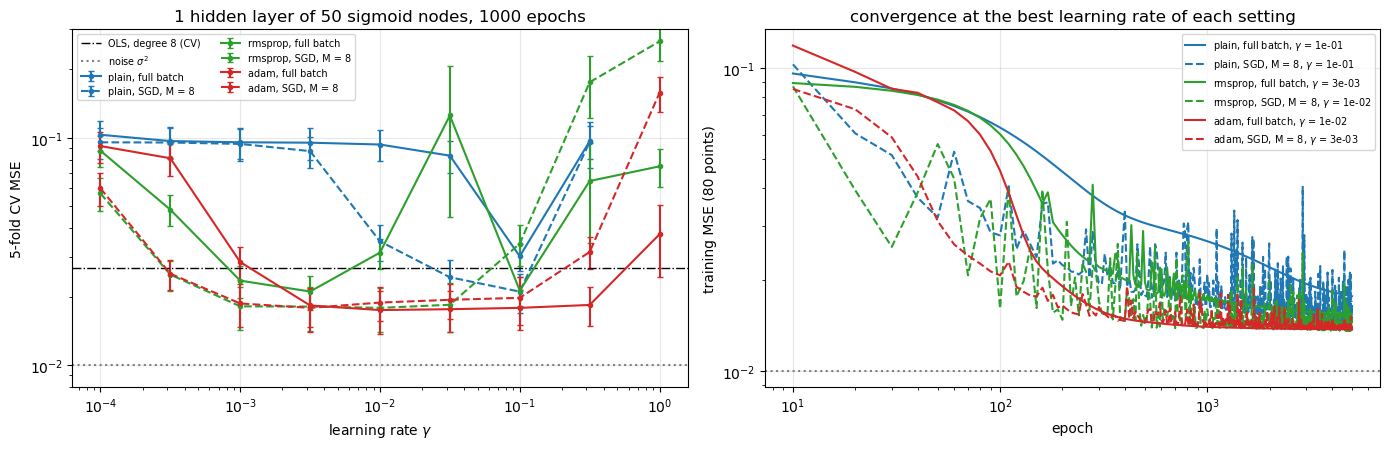

In [14]:
EPOCHS = 1000                                             # the same budget of epochs for every run of parts b) to d)
gammas_b = np.logspace(-4, 0, 9)                          # 1e-4, 3e-4, ..., 1: two points per decade
settings = [(m, M) for m in ["plain", "rmsprop", "adam"] for M in [None, 8]]  # (rule, batch size)
scan_b, time_b = {}, {}                                   # CV results per setting, and seconds per CV run
t_all = time.perf_counter()                               # start of the whole scan
for method, M in settings:
    t0 = time.perf_counter()                              # start the clock
    scan_b[(method, M)] = np.array([cv_network([50], "sigmoid", method=method, gamma=g, epochs=EPOCHS, batch_size=M)  # CV
                                    for g in gammas_b])   # rows: learning rates; columns: CV MSE, s.e., training MSE
    time_b[(method, M)] = (time.perf_counter() - t0) / len(gammas_b)  # seconds per 5 fold CV run
print(f"scan done in {time.perf_counter() - t_all:.0f} s\n")

label = lambda method, M: f"{method}, " + ("full batch" if M is None else f"SGD, M = {M}")  # readable name
best_b = {}                                               # best learning rate per setting
print("setting                    best gamma   CV MSE   +- s.e.   training MSE   seconds per 5-fold CV")
for key, res in scan_b.items():
    i = np.nanargmin(res[:, 0])                           # lowest CV MSE over the learning rates
    best_b[key] = (gammas_b[i], res[i, 0], res[i, 1], res[i, 2])  # (gamma, CV MSE, s.e., training MSE)
    print(f"{label(*key):26s} {gammas_b[i]:9.1e}   {res[i, 0]:.4f}   {res[i, 1]:.4f}     {res[i, 2]:.4f}         "
          f"{time_b[key]:.2f}")
    print("      CV MSE per gamma: " + " ".join("  div " if np.isnan(v) else f"{v:.4f}" for v in res[:, 0]))

# the training setup for the rest of the regression: the setting with the lowest CV MSE
key_best = min(best_b, key=lambda k: best_b[k][1])        # setting with the lowest CV MSE
threshold = best_b[key_best][1] + best_b[key_best][2]     # best CV MSE + its standard error
within = [label(*k) for k in best_b if best_b[k][1] <= threshold]  # settings the data cannot tell apart
TRAIN = dict(method=key_best[0], gamma=float(best_b[key_best][0]), batch_size=key_best[1], epochs=EPOCHS)
print(f"\nlowest CV MSE: {label(*key_best)}; settings within one standard error of it: {within}")
print("training set-up used from now on:", TRAIN)

# convergence on all 80 training points at the best learning rate of every setting
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for (method, M), style in zip(settings, ["-", "--"] * 3):
    res = scan_b[(method, M)]                             # the scan of this setting
    color = {"plain": "C0", "rmsprop": "C2", "adam": "C3"}[method]  # one colour per update rule
    axes[0].errorbar(gammas_b, res[:, 0], yerr=res[:, 1], fmt="o" + style, ms=3, capsize=2, color=color,
                     label=label(method, M))
    net = FFNN([1, 50, 1], ["sigmoid", "identity"])       # a fresh [1, 50, 1] sigmoid network
    t0 = time.perf_counter()                              # start the clock
    hist = train_network(net, X_train_s, Y_train_c, method=method, gamma=best_b[(method, M)][0], epochs=5000,  # 5000 epochs
                         batch_size=M, monitor=lambda nt: {"train": mse(nt.predict(X_train_s), Y_train_c)},
                         record_every=10)
    axes[1].loglog(hist["epoch"], hist["train"], style, color=color,
                   label=label(method, M) + rf", $\gamma$ = {best_b[(method, M)][0]:.0e}")
    print(f"{label(method, M):26s}: training MSE after 100 / 1000 / 5000 epochs = {hist['train'][9]:.4f} / "
          f"{hist['train'][99]:.4f} / {hist['train'][-1]:.4f}   ({1e3 * (time.perf_counter() - t0) / 5000:.2f} ms per epoch)")
axes[0].axhline(REG[OLS_CV_NAME]["cv"], color="k", ls="-.", lw=1, label=f"OLS, degree {d_cv} (CV)")
axes[0].axhline(0.1**2, color="gray", ls=":", label=r"noise $\sigma^2$")
axes[0].set_xscale("log"); axes[0].set_yscale("log"); axes[0].set_ylim(0.008, 0.3)
axes[0].set_xlabel(r"learning rate $\gamma$"); axes[0].set_ylabel("5-fold CV MSE")
axes[0].set_title("1 hidden layer of 50 sigmoid nodes, 1000 epochs")
axes[0].legend(fontsize=7, ncol=2); axes[0].grid(alpha=0.3)
axes[1].axhline(0.1**2, color="gray", ls=":")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("training MSE (80 points)")
axes[1].set_title("convergence at the best learning rate of each setting")
axes[1].legend(fontsize=7); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### b.6 Figures for the report
**Source:** the scan of b.6 (`scan_b`, `best_b`, `threshold`); the convergence runs are those of b.6, repeated with the
same network, seed and learning rates only to draw them in two panels. **Modifications:** one panel per update rule,
full batch and minibatches in separate panels, the noise floor of the true $f$ instead of $\sigma^2$. No new results.
> **LLM note:** Written with Claude (Level 4). New plotting code.

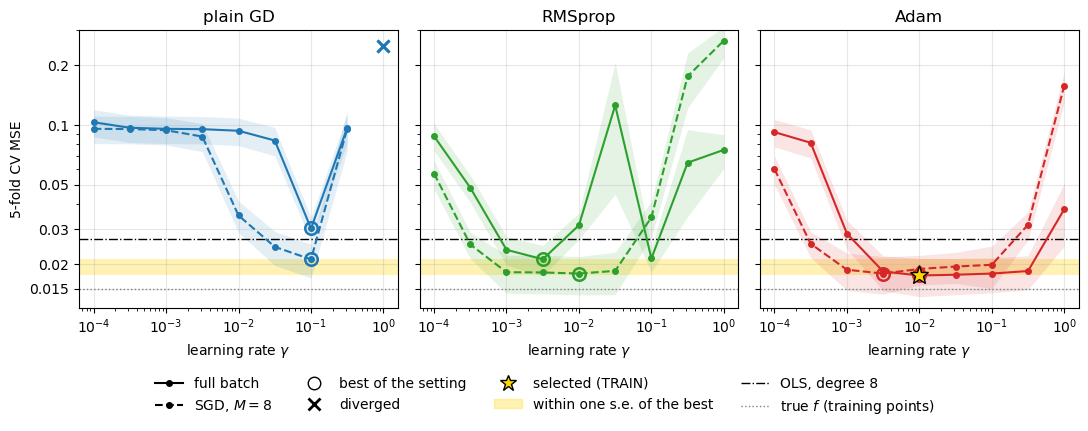

In [15]:
# ---- Figures for the report: b.6 redrawn (CV scan from scan_b and best_b; the convergence runs repeat those of b.6) ----
import os                                                 # folder for the figures of the report
from matplotlib.lines import Line2D                       # legend entries drawn by hand
from matplotlib.ticker import FormatStrFormatter, NullFormatter  # plain tick labels on log axes

FIG_DIR = "Figures"                                       # figures for the report (folder of selected results)
os.makedirs(FIG_DIR, exist_ok=True)                       # create the folder if it does not exist
NICE = {"sigmoid": "sigmoid", "relu": "ReLU", "leaky_relu": "leaky ReLU",  # names for legends and titles
        "plain": "plain GD", "rmsprop": "RMSprop", "adam": "Adam"}
COLOR_M = {"plain": "C0", "rmsprop": "C2", "adam": "C3"}  # one colour per update rule, as in b.6


def save_figure(fig, name):
    """
    Save a figure for the report in FIG_DIR, as PDF (vector graphics, for LaTeX) and as PNG.

    LLM-assisted
    ------------
    Tool: Claude (Claude Opus 5.5, claude.ai)
    Role: Wrote the helper that saves the figures of the report.
    """
    for ext in ("pdf", "png"):                            # the same figure in both formats
        fig.savefig(os.path.join(FIG_DIR, f"{name}.{ext}"), dpi=300, bbox_inches="tight")


def plain_log_ticks(ax, ticks):
    """
    Put the given ticks on the logarithmic y axis of ax and write them as plain numbers (0.02 instead of 2x10^-2).

    LLM-assisted
    ------------
    Tool: Claude (Claude Opus 5.5, claude.ai)
    Role: Wrote the tick helper of the report figures.
    """
    ax.set_yticks(ticks)                                  # the ticks we want
    ax.yaxis.set_major_formatter(FormatStrFormatter("%g"))  # plain numbers
    ax.yaxis.set_minor_formatter(NullFormatter())         # no labels on the minor ticks


noise_train = MSE(y_train, runge(x_train))                # realised noise on the training points (printed in b.5)
ols_cv = REG[OLS_CV_NAME]["cv"]                           # CV MSE of OLS, degree 8 (b.5)
best_cv = best_b[key_best][1]                             # lowest CV MSE of b.6 (Adam, full batch)
MSE_TICKS = [0.015, 0.02, 0.03, 0.05, 0.1, 0.2]           # tick positions of the MSE axes

# Figure 1: the CV MSE against the learning rate, one panel per update rule (full batch solid, SGD dashed)
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8), sharey=True)
for ax, method in zip(axes, ["plain", "rmsprop", "adam"]):
    color = COLOR_M[method]                               # colour of this update rule
    ax.axhspan(best_cv, threshold, color="gold", alpha=0.3, lw=0)  # within one standard error of the best (b.6)
    ax.axhline(ols_cv, color="k", ls="-.", lw=1)          # OLS of degree 8 (b.5)
    ax.axhline(noise_train, color="gray", ls=":", lw=1)   # the true f on the training points (b.5)
    for M, style in [(None, "-"), (8, "--")]:             # full batch, then minibatches of 8
        cv, se = scan_b[(method, M)][:, 0], scan_b[(method, M)][:, 1]  # CV MSE and its standard error per learning rate
        ax.plot(gammas_b, cv, style, marker="o", ms=4, color=color)  # diverged runs (NaN) are left out
        ax.fill_between(gammas_b, cv - se, cv + se, color=color, alpha=0.12, lw=0)  # one standard error
        g_best, cv_best = best_b[(method, M)][:2]         # best learning rate of this setting and its CV MSE
        ax.plot(g_best, cv_best, "o", ms=9, mfc="none", mec=color, mew=1.8)  # ring around the best of the setting
        for g in gammas_b[np.isnan(cv)]:                  # learning rates at which the run diverged
            ax.plot(g, 0.25, "x", ms=8, mew=2, color=color)  # drawn near the top of the axis
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_ylim(0.012, 0.3)
    plain_log_ticks(ax, MSE_TICKS)                        # 0.015, 0.02, ... as plain numbers
    ax.set_xlabel(r"learning rate $\gamma$"); ax.set_title(NICE[method]); ax.grid(alpha=0.3, which="major")
axes[0].set_ylabel("5-fold CV MSE")
axes[2].plot(TRAIN["gamma"], best_cv, "*", ms=14, color="gold", mec="k", zorder=5)  # the selected setup TRAIN
handles = [Line2D([], [], color="k", ls="-", marker="o", ms=4, label="full batch"),
           Line2D([], [], color="k", ls="--", marker="o", ms=4, label="SGD, $M=8$"),
           Line2D([], [], ls="", marker="o", ms=9, mfc="none", mec="k", label="best of the setting"),
           Line2D([], [], ls="", marker="x", ms=8, mew=2, color="k", label="diverged"),
           Line2D([], [], ls="", marker="*", ms=12, color="gold", mec="k", label="selected (TRAIN)"),
           plt.Rectangle((0, 0), 1, 1, color="gold", alpha=0.3, label="within one s.e. of the best"),
           Line2D([], [], color="k", ls="-.", lw=1, label=f"OLS, degree {d_cv}"),
           Line2D([], [], color="gray", ls=":", lw=1, label="true $f$ (training points)")]
fig.legend(handles=handles, loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.14), frameon=False)
plt.tight_layout()
save_figure(fig, "b6_cv_learning_rate")
plt.show()



#### b.7 One and two hidden layers of 50 and 100 nodes against OLS, and against Scikit-Learn
**Source:** the four networks are those of the project text (one and two hidden layers, 50 and 100 nodes; we run all
four combinations); the comparison with an established library follows Section 8.14 of the lecture notes ("Using
established libraries", where `MLPClassifier` is used, and "Handwritten digits", where a network written from scratch
is compared with an `MLPClassifier` of the same architecture; `MLPRegressor` is its regression counterpart in
Scikit-Learn) and takeaway 10 of the project text. **Modifications:** the training setup of b.6; the learning rate is
retuned for every architecture on $\{\gamma/3,\gamma,3\gamma\}$ by CV, since a wider network may prefer another step;
each selected network is refitted on all 80 training points and evaluated once on the 20 test points. `MLPRegressor`
gets the same architecture, activation, solver, learning rate and number of epochs (`tol=0` so that it runs all
epochs) and full batches (`batch_size=80`, larger than a training fold), inside a pipeline with `StandardScaler`, and
the same CV folds. Scikit-Learn uses its own cost normalisation and initialisation, and it fits the uncentred $y$ with
its own output bias, so the results should agree in size but not to many digits. Because all models are scored on the
same five folds and the same 20 test points, the cell also prints the *paired* differences to OLS of degree 8 (fold by
fold, and test point by test point). Pairing removes the noise that the two models share, so the standard error of a
paired difference is smaller than $\sqrt{s_1^2+s_2^2}$, the standard error of the difference of two independent
estimates [own].
> **LLM note:** Written with Claude (Level 4). New code; the `MLPRegressor` call follows Section 8.14 of the lecture
> notes.

model                                           gamma     CV MSE +- s.e.     training MSE   test MSE +- s.e.   MSE to f   parameters
OLS, degree 8 (best of Project 1)                      -  0.0266 +- 0.0071           -     0.0187 +- 0.0048   0.00572        9
FFNN [50], sigmoid (part b)                      1.0e-02  0.0175 +- 0.0038      0.0136     0.0133 +- 0.0048   0.00106      151
FFNN [100], sigmoid (part b)                     1.0e-02  0.0174 +- 0.0038      0.0135     0.0135 +- 0.0048   0.00096      301
FFNN [50, 50], sigmoid (part b)                  3.3e-03  0.0173 +- 0.0038      0.0135     0.0136 +- 0.0049   0.00084     2701
FFNN [100, 100], sigmoid (part b)                3.0e-02  0.0168 +- 0.0036      0.0132     0.0116 +- 0.0043   0.00104    10401
Scikit-Learn MLPRegressor [50], logistic               -  0.0181 +- 0.0039           -     0.0128 +- 0.0046   0.00081      151

paired differences, network minus OLS degree 8 (negative: the network is better):
   [50]      : CV MSE 

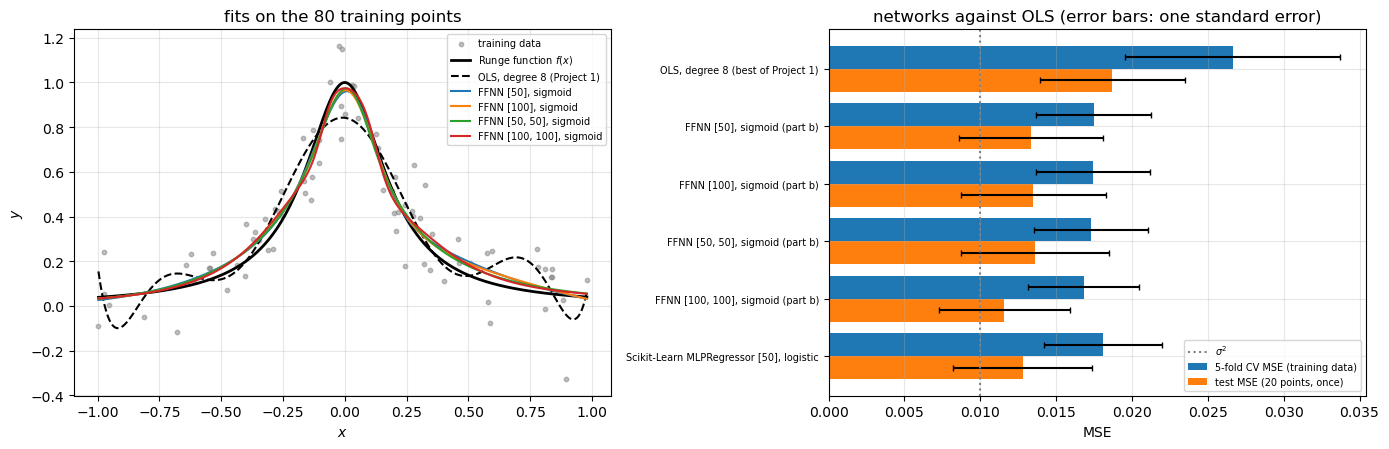

In [16]:
from sklearn.neural_network import MLPRegressor

archs_b = [[50], [100], [50, 50], [100, 100]]             # one and two hidden layers of 50 and 100 sigmoid nodes
# fitted curves on x_grid, and the learning rate per architecture
fits_b, gamma_arch = {}, {}
for hidden in archs_b:
    t0 = time.perf_counter()                              # start the clock
    trials = {g: cv_network(hidden, "sigmoid", **{**TRAIN, "gamma": g}) + (cv_network.last_folds,)
              for g in [TRAIN["gamma"] / 3, TRAIN["gamma"], 3 * TRAIN["gamma"]]}  # three learning rates by CV
    g_best = min(trials, key=lambda g: np.nan_to_num(trials[g][0], nan=np.inf))  # lowest CV MSE (diverged: infinite)
    cv_m, cv_se, cv_tr, folds = trials[g_best]            # its CV results and its 5 fold errors
    net = FFNN([1, *hidden, 1], ["sigmoid"] * len(hidden) + ["identity"])  # refit on all 80 training points
    train_network(net, X_train_s, Y_train_c, **{**TRAIN, "gamma": g_best})  # refit with the selected learning rate
    t_m, t_se = test_mse_se(y_test, net.predict(X_test_s)[:, 0] + y_mean)  # the test set, once
    fits_b[str(hidden)] = net.predict(X_grid_s)[:, 0] + y_mean  # fitted curve on the dense grid
    gamma_arch[str(hidden)] = g_best                      # remember the learning rate
    REG[f"FFNN {hidden}, sigmoid (part b)"] = dict(cv=cv_m, cv_se=cv_se, cv_train=cv_tr, test=t_m, test_se=t_se,  # all numbers
                                                   f_mse=mse_to_f(fits_b[str(hidden)]), n_par=net.theta.size,
                                                   gamma=g_best, seconds=time.perf_counter() - t0, folds=folds,
                                                   sq_test=(y_test - net.predict(X_test_s)[:, 0] - y_mean) ** 2)

# Scikit-Learn with the same setup as our [50] network
mlp_kw = dict(hidden_layer_sizes=(50,), activation="logistic", solver="adam", alpha=0.0,  # our [50] network for Scikit-Learn
              learning_rate_init=gamma_arch["[50]"], max_iter=EPOCHS, tol=0.0, n_iter_no_change=EPOCHS + 1,
              batch_size=len(x_train) if TRAIN["batch_size"] is None else TRAIN["batch_size"], random_state=SEED)
with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)   # max_iter is reached on purpose
    warnings.simplefilter("ignore", UserWarning)          # a batch larger than a training fold is clipped to the fold
    m_mlp, se_mlp = cv_mse_se(make_pipeline(StandardScaler(), MLPRegressor(**mlp_kw)), x_train, y_train, K_FOLDS)  # CV
    mlp = make_pipeline(StandardScaler(), MLPRegressor(**mlp_kw)).fit(x_train[:, None], y_train)  # refit on 80 points
t_mlp, t_mlp_se = test_mse_se(y_test, mlp.predict(x_test[:, None]))  # its test MSE
REG["Scikit-Learn MLPRegressor [50], logistic"] = dict(cv=m_mlp, cv_se=se_mlp, test=t_mlp, test_se=t_mlp_se,  # its row
                                                       f_mse=mse_to_f(mlp.predict(x_grid[:, None])), n_par=151)

print("model                                           gamma     CV MSE +- s.e.     training MSE   test MSE +- s.e.   MSE to f   parameters")
for name, r in REG.items():
    g_str = f"{r['gamma']:8.1e}" if "gamma" in r else f"{'-':>8s}"  # OLS and Scikit-Learn: no learning rate of ours
    tr_str = f"{r['cv_train']:8.4f}" if "cv_train" in r else f"{'-':>8s}"  # training MSE stored for our networks only
    print(f"{name:46s}  {g_str}  {r['cv']:.4f} +- {r['cv_se']:.4f}    "
          f"{tr_str}     {r['test']:.4f} +- {r['test_se']:.4f}   {r['f_mse']:.5f}   {r['n_par']:6d}")

# paired comparison with OLS of degree 8: the same 5 folds and the same 20 test points for both models, so the
# differences fold by fold (and point by point) are less noisy than the two errors separately
folds_ols8 = fold_mse_poly(make_ols_pipeline(8))          # fold errors of OLS degree 8 on the same folds
sq_ols8 = (y_test - ols8.predict(x_test[:, None])) ** 2   # squared test errors of OLS, degree 8
print("\npaired differences, network minus OLS degree 8 (negative: the network is better):")
for hidden in archs_b:
    r = REG[f"FFNN {hidden}, sigmoid (part b)"]           # results of this network
    d_cv, d_te = r["folds"] - folds_ols8, r["sq_test"] - sq_ols8  # differences per fold and per test point
    print(f"   {str(hidden):10s}: CV MSE {d_cv.mean():+.4f} +- {d_cv.std(ddof=1) / np.sqrt(len(d_cv)):.4f} "
          f"(network better in {np.sum(d_cv < 0)} of 5 folds);  test MSE {d_te.mean():+.4f} +- "
          f"{d_te.std(ddof=1) / np.sqrt(len(d_te)):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
axes[0].scatter(x_train, y_train, s=10, color="gray", alpha=0.5, label="training data")
axes[0].plot(x_grid, runge(x_grid), "k-", lw=2, label="Runge function $f(x)$")
axes[0].plot(x_grid, ols8.predict(x_grid[:, None]), "k--", lw=1.5, label="OLS, degree 8 (Project 1)")
for hidden in archs_b:
    axes[0].plot(x_grid, fits_b[str(hidden)], lw=1.5, label=f"FFNN {hidden}, sigmoid")
axes[0].set_xlabel("$x$"); axes[0].set_ylabel("$y$"); axes[0].legend(fontsize=7); axes[0].grid(alpha=0.3)
axes[0].set_title("fits on the 80 training points")
names = list(REG.keys())                                  # one pair of bars per model
pos = np.arange(len(names))                               # their positions
axes[1].barh(pos - 0.2, [REG[k]["cv"] for k in names], 0.4, xerr=[REG[k]["cv_se"] for k in names],
             capsize=2, label="5-fold CV MSE (training data)")
axes[1].barh(pos + 0.2, [REG[k]["test"] for k in names], 0.4, xerr=[REG[k]["test_se"] for k in names],
             capsize=2, label="test MSE (20 points, once)")
axes[1].axvline(0.1**2, color="gray", ls=":", label=r"$\sigma^2$")
axes[1].set_yticks(pos); axes[1].set_yticklabels(names, fontsize=7); axes[1].invert_yaxis()
axes[1].set_xlabel("MSE"); axes[1].legend(fontsize=7); axes[1].grid(alpha=0.3)
axes[1].set_title("networks against OLS (error bars: one standard error)")
plt.tight_layout()
plt.show()

#### b.7 Figure for the report
**Source:** the fits (`fits_b`, `ols8`) and the errors (`REG`) of b.5 and b.7. **Modifications:** the CV and test MSE as
points with labelled error bars (one standard error), the noise floors of the true $f$ on the training and on the test
points instead of $\sigma^2$, short model names. No new results.
> **LLM note:** Written with Claude (Level 4). New plotting code.

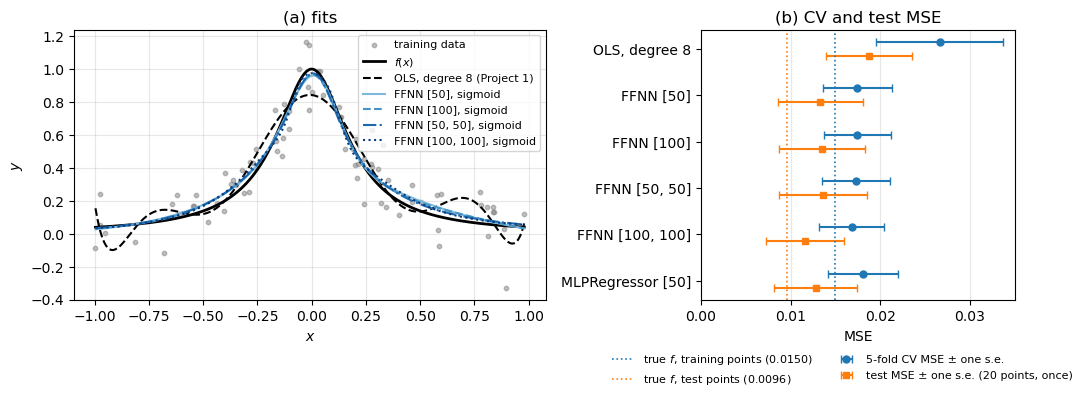

In [17]:
# ---- Figure for the report: b.7 redrawn (fits from fits_b and ols8, errors from REG; nothing is recomputed) ----
noise_test = MSE(y_test, runge(x_test))                   # realised noise on the test points (printed in b.5)
short = lambda name: (name.replace(" (best of Project 1)", "").replace(", sigmoid (part b)", "")  # short model names
                      .replace("Scikit-Learn ", "").replace(", logistic", ""))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [3, 2]})

# (a) the fits on the dense grid, trained on the 80 training points
axes[0].scatter(x_train, y_train, s=10, color="gray", alpha=0.5, label="training data")
axes[0].plot(x_grid, runge(x_grid), "k-", lw=2, label="$f(x)$")
axes[0].plot(x_grid, ols8.predict(x_grid[:, None]), "k--", lw=1.5, label="OLS, degree 8 (Project 1)")
blues = plt.cm.Blues(np.linspace(0.45, 0.95, len(archs_b)))  # all sigmoid networks: shades of the sigmoid colour
for hidden, color, ls in zip(archs_b, blues, ["-", "--", "-.", ":"]):
    axes[0].plot(x_grid, fits_b[str(hidden)], ls, color=color, lw=1.5, label=f"FFNN {hidden}, sigmoid")
axes[0].set_xlabel("$x$"); axes[0].set_ylabel("$y$"); axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)
axes[0].set_title("(a) fits")

# (b) CV and test MSE of every model, each with one standard error, against the two noise floors
names = list(REG.keys())                                  # the models of b.5 and b.7, in the order of the printed table
pos = np.arange(len(names))                               # one row per model
axes[1].errorbar([REG[k]["cv"] for k in names], pos - 0.15, xerr=[REG[k]["cv_se"] for k in names], fmt="o", ms=5,
                 capsize=3, color="C0", label="5-fold CV MSE ± one s.e.")
axes[1].errorbar([REG[k]["test"] for k in names], pos + 0.15, xerr=[REG[k]["test_se"] for k in names], fmt="s", ms=5,
                 capsize=3, color="C1", label="test MSE ± one s.e. (20 points, once)")
axes[1].axvline(noise_train, color="C0", ls=":", lw=1.2, label=f"true $f$, training points ({noise_train:.4f})")
axes[1].axvline(noise_test, color="C1", ls=":", lw=1.2, label=f"true $f$, test points ({noise_test:.4f})")
axes[1].set_yticks(pos); axes[1].set_yticklabels([short(k) for k in names]); axes[1].invert_yaxis()
axes[1].set_xlim(0, None); axes[1].set_xlabel("MSE"); axes[1].grid(alpha=0.3, axis="x")
axes[1].legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.45, -0.16), ncol=2, frameon=False)
axes[1].set_title("(b) CV and test MSE")
plt.tight_layout()
save_figure(fig, "b7_networks_vs_ols")
plt.show()

#### b.8 Observations (integrated version, notes for the report)
> **LLM note:** Drafted with Claude from the outputs above and from our question-and-answer session with Claude, in
> which we went through part b) step by step (text Level 3 if used as it is). Rewrite in your own words for the report,
> and check every number against your own run. **[own]** marks reasoning that is not taken from the course material.

**What the cells show (b.1 to b.7)**

1. **Same data, same benchmark (b.1, b.5).** The starter cell and the functions of Project 1 give the same 100 points,
   and the split is the 80/20 split of Project 1. On the five folds that we also use for the networks, cross validation
   over the degrees 1 to 15 selects **degree 8** for OLS, the degree that Project 1 had chosen on the test set: CV MSE
   0.0266 ± 0.0071, test MSE 0.0187 ± 0.0048 (the value of Project 1) and MSE to the true $f$ on a dense grid 0.00572.
   No other degree lies within one standard error of it (the next best is degree 6, 0.0367 > 0.0266 + 0.0071). Our
   Project 1 report selected degree 11 instead, by 10 fold cross validation on all 100 points (0.0202 ± 0.0031; d.2 and
   i.3 there, where 5 folds also gave degree 11). We use degree 8 because the project text asks for the polynomial order
   of Project 1 "that gave you the best result" on "the same data sets which gave you the best MSE score", 0.0187 being
   the lowest MSE of Project 1, and because cross validation on the 80 training points, the procedure we use for every
   model here, also selects degree 8. The selected degree depends on which points the folds contain, the same lesson as
   in Project 1. The curve is not smooth: the odd degrees 3, 5, 7, 9 and 11 are worse than both their even neighbours,
   and from degree 13 on the error grows by orders of magnitude (0.4685, 2.0389 and 35.1083 for degrees 13 to 15, after 0.1835 and
   0.0599 at degrees 11 and 12, b.5), with standard errors as large as the means, so that one or two folds carry the average. A
   training fold holds only 64 points, and a polynomial of high degree oscillates near the ends of the interval, Runge's
   phenomenon of Project 1, part a) [own reading].

2. **How low can an MSE go here [own].** On our realised data the true function itself has an MSE of 0.0150 on the 80
   training points and 0.0096 on the 20 test points ($\sigma^2=0.01$, b.5): the test points happen to be less noisy,
   which is why every test MSE below is smaller than the corresponding CV MSE. These are the floors of Section 2.10
   for our data: no model can be expected to score below them on points it was not trained on. The best networks reach CV MSEs between 0.0168 and 0.0175 (b.7), and the differences between good
   models are smaller than their standard errors (for the networks of b.6 and b.7, 0.0036 to 0.0041 in CV and 0.0043 to
   0.0049 on the test set). The MSE to $f$ on
   the dense grid has no noise in it and is the sharpest comparison of the fits; it exists only because we know $f$.

3. **The backpropagation is correct (b.4).** In all 36 combinations (four pairs of output activation and cost,
   including the mismatched sigmoid with the MSE, which uses the general Eq. (8.65) instead of the shortcut; three hidden
   activations; no penalty, $L_2$ and $L_1$) the gradient of b.2 agrees with `jax.grad` to about $10^{-17}$
   ($6.9\cdot10^{-17}$ at most), and with the central differences of Eq. (4.102) ($h=10^{-6}$) to a relative $3.8\cdot10^{-9}$
   to $3.5\cdot10^{-6}$. `week41monday.ipynb` expects $10^{-6}$ or smaller; three entries are above it ($1.2$, $2.0$
   and $3.5\cdot10^{-6}$ in our run).
   This is a limit of the finite difference, not an error of the gradient [own reading]: its rounding error does
   not shrink with the entry, so the relative
   discrepancy is largest where the gradient entry itself is small, and for the ReLU family a step $h$ can also cross the
   kink; in the same 36 cases the agreement with `jax.grad` stays at $10^{-17}$. The finite differences have truncation
   and rounding errors of their own (in double precision a central difference reaches a relative accuracy of about
   $10^{-11}$ at best, Project 1, Section II G of the report), so they are the weaker test;
   the agreement with automatic differentiation to rounding is the sharp test (Section 4.14.10 of the lecture notes;
   takeaway 2).

4. **A network without hidden layers is Project 1 (b.4).** With the degree 5 polynomial features as input and an
   identity output, plain gradient descent at the optimal learning rate $\gamma^*=2/(\lambda_{\max}+\lambda_{\min})$ of
   the Hessian (Eq. (4.26)) reaches the closed form solutions of OLS and Ridge ($\lambda=10^{-2}$) to about $10^{-15}$
   ($2.8\cdot10^{-15}$ and $8.0\cdot10^{-16}$ in our run), with the same test MSE
   (0.03663 and 0.03927), and the bias ends at $10^{-16}$ because the columns and $y$ are centred. For the Lasso the
   subgradient steps ($\gamma=0.01$) end $2.1\cdot10^{-4}$ away from Scikit-Learn's solution (test MSE 0.03944 against
   0.03945): with a constant step the weights that should be zero keep jumping around zero, as in Project 1, part g).
   This one test checks the forward pass, the backpropagation, the training loop and the $\lambda$ conventions of part
   a) at the same time (takeaway 10).

5. **The learning rate decides everything for plain gradient descent (b.6, left).** With 1000 epochs, plain full batch
   gradient descent hardly leaves the starting point: for $\gamma\le3.2\cdot10^{-2}$ the CV MSE stays between 0.0834 and
   0.1031, close to the variance of $y$ (0.0938, the error of predicting the mean); only $\gamma=0.1$ gets to 0.0301, at
   $\gamma=0.32$ it is back at 0.0965, and $\gamma=1$ diverges. It is the only setting whose best result is not within one
   standard error of the overall best. One regularity explains much of the plain SGD curve [own observation]: **SGD with
   $M=8$** makes 8 updates per epoch on a training fold of 64 points instead of one, and at small $\gamma$ it behaves
   roughly like full batch gradient descent with ten times the learning rate (0.0955, 0.0953, 0.0940, 0.0874, 0.0350 at
   $\gamma=10^{-4}$ to $10^{-2}$, against 0.0955, 0.0952, 0.0934, 0.0834, 0.0301 for full batch at ten times those
   learning rates). When $\gamma$ is small the gradient hardly changes between the 8 updates of an epoch (b.6), so together they act
   like one larger step [own reasoning]. Plain gradient descent
   is slow here because the start is flat: the gradient is small, and the step is proportional to it [own reading]. The
   course's own network of the same size (`week44tuesday.ipynb`, Case 2, "What you should find") shows the same: with
   plain SGD at $\gamma=0.001$ and $0.003$ it still predicts the mean after 1000 epochs.

6. **The adaptive methods (b.6, left).** RMSprop and Adam divide the step by the size of the recent gradients, so a
   small gradient does not mean a small step (Sections 4.8 to 4.11). Adam is the most forgiving method: from
   $\gamma=3.2\cdot10^{-3}$ to $0.32$, its full batch CV MSE stays between 0.0175 and 0.0184, and even
   $\gamma=1$ gives 0.0376, not a divergence. Its learning rate bounds the step of every parameter, Eq. (4.72), so it
   cannot diverge in the sense of Eq. (4.20) (Section 4.11). RMSprop is erratic at large learning rates (full batch: 0.0313
   at $\gamma=10^{-2}$, 0.1253 at $3.2\cdot10^{-2}$, 0.0213 at $0.1$). This is what Section 4.10 ("The price of forgetting") and `week38monday.ipynb`, Part 3, describe: at a constant
   $\gamma$ RMSprop cannot settle, since near a minimum it keeps taking steps of length about $\gamma$, Eq. (4.66), while
   Adam's first moment averages those steps away. The CV MSE after a fixed number of epochs therefore depends partly on
   where the last epoch falls, and the jumps between neighbouring learning rates are not a trend [own reading].

7. **Ranking the six settings (b.6).** Best CV MSE of each setting, all after 1000 epochs: Adam full batch 0.0175 ±
   0.0038 ($\gamma=10^{-2}$), RMSprop with SGD 0.0179 ($10^{-2}$), Adam with SGD 0.0179 ($3.2\cdot10^{-3}$), plain SGD
   0.0210 ($0.1$), RMSprop full batch 0.0211 ($3.2\cdot10^{-3}$), plain full batch 0.0301 ± 0.0041 ($0.1$). Five of the
   six are within one standard error of the best, so the data cannot rank them; what separates the methods is how wide
   the range of good learning rates is, and that range is widest for Adam. At its best learning rate every setting except
   plain full batch gradient descent ends below the CV MSE of OLS of degree 8 (0.0266, the dash-dotted line), and none
   comes below 0.0150, the error of the true $f$ on the training points (item 2). The cost per epoch also differs: in our run a 5
   fold CV took 0.57 to 0.72 s with full batches and 1.52 to 2.10 s with $M=8$ (0.16 to 0.17 against 0.45 to 0.55 ms per
   epoch on the 80 points; times of one run on our machine). One epoch of SGD needs the same
   arithmetic as one full gradient, Eq. (4.38), but with 80 points the arithmetic is so small that the overhead of each
   call dominates, the case of very small batches in Section 4.7 ("What an update costs"). The lowest CV MSE, at the cost
   of a full batch run, is why full batch Adam with $\gamma=0.01$ is the setup `TRAIN` of parts b) to d). With the 50000
   images of part e) the situation is the opposite, and there we use minibatches (Section 4.7, Table 4.1). In the
   report the scan is drawn with one panel per update rule (b.6, figure for the report): the rings mark the best
   learning rate of each setting, the star the selected setup `TRAIN`, the crosses the diverged runs, the shaded band
   the CV MSEs within one standard error of the best, and the dotted line the true $f$ on the training points (0.0150),
   not $\sigma^2$.

8. **Convergence (b.6, right).** Training MSE on the 80 points after 100 / 1000 / 5000 epochs: Adam full batch 0.0458 /
   0.0140 / 0.0137 and Adam with SGD 0.0207 / 0.0143 / 0.0138 get lowest; plain full batch gradient descent is still
   descending after 5000 epochs (0.0636 / 0.0268 / 0.0176). The SGD curves are jagged, with spikes up to about 0.04: with a
   constant learning rate SGD ends on a plateau whose height is proportional to $\gamma/M$, Eq. (4.51) [own reading].
   Among the full batch runs RMSprop is the most jagged: from about epoch 150 its curve shows short bursts, the
   behaviour described in item 6, here at its best learning rate $\gamma=3.2\cdot10^{-3}$. Two runs end below 0.0150, the
   error of the true $f$ on these points: Adam full batch (0.0137) and Adam with SGD (0.0138). Like every fitted model they absorb part of the noise
   of the training points: the expected training error of a least-squares fit lies below the noise level "by exactly the fraction of
   the noise that the fit has absorbed" (Section 3.7, Eq. (3.35)), and this alone is not overfitting (c.6, item 4); the other four end between 0.0150 and 0.0176.

9. **One and two hidden layers of 50 and 100 nodes against OLS (b.7).** CV MSE, test MSE and MSE to $f$:
   [50] 0.0175 ± 0.0038, 0.0133 ± 0.0048, 0.00106; [100] 0.0174, 0.0135, 0.00096; [50, 50] ($\gamma$ retuned to
   $3.3\cdot10^{-3}$) 0.0173, 0.0136, 0.00084; [100, 100] ($\gamma=3\cdot10^{-2}$) 0.0168 ± 0.0036, 0.0116 ± 0.0043,
   0.00104; OLS of degree 8: 0.0266 ± 0.0071, 0.0187 ± 0.0048, 0.00572.
   (i) The four networks are practically equal, from 151 to 10401 parameters: their CV MSEs lie between 0.0168 and
   0.0175, well within one standard error (0.0036 to 0.0038). One layer of 50 sigmoids is already flexible enough for this smooth function of one
   variable, and more nodes or a second layer add nothing that the data can detect [own reading].
   (ii) Every network beats OLS in all three measures: CV MSE 0.0168 to 0.0175 against 0.0266, test MSE 0.0116 to
   0.0136 against 0.0187, and MSE to $f$ 0.00084 to 0.00106 against 0.00572.
   (iii) Since all models are scored on the same folds and the same test points, the cell also gives the *paired*
   differences (network minus OLS): $-0.0092\pm0.0068$ to $-0.0098\pm0.0071$ in CV, the network being better in 4 or 5 of
   the 5 folds, and $-0.0051\pm0.0027$ to $-0.0071\pm0.0033$ on the test set. Pairing removes the noise that both models share, so the paired standard errors on the test set (0.0027 to
   0.0033) are smaller than the standard error of each test MSE (0.0043 to 0.0049) [own reading]. The
   improvement is consistent across folds, test points and the noise free MSE to $f$, but with 80 and 20 points it is
   moderate evidence, not proof.
   (iv) The fits (left panel) show where the difference comes from: degree 8 cannot reach the top of the peak (about 0.84
   instead of 1) and oscillates near $x=\pm1$, while all networks follow the peak and stay flat in the tails. In the
   report figure (b.7, figure for the report) panel (b) shows the CV and test MSE of every model with one standard
   error, against the true $f$ on the training points (0.0150) and on the test points (0.0096): every CV MSE lies above
   the first floor and every test MSE above the second.

10. **Scikit-Learn (b.7).** `MLPRegressor` with the same architecture, activation, solver, learning rate, batch and number
    of epochs, but its own initialisation, gives CV 0.0181 ± 0.0039, test 0.0128 ± 0.0046 and MSE to $f$ 0.00081: the
    same level as our network, within one standard error everywhere. Our code is not worse than an established library
    on this problem (Section 8.14, takeaway 10).

11. **The questions of part b).** *Design matrix:* the raw $x$ as a single standardised column, no powers of $x$; the
    hidden layer builds its own features (takeaway 1; item 14), and items 9 and 10 show that it needs nothing more.
    *Output activation:* the identity, since the target is a real number (the centred targets are negative for most of
    the points) and the identity with the MSE is a matched pair (a.0, a.6); a sigmoid output could only give values in
    $(0,1)$, and with the MSE it would be a mismatched pair whose error vanishes where the network is confidently wrong
    (a.5). *Initialisation:* weights from a normal distribution with variance $1/M_{l-1}$ for the sigmoid and
    $2/M_{l-1}$ for the ReLU family (Section 8.10, Eqs. (8.72) and (8.74)); biases equal to $0.01$. The weights must be
    random: with equal weights every node of a layer would compute the same thing and receive the same update forever,
    and their variance keeps the signal from dying out or saturating the sigmoid (Section 8.10). Section 8.10 allows zero
    or a small positive constant such as $0.01$ for the biases of the ReLU family, so that the units start on the active
    side of the kink; the random weights already break the symmetry between the nodes, so the biases need not be random.

12. **Critical comparison of OLS and our network [own, to be discussed in the report].** *Accuracy:* on this function the
    network wins (items 9 and 10). The reason is the basis: a sum of sigmoids can place its steps around the narrow peak
    (item 14), while polynomials of degree 8 are too stiff for the peak and too wild at the edges. Takeaway 8 calls a
    polynomial of well chosen degree a hard to beat benchmark; for the Runge function and 80 noisy points no degree is
    well chosen (item 1). *Cost:* OLS is a closed form, solved in one step, without learning rate, initialisation or seed,
    with a single hyperparameter (the degree); the network needs 0.57 to 0.72 s for a 5 fold CV with full batches (b.6) and a search over the learning rate,
    the optimiser, the epochs and the architecture (the scan of b.6 alone took 68 s), and its result depends on the
    initialisation, because the cost is not convex (Section 8.7).
    *Interpretation:* the nine coefficients of OLS can be read off and come with standard errors, Eqs. (3.32) and (3.34);
    the 151 parameters (weights and biases) of the network have neither. *Reliability:* every network result above comes
    from one seed, and differences much smaller than one standard error (item 2) should not be read as
    real (Section 8.15). Neither model was tested outside $[-1,1]$; networks "extrapolate unpredictably outside the range of
    the training data" (Section 8.15).

**The concepts behind part b) (our discussion)**

13. **What one training step does.** *Forward pass:* every layer computes a weighted sum of its inputs plus a bias,
    $\boldsymbol z^l=\boldsymbol a^{l-1}\boldsymbol W^l+\boldsymbol b^l$, and applies its activation,
    $\boldsymbol a^l=f(\boldsymbol z^l)$ (Eq. (8.21); `feed_forward_saver`); the activation of the output layer gives the
    prediction, here the identity, so a real number. *Cost:* the prediction is compared with the target (`cost`).
    *Backward pass:* backpropagation sends the output error $\boldsymbol\delta^L=\tfrac2n(\boldsymbol a^L-\boldsymbol y)$
    back through the layers, $\boldsymbol\delta^l=\bigl(\boldsymbol\delta^{l+1}(\boldsymbol W^{l+1})^T\bigr)\circ
    f'(\boldsymbol z^l)$, and gives the gradient with respect to every weight and bias,
    $\partial C/\partial\boldsymbol W^l=(\boldsymbol a^{l-1})^T\boldsymbol\delta^l$ and $\partial C/\partial\boldsymbol b^l$
    the sum of $\boldsymbol\delta^l$ over the samples (Eqs. (8.65) to (8.68); `compute_gradient`), in one backward sweep
    at a cost of about two forward passes (takeaway 2). *Update:* the optimiser uses this gradient to change every weight
    and bias a little (`optimiser_step`). *Repeat:* once per minibatch, for every epoch (`train_network`).
    Backpropagation computes the gradient and gradient descent uses it: they are two different steps [own].

14. **What the hidden activations do.** They make the network non-linear: without them every layer is a linear map, and
    a network of any depth collapses to one straight line in $x$ (Section 8.2). With them, each hidden node turns its
    weighted sum into a building block: a sigmoid node $\sigma(wx+b)$ is a smooth step from 0 to 1 at $x=-b/w$, with $w$
    setting its steepness and direction; a ReLU node is a hinge with its kink at $x=-b/w$ (Lemma 8.1). The output layer
    adds the blocks up with its own weights. Two sigmoid nodes, one step up and one step down, already give a bump like the Runge
    peak [own example]. Our [50] network has 50 such steps, and training places them ($b$), sets their
    steepness ($w$) and their heights (the output weights). This is what "the network learns its own features" means
    (takeaway 1): in Project 1 we chose the features $x,x^2,\dots,x^8$ and OLS found their weights; here the hidden
    outputs $\sigma(w_jx+b_j)$ are the features, the network chooses them, and the output layer is linear regression on
    them. The outputs of the hidden sigmoids lie in $(0,1)$ but are not probabilities. During training the same
    activations decide, through $f'(z)$, how much error flows back through each node (a.6, item 4).

15. **Full batch, minibatches and epochs.** An epoch is one pass through all the training data. With full batches
    (`batch_size=None`) each epoch gives one update with the exact gradient of the cost; with minibatches of $M=8$ it gives
    8 updates, each with the gradient of 8 points, which is noisier (Section 4.7). That noise is why SGD with a constant
    learning rate ends on a plateau proportional to $\gamma/M$, Eq. (4.51), and why its training curves are jagged
    (item 8). On 80 points one SGD epoch costs the same arithmetic as one full gradient, Eq. (4.38), but more wall clock time
    (0.45 to 0.55 against 0.16 to 0.17 ms per epoch, b.6), because the overhead of each call dominates (item 7).

16. **The update rules we compare.** The project text asks for plain gradient descent, RMSprop and Adam (part b; item 4
    of the required implementation), so we removed the momentum rule of Project 1. Plain gradient descent takes a step
    proportional to the gradient, so it crawls where the cost is flat and diverges when $\gamma$ is too large,
    Eq. (4.20). RMSprop divides each parameter's step by a running average of its squared gradients, so a small gradient
    does not mean a small step, Eqs. (4.63) and (4.64). Adam adds a running average of the gradient itself, its first
    moment, Eq. (4.67), and a bias correction, Eq. (4.70): Adam is "in effect, RMSProp plus momentum" (Section 4.11), so a
    momentum term is still part of our training through Adam. AdaGrad, still in `optimiser_step`, is not used, since its
    step decays as $1/\sqrt t$, Eq. (4.62).

17. **A fair comparison, and how far the numbers can be trusted [own].** All models, polynomials and networks, are
    selected by 5 fold cross validation on the same folds of the 80 training points, with the scaling refitted inside
    every fold, so that nothing from the validation points leaks into the training; the test set is used once, at the end
    (takeaway 6). With 80 and 20 points the standard errors of the networks are 0.0036 to 0.0041 in CV and 0.0043 to 0.0049 on the
    test set (b.6, b.7), so only larger differences mean something, and the paired differences of item 9 are the sharper test. Every network result comes
    from one seed: the cost is not convex, so the minimum reached depends on the initialisation (Section 8.7), and
    the results depend on the seed (Section 8.15).

18. **Points to state precisely in the report and the oral [own].** The hidden activations do not produce
    probabilities; only the output layer does, and only with a softmax or sigmoid output (part e). Backpropagation and
    gradient descent are two different steps (item 13). The networks are consistently better than OLS on this function,
    but the evidence is moderate (the paired differences of item 9), and the reason is that
    polynomials are a poor basis for the Runge peak, not that networks are better regression tools in general
    (takeaway 8, item 12).

### Part c): Testing different activation functions and depths of the neural network

You should also test different activation functions for the hidden layers. Try out the Sigmoid, the RELU and the Leaky RELU functions and discuss your results (Section [8.6.4](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#which-activation-should-we-use) of the lecture notes discusses which activation to use, and Section [8.9](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#vanishing-and-exploding-gradients) why the sigmoid makes the gradients vanish in deep networks). Test your results as functions of the number of hidden layers and nodes. Do you see signs of overfitting? It is optional in this project to perform a bias-variance trade-off analysis.


## Code for part c): activation functions, depth and width

**Where each piece comes from** (course material and Project 1 are cited in the bibliography):

| Cell | Piece | Source | Status |
|---|---|---|---|
| c.1 | learning rate per activation | `Project1.ipynb` f.2; b.6 above; the learning rates of `cv_grid` in `week44tuesday.ipynb`, Case 2, Step 3 | adapted |
| c.2 | CV MSE over depth and width, one heat map per activation | project text (summary, item 2: "2D heat maps", two hyperparameters at a time; takeaway 6); `week44tuesday.ipynb`, Case 2, Steps 3 and 4 | new code |
| c.3 | signs of overfitting: training against CV error over the number of parameters, and over the epochs | lecture notes Sections 8.12 ("Early stopping") and 2.9 to 2.10; `Project1.ipynb`, part c (Hastie et al., Fig. 2.11); `week44tuesday.ipynb`, Case 2, Step 4 (validation curve over the epochs) | new code |
| c.4 | vanishing gradients: gradient norm per layer at initialisation, and training of deep networks | lecture notes Section 8.9, Eq. (8.71) and Fig. 8.14; `week42monday.ipynb`, Section 2 (`deep_network_stats`) | adapted |
| c.5 | the best network of each activation on the test set | b.7 | reused |

**Setup.** Same data, folds and scaling as in part b); the training setup `TRAIN` chosen in b.6 (update rule, batch size,
1000 epochs), with the learning rate tuned per activation in c.1 (c.3 trains longer, and c.4 also uses plain gradient
descent, as those cells say). Sigmoid networks are initialised with variance $1/M_{l-1}$, ReLU and leaky ReLU networks
with the He variance $2/M_{l-1}$ (b.2). The leaky ReLU has $\alpha=0.01$. No penalty in this part. The bias variance
analysis with the bootstrap is optional in this project and is not done here; the gap between training and cross
validated error plays its role (c.3).

> **LLM note:** All code cells of part c) were written with Claude Opus 5.5 (claude.ai, October 2026) at Level 4, using
> the course material listed above as the base.

#### c.1 The learning rate for each activation function
**Source:** the scan of b.6 (itself `Project1.ipynb` f.2). **Modifications:** one hidden layer of 50 nodes, the update rule
and batch size of `TRAIN`, five learning rates around the one chosen in b.6, for the sigmoid, the ReLU and the leaky ReLU
($10^{-3}$ to $10^{-1}$, the learning rates of `cv_grid` in `week44tuesday.ipynb`, Case 2, Step 3).
The learning rate with the lowest CV MSE is used for that activation in the rest of parts c) and d). It is tuned again
for every activation because the size of the gradients depends on the activation and on its initialisation (c.4), and
every activation should be judged at its own best learning rate [own].
> **LLM note:** Written with Claude (Level 4), adapted from b.6 and `week44tuesday.ipynb` (Case 2, Step 3).

In [18]:
# Your code for part c) here
acts = ["sigmoid", "relu", "leaky_relu"]                  # the three hidden activations of the project
gammas_c = TRAIN["gamma"] * np.array([0.1, 0.3, 1.0, 3.0, 10.0])  # around the learning rate chosen in b.6
scan_c = {act: np.array([cv_network([50], act, **{**TRAIN, "gamma": g}) for g in gammas_c]) for act in acts}  # CV results
GAMMA = {}                                                # learning rate per activation, used from now on
print("activation    " + "  ".join(f"gamma={g:.1e}" for g in gammas_c))
for act in acts:
    GAMMA[act] = gammas_c[np.nanargmin(scan_c[act][:, 0])]  # learning rate with the lowest CV MSE
    print(f"{act:12s}  " + "  ".join(f"{m:.4f}+-{s:.4f}" for m, s, _ in scan_c[act]) + f"   -> gamma = {GAMMA[act]:.1e}")

activation    gamma=1.0e-03  gamma=3.0e-03  gamma=1.0e-02  gamma=3.0e-02  gamma=1.0e-01
sigmoid       0.0284+-0.0047  0.0184+-0.0036  0.0175+-0.0038  0.0176+-0.0036  0.0179+-0.0036   -> gamma = 1.0e-02
relu          0.0263+-0.0041  0.0213+-0.0039  0.0175+-0.0039  0.0177+-0.0038  0.0183+-0.0036   -> gamma = 1.0e-02
leaky_relu    0.0265+-0.0041  0.0214+-0.0039  0.0176+-0.0039  0.0175+-0.0037  0.0183+-0.0036   -> gamma = 3.0e-02


#### c.2 Depth and width: cross validated MSE for each activation
**Source:** the heat maps suggested in the project text (two hyperparameters at a time, in a range that shows good and
bad performance), drawn with Seaborn as suggested there; the grid search over two hyperparameters with CV is the one of
`week44tuesday.ipynb`, Case 2, Step 3. **Modifications:** 1 to 4 hidden layers of the same width, widths 5, 10, 25, 50
and 100 nodes, for each activation; every cell is a 5 fold CV MSE on the training points; the training MSE is stored
as well (it is used in c.3). The three maps share one colour scale; the star marks the lowest CV MSE of each map, and the
printout gives how many cells lie within one standard error of it. The widths 5 to 100 are those of `cv_curves` in
`week44tuesday.ipynb`, Case 2, Step 4; the depths 1 to 4 are ours. The grid goes from networks too small to follow the
peak (one hidden layer of 5 ReLU nodes gives at most 6 linear pieces, Lemma 8.1 of the lecture notes) to 4 layers of
100 nodes, 30601 parameters for 64 points per fold, so that the range is wide enough to show good and bad performance,
as the project text asks; c.6 says what each map shows. (The grid takes 47 s in our run.)
> **LLM note:** Written with Claude (Level 4). New code.

grid done in 120 s
sigmoid   : lowest CV MSE 0.0171 +- 0.0038 with 2 hidden layer(s) of 5 nodes; training MSE there 0.0136; cells within one s.e. of it: 20 of 20
relu      : lowest CV MSE 0.0173 +- 0.0036 with 1 hidden layer(s) of 25 nodes; training MSE there 0.0134; cells within one s.e. of it: 15 of 20
leaky_relu: lowest CV MSE 0.0172 +- 0.0034 with 2 hidden layer(s) of 100 nodes; training MSE there 0.0130; cells within one s.e. of it: 13 of 20


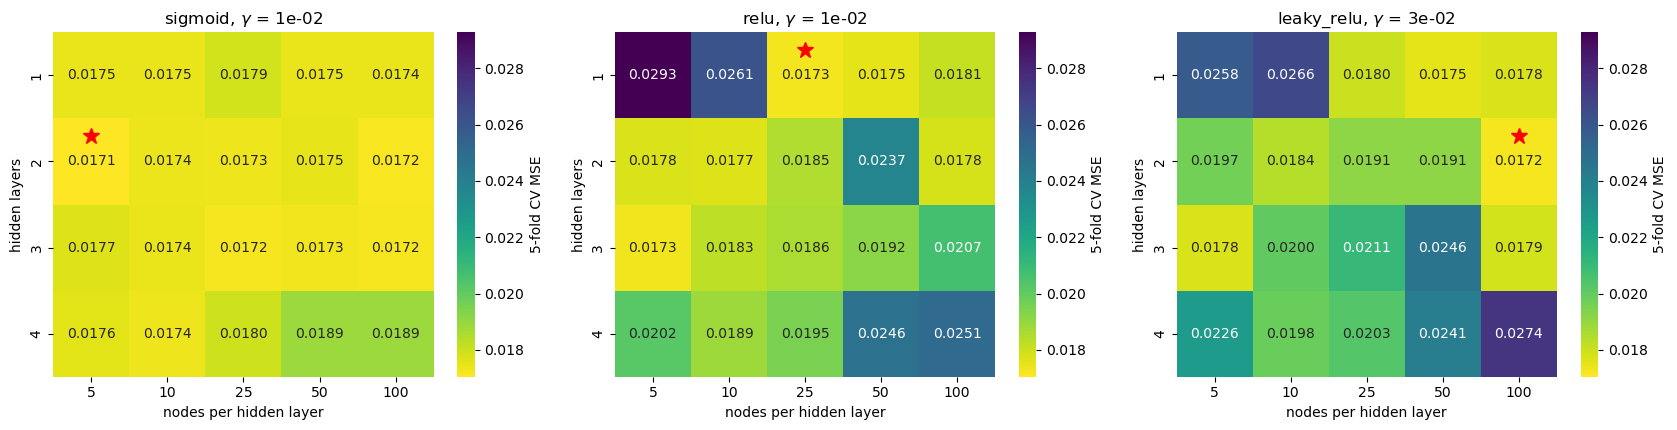

sigmoid: CV MSE (rows: 1 to 4 hidden layers, columns: [5, 10, 25, 50, 100] nodes)
 [[0.0175 0.0175 0.0179 0.0175 0.0174]
 [0.0171 0.0174 0.0173 0.0175 0.0172]
 [0.0177 0.0174 0.0172 0.0173 0.0172]
 [0.0176 0.0174 0.018  0.0189 0.0189]]
sigmoid: training MSE
 [[0.0139 0.0137 0.0139 0.0136 0.0135]
 [0.0136 0.0134 0.0137 0.0134 0.0134]
 [0.0134 0.0133 0.0131 0.0127 0.0126]
 [0.0133 0.0132 0.0126 0.013  0.0116]]
relu: CV MSE (rows: 1 to 4 hidden layers, columns: [5, 10, 25, 50, 100] nodes)
 [[0.0293 0.0261 0.0173 0.0175 0.0181]
 [0.0178 0.0177 0.0185 0.0237 0.0178]
 [0.0173 0.0183 0.0186 0.0192 0.0207]
 [0.0202 0.0189 0.0195 0.0246 0.0251]]
relu: training MSE
 [[0.0251 0.0206 0.0134 0.0136 0.0136]
 [0.0127 0.0135 0.0124 0.0113 0.012 ]
 [0.0132 0.0125 0.0116 0.0109 0.0111]
 [0.0133 0.0117 0.0103 0.0122 0.0123]]
leaky_relu: CV MSE (rows: 1 to 4 hidden layers, columns: [5, 10, 25, 50, 100] nodes)
 [[0.0258 0.0266 0.018  0.0175 0.0178]
 [0.0197 0.0184 0.0191 0.0191 0.0172]
 [0.0178 0.02   0.02

In [19]:
depths = [1, 2, 3, 4]                                     # number of hidden layers
widths = [5, 10, 25, 50, 100]                             # nodes per hidden layer
cv_dw = {act: np.full((len(depths), len(widths)), np.nan) for act in acts}  # CV MSE per (depth, width)
se_dw = {act: np.full_like(cv_dw[act], np.nan) for act in acts}  # its standard error
tr_dw = {act: np.full_like(cv_dw[act], np.nan) for act in acts}  # training MSE (mean over the folds)
t0 = time.perf_counter()                                  # start the clock
for act in acts:
    for i, d in enumerate(depths):
        for j, w in enumerate(widths):
            # CV
            cv_dw[act][i, j], se_dw[act][i, j], tr_dw[act][i, j] = cv_network([w] * d, act, **{**TRAIN, "gamma": GAMMA[act]})
print(f"grid done in {time.perf_counter() - t0:.0f} s")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
vmin = min(np.nanmin(cv_dw[a]) for a in acts); vmax = max(np.nanmax(cv_dw[a]) for a in acts)  # one colour scale
best_dw = {}                                              # best (depth, width) per activation
for ax, act in zip(axes, acts):
    sns.heatmap(cv_dw[act], annot=True, fmt=".4f", cmap="viridis_r", vmin=vmin, vmax=vmax, ax=ax,
                xticklabels=widths, yticklabels=depths, cbar_kws={"label": "5-fold CV MSE"})
    i, j = np.unravel_index(np.nanargmin(cv_dw[act]), cv_dw[act].shape)  # cell with the lowest CV MSE
    best_dw[act] = (depths[i], widths[j])                 # store it
    ax.plot(j + 0.5, i + 0.2, "r*", ms=12)                # star in the cell with the lowest CV MSE
    ax.set_xlabel("nodes per hidden layer"); ax.set_ylabel("hidden layers")
    ax.set_title(rf"{act}, $\gamma$ = {GAMMA[act]:.0e}")
    print(f"{act:10s}: lowest CV MSE {cv_dw[act][i, j]:.4f} +- {se_dw[act][i, j]:.4f} with {depths[i]} hidden layer(s) "
          f"of {widths[j]} nodes; training MSE there {tr_dw[act][i, j]:.4f}; "
          f"cells within one s.e. of it: {int(np.sum(cv_dw[act] <= cv_dw[act][i, j] + se_dw[act][i, j]))} of {cv_dw[act].size}")
plt.tight_layout()
plt.show()
for act in acts:
    print(f"{act}: CV MSE (rows: 1 to 4 hidden layers, columns: {widths} nodes)\n", np.round(cv_dw[act], 4))
    print(f"{act}: training MSE\n", np.round(tr_dw[act], 4))

#### c.2 Figure for the report
**Source:** `cv_dw` of c.2. **Modifications:** readable names, one colour bar, the lowest CV MSE of each map framed in red. No new results.
> **LLM note:** Written with Claude (Level 4). New plotting code.

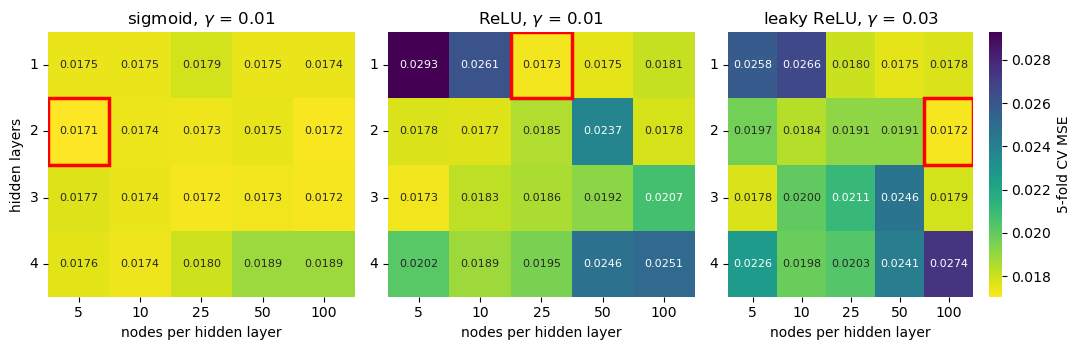

In [20]:
# ---- Figure for the report: c.2 redrawn (cv_dw of c.2; nothing is recomputed) ----
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
vmin = min(np.nanmin(cv_dw[a]) for a in acts); vmax = max(np.nanmax(cv_dw[a]) for a in acts)  # one colour scale
for ax, act in zip(axes, acts):
    sns.heatmap(cv_dw[act], annot=True, fmt=".4f", cmap="viridis_r", vmin=vmin, vmax=vmax, ax=ax,
                xticklabels=widths, yticklabels=depths, annot_kws={"size": 8}, cbar=(act == acts[-1]),
                cbar_kws={"label": "5-fold CV MSE"})          # one colour bar, on the right
    i, j = np.unravel_index(np.nanargmin(cv_dw[act]), cv_dw[act].shape)  # lowest CV MSE of this map
    ax.add_patch(plt.Rectangle((j, i), 1, 1, fill=False, edgecolor="red", lw=2.5, zorder=5))  # frame it
    ax.set_xlabel("nodes per hidden layer"); ax.set_ylabel("hidden layers" if act == acts[0] else "")
    ax.set_title(rf"{NICE[act]}, $\gamma$ = {GAMMA[act]:g}"); ax.tick_params(axis="y", rotation=0)
plt.tight_layout()
save_figure(fig, "c2_depth_width")
plt.show()

#### c.3 Signs of overfitting: over the number of parameters, and over the epochs
**Source:** comparing training and validation error as the model grows is the analysis of Sections 2.9 to 2.10 of the
lecture notes (Hastie et al., Fig. 2.11, as in Project 1, part c); the validation curve over the number of epochs and
early stopping are `week44tuesday.ipynb`, Case 2, Step 4, and Section 8.12 of the lecture notes. **Modifications:** left,
every network of c.2 as two points, training MSE and CV MSE, against its number of parameters; right, training and
validation MSE against the epoch, averaged over the five folds, for the network of part b) ([50], sigmoid) and the
largest one of the grid (4 hidden layers of 100 ReLU nodes), trained for 5000 epochs instead of 1000 (record every 25
epochs). The minimum of the validation curve is where early stopping would stop.
> **LLM note:** Written with Claude (Level 4). New code.

[50]                   sigmoid : validation MSE lowest at epoch 1125 (0.0175); at 1000 epochs 0.0175; at 5000 epochs 0.0184 (training 0.0141)
[100, 100, 100, 100]   relu    : validation MSE lowest at epoch 125 (0.0183); at 1000 epochs 0.0251; at 5000 epochs 0.0270 (training 0.0073)


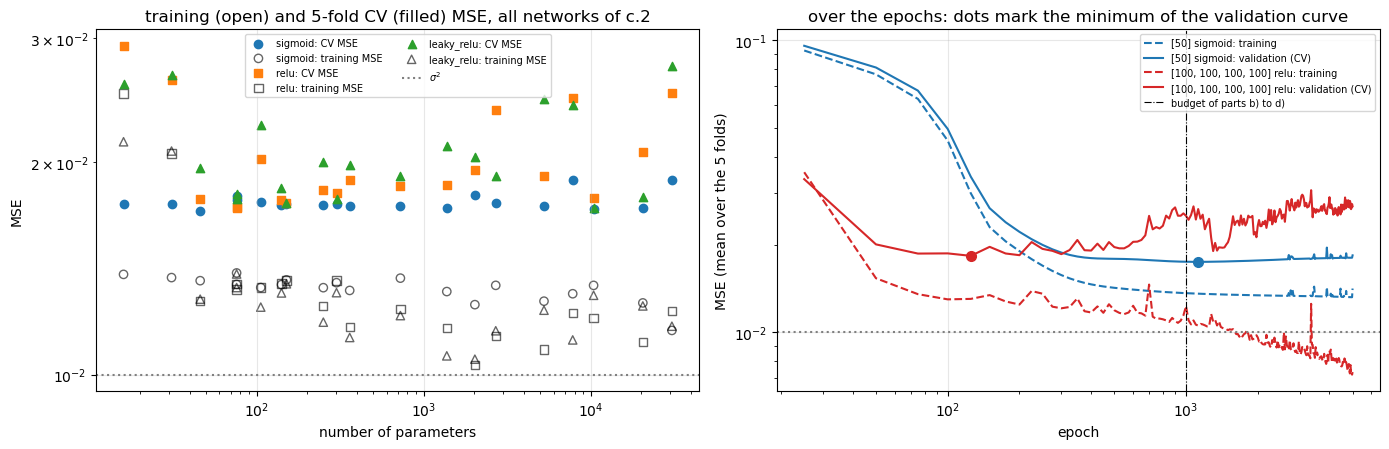

In [21]:
n_params = lambda d, w: (1 * w + w) + (d - 1) * (w * w + w) + (w * 1 + 1)  # weights and biases of [1, w x d, 1]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for act, marker in zip(acts, ["o", "s", "^"]):
    P = np.array([[n_params(d, w) for w in widths] for d in depths])  # number of parameters per cell
    axes[0].scatter(P.ravel(), cv_dw[act].ravel(), marker=marker, label=f"{act}: CV MSE")
    axes[0].scatter(P.ravel(), tr_dw[act].ravel(), marker=marker, facecolors="none", edgecolors="k", alpha=0.6,
                    label=f"{act}: training MSE")
axes[0].axhline(0.1**2, color="gray", ls=":", label=r"$\sigma^2$")
axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set_xlabel("number of parameters"); axes[0].set_ylabel("MSE")
axes[0].set_title("training (open) and 5-fold CV (filled) MSE, all networks of c.2")
axes[0].legend(fontsize=7, ncol=2); axes[0].grid(alpha=0.3)


def fold_curves(hidden, activation, epochs=5000, record_every=25):
    """
    Training and validation MSE against the epoch, averaged over the 5 folds of KFOLD.

    LLM-assisted
    ------------
    Tool: Claude (Claude Opus 5.5, claude.ai, October 2026)
    Role: Wrote the learning curves of c.3: train_network (b.3) on the folds of KFOLD, with a monitor for both errors.
    """
    curves_tr, curves_va = [], []                         # one curve per fold
    for idx_tr, idx_va in KFOLD.split(x_train):
        # fold scaling
        X_a, X_b, y_a, y_m = scale_train_test(x_train[idx_tr, None], x_train[idx_va, None], y_train[idx_tr])
        net = FFNN([1, *hidden, 1], [activation] * len(hidden) + ["identity"])  # a fresh network per fold
        hist = train_network(net, X_a, y_a[:, None], **{**TRAIN, "gamma": GAMMA[activation], "epochs": epochs},  # long training
                             monitor=lambda nt: {"tr": MSE(y_a, nt.predict(X_a)[:, 0]),  # centred y_a
                                                 "va": MSE(y_train[idx_va], nt.predict(X_b)[:, 0] + y_m)},
                             record_every=record_every)
        curves_tr.append(hist["tr"]); curves_va.append(hist["va"])  # store the curves of this fold
    return np.array(hist["epoch"]), np.mean(curves_tr, axis=0), np.mean(curves_va, axis=0)


for hidden, act, color in [([50], "sigmoid", "C0"), ([100] * 4, "relu", "C3")]:
    ep, c_tr, c_va = fold_curves(hidden, act)             # epochs, mean training and validation curves
    k = np.argmin(c_va)                                   # epoch with the lowest validation MSE
    axes[1].plot(ep, c_tr, "--", color=color, label=f"{hidden} {act}: training")
    axes[1].plot(ep, c_va, "-", color=color, label=f"{hidden} {act}: validation (CV)")
    axes[1].plot(ep[k], c_va[k], "o", color=color, ms=7)
    print(f"{str(hidden):22s} {act:8s}: validation MSE lowest at epoch {ep[k]} ({c_va[k]:.4f}); "
          f"at 1000 epochs {c_va[ep == 1000][0]:.4f}; at 5000 epochs {c_va[-1]:.4f} (training {c_tr[-1]:.4f})")
axes[1].axhline(0.1**2, color="gray", ls=":")
axes[1].axvline(EPOCHS, color="k", ls="-.", lw=0.8, label="budget of parts b) to d)")
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("MSE (mean over the 5 folds)")
axes[1].set_title("over the epochs: dots mark the minimum of the validation curve")
axes[1].legend(fontsize=7); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### c.3 Figures for the report
**Source:** the training and CV MSE of the maps of c.2 (`cv_dw`, `tr_dw`); the learning curves are those of c.3,
recomputed with the same function `fold_curves`, network, seed and learning rate only to draw them. **Modifications:**
one panel per activation, with a segment joining the training and the CV MSE of each network; one panel per network for
the learning curves; the noise floor of the true $f$ instead of $\sigma^2$. No new results.
> **LLM note:** Written with Claude (Level 4). New plotting code.

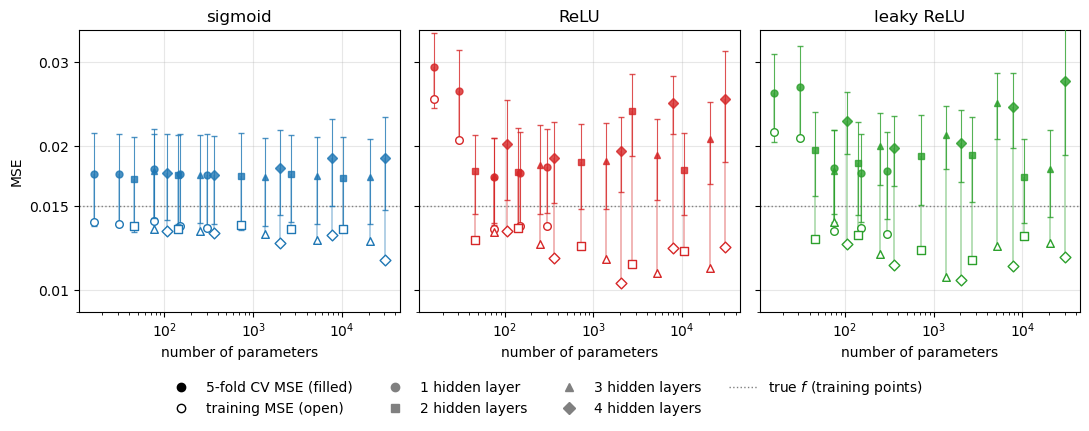

[50]                   sigmoid : validation MSE lowest at epoch 1125 (0.0175); at 1000 epochs 0.0175; at 5000 epochs 0.0184 (training 0.0141)   (must equal the values printed in c.3)
[100, 100, 100, 100]   relu    : validation MSE lowest at epoch 125 (0.0183); at 1000 epochs 0.0251; at 5000 epochs 0.0270 (training 0.0073)   (must equal the values printed in c.3)


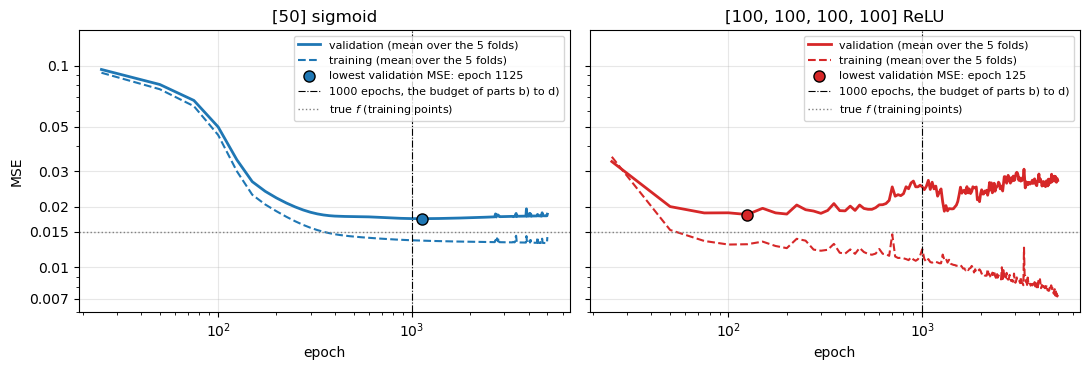

In [22]:
# ---- Figures for the report: c.3 redrawn (training and CV MSE from the maps of c.2; the learning curves repeat those
# of c.3 with the same function, network, seed and learning rate, only to draw them in two panels) ----
DEPTH_MARK = {1: "o", 2: "s", 3: "^", 4: "D"}             # one marker per number of hidden layers
COLOR_A = {"sigmoid": "C0", "relu": "C3", "leaky_relu": "C2"}  # one colour per activation

# Figure 1: training (open) and CV (filled) MSE of every network of c.2 against its number of parameters, one panel per
# activation; the vertical segment joins the two values of the same network, so its length is the gap
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8), sharey=True)
for ax, act in zip(axes, acts):
    for a, d in enumerate(depths):                        # rows of the maps of c.2: number of hidden layers
        P = np.array([n_params(d, w) for w in widths])    # number of parameters of each width
        cv, tr = cv_dw[act][a], tr_dw[act][a]             # CV and training MSE of these networks (c.2)
        ax.vlines(P, tr, cv, color=COLOR_A[act], alpha=0.4, lw=1.2)  # the gap between training and CV
        ax.errorbar(P, cv, yerr=se_dw[act][a], fmt=DEPTH_MARK[d], color=COLOR_A[act], ms=5, capsize=2,
                    elinewidth=0.8, alpha=0.8, zorder=3)  # CV MSE with one standard error (c.2)
        ax.scatter(P, tr, marker=DEPTH_MARK[d], facecolors="white", edgecolors=COLOR_A[act], s=30, zorder=3)  # training
    ax.axhline(noise_train, color="gray", ls=":", lw=1)   # the true f on the training points (b.5)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_ylim(0.009, 0.035)
    plain_log_ticks(ax, [0.01, 0.015, 0.02, 0.03])        # plain tick labels
    ax.set_xlabel("number of parameters"); ax.set_title(NICE[act]); ax.grid(alpha=0.3, which="major")
axes[0].set_ylabel("MSE")
handles = ([Line2D([], [], ls="", marker="o", color="k", label="5-fold CV MSE (filled)"),
            Line2D([], [], ls="", marker="o", mfc="white", mec="k", label="training MSE (open)")]
           + [Line2D([], [], ls="", marker=DEPTH_MARK[d], color="gray", label=f"{d} hidden layer{'s' if d > 1 else ''}")
              for d in depths]
           + [Line2D([], [], color="gray", ls=":", lw=1, label="true $f$ (training points)")])
fig.legend(handles=handles, loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.14), frameon=False)
plt.tight_layout()
save_figure(fig, "c3_train_cv_vs_parameters")
plt.show()

# Figure 2: training and validation MSE against the epoch, averaged over the 5 folds, one panel per network
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, (hidden, act) in zip(axes, [([50], "sigmoid"), ([100] * 4, "relu")]):
    ep, c_tr, c_va = fold_curves(hidden, act)             # the same curves as in c.3
    k = np.argmin(c_va)                                   # epoch with the lowest validation MSE
    color = COLOR_A[act]                                  # colour of the activation
    ax.loglog(ep, c_va, "-", color=color, lw=2, label="validation (mean over the 5 folds)")
    ax.loglog(ep, c_tr, "--", color=color, lw=1.5, label="training (mean over the 5 folds)")
    ax.plot(ep[k], c_va[k], "o", ms=8, color=color, mec="k", zorder=4,
            label=f"lowest validation MSE: epoch {ep[k]}")  # where early stopping would stop
    ax.axvline(EPOCHS, color="k", ls="-.", lw=0.8, label=f"{EPOCHS} epochs, the budget of parts b) to d)")
    ax.axhline(noise_train, color="gray", ls=":", lw=1, label="true $f$ (training points)")
    ax.set_ylim(0.006, 0.15); plain_log_ticks(ax, [0.007, 0.01, 0.015, 0.02, 0.03, 0.05, 0.1])
    ax.set_xlabel("epoch"); ax.grid(alpha=0.3, which="major"); ax.legend(fontsize=8, loc="upper right")
    ax.set_title(f"{hidden} {NICE[act]}")
    print(f"{str(hidden):22s} {act:8s}: validation MSE lowest at epoch {ep[k]} ({c_va[k]:.4f}); at {EPOCHS} epochs "
          f"{c_va[ep == EPOCHS][0]:.4f}; at 5000 epochs {c_va[-1]:.4f} (training {c_tr[-1]:.4f})"
          f"   (must equal the values printed in c.3)")
axes[0].set_ylabel("MSE")
plt.tight_layout()
save_figure(fig, "c3_learning_curves")
plt.show()

#### c.4 Why depth hurts the sigmoid: vanishing gradients
**Source:** Section 8.9 of the lecture notes: the error reaching layer $l$ is a product of factors
$\boldsymbol W^{k+1}\mathrm{diag}(f'(\boldsymbol z^k))$, Eq. (8.71), and $\sigma'\le1/4$; Fig. 8.14 there plots the norm of the
weight gradient per layer after one backward pass for sigmoid and ReLU networks. `deep_network_stats` of
`week42monday.ipynb`, Section 2, does the same computation for a deep network at initialisation. **Modifications:** our
network and data (the 80 standardised training points), 6 hidden layers of 50 nodes (deeper than every network of c.2,
so that Eq. (8.71) has six factors and the effect is clear; Fig. 8.14 goes up to 8 layers), the three activations with the
initialisation of b.2. Left: $\|\partial C/\partial\boldsymbol W^l\|$ per layer before any training. Right: training MSE
against the epoch for the same networks, with plain full batch gradient descent ($\gamma=0.03$)
and with the setup `TRAIN`. The printout also gives the training MSE before the first update.
> **LLM note:** Written with Claude (Level 4), adapted from `week42monday.ipynb` (Section 2) and lecture notes Section 8.9.

sigmoid   : |dC/dW| layer 1 = 9.7e-06, output layer = 6.4e+00, ratio 6.5e+05
     plain GD    : training MSE at the start / after 10 / 100 / 1000 epochs = 0.8735 / 0.0939 / 0.0939 / 0.0939
     TRAIN set-up: training MSE at the start / after 10 / 100 / 1000 epochs = 0.8735 / 0.1978 / 0.0938 / 0.0117
relu      : |dC/dW| layer 1 = 5.3e-01, output layer = 6.6e+00, ratio 1.2e+01
     plain GD    : training MSE at the start / after 10 / 100 / 1000 epochs = 0.5621 / 0.0524 / 0.0248 / 0.0138
     TRAIN set-up: training MSE at the start / after 10 / 100 / 1000 epochs = 0.5621 / 0.0477 / 0.0132 / 0.0099
leaky_relu: |dC/dW| layer 1 = 5.2e-01, output layer = 6.3e+00, ratio 1.2e+01
     plain GD    : training MSE at the start / after 10 / 100 / 1000 epochs = 0.5214 / 0.0530 / 0.0241 / 0.0139
     TRAIN set-up: training MSE at the start / after 10 / 100 / 1000 epochs = 0.5214 / 0.2704 / 0.0129 / 0.0106


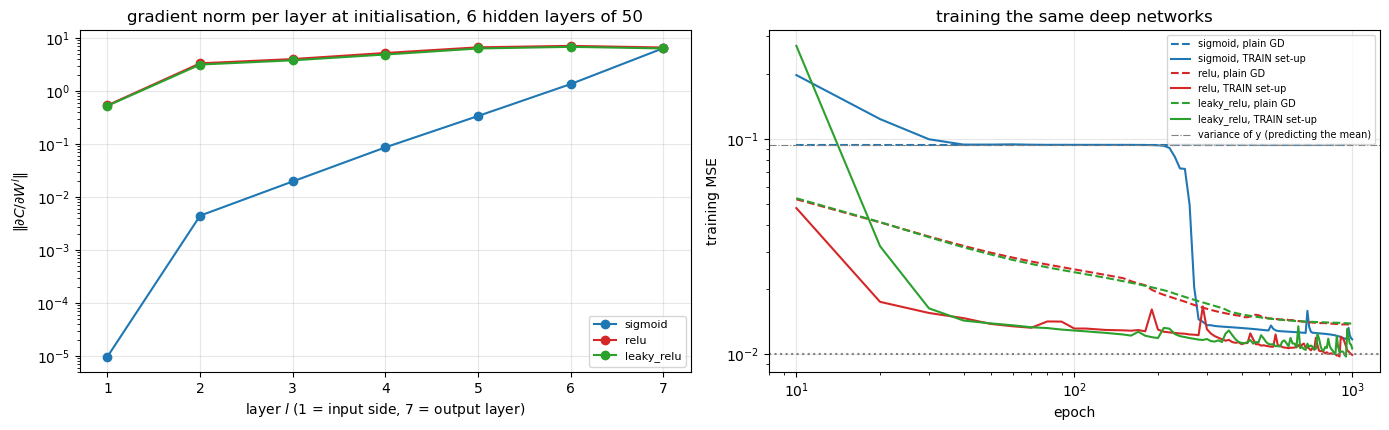

In [23]:
deep = [50] * 6                                           # 6 hidden layers of 50 nodes
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
for act, color in zip(acts, ["C0", "C3", "C2"]):
    net = FFNN([1, *deep, 1], [act] * len(deep) + ["identity"])  # deep network, initialised as in b.2
    norms = [np.linalg.norm(dW) for dW, _ in net.compute_gradient(X_train_s, Y_train_c)]  # one backward pass
    axes[0].semilogy(np.arange(1, len(norms) + 1), norms, "o-", color=color, label=act)
    print(f"{act:10s}: |dC/dW| layer 1 = {norms[0]:.1e}, output layer = {norms[-1]:.1e}, ratio {norms[-1] / norms[0]:.1e}")
    for method_kw, style in [(dict(method="plain", gamma=0.03, batch_size=None), "--"),
                             ({**TRAIN, "gamma": GAMMA[act]}, "-")]:
        net = FFNN([1, *deep, 1], [act] * len(deep) + ["identity"])  # deep network, initialised as in b.2
        mse_start = mse(net.predict(X_train_s), Y_train_c)  # training MSE before the first update
        hist = train_network(net, X_train_s, Y_train_c, **{**method_kw, "epochs": EPOCHS},
                             monitor=lambda nt: {"tr": mse(nt.predict(X_train_s), Y_train_c)}, record_every=10)
        # label
        name = "plain GD" if method_kw["method"] == "plain" and method_kw["batch_size"] is None else "TRAIN set-up"
        axes[1].loglog(hist["epoch"], hist["tr"], style, color=color, label=f"{act}, {name}")
        print(f"     {name:12s}: training MSE at the start / after 10 / 100 / 1000 epochs = "
              f"{mse_start:.4f} / {hist['tr'][0]:.4f} / {hist['tr'][9]:.4f} / {hist['tr'][-1]:.4f}")
axes[0].set_xlabel("layer $l$ (1 = input side, 7 = output layer)"); axes[0].set_ylabel(r"$\|\partial C/\partial W^l\|$")
axes[0].set_title("gradient norm per layer at initialisation, 6 hidden layers of 50")
axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)
axes[1].axhline(np.var(y_train), color="gray", ls="-.", lw=0.8, label="variance of y (predicting the mean)")
axes[1].axhline(0.1**2, color="gray", ls=":")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("training MSE")
axes[1].set_title("training the same deep networks")
axes[1].legend(fontsize=7); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### c.4 Figure for the report
**Source:** the deep networks of c.4 (6 hidden layers of 50 nodes, initialised as in b.2), recomputed with the same
seed, learning rates and number of epochs only to draw them. **Modifications:** the direction of backpropagation and
the ratio output layer / layer 1 in panel (a); plain gradient descent and Adam in separate panels; the variance of $y$
and the noise floor of the true $f$ instead of $\sigma^2$. No new results.
> **LLM note:** Written with Claude (Level 4). New plotting code.

sigmoid   : |dC/dW| layer 1 = 9.7e-06, output layer = 6.4e+00, ratio 6.5e+05   (must equal the values printed in c.4)
     plain GD    : training MSE at the start / after 10 / 100 / 1000 epochs = 0.8735 / 0.0939 / 0.0939 / 0.0939   (must equal c.4)
     TRAIN set-up: training MSE at the start / after 10 / 100 / 1000 epochs = 0.8735 / 0.1978 / 0.0938 / 0.0117   (must equal c.4)
relu      : |dC/dW| layer 1 = 5.3e-01, output layer = 6.6e+00, ratio 1.2e+01   (must equal the values printed in c.4)
     plain GD    : training MSE at the start / after 10 / 100 / 1000 epochs = 0.5621 / 0.0524 / 0.0248 / 0.0138   (must equal c.4)
     TRAIN set-up: training MSE at the start / after 10 / 100 / 1000 epochs = 0.5621 / 0.0477 / 0.0132 / 0.0099   (must equal c.4)
leaky_relu: |dC/dW| layer 1 = 5.2e-01, output layer = 6.3e+00, ratio 1.2e+01   (must equal the values printed in c.4)
     plain GD    : training MSE at the start / after 10 / 100 / 1000 epochs = 0.5214 / 0.0530 / 0.0241 / 0.0139   (must eq

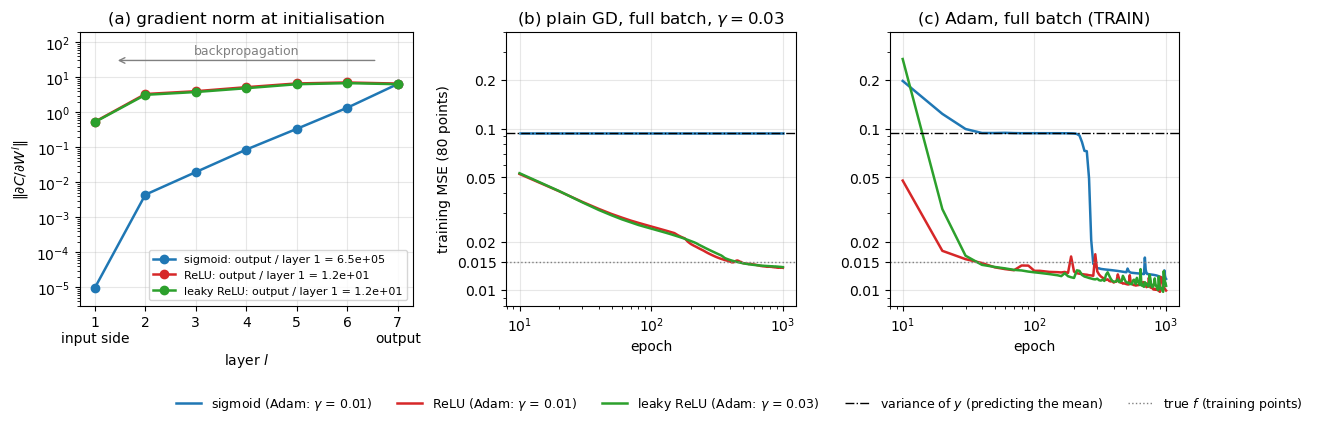

In [24]:
# ---- Figure for the report: c.4 redrawn (the same deep networks, initialisation, seed and learning rates as c.4,
# recomputed only to draw the two optimisers in separate panels) ----
fig, axes = plt.subplots(1, 3, figsize=(12, 3.9), gridspec_kw={"width_ratios": [1.15, 1, 1]})
layers = np.arange(1, len(deep) + 2)                      # layer 1 (input side) to the output layer
for act in acts:
    net = FFNN([1, *deep, 1], [act] * len(deep) + ["identity"])  # deep network, initialised as in b.2 (same seed)
    norms = [np.linalg.norm(dW) for dW, _ in net.compute_gradient(X_train_s, Y_train_c)]  # one backward pass
    axes[0].semilogy(layers, norms, "o-", color=COLOR_A[act], lw=1.8,
                     label=f"{NICE[act]}: output / layer 1 = {norms[-1] / norms[0]:.1e}")
    print(f"{act:10s}: |dC/dW| layer 1 = {norms[0]:.1e}, output layer = {norms[-1]:.1e}, "
          f"ratio {norms[-1] / norms[0]:.1e}   (must equal the values printed in c.4)")
    for ax, method_kw, name in [(axes[1], dict(method="plain", gamma=0.03, batch_size=None), "plain GD"),
                                (axes[2], {**TRAIN, "gamma": GAMMA[act]}, "TRAIN set-up")]:
        net = FFNN([1, *deep, 1], [act] * len(deep) + ["identity"])  # a fresh deep network, as in c.4
        mse_start = mse(net.predict(X_train_s), Y_train_c)  # training MSE before the first update
        hist = train_network(net, X_train_s, Y_train_c, **{**method_kw, "epochs": EPOCHS},
                             monitor=lambda nt: {"tr": mse(nt.predict(X_train_s), Y_train_c)}, record_every=10)
        ax.loglog(hist["epoch"], hist["tr"], color=COLOR_A[act], lw=1.8)  # its training curve
        print(f"     {name:12s}: training MSE at the start / after 10 / 100 / 1000 epochs = {mse_start:.4f} / "
              f"{hist['tr'][0]:.4f} / {hist['tr'][9]:.4f} / {hist['tr'][-1]:.4f}   (must equal c.4)")

# (a) gradient norms: the error travels from the output layer back to layer 1
axes[0].annotate("", xy=(1.4, 30), xytext=(6.6, 30), arrowprops=dict(arrowstyle="->", color="gray"))
axes[0].text(4, 45, "backpropagation", ha="center", color="gray", fontsize=9)
axes[0].set_xticks(layers)
axes[0].set_xticklabels(["1\ninput side"] + [str(l) for l in layers[1:-1]] + [f"{layers[-1]}\noutput"])
axes[0].set_ylim(3e-6, 200); axes[0].set_xlabel("layer $l$"); axes[0].set_ylabel(r"$\|\partial C/\partial W^l\|$")
axes[0].set_title("(a) gradient norm at initialisation"); axes[0].grid(alpha=0.3); axes[0].legend(fontsize=8, loc="lower right")

# (b), (c) training of the same deep networks with plain gradient descent and with Adam
for ax, title in [(axes[1], r"(b) plain GD, full batch, $\gamma=0.03$"), (axes[2], "(c) Adam, full batch (TRAIN)")]:
    ax.axhline(np.var(y_train), color="k", ls="-.", lw=1)  # variance of y: the error of predicting the mean
    ax.axhline(noise_train, color="gray", ls=":", lw=1)   # the true f on the training points (b.5)
    ax.set_ylim(0.008, 0.4); plain_log_ticks(ax, [0.01, 0.015, 0.02, 0.05, 0.1, 0.2])
    ax.set_xlabel("epoch"); ax.set_title(title); ax.grid(alpha=0.3, which="major")
axes[1].set_ylabel("training MSE (80 points)")
handles = ([Line2D([], [], color=COLOR_A[a], lw=1.8, label=rf"{NICE[a]} (Adam: $\gamma$ = {GAMMA[a]:g})") for a in acts]
           + [Line2D([], [], color="k", ls="-.", lw=1, label="variance of $y$ (predicting the mean)"),
              Line2D([], [], color="gray", ls=":", lw=1, label="true $f$ (training points)")])
fig.legend(handles=handles, loc="lower center", ncol=5, bbox_to_anchor=(0.62, -0.1), frameon=False, fontsize=9)
plt.tight_layout()
save_figure(fig, "c4_vanishing_gradients")
plt.show()

#### c.5 The best network of each activation on the test set
**Source:** the refit and the single evaluation on the test set of b.7. **Modifications:** for each activation the
depth and width with the lowest CV MSE in c.2 (the selection rule of part b; c.6 says which networks the one standard
error rule would pick).
> **LLM note:** Written with Claude (Level 4), adapted from b.7.

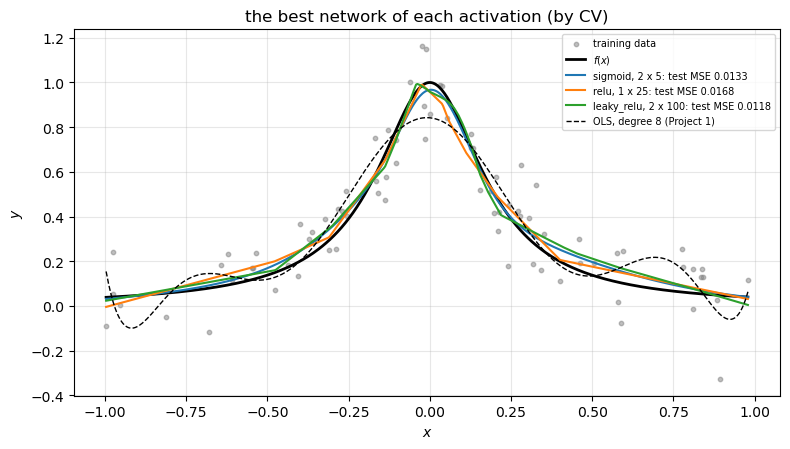

FFNN [5, 5], sigmoid (part c)           : CV 0.0171 +- 0.0038, test 0.0133 +- 0.0047, MSE to f 0.00100, 46 parameters
FFNN [25], relu (part c)                : CV 0.0173 +- 0.0036, test 0.0168 +- 0.0056, MSE to f 0.00147, 76 parameters
FFNN [100, 100], leaky_relu (part c)    : CV 0.0172 +- 0.0034, test 0.0118 +- 0.0039, MSE to f 0.00158, 10401 parameters


In [25]:
fits_c = {}                                               # fitted curves per activation
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.scatter(x_train, y_train, s=10, color="gray", alpha=0.5, label="training data")
ax.plot(x_grid, runge(x_grid), "k-", lw=2, label="$f(x)$")
for act in acts:
    d, w = best_dw[act]                                   # best depth and width of this activation (c.2)
    i, j = depths.index(d), widths.index(w)               # position of this network in the grids of c.2
    net = FFNN([1, *[w] * d, 1], [act] * d + ["identity"])  # the selected network of this activation
    train_network(net, X_train_s, Y_train_c, **{**TRAIN, "gamma": GAMMA[act]})  # refit on all 80 points
    t_m, t_se = test_mse_se(y_test, net.predict(X_test_s)[:, 0] + y_mean)  # the test set, once
    fits_c[act] = net.predict(X_grid_s)[:, 0] + y_mean    # its curve on the dense grid
    REG[f"FFNN {[w] * d}, {act} (part c)"] = dict(cv=cv_dw[act][i, j], cv_se=se_dw[act][i, j], cv_train=tr_dw[act][i, j],  # row
                                                 test=t_m, test_se=t_se, f_mse=mse_to_f(fits_c[act]),
                                                 n_par=net.theta.size, gamma=GAMMA[act])
    ax.plot(x_grid, fits_c[act], lw=1.5, label=f"{act}, {d} x {w}: test MSE {t_m:.4f}")
ax.plot(x_grid, ols8.predict(x_grid[:, None]), "k--", lw=1, label="OLS, degree 8 (Project 1)")
ax.set_xlabel("$x$"); ax.set_ylabel("$y$"); ax.legend(fontsize=7); ax.grid(alpha=0.3)
ax.set_title("the best network of each activation (by CV)")
plt.tight_layout()
plt.show()
for name, r in REG.items():
    if "part c" in name:
        print(f"{name:40s}: CV {r['cv']:.4f} +- {r['cv_se']:.4f}, test {r['test']:.4f} +- {r['test_se']:.4f}, "
              f"MSE to f {r['f_mse']:.5f}, {r['n_par']} parameters")

#### c.5 Figure for the report
**Source:** `fits_c`, `REG` and `best_dw` of c.2 and c.5. **Modifications:** the colours of the activations and readable names. No new results.
> **LLM note:** Written with Claude (Level 4). New plotting code.

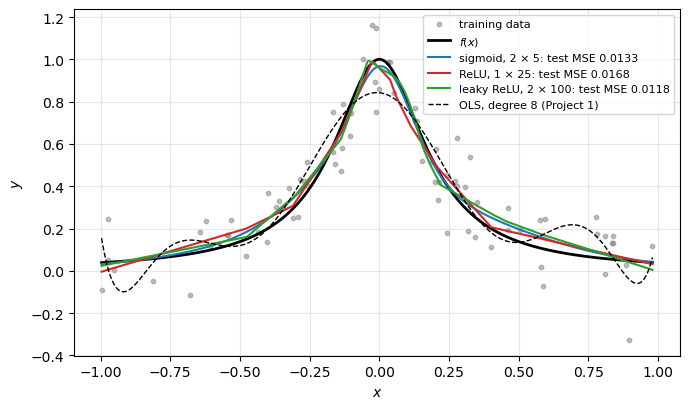

In [26]:
# ---- Figure for the report: c.5 redrawn (fits_c and REG of c.5; nothing is recomputed) ----
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.scatter(x_train, y_train, s=10, color="gray", alpha=0.5, label="training data")
ax.plot(x_grid, runge(x_grid), "k-", lw=2, label="$f(x)$")
for act in acts:
    d, w = best_dw[act]                                   # best depth and width of this activation (c.2)
    r = REG[f"FFNN {[w] * d}, {act} (part c)"]            # its row of the table
    ax.plot(x_grid, fits_c[act], color=COLOR_A[act], lw=1.5, label=f"{NICE[act]}, {d} × {w}: test MSE {r['test']:.4f}")
ax.plot(x_grid, ols8.predict(x_grid[:, None]), "k--", lw=1, label="OLS, degree 8 (Project 1)")
ax.set_xlabel("$x$"); ax.set_ylabel("$y$"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout()
save_figure(fig, "c5_best_fits")
plt.show()

#### c.6 Observations (integrated version, notes for the report)
> **LLM note:** Drafted with Claude from the outputs above and from our question-and-answer session with Claude, in
> which we went through part c) step by step (text Level 3 if used as it is). Rewrite in your own words for the report,
> and check every number against your own run. **[own]** marks reasoning that is not taken from the course material.
> Section and equation numbers refer to the lecture notes of 25 October 2026; a.6 and b.8 are cited with the numbering
> of their integrated versions.

**What the cells show (c.1 to c.5)**

1. **The learning rate per activation (c.1).** With one hidden layer of 50 nodes the three activations reach the same
   CV MSE: 0.0175 ± 0.0038 for the sigmoid ($\gamma=10^{-2}$), 0.0175 ± 0.0039 for the ReLU ($10^{-2}$) and 0.0175 ±
   0.0037 for the leaky ReLU ($3\cdot10^{-2}$). The optimum is flat: from $\gamma=10^{-2}$ to $0.1$ every value lies
   between 0.0175 and 0.0183 (for the sigmoid also 0.0184 at $3\cdot10^{-3}$). At $\gamma=10^{-3}$ all three are clearly
   worse (0.0263 to 0.0284): an Adam step is at most about $\gamma$ long (Eq. (4.72)), so 1000 of them do not get far
   enough from the start [own reading]. For the leaky ReLU, $3\cdot10^{-2}$ beats $10^{-2}$ (0.0175 against 0.0176), far below one
   standard error: such a choice is decided by noise, which does no harm because the optimum is flat.

2. **The best architecture of each activation (c.2).** Lowest CV MSE: sigmoid 0.0171 ± 0.0038 with 2 hidden layers of 5
   nodes, ReLU 0.0173 ± 0.0036 with 1 layer of 25, leaky ReLU 0.0172 ± 0.0034 with 2 layers of 100. The three optima
   are far closer to each other than one standard error: on this problem the activation does not matter for the *best*
   network (item 9). This agrees with Section 8.6.4 (Table 8.2), where the seven non saturating activations differ by
   less than the spread between random seeds. In Table 8.2 the sigmoid is far behind, in a network with three hidden
   layers of 30 units; in our maps the sigmoid networks with three and four hidden layers are within one standard error
   of the best as well. c.2 trains with Adam, and c.4 shows that Adam trains even six sigmoid layers (item 5)
   [own reading]. The one standard error rule of Section 3.14 (Eq. (3.96)), applied to the architecture, would pick the
   smallest network within one standard error of the best: one layer of 5 nodes for the sigmoid (CV MSE
   0.0175) and two layers of 5 nodes for the ReLU and the leaky ReLU (46 parameters, 0.0178 and 0.0197). We keep the
   lowest CV MSE (the rule of part b); the data cannot tell the two choices apart.

3. **How robust each activation is to the architecture (c.2).** Here the activations differ a lot. The sigmoid map is
   flat: all 20 architectures are within one standard error of the best (CV MSE 0.0171 to 0.0189). The ReLU and leaky
   ReLU maps are not (15 and 13 of 20):
   (i) *narrow single layers underfit*: one layer of 5 and 10 ReLU nodes gives CV MSE 0.0293 and 0.0261, with training
   MSEs of 0.0251 and 0.0206, far above the 0.0150 of the true $f$. One hidden layer of $N$ ReLU nodes is a piecewise
   linear function with at most $N+1$ pieces (Lemma 8.1, Section 8.4.1), too few for the peak, while 5 sigmoids already
   give 5 smooth steps (b.8, item 14);
   (ii) *deep and wide networks overfit*: 4 layers of 50 and 100 nodes give 0.0246 and 0.0251 with the ReLU, 0.0241 and
   0.0274 with the leaky ReLU, with training MSEs between 0.0112 and 0.0123. This holds at the learning rate tuned on
   [50] in c.1 and for 1000 epochs: part d) trains the same 4 × 50 ReLU network without penalty at other learning rates
   and gets 0.0246 at $\gamma=10^{-2}$, the value of this map, but 0.0188 at $\gamma=10^{-3}$ (d.2), within one standard
   error of the best ReLU network (0.0173 ± 0.0036). Section 8.12 calls the learning rate "by far the most important"
   hyperparameter;
   (iii) *the maps are not smooth*: 2 layers of 50 ReLU nodes give 0.0237, but 2 layers of 25 or 100 nodes give 0.0185
   and 0.0178. A single cell like this one can come from the one seed we use: the cost is not convex and the minimum
   reached depends on the initialisation (Section 8.7), and results depend on the seed (Section 8.15) [own reading];
   part d) returns to this architecture.

4. **Signs of overfitting (c.3).** Yes, for the deep and wide ReLU and leaky ReLU networks, and they look as in Project 1
   (takeaway 7). *Left panel:* the gap between CV and training MSE is small for the sigmoid networks (one layer of 50 nodes:
   CV 0.0175, training 0.0136; four layers of 100: 0.0189 and 0.0116) and large for the deepest ReLU and leaky ReLU
   networks (four layers of 100: 0.0251 and 0.0123 with the ReLU, 0.0274 and 0.0117 with the leaky ReLU), whose CV MSE
   rises with the number of parameters. Every network that does not underfit has a training MSE between 0.0103 and 0.0139. The noise
   floor to compare with is the error of the true $f$ on the training points, 0.0150 (b.5), not $\sigma^2=0.01$. Being
   below it does not by itself mean overfitting: even a correct linear model with $p$ parameters has an expected training
   error $\sigma^2(1-p/n)$, below the noise level (Section 3.7, Eq. (3.35)), and the [50] sigmoid network is below it too
   (0.0136 in c.2, 0.0141 after 5000 epochs) while its validation MSE stays flat. *Right panel:* one layer of 50 sigmoid
   nodes reaches its lowest validation MSE at epoch 1125 (0.0175) and drifts only to 0.0184 at epoch 5000. Four layers
   of 100 ReLU nodes reach their lowest validation MSE already at epoch 125 (0.0183); after that the validation MSE rises
   to 0.0251 at 1000 epochs and 0.0270 at 5000, while the training MSE falls to 0.0073, far below 0.0150. This is the
   pattern of Section 8.12: the validation cost rises while the training cost still falls. In the report the left panel
   is drawn with one panel per activation, each network as a segment from its training MSE (open) to its CV MSE
   (filled), so that the length of the segment is the gap, and the right panel as one panel per network (c.3, figures
   for the report). Stopping at epoch 125 would
   make this network almost as good as the best ones; for networks early stopping is "the single most effective and
   cheapest regulariser available" (Section 8.12). Parts b) to d) train for a fixed 1000 epochs, so that the effects of
   the architecture and of the penalties stay visible; part e) uses early stopping.

5. **Vanishing gradients (c.4).** At initialisation, with 6 hidden layers of 50 nodes, the gradient norm of the first
   layer is $9.7\cdot10^{-6}$ against 6.4 for the output layer with the sigmoid, a ratio of $6.5\cdot10^{5}$, and 0.53
   and 0.52 against 6.6 and 6.3 with the ReLU and the leaky ReLU, a ratio of 12. Along the hidden layers of the sigmoid
   network the norm falls layer by layer (left panel), as the bound $\sigma'\le1/4$ in every factor of Eq. (8.71)
   implies; with the ReLU family the profile is flat from layer 2 on, as in Fig. 8.14 of the lecture notes. The last
   step, from layer 2 to layer 1, is larger for all three activations and much larger for the sigmoid (left
   panel). For every activation part of it is the size of $\boldsymbol W^1$, a $1\times50$ matrix against
   the $50\times50$ matrices $\boldsymbol W^2$ to $\boldsymbol W^6$ (item 13 (ii)). For the sigmoid there is a second difference: the
   gradient of layer 1 is $\boldsymbol x^T\boldsymbol\delta^1$ (Eq. (8.68)), a sum of $\delta^1_i x_i$ over the points
   weighted by the centred input $x$, which has both signs, while every deeper layer sums over sigmoid outputs, which
   are positive (Section 8.6.1); with biases of only 0.01, $\sigma'(z^1)$ is an even function of $x$, so the terms of
   layer 1 can cancel, while the derivative of the ReLU is a step, not an even function [own reading]. The cells do not
   measure how much of the drop each of the two effects explains.
   *Training (right panel):* with plain gradient descent the deep sigmoid network only learns the mean. Its training
   MSE falls from 0.8735 before the first update to 0.0939 at epoch 10, the variance of $y$ (0.0938, b.5), that is the
   error of predicting the mean, and stays there at 100 and 1000 epochs. Plain gradient descent moves every parameter
   in proportion to its gradient (Eq. (4.15)), so the output layer, whose gradient is $6.5\cdot10^{5}$ times larger than
   that of the first layer, fits the mean within those first epochs, while the early layers are left "essentially
   unchanged" (Section 8.9). With the ReLU family the same plain gradient descent trains normally (ReLU 0.0524 / 0.0248
   / 0.0138 at 10 / 100 / 1000 epochs). With Adam the deep sigmoid network does learn: it sits at 0.0938 until about
   epoch 200 and then drops to 0.0117 at 1000 epochs. Adam's step does not shrink with the gradient: its first step has
   length $\gamma$ whatever the gradient, and every step is at most about $\gamma$ (Section 4.11, Eq. (4.72); b.8,
   item 6), which compensates for much of the attenuation [own reading]. So depth does not make the sigmoid
   untrainable, but it makes it slow and dependent on an adaptive optimiser, which is why the lecture notes recommend
   the ReLU family as the default (Sections 8.6.4 and 8.9). In the report figure (c.4, figure for the report) panel (a)
   shows the gradient norms with the direction of backpropagation and the ratio output layer / layer 1 of each
   activation, and panels (b) and (c) show plain gradient descent and Adam separately, with the variance of $y$ and the
   true $f$ on the training points as reference lines.

6. **The best network of each activation on the test set (c.5).** Sigmoid [5, 5] (46 parameters): test MSE 0.0133 ±
   0.0047, MSE to $f$ 0.00100; ReLU [25] (76 parameters): 0.0168 ± 0.0056 and 0.00147; leaky ReLU [100, 100] (10401
   parameters): 0.0118 ± 0.0039 and 0.00158. The test MSEs differ more than the CV MSEs, but by less than one standard
   error of 20 points, and they do not even rank the models as the noise free MSE to $f$ does: the leaky ReLU has the
   lowest test MSE and the highest MSE to $f$. The fits differ in kind: the sigmoid fit is smooth, the ReLU and leaky
   ReLU fits are piecewise linear (Lemma 8.1; Section 8.6.2) with visible kinks near the top of the peak. All three are
   much closer to $f$ than OLS of degree 8 (0.00100 to 0.00158 against 0.00572).

7. **What we take from part c) [own].** The sigmoid is robust to the architecture, gives smooth fits and needs few
   parameters, but in depth it trains slowly and only with an adaptive optimiser. The ReLU family trains at every depth
   tested here, even with plain gradient descent, but needs enough nodes per layer and, at the learning rate of c.1 and
   1000 epochs, overfits sooner when the network is deep and wide. For this problem one or two small sigmoid layers are
   the safest choice, while the best CV MSEs of the three activations are equal within the noise; in general the
   lecture notes advise the ReLU as the default and the sigmoid in a hidden layer only to reproduce old results
   (Section 8.6.4). Every number comes from one seed, and Table 8.2 shows that the spread between seeds can exceed the
   spread between activations: repeating c.2 with a few seeds would be the first improvement.

**The concepts behind part c) (our discussion)**

8. **What c.1 does, and what it does not.** c.1 does not compute an optimal learning rate. With the optimiser fixed in
   b.6 (`TRAIN`: Adam, full batch, 1000 epochs) it tries five learning rates per activation and keeps the one with the
   lowest CV MSE, on one network ([50]) only; the same value is then used for all 20 architectures of c.2 (item 3 (ii)
   shows what this means for the deep ReLU networks). An optimal learning rate can be written down for the quadratic
   cost of a linear model, $\gamma^*=2/(\lambda_{\max}+\lambda_{\min})$ of the Hessian (Section 4.5, Eq. (4.26)), which
   is why b.4 can use it for the network without hidden layers (b.8, item 4). The cost of a network with hidden layers is
   not convex and its Hessian is out of reach (Section 8.7), so its learning rate is a hyperparameter chosen by cross
   validation, never on the test set (Section 8.12; takeaway 6). Each activation gets its own learning rate because the
   size of the gradients depends on the activation and on its initialisation, variance $1/M_{l-1}$ for the sigmoid and
   $2/M_{l-1}$ for the ReLU family (Section 8.10, Eqs. (8.72) and (8.74); b.8, item 11); c.4 shows how different the
   gradients are. The course's MNIST example also uses different learning rates for the two activations
   (`week41monday.ipynb`: $\gamma=0.5$ for the sigmoid, $0.1$ for the ReLU).

9. **Why the activation does not matter for the best network.** (i) *All three can represent $f$.* A network with one
   hidden layer is a universal approximator if and only if its activation is not a polynomial on any interval (Section
   8.4, the result of Leshno et al.), so the sigmoid, the ReLU and the leaky ReLU all qualify. For the ReLU in one
   dimension Theorem 8.2 (Section 8.4.1) makes this concrete: $N$ units can form the piecewise linear interpolant of
   $f$ at $N+1$ knots, with an error at most $L(b-a)/(2N)$ for an $L$-Lipschitz $f$, falling like $N^{-2}$ for a
   smooth one. The theorems do not say whether training finds these weights (Section 8.4.4, "representability is not learnability"). (ii) *Each
   activation is judged at its own best architecture,* and these differ: two layers of 5 sigmoid nodes, one layer of 25
   ReLU nodes, two layers of 100 leaky ReLU nodes (c.2). The ReLU family needs more nodes, because its pieces are
   straight (Lemma 8.1), while a sigmoid node is a smooth step (b.8, item 14): one layer of 5 or 10 ReLU nodes underfits
   (item 3 (i)), one layer of 25 does not. (iii) *The best networks are close to the noise floor:* the true $f$
   scores 0.0150 on the training points (b.5; b.8, item 2), the best networks 0.0171 to 0.0173 in CV, and they are far
   closer to each other than their standard errors (0.0034 to 0.0038), so the data cannot separate them. (iv) Section 8.6.4
   finds the same with five seeds (Table 8.2): the seven non saturating activations span 0.006 in test accuracy, less
   than the standard deviation between seeds (0.004 to 0.008). The activation does matter for how robust the result is
   to the architecture (item 3), for the shape of the fit (item 6) and for deep networks (item 5).

10. **How to read the curves of c.3.** A flat validation curve means no overfitting. Overfitting is the pattern of
    Sections 4.7.8 and 8.12: the validation cost rises while the training cost still falls, so the gap opens. The three
    patterns, with an example of each from c.2 and c.3:

| what the curves show | meaning | example |
|---|---|---|
| training and validation MSE both high and close | underfitting | one layer of 5 ReLU nodes: CV 0.0293, training 0.0251 |
| both low, a small gap, a flat validation curve | a good fit | [50] sigmoid: CV 0.0175, training 0.0136; validation 0.0175 at epoch 1125, 0.0184 at 5000 |
| training MSE still falling, validation MSE past a minimum and rising, the gap opening | overfitting | 4 × 100 ReLU: validation 0.0183 at epoch 125, 0.0251 at 1000, 0.0270 at 5000; training 0.0073 at 5000 |

11. **Early stopping, as c.3 shows it.** The curves of c.3 are averaged over the five folds (`fold_curves`), so the
    epoch with the lowest validation MSE is a choice of the number of epochs by cross validation, like any other
    hyperparameter (Section 8.12); the dot in the right panel, and in each panel of the report figure, is where early stopping would stop
    (`week44tuesday.ipynb`, Case 2, Step 4). Stopping there trades a little bias for a lot of variance, in the spirit of the Ridge penalty
    (Section 4.7.8). For the 4 × 100 ReLU network the minimum at epoch 125 lies in a stretch where the validation curve
    is almost flat (right panel), so the stopping epoch is about 100 to 300 rather than exactly 125; the patience of
    Section 4.7.8 is there so that the stopping rule does not react to such fluctuations. A smaller learning rate acts in
    a similar way (d.5, item 3): in d.2 the 4 × 50 ReLU network without penalty goes from 0.0246 at $\gamma=10^{-2}$ to
    0.0188 at $\gamma=10^{-3}$ (item 3 (ii)).

12. **What the gradient norms of c.4 mean.** $\|\partial C/\partial\boldsymbol W^l\|$ is the Frobenius norm of the gradient
    with respect to all the weights of layer $l$, the quantity of Fig. 8.14 (`np.linalg.norm` of the matrix `dW`: the
    square root of the sum of the squares of its entries). Plain gradient descent changes every weight by $\gamma$ times
    its gradient (Eq. (4.15)), so the norm says how fast a layer would learn. Layer 1 holds the weights from the input
    $x$ to the first hidden layer, the output layer those from the last hidden layer to the output. Backpropagation
    starts at the output with $\boldsymbol\delta^L=\tfrac2n(\boldsymbol a^L-\boldsymbol y)$ (a.6, item 2) and reaches
    layer 1 last, after one factor $\boldsymbol W\,\mathrm{diag}(f'(\boldsymbol z))$ per layer (Eqs. (8.66) and
    (8.71); a.6, item 4). The ratio, output layer over layer 1, says how many times faster the output layer learns:
    $6.5\cdot10^{5}$ for the sigmoid, the "different layers learning at widely different speeds" of Section 8.9, which
    is why plain gradient descent only fits the mean (item 5), and 12 for the ReLU family. c.4 uses 6 hidden layers,
    deeper than every network of c.2, so that Eq. (8.71) has six factors (Fig. 8.14 goes up to 8 hidden layers).

13. **What is behind the numbers of c.4.** (i) *The steady fall for the sigmoid.* In every layer the error
    is multiplied by $(\boldsymbol W^{l+1})^T$ and by $f'(\boldsymbol z^l)$ (Eq. (8.66)). With all hidden layers 50 wide,
    the variance $1/50$ keeps the size of the signal in both directions (Section 8.10, Eq. (8.72)), and for the ReLU the
    variance $2/M_{l-1}$ makes up for the half of the inputs that the ReLU sets to zero (Eq. (8.74)). What is left for
    the sigmoid is $\sigma'\le1/4$ (Eq. (8.22)) in every layer, hence the steady fall of the left panel, and no such
    factor for the ReLU on its active nodes [own reading]. (ii) *Layer 1 is lower also because of its size.* The norm adds the squares of all
    entries, and $\boldsymbol W^1$ is a $1\times50$ matrix against the $50\times50$ matrix $\boldsymbol W^2$ (shapes printed in
    b.2), so with entries of the same
    size its norm is smaller; for the ReLU the left panel shows 0.53 against about 3 for layer 2 [own reading]. (iii) *Plain gradient descent and Adam.* Plain gradient descent uses $\gamma=0.03$ for all
    three activations; the notebook does not scan this value, so item 5 shows what happens at this $\gamma$. The
    starting MSE of the deep sigmoid network, 0.8735, is much larger than the variance of $y$, 0.0938; within 10 epochs
    plain gradient descent removes the difference, the network predicts the mean (0.0939) and stays there (item 5).
    Adam is not stopped by the small gradients of the early layers: its first step has length $\gamma$ whatever the
    gradient, and a gradient of $10^{-3}$ and one of $10^{3}$ give the same first step (Section 4.11).

14. **Points to state precisely in the report and the oral [own].** The activation does not matter for the *best*
    network on this problem (item 9); it matters for robustness, for the shape of the fit and in depth. A flat
    validation curve means no overfitting (item 10), and a training MSE below the noise floor does not show overfitting
    by itself (item 4). The deep ReLU networks overfit at the learning rate of c.1 and 1000 epochs (item 3 (ii)). The
    learning rates of c.1 are the best of five values, not computed optima (item 8). Depth makes the sigmoid slow and
    dependent on Adam, not untrainable (item 5). The test MSEs of c.5 cannot rank the three networks (item 6). Every
    number comes from one seed: differences much smaller than one standard error, and single cells of the maps, should
    not be read as real (Section 8.15; b.8, items 12 and 17). The bias variance analysis is optional and not done; the
    gap between training and CV MSE plays its role (setup of part c, c.3).

### Part d): Testing different norms

Finally, still using the one-dimensional Runge function, add now the hyperparameters $\lambda$ with the $L_2$ and $L_1$ norms (Section [8.12](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#regularisation-and-hyperparameters) of the lecture notes). Find the optimal results for the hyperparameters $\lambda$ and the learning rates $\gamma$ and neural network architecture and compare the $L_2$ results with Ridge regression from project 1 and the $L_1$ results with the Lasso calculations of project 1. Use again the same data sets and the best results from project 1 in your comparisons.


## Code for part d): the $L_2$ and $L_1$ penalties, against Ridge and Lasso from Project 1

**Where each piece comes from** (course material and Project 1 are cited in the bibliography):

| Cell | Piece | Source | Status |
|---|---|---|---|
| d.1 | CV MSE over (hidden layers, $\lambda$) for $L_2$ and $L_1$ | lecture notes Section 8.12 (weight penalties, hyperparameters chosen on validation data); `week41monday.ipynb`, Part 4, Example 1 (`fig_runge`: $L_2$ and $L_1$ on the Runge network); `week44tuesday.ipynb`, Case 2, Step 3 (grid search with CV) | adapted |
| d.2 | CV MSE over ($\gamma$, $\lambda$) for $L_2$ and $L_1$ | project text, part d); `week44tuesday.ipynb`, Case 2, Step 3 (`cv_grid`: learning rate against penalty) | adapted |
| d.3 | Ridge and Lasso of Project 1: the best models of Project 1, and the same methods selected by CV on the training data | `Project1.ipynb` b.4 (Ridge), i.1 to i.3 (Lasso), d.3 ($\lambda$ grid of Ridge), i.1 ($\lambda$ grid and convergence check of the Lasso); `week44tuesday.ipynb`, Case 2, Step 5 | reused |
| d.4 | what the two penalties do to the weights | `week41monday.ipynb`, Part 4 (`fig_runge`, panel c); `Project1.ipynb` g.4 (exact zeros of the Lasso) | adapted |

**Conventions.** The penalties act on the weights only (a.0). Our $\lambda$ multiplies $\sum_l\|\boldsymbol W^l\|_2^2$ or
$\sum_l\|\boldsymbol W^l\|_1$ added to the MSE with $1/n$: for $L_2$ this is the convention of Project 1, parts e) to h)
(Eq. (4.16)), so it corresponds to $\lambda_{\rm b)}=n_{\rm train}\lambda$ in `Ridge(alpha=lambda_b)` of Project 1, part b); for
$L_1$ it is the Lasso cost Eq. (3.57) of Project 1, part g) (`Lasso(alpha=lambda/2)`). The values of $\lambda$ are still not
directly comparable between a network and a polynomial, because they penalise different parameters. **Activation.** In c.2
the best networks of the three activations are within one standard error of each other, so the data do not choose the
activation. We then use the ReLU, which Section 8.6.4 of the lecture notes recommends as the default, with its learning rate
from c.1 (the code checks that the ReLU is within one standard error of the best; otherwise it takes the best activation).
Its deeper networks overfit (c.3), which is exactly where a penalty can show what it does.

> **LLM note:** All code cells of part d) were written with Claude Opus 5.5 (claude.ai, October 2026) at Level 4, using
> the course material and our Project 1 code listed above as the base.

#### d.1 The penalty against the depth
**Source:** `fig_runge` of `week41monday.ipynb` (Part 4, Example 1) scans $\lambda$ from $10^{-5}$ to $10^{-1}$ for $L_2$
and $L_1$ on a Runge network; the grid search with CV is `week44tuesday.ipynb`, Case 2, Step 3. **Modifications:** the
activation chosen in part c), 1 to 4 hidden layers of 50 nodes, $\lambda\in\{0,10^{-6},10^{-5},10^{-4},10^{-3},10^{-2},
10^{-1}\}$, both penalties, 5 fold CV on the training points. The colours of the heat maps saturate at 0.03, so that the
differences between the good cells stay visible; the numbers in the cells are exact. 50 nodes is the width of part b), at which the ReLU networks
of c.2 overfit with depth (CV MSE 0.0237 with 2 layers and 0.0246 with 4, against 0.0175 with one): there a penalty has
something to remove. The penalties go, one per decade, from $10^{-6}$ to so strong that the network
predicts the mean ($10^{-1}$). The depth where the $L_2$ penalty lowers the CV MSE the most,
compared with no penalty, is the one where the unpenalised network overfits the most; d.2 tunes $\gamma$ and $\lambda$
there, for both penalties. (The grid takes 39 s in our run.)
> **LLM note:** Written with Claude (Level 4), adapted from `week41monday.ipynb` and `week44tuesday.ipynb`.

best CV MSE per activation (c.2): {'sigmoid': '0.0171 +- 0.0038', 'relu': '0.0173 +- 0.0036', 'leaky_relu': '0.0172 +- 0.0034'}
within one standard error of the lowest: ['sigmoid', 'relu', 'leaky_relu']; activation used in part d): relu
activation relu, gamma = 1.0e-02; grid done in 52 s
L2: lowest CV MSE 0.0175 +- 0.0039 at 1 hidden layer(s), lambda = 0; without penalty at that depth 0.0175
     1 hidden layer(s): CV MSE without penalty 0.0175 (training 0.0136), best over lambda 0.0175 at lambda = 0
     2 hidden layer(s): CV MSE without penalty 0.0237 (training 0.0113), best over lambda 0.0176 at lambda = 0.001
     3 hidden layer(s): CV MSE without penalty 0.0192 (training 0.0109), best over lambda 0.0177 at lambda = 0.001
     4 hidden layer(s): CV MSE without penalty 0.0246 (training 0.0122), best over lambda 0.0182 at lambda = 0.001
L1: lowest CV MSE 0.0172 +- 0.0039 at 2 hidden layer(s), lambda = 0.001; without penalty at that depth 0.0237
     1 hidden layer(s): CV MSE without 

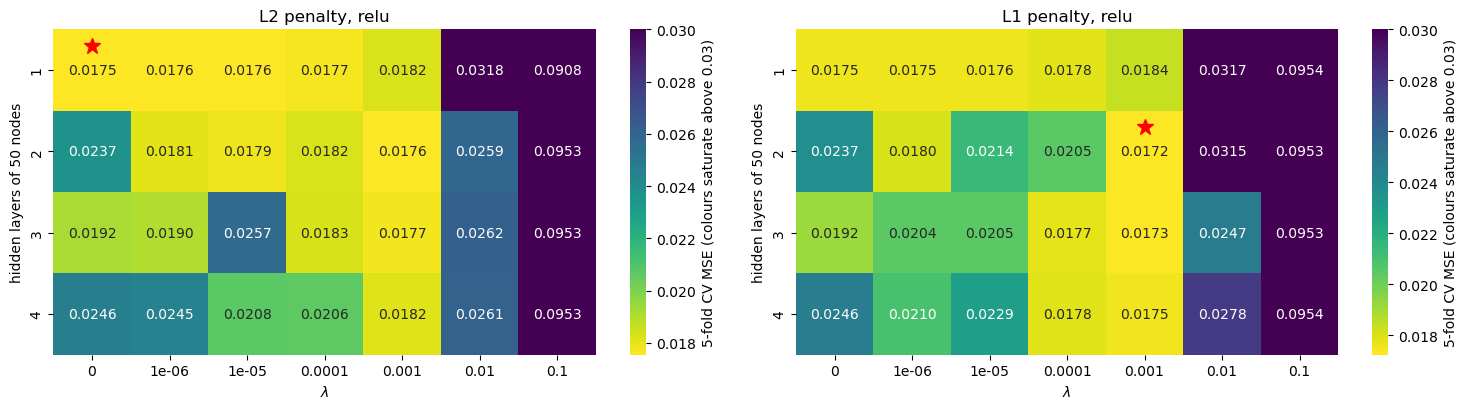

L2: CV MSE (rows: 1 to 4 hidden layers, columns: lambda = [0.0, 1e-06, 1e-05, 0.0001, 0.001, 0.01, 0.1])
 [[0.0175 0.0176 0.0176 0.0177 0.0182 0.0318 0.0908]
 [0.0237 0.0181 0.0179 0.0182 0.0176 0.0259 0.0953]
 [0.0192 0.019  0.0257 0.0183 0.0177 0.0262 0.0953]
 [0.0246 0.0245 0.0208 0.0206 0.0182 0.0261 0.0953]]
L1: CV MSE (rows: 1 to 4 hidden layers, columns: lambda = [0.0, 1e-06, 1e-05, 0.0001, 0.001, 0.01, 0.1])
 [[0.0175 0.0175 0.0176 0.0178 0.0184 0.0317 0.0954]
 [0.0237 0.018  0.0214 0.0205 0.0172 0.0315 0.0953]
 [0.0192 0.0204 0.0205 0.0177 0.0173 0.0247 0.0953]
 [0.0246 0.021  0.0229 0.0178 0.0175 0.0278 0.0954]]
gain from the L2 penalty per depth: [0.     0.0061 0.0014 0.0065]; d.2 uses 4 hidden layer(s) of 50 nodes


In [27]:
# Your code for part d) here
best_act = {a: (np.nanmin(cv_dw[a]), se_dw[a].flat[np.nanargmin(cv_dw[a])]) for a in acts}  # best CV MSE and s.e.
a_min = min(best_act, key=lambda a: best_act[a][0])       # activation with the lowest CV MSE in c.2
tied = [a for a in acts if best_act[a][0] <= best_act[a_min][0] + best_act[a_min][1]]  # within one s.e. of it
ACT_D = "relu" if "relu" in tied else a_min               # ReLU, the default of Section 8.6.4, if the data allow it
G_D = GAMMA[ACT_D]                                        # its learning rate (c.1)
print("best CV MSE per activation (c.2):", {a: f"{m:.4f} +- {e:.4f}" for a, (m, e) in best_act.items()})
print(f"within one standard error of the lowest: {tied}; activation used in part d): {ACT_D}")
lambdas_d = [0.0, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1]     # penalty grid, including no penalty
depths_d, width_d = [1, 2, 3, 4], 50                      # hidden layers of 50 nodes
pen_names = {"l2": "L2", "l1": "L1"}                      # names for the printouts
cv_dl, se_dl, tr_dl = {}, {}, {}                          # results per penalty: arrays (depth, lambda)
t0 = time.perf_counter()                                  # start the clock
for pen in ["l2", "l1"]:
    # CV per cell
    res = np.array([[cv_network([width_d] * d, ACT_D, lam, pen, **{**TRAIN, "gamma": G_D}) for lam in lambdas_d]
                    for d in depths_d])                   # shape (depths, lambdas, 3)
    cv_dl[pen], se_dl[pen], tr_dl[pen] = res[..., 0], res[..., 1], res[..., 2]  # three arrays (depth, lambda)
print(f"activation {ACT_D}, gamma = {G_D:.1e}; grid done in {time.perf_counter() - t0:.0f} s")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
for ax, pen in zip(axes, ["l2", "l1"]):
    # colours saturate above 0.03, so that the differences between the good cells stay visible (the numbers are exact)
    sns.heatmap(cv_dl[pen], annot=True, fmt=".4f", cmap="viridis_r", ax=ax, xticklabels=[f"{l:g}" for l in lambdas_d],
                yticklabels=depths_d, vmax=0.03, cbar_kws={"label": "5-fold CV MSE (colours saturate above 0.03)"})
    i, j = np.unravel_index(np.nanargmin(cv_dl[pen]), cv_dl[pen].shape)  # cell with the lowest CV MSE
    ax.plot(j + 0.5, i + 0.2, "r*", ms=12)
    ax.set_xlabel(r"$\lambda$"); ax.set_ylabel(f"hidden layers of {width_d} nodes")
    ax.set_title(f"{pen_names[pen]} penalty, {ACT_D}")
    print(f"{pen_names[pen]}: lowest CV MSE {cv_dl[pen][i, j]:.4f} +- {se_dl[pen][i, j]:.4f} at {depths_d[i]} hidden "
          f"layer(s), lambda = {lambdas_d[j]:g}; without penalty at that depth {cv_dl[pen][i, 0]:.4f}")
    for k, d in enumerate(depths_d):
        print(f"     {d} hidden layer(s): CV MSE without penalty {cv_dl[pen][k, 0]:.4f} (training {tr_dl[pen][k, 0]:.4f}),"
              f" best over lambda {np.nanmin(cv_dl[pen][k]):.4f} at lambda = {lambdas_d[np.nanargmin(cv_dl[pen][k])]:g}")
plt.tight_layout()
plt.show()
for pen in ["l2", "l1"]:
    print(f"{pen_names[pen]}: CV MSE (rows: 1 to 4 hidden layers, columns: lambda = {lambdas_d})\n", np.round(cv_dl[pen], 4))
gain = cv_dl["l2"][:, 0] - np.nanmin(cv_dl["l2"], axis=1)  # CV MSE without penalty minus the best with L2, per depth
DEPTH_D2 = depths_d[int(np.argmax(gain))]                 # depth where the penalty matters most
print(f"gain from the L2 penalty per depth: {np.round(gain, 4)}; d.2 uses {DEPTH_D2} hidden layer(s) of {width_d} nodes")

#### d.2 The penalty against the learning rate
**Source:** `cv_grid` of `week44tuesday.ipynb`, Case 2, Step 3 (`GridSearchCV` over the learning rate and the penalty,
shown as a heat map in `fig_cv`); the project text asks for the optimal $\lambda$ and $\gamma$. **Modifications:** our own
CV loop instead of `GridSearchCV`; the depth chosen in d.1, the same for both penalties, $\gamma$ from $0.1$ to $10$ times
the learning rate of c.1 (the learning rates of `cv_grid`), the same $\lambda$ grid as d.1 (the penalties of `cv_grid`,
$0$ and $10^{-5}$ to $10^{-2}$, extended by one decade at each end). As in d.1 the colours saturate at 0.03. The cell with the lowest CV MSE gives the selected network of each
penalty (the selection rule of part b; d.5 says what the one standard error rule would pick). (The grid takes 88 s in our run.)
> **LLM note:** Written with Claude (Level 4), adapted from `week44tuesday.ipynb`.

grid done in 111 s
L2: selected [50, 50, 50, 50] relu, gamma = 1.0e-03, lambda = 0.001: CV MSE 0.0173 +- 0.0038 (training 0.0130); no penalty at the same gamma: 0.0188
     CV MSE (rows: gamma = [0.001 0.003 0.01  0.03  0.1  ], columns: lambda = [0.0, 1e-06, 1e-05, 0.0001, 0.001, 0.01, 0.1])
 [[0.0188 0.0213 0.019  0.0183 0.0173 0.0193 0.0953]
 [0.0212 0.0219 0.0201 0.0186 0.0174 0.0231 0.0953]
 [0.0246 0.0245 0.0208 0.0206 0.0182 0.0261 0.0953]
 [0.0273 0.0214 0.0204 0.0188 0.0176 0.0266 0.0953]
 [0.036  0.0198 0.0226 0.0206 0.0206 0.0283 0.0953]]
L1: selected [50, 50, 50, 50] relu, gamma = 1.0e-03, lambda = 0.001: CV MSE 0.0175 +- 0.0040 (training 0.0138); no penalty at the same gamma: 0.0188
     CV MSE (rows: gamma = [0.001 0.003 0.01  0.03  0.1  ], columns: lambda = [0.0, 1e-06, 1e-05, 0.0001, 0.001, 0.01, 0.1])
 [[0.0188 0.0206 0.0187 0.0179 0.0175 0.0255 0.0953]
 [0.0212 0.025  0.0185 0.0181 0.0179 0.0245 0.0953]
 [0.0246 0.021  0.0229 0.0178 0.0175 0.0278 0.0954]
 [0.0273 0.021

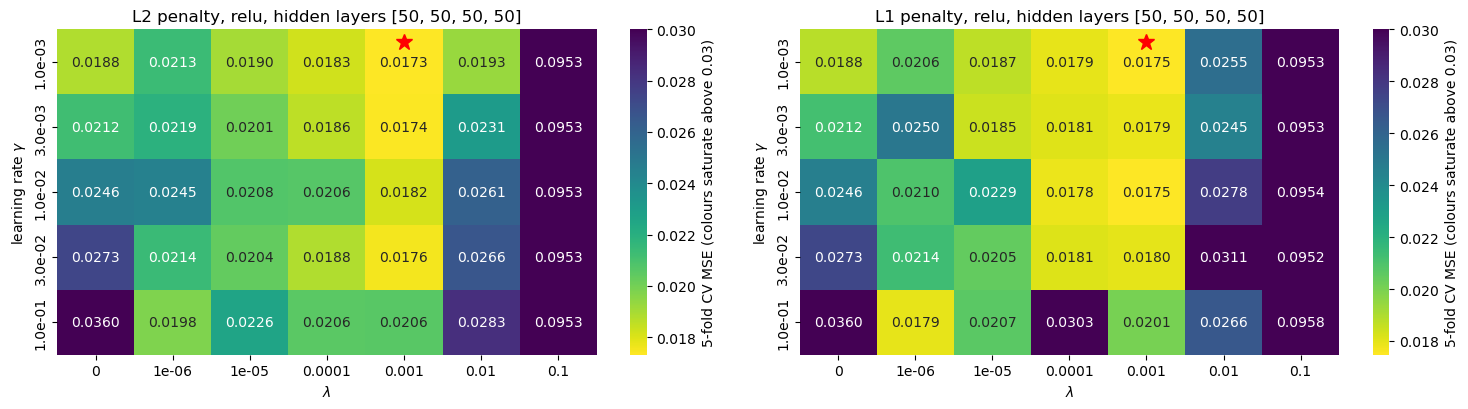

In [28]:
gammas_d = G_D * np.array([0.1, 0.3, 1.0, 3.0, 10.0])     # learning rates around the one of c.1
cv_gl, se_gl, tr_gl, BEST_D = {}, {}, {}, {}              # results and selected network per penalty
t0 = time.perf_counter()                                  # start the clock
for pen in ["l2", "l1"]:
    hidden = [width_d] * DEPTH_D2                         # the depth chosen in d.1
    res = np.array([[cv_network(hidden, ACT_D, lam, pen, **{**TRAIN, "gamma": g}) for lam in lambdas_d]  # CV per cell
                    for g in gammas_d])                   # shape (gammas, lambdas, 3)
    cv_gl[pen], se_gl[pen], tr_gl[pen] = res[..., 0], res[..., 1], res[..., 2]  # three arrays (gamma, lambda)
    i, j = np.unravel_index(np.nanargmin(cv_gl[pen]), cv_gl[pen].shape)  # cell with the lowest CV MSE
    BEST_D[pen] = dict(hidden=hidden, gamma=gammas_d[i], lmbda=lambdas_d[j], cv=cv_gl[pen][i, j], cv_se=se_gl[pen][i, j],  # the selection
                       cv_train=tr_gl[pen][i, j])
print(f"grid done in {time.perf_counter() - t0:.0f} s")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
for ax, pen in zip(axes, ["l2", "l1"]):
    # colours saturate above 0.03, so that the differences between the good cells stay visible (the numbers are exact)
    sns.heatmap(cv_gl[pen], annot=True, fmt=".4f", cmap="viridis_r", ax=ax, xticklabels=[f"{l:g}" for l in lambdas_d],
                yticklabels=[f"{g:.1e}" for g in gammas_d], vmax=0.03,
                cbar_kws={"label": "5-fold CV MSE (colours saturate above 0.03)"})
    i, j = np.unravel_index(np.nanargmin(cv_gl[pen]), cv_gl[pen].shape)  # cell with the lowest CV MSE
    ax.plot(j + 0.5, i + 0.2, "r*", ms=12)
    ax.set_xlabel(r"$\lambda$"); ax.set_ylabel(r"learning rate $\gamma$")
    ax.set_title(f"{pen_names[pen]} penalty, {ACT_D}, hidden layers {BEST_D[pen]['hidden']}")
    b = BEST_D[pen]                                       # the selected network of this penalty
    print(f"{pen_names[pen]}: selected {b['hidden']} {ACT_D}, gamma = {b['gamma']:.1e}, lambda = {b['lmbda']:g}: "
          f"CV MSE {b['cv']:.4f} +- {b['cv_se']:.4f} (training {b['cv_train']:.4f}); "
          f"no penalty at the same gamma: {cv_gl[pen][i, 0]:.4f}")
    print(f"     CV MSE (rows: gamma = {np.round(gammas_d, 5)}, columns: lambda = {lambdas_d})\n", np.round(cv_gl[pen], 4))
plt.tight_layout()
plt.show()

#### d.1 and d.2 Figure for the report
**Source:** `cv_dl` of d.1 and `cv_gl` of d.2. **Modifications:** the four maps in one figure with one colour scale, readable names, the selected cells framed in red. No new results.
> **LLM note:** Written with Claude (Level 4). New plotting code.

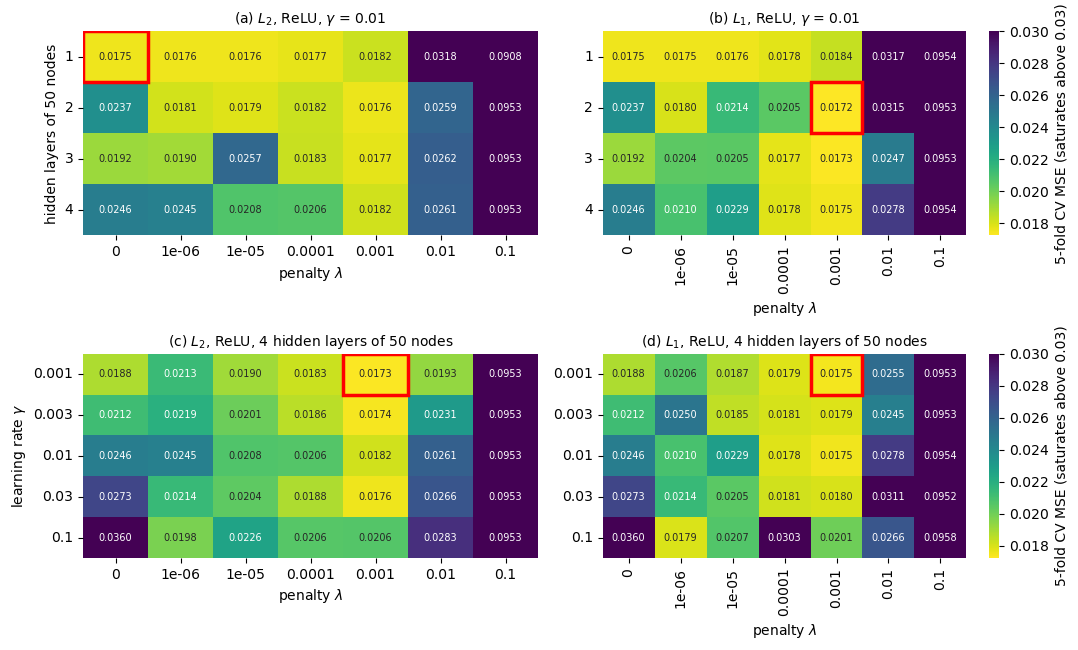

l2: selected gamma = 0.001, lambda = 0.001, CV MSE 0.0173   (must equal d.2)
l1: selected gamma = 0.001, lambda = 0.001, CV MSE 0.0175   (must equal d.2)


In [29]:
# ---- Figure for the report: d.1 and d.2 redrawn (cv_dl of d.1 and cv_gl of d.2; nothing is recomputed) ----
PEN = {"l2": "$L_2$", "l1": "$L_1$"}                      # penalty names for the titles
vmin = min(min(np.nanmin(cv_dl[p]), np.nanmin(cv_gl[p])) for p in PEN)  # one colour scale for the four maps
fig, axes = plt.subplots(2, 2, figsize=(11, 6.6))
for col, pen in enumerate(["l2", "l1"]):
    rows = [(cv_dl[pen], depths_d, f"hidden layers of {width_d} nodes", rf"ReLU, $\gamma$ = {G_D:g}"),
            (cv_gl[pen], [f"{g:g}" for g in gammas_d], r"learning rate $\gamma$",
             f"ReLU, {DEPTH_D2} hidden layers of {width_d} nodes")]
    for row, (vals, ylabels, ylabel, setup) in enumerate(rows):
        ax = axes[row, col]
        sns.heatmap(vals, annot=True, fmt=".4f", cmap="viridis_r", vmin=vmin, vmax=0.03, ax=ax,
                    xticklabels=[f"{l:g}" for l in lambdas_d], yticklabels=ylabels, annot_kws={"size": 7},
                    cbar=(col == 1), cbar_kws={"label": "5-fold CV MSE (saturates above 0.03)"})
        i, j = np.unravel_index(np.nanargmin(vals), vals.shape)  # lowest CV MSE of this map
        ax.add_patch(plt.Rectangle((j, i), 1, 1, fill=False, edgecolor="red", lw=2.5, zorder=5))  # frame it
        ax.set_xlabel(r"penalty $\lambda$"); ax.set_ylabel(ylabel if col == 0 else "")
        ax.tick_params(axis="y", rotation=0)
        ax.set_title(f"({'abcd'[2 * row + col]}) {PEN[pen]}, {setup}", fontsize=10)
plt.tight_layout()
save_figure(fig, "d12_penalties")
plt.show()
for pen in ["l2", "l1"]:
    b = BEST_D[pen]
    print(f"{pen}: selected gamma = {b['gamma']:g}, lambda = {b['lmbda']:g}, CV MSE {b['cv']:.4f}   (must equal d.2)")

#### d.3 The selected networks against Ridge and Lasso from Project 1
**Source:** the Ridge and Lasso pipelines and helpers of Project 1 (b.5 above). Project 1's best Ridge on this data set and
split was degree 8 with $\lambda_{\rm b)}=10^{-3}$ (cell b.4 there, selected on the test set); its best Lasso was degree 8 with
$\lambda=10^{-4}$ (cell i.3 there, selected by 10 fold CV on all 100 points). **Modifications:** (1) both Project 1 models are
refitted on the 80 training points and evaluated on the 20 test points; (2) for a fair comparison Ridge and Lasso are also
selected by 5 fold CV on the training points with the same folds as the networks, on the grids of Project 1 (Ridge: degrees 1
to 15, 23 values of $\lambda$ from $10^{-8}$ to $10^3$, cell d.3 there; Lasso: degrees 1 to 15, 13 values from $10^{-6}$ to 1,
only cells where coordinate descent converged in every fold, cell i.1 there); (3) the selected $L_2$ and $L_1$ networks of
d.2 are refitted on all 80 training points and evaluated once on the test set. (The Lasso grid takes 55 s in our run.)
> **LLM note:** Written with Claude (Level 4), reusing the Project 1 code.

Lasso grid: 39 of 195 cells did not converge in every fold (60 s)
5-fold CV on the training points selects the Lasso of Project 1 (degree 8, lambda = 1e-4)

model                                                          CV MSE +- s.e.     test MSE +- s.e.   MSE to f
OLS, degree 8 (best of Project 1)                              0.0266 +- 0.0071    0.0187 +- 0.0048   0.00572
Ridge, degree 8, lambda_b = 1e-3 (best of Project 1)           0.0273 +- 0.0059    0.0178 +- 0.0055   0.00480
Lasso, degree 8, lambda = 1e-4 (best of Project 1)             0.0264 +- 0.0062    0.0178 +- 0.0054   0.00502
Ridge, degree 11, lambda_b = 3e-05 (CV on the training data)   0.0217 +- 0.0039    0.0219 +- 0.0050   0.00710
FFNN [50, 50, 50, 50], relu, L2, lambda = 0.001 (part d)       0.0173 +- 0.0038    0.0145 +- 0.0049   0.00168
FFNN [50, 50, 50, 50], relu, L1, lambda = 0.001 (part d)       0.0175 +- 0.0040    0.0158 +- 0.0055   0.00151


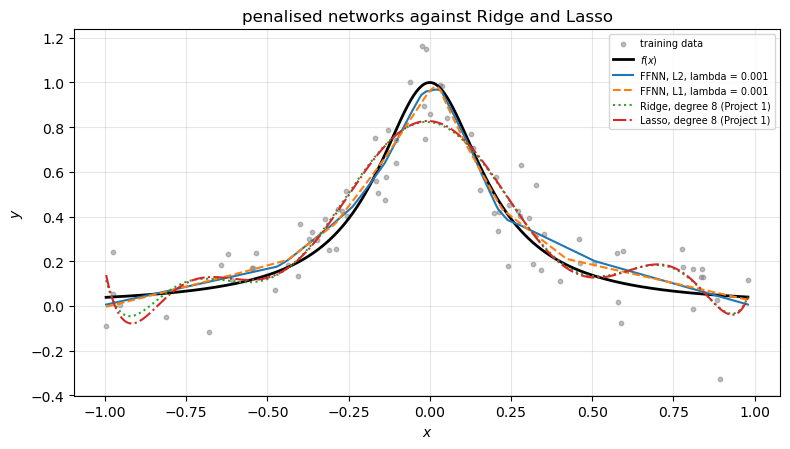

In [30]:
# Project 1's best Ridge (b.4 there) and best Lasso (i.3 there), refitted on the 80 training points
for name, pipe in [("Ridge, degree 8, lambda_b = 1e-3 (best of Project 1)", make_ridge_pipeline(8, 1e-3)),
                   ("Lasso, degree 8, lambda = 1e-4 (best of Project 1)", make_lasso_pipeline(8, 1e-4))]:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        m_cv, s_cv = cv_mse_se(pipe, x_train, y_train, K_FOLDS)  # CV MSE on our folds
        pipe.fit(x_train[:, None], y_train)               # refit on the 80 training points
    t_m, t_se = test_mse_se(y_test, pipe.predict(x_test[:, None]))  # test MSE, once
    # row
    REG[name] = dict(cv=m_cv, cv_se=s_cv, test=t_m, test_se=t_se, f_mse=mse_to_f(pipe.predict(x_grid[:, None])), n_par=9)

# Ridge and Lasso selected by 5 fold CV on the training points (grids of Project 1, d.3 and i.1)
lambdas_ridge = np.logspace(-8, 3, 23)                    # two points per decade (Project 1, d.3)
cv_ridge_tr = np.array([[cv_mse(make_ridge_pipeline(d, lam), x_train, y_train, K_FOLDS) for d in degrees]  # CV per cell
                        for lam in lambdas_ridge])        # rows: lambda, columns: degree
i_r, j_r = np.unravel_index(np.argmin(cv_ridge_tr), cv_ridge_tr.shape)  # best Ridge cell
lambdas_lasso = np.logspace(-6, 0, 13)                    # two points per decade (Project 1, i.1)
cv_lasso_tr = np.full((len(lambdas_lasso), len(degrees)), np.nan)  # NaN = not converged
t0 = time.perf_counter()                                  # start the clock
for i, lam in enumerate(lambdas_lasso):
    for j, d in enumerate(degrees):
        m_l, ok = cv_mse_converged(make_lasso_pipeline(d, lam), x_train, y_train, K_FOLDS)  # CV MSE and convergence flag
        cv_lasso_tr[i, j] = m_l if ok else np.nan         # unconverged cells are not used for the selection
i_l, j_l = np.unravel_index(np.nanargmin(cv_lasso_tr), cv_lasso_tr.shape)  # best converged Lasso cell
print(f"Lasso grid: {np.sum(np.isnan(cv_lasso_tr))} of {cv_lasso_tr.size} cells did not converge in every fold "
      f"({time.perf_counter() - t0:.0f} s)")
cv_selected = [(f"Ridge, degree {degrees[j_r]}, lambda_b = {lambdas_ridge[i_r]:.0e} (CV on the training data)",  # rows to add
                make_ridge_pipeline(degrees[j_r], lambdas_ridge[i_r]), degrees[j_r])]
if degrees[j_l] == 8 and np.isclose(lambdas_lasso[i_l], 1e-4):  # the same model as Project 1's best Lasso: no second row
    print("5-fold CV on the training points selects the Lasso of Project 1 (degree 8, lambda = 1e-4)")
else:
    cv_selected.append((f"Lasso, degree {degrees[j_l]}, lambda = {lambdas_lasso[i_l]:.0e} (CV on the training data)",  # row
                        make_lasso_pipeline(degrees[j_l], lambdas_lasso[i_l]), degrees[j_l]))
for name, pipe, deg in cv_selected:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        m_cv, s_cv = cv_mse_se(pipe, x_train, y_train, K_FOLDS)  # CV MSE on our folds
        pipe.fit(x_train[:, None], y_train)               # refit on the 80 training points
    t_m, t_se = test_mse_se(y_test, pipe.predict(x_test[:, None]))  # test MSE, once
    REG[name] = dict(cv=m_cv, cv_se=s_cv, test=t_m, test_se=t_se, f_mse=mse_to_f(pipe.predict(x_grid[:, None])),  # row
                     n_par=int(deg) + 1)                  # degree slopes + 1 intercept

# the selected L2 and L1 networks of d.2, refitted on all 80 training points; the test set once
nets_d, fits_d = {}, {}                                   # selected networks and their curves
for pen in ["l2", "l1"]:
    b = BEST_D[pen]                                       # the selected network of this penalty
    net = FFNN([1, *b["hidden"], 1], [ACT_D] * len(b["hidden"]) + ["identity"], "mse", b["lmbda"], pen)  # with penalty
    train_network(net, X_train_s, Y_train_c, **{**TRAIN, "gamma": b["gamma"]})  # refit on the 80 training points
    t_m, t_se = test_mse_se(y_test, net.predict(X_test_s)[:, 0] + y_mean)  # the test set, once
    nets_d[pen], fits_d[pen] = net, net.predict(X_grid_s)[:, 0] + y_mean  # keep the network and its curve
    REG[f"FFNN {b['hidden']}, {ACT_D}, {pen_names[pen]}, lambda = {b['lmbda']:g} (part d)"] = dict(  # row
        cv=b["cv"], cv_se=b["cv_se"], cv_train=b["cv_train"], test=t_m, test_se=t_se, f_mse=mse_to_f(fits_d[pen]),
        n_par=net.theta.size, gamma=b["gamma"])

print("\nmodel                                                          CV MSE +- s.e.     test MSE +- s.e.   MSE to f")
for name, r in REG.items():
    if any(s in name for s in ["Ridge", "Lasso", "part d", "best of Project 1", "CV on the training data"]):
        print(f"{name:62s} {r['cv']:.4f} +- {r['cv_se']:.4f}    {r['test']:.4f} +- {r['test_se']:.4f}   {r['f_mse']:.5f}")

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.scatter(x_train, y_train, s=10, color="gray", alpha=0.5, label="training data")
ax.plot(x_grid, runge(x_grid), "k-", lw=2, label="$f(x)$")
for pen, style in [("l2", "-"), ("l1", "--")]:
    ax.plot(x_grid, fits_d[pen], style, lw=1.5, label=f"FFNN, {pen_names[pen]}, lambda = {BEST_D[pen]['lmbda']:g}")
ax.plot(x_grid, make_ridge_pipeline(8, 1e-3).fit(x_train[:, None], y_train).predict(x_grid[:, None]), ":", lw=1.5,
        label="Ridge, degree 8 (Project 1)")
with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)
    ax.plot(x_grid, make_lasso_pipeline(8, 1e-4).fit(x_train[:, None], y_train).predict(x_grid[:, None]), "-.", lw=1.5,
            label="Lasso, degree 8 (Project 1)")
ax.set_xlabel("$x$"); ax.set_ylabel("$y$"); ax.legend(fontsize=7); ax.grid(alpha=0.3)
ax.set_title("penalised networks against Ridge and Lasso")
plt.tight_layout()
plt.show()

#### d.3 Figure for the report
**Source:** `fits_d` of d.3; Ridge and Lasso of degree 8 refitted as in d.3. **Modifications:** $L_2$ with Ridge in purple, $L_1$ with Lasso in orange, a panel with the error against the true function. No new results.
> **LLM note:** Written with Claude (Level 4). New plotting code.

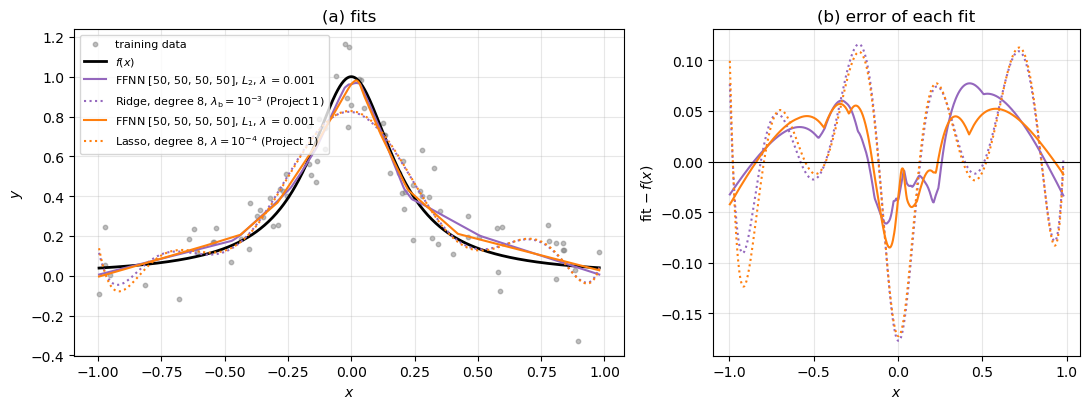

In [31]:
# ---- Figure for the report: d.3 redrawn (fits_d of d.3; Ridge and Lasso of degree 8 refitted as in d.3) ----
ridge8 = make_ridge_pipeline(8, 1e-3).fit(x_train[:, None], y_train).predict(x_grid[:, None])  # Ridge of Project 1
with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)   # as in Project 1
    lasso8 = make_lasso_pipeline(8, 1e-4).fit(x_train[:, None], y_train).predict(x_grid[:, None])  # Lasso of Project 1
curves = [(fits_d["l2"], rf"FFNN {BEST_D['l2']['hidden']}, $L_2$, $\lambda$ = {BEST_D['l2']['lmbda']:g}", "C4", "-"),
          (ridge8, r"Ridge, degree 8, $\lambda_{\rm b}=10^{-3}$ (Project 1)", "C4", ":"),
          (fits_d["l1"], rf"FFNN {BEST_D['l1']['hidden']}, $L_1$, $\lambda$ = {BEST_D['l1']['lmbda']:g}", "C1", "-"),
          (lasso8, r"Lasso, degree 8, $\lambda=10^{-4}$ (Project 1)", "C1", ":")]  # L2 with Ridge, L1 with Lasso
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [3, 2]})
axes[0].scatter(x_train, y_train, s=10, color="gray", alpha=0.5, label="training data")
axes[0].plot(x_grid, runge(x_grid), "k-", lw=2, label="$f(x)$")
for y_fit, lab, color, style in curves:
    axes[0].plot(x_grid, y_fit, style, color=color, lw=1.5, label=lab)           # the fit
    axes[1].plot(x_grid, y_fit - runge(x_grid), style, color=color, lw=1.5)      # its error against the true f
axes[1].axhline(0, color="k", lw=0.8)
axes[0].set_xlabel("$x$"); axes[0].set_ylabel("$y$"); axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)
axes[0].set_title("(a) fits")
axes[1].set_xlabel("$x$"); axes[1].set_ylabel(r"fit $-\,f(x)$"); axes[1].grid(alpha=0.3)
axes[1].set_title("(b) error of each fit")
plt.tight_layout()
save_figure(fig, "d3_penalised_vs_ridge_lasso")
plt.show()

#### d.4 What the two penalties do to the weights
**Source:** panel (c) of `fig_runge` in `week41monday.ipynb`, Part 4 (sorted absolute hidden weights for no penalty, $L_2$
and $L_1$; a ReLU node whose input weight is zero computes a constant), and the exact zeros of the Lasso in
`Project1.ipynb`, g.4. **Modifications:** the selected networks of d.2 and the same architecture without penalty, all
weights of the network, sorted by size; the count of weights below $10^{-3}$, $10^{-6}$ and $10^{-8}$ in size and the
smallest weight. The curves are drawn for $|w|+10^{-16}$ on an axis down to $10^{-17}$, so that the smallest weights stay
in the figure. With
a subgradient method the $L_1$ penalty cannot produce exact zeros (Project 1, part g), only very small weights.
> **LLM note:** Written with Claude (Level 4), adapted from `week41monday.ipynb`.

[50, 50, 50, 50], no penalty: sum of squared weights  439.853, sum of |w| 1316.924, weights below 1e-3 / 1e-6 / 1e-8: 28 / 0 / 0 of 7600, smallest 3.6e-05
[50, 50, 50, 50], L2        : sum of squared weights  110.639, sum of |w|  366.106, weights below 1e-3 / 1e-6 / 1e-8: 2624 / 1529 / 1275 of 7600, smallest 4.0e-27
[50, 50, 50, 50], L1        : sum of squared weights  102.308, sum of |w|  183.618, weights below 1e-3 / 1e-6 / 1e-8: 6441 / 72 / 0 of 7600, smallest 2.5e-08


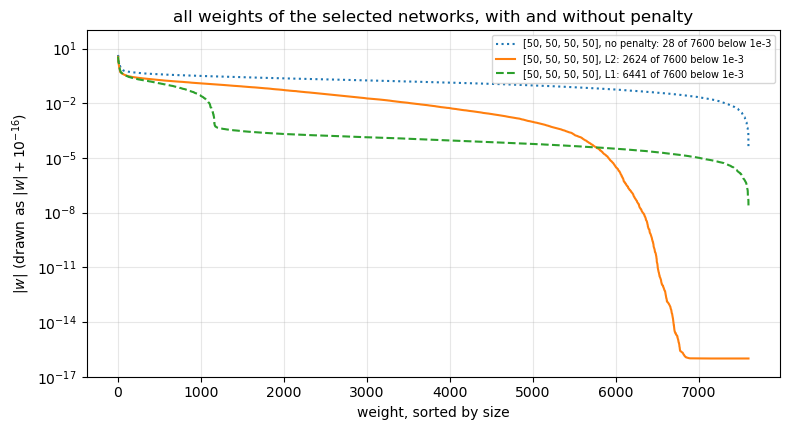

In [32]:
fig, ax = plt.subplots(figsize=(8, 4.4))
shown = set()                                             # unpenalised networks already drawn, by (hidden, gamma)
for pen, style in [("l2", "-"), ("l1", "--")]:
    b = BEST_D[pen]                                       # the selected network of this penalty
    curves = [(nets_d[pen], f"{b['hidden']}, {pen_names[pen]}", style)]  # the penalised network
    if (str(b["hidden"]), b["gamma"]) not in shown:       # the same network without penalty, drawn only once
        net0 = FFNN([1, *b["hidden"], 1], [ACT_D] * len(b["hidden"]) + ["identity"])  # same network, no penalty
        train_network(net0, X_train_s, Y_train_c, **{**TRAIN, "gamma": b["gamma"]})  # trained without penalty
        curves.insert(0, (net0, f"{b['hidden']}, no penalty", ":"))
        shown.add((str(b["hidden"]), b["gamma"]))
    for net, name, st in curves:
        w = np.sort(np.abs(np.concatenate([W.ravel() for W, _ in net.layers])))[::-1]  # all weights, largest first
        # drawn as |w| + 1e-16: weights below 1e-16 sit at the bottom of the axis instead of leaving the figure
        ax.semilogy(np.arange(1, w.size + 1), w + 1e-16, st, lw=1.5, label=f"{name}: {np.sum(w < 1e-3)} of {w.size} below 1e-3")
        print(f"{name:28s}: sum of squared weights {np.sum(w**2):8.3f}, sum of |w| {np.sum(w):8.3f}, weights below "
              f"1e-3 / 1e-6 / 1e-8: {np.sum(w < 1e-3)} / {np.sum(w < 1e-6)} / {np.sum(w < 1e-8)} of {w.size}, "
              f"smallest {w[-1]:.1e}")
ax.set_xlabel("weight, sorted by size"); ax.set_ylabel("$|w|$ (drawn as $|w|+10^{-16}$)"); ax.set_ylim(1e-17, 1e2)
ax.legend(fontsize=7); ax.grid(alpha=0.3)
ax.set_title("all weights of the selected networks, with and without penalty")
plt.tight_layout()
plt.show()



#### d.4 Table for the report
**Source:** the weights of the networks of d.4 (`nets_d` with the two penalties, `net0` without penalty). Prints the
numbers of d.4 as a LaTeX table. No new results.
> **LLM note:** Written with Claude (Level 4).

In [33]:
# Table for the report (LaTeX): the numbers of d.4 for the three networks
weight_sets = [("no penalty", net0), (r"$L_2$, $\lambda=10^{-3}$", nets_d["l2"]),
               (r"$L_1$, $\lambda=10^{-3}$", nets_d["l1"])]  # the three networks of d.4, [50, 50, 50, 50] ReLU
print(r"\begin{tabular}{lccccc}")
print(r"network & $\sum w^2$ & $\sum|w|$ & $|w|<10^{-3}$ & $|w|<10^{-6}$ & $|w|<10^{-8}$ \\")
for name, net in weight_sets:
    w = np.abs(np.concatenate([W.ravel() for W, _ in net.layers]))  # all 7600 weights
    print(f"{name} & {np.sum(w**2):.3f} & {np.sum(w):.3f} & {np.sum(w < 1e-3)} & {np.sum(w < 1e-6)} & "
          f"{np.sum(w < 1e-8)} \\\\")
print(r"\end{tabular}")
print("(these numbers must equal those printed in d.4)")

\begin{tabular}{lccccc}
network & $\sum w^2$ & $\sum|w|$ & $|w|<10^{-3}$ & $|w|<10^{-6}$ & $|w|<10^{-8}$ \\
no penalty & 439.853 & 1316.924 & 28 & 0 & 0 \\
$L_2$, $\lambda=10^{-3}$ & 110.639 & 366.106 & 2624 & 1529 & 1275 \\
$L_1$, $\lambda=10^{-3}$ & 102.308 & 183.618 & 6441 & 72 & 0 \\
\end{tabular}
(these numbers must equal those printed in d.4)


#### d.4 Figure for the report (appendix)
**Source:** the weights of the networks of d.4 (`nets_d`, `net0`). **Modifications:** one histogram of $\log_{10}|w|$ per network instead of the sorted weights, with logarithmic counts and the thresholds $10^{-3}$, $10^{-6}$ and $10^{-8}$ of d.4. No new results.
> **LLM note:** Written with Claude (Level 4). New plotting code.

no penalty              : sum of squared weights  439.853, sum of |w| 1316.924, below 1e-3 / 1e-6 / 1e-8: 28 / 0 / 0   (must equal the values printed in d.4)
$L_2$, $\lambda=10^{-3}$: sum of squared weights  110.639, sum of |w|  366.106, below 1e-3 / 1e-6 / 1e-8: 2624 / 1529 / 1275   (must equal the values printed in d.4)
$L_1$, $\lambda=10^{-3}$: sum of squared weights  102.308, sum of |w|  183.618, below 1e-3 / 1e-6 / 1e-8: 6441 / 72 / 0   (must equal the values printed in d.4)


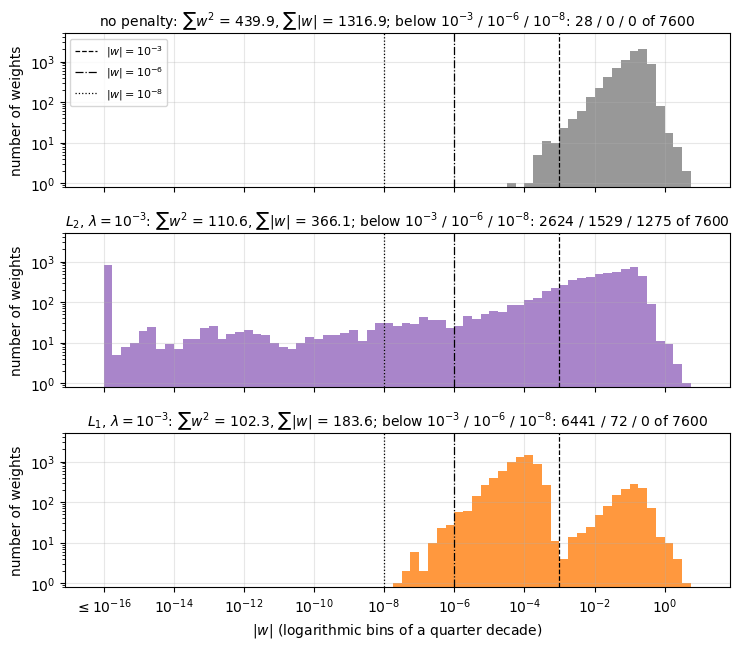

In [34]:
# ---- Figure for the report: d.4 redrawn (the weights of the networks of d.4: nets_d for the penalties and net0, the
# same network without penalty trained in d.4; nothing is retrained; the table is in the cell above) ----
LOG_FLOOR = -16                                           # weights below 1e-16 are collected in the leftmost bin
bins = np.arange(LOG_FLOOR - 0.25, 1.01, 0.25)            # bins of a quarter decade in log10 |w|
weight_sets = [("no penalty", net0, "C7"), (r"$L_2$, $\lambda=10^{-3}$", nets_d["l2"], "C4"),
               (r"$L_1$, $\lambda=10^{-3}$", nets_d["l1"], "C1")]  # the three networks of d.4, [50, 50, 50, 50] ReLU
fig, axes = plt.subplots(3, 1, figsize=(7.5, 6.6), sharex=True)
for ax, (name, net, color) in zip(axes, weight_sets):
    w = np.abs(np.concatenate([W.ravel() for W, _ in net.layers]))  # all 7600 weights (biases are not penalised)
    logw = np.log10(np.maximum(w, 10.0**LOG_FLOOR))       # log10 |w|, with |w| < 1e-16 put at -16
    ax.hist(logw, bins=bins, color=color, alpha=0.8)      # how many weights there are at each size
    for e, ls in [(-3, "--"), (-6, "-."), (-8, ":")]:     # the thresholds printed in d.4
        ax.axvline(e, color="k", ls=ls, lw=0.9, label=rf"$|w|=10^{{{e}}}$")
    counts = f"below $10^{{-3}}$ / $10^{{-6}}$ / $10^{{-8}}$: {np.sum(w < 1e-3)} / {np.sum(w < 1e-6)} / {np.sum(w < 1e-8)}"
    ax.set_title(rf"{name}: $\sum w^2$ = {np.sum(w**2):.1f}, $\sum|w|$ = {np.sum(w):.1f}; {counts} of {w.size}",
                 fontsize=10)
    ax.set_yscale("log"); ax.set_ylim(0.8, 5000)            # logarithmic counts: the thin tails stay visible
    ax.set_ylabel("number of weights"); ax.grid(alpha=0.3)
    print(f"{name:24s}: sum of squared weights {np.sum(w**2):8.3f}, sum of |w| {np.sum(w):8.3f}, below 1e-3 / 1e-6 / "
          f"1e-8: {np.sum(w < 1e-3)} / {np.sum(w < 1e-6)} / {np.sum(w < 1e-8)}   (must equal the values printed in d.4)")
axes[0].legend(fontsize=8, loc="upper left")              # the three thresholds
ticks = np.arange(LOG_FLOOR, 1, 2)                        # every second decade
axes[-1].set_xticks(ticks)
axes[-1].set_xticklabels([r"$\leq10^{-16}$"] + [rf"$10^{{{t}}}$" for t in ticks[1:]])
axes[-1].set_xlabel("$|w|$ (logarithmic bins of a quarter decade)")
plt.tight_layout()
save_figure(fig, "d4_weights")
plt.show()

#### d.5 Observations (integrated version, notes for the report)
> **LLM note:** Drafted with Claude from the outputs above and from our question-and-answer session with Claude, in
> which we went through part d) step by step (text Level 3 if used as it is). Rewrite in your own words for the report,
> and check every number against your own run. **[own]** marks reasoning that is not taken from the course material.
> Section and equation numbers refer to the lecture notes of 25 October 2026; a.6, b.8 and c.6 are cited with the
> numbering of their integrated versions.

**What the cells show (d.1 to d.4)**

1. **The penalty against the depth (d.1; ReLU, 50 nodes per layer, $\gamma=10^{-2}$).** Without penalty the CV MSE
   depends strongly on the depth: 0.0175, 0.0237, 0.0192 and 0.0246 for 1 to 4 hidden layers, while the training MSE
   drops from 0.0136 to between 0.0109 and 0.0122; the deeper networks overfit (c.3). With $\lambda=10^{-3}$ both
   penalties remove most of this: $L_2$ gives 0.0176, 0.0177 and 0.0182 for 2 to 4 layers, $L_1$ gives 0.0172, 0.0173
   and 0.0175. With one hidden layer, which overfits the least, no penalty helps ($L_2$ is best at $\lambda=0$, $L_1$
   gives 0.0175 at $10^{-6}$): a penalty can only remove variance that is there, as Ridge at low degree in Project 1,
   part b). The penalty makes the result almost independent of the depth, which is the rule of thumb of Section 8.12:
   it is "usually better to build a network somewhat too large and regularise it than to search for exactly the right
   size".

2. **Too much and too little penalty (d.1, d.2).** $\lambda=10^{-2}$ raises the CV MSE to between 0.0247 and 0.0318 at
   every depth, and $\lambda=0.1$ to between 0.0908 and 0.0954, about the variance of $y$ (0.0938, b.5): the penalty
   outweighs the data, pulls the weights towards zero, and the network predicts the mean. This is the underfitting side
   of the bias variance trade off, as for Ridge with a large $\lambda$ in Project 1. Between $10^{-6}$ and $10^{-4}$ the
   effect is erratic ($L_2$ with 3 layers: 0.0190, 0.0257, 0.0183; $L_1$ with 2 layers: 0.0180, 0.0214, 0.0205): such
   weak penalties do not control the network, and single cells of a map from one seed are not trends (Section 8.15). The useful values lie around $\lambda=10^{-3}$: at $10^{-4}$ the deep networks gain less, and at
   $10^{-2}$ they already underfit.

3. **Learning rate and penalty together (d.2; 4 hidden layers of 50 ReLU nodes).** For both penalties the column
   $\lambda=10^{-3}$ is the best at four of the five learning rates (not at $\gamma=0.1$), and in that column the CV MSE
   changes much less with $\gamma$ ($L_2$: 0.0173, 0.0174, 0.0182, 0.0176, 0.0206 for $\gamma$ from $10^{-3}$ to $0.1$;
   $L_1$: 0.0175, 0.0179, 0.0175, 0.0180, 0.0201) than without penalty, where it rises from 0.0188 to 0.0360. So the
   penalty also makes the training less sensitive to the learning rate [own reading]. Selected: $L_2$ with
   $\gamma=10^{-3}$, $\lambda=10^{-3}$, CV MSE 0.0173 ± 0.0038 (training 0.0130), and $L_1$ with $\gamma=10^{-3}$,
   $\lambda=10^{-3}$, 0.0175 ± 0.0040 (training 0.0138). Without penalty at the same $\gamma$ the CV MSE is 0.0188; the
   penalty helps more at the learning rate of c.1 ($\gamma=10^{-2}$: from 0.0246 to 0.0182 and 0.0175, d.1). The
   selected $\gamma$ ($10^{-3}$) is smaller than in c.1 ($10^{-2}$):
   with a smaller step Adam moves the weights less in 1000 epochs, which acts like early stopping [own reading; c.6,
   item 11]. $\gamma=10^{-3}$ is the smallest learning rate of the grid, and without penalty the CV MSE is still falling
   there (0.0246, 0.0212 and 0.0188 from $\gamma=10^{-2}$ to $10^{-3}$); smaller learning rates were not tried. The one standard error rule (Section 3.14, Eq. (3.96)), which
   takes "the largest penalty whose error lies within one standard error of the best", would keep $\lambda=10^{-3}$ for
   $L_1$ but move $L_2$ to $\lambda=10^{-2}$ (CV MSE 0.0193 at $\gamma=10^{-3}$): more shrinkage, which the data cannot
   tell apart from the selected network.

4. **Against Ridge and Lasso of Project 1 (d.3).** CV MSE, test MSE and MSE to $f$: Ridge of Project 1 (degree 8,
   $\lambda_{\rm b)}=10^{-3}$) 0.0273 ± 0.0059, 0.0178 ± 0.0055, 0.00480; Lasso of Project 1 (degree 8, $\lambda=10^{-4}$)
   0.0264 ± 0.0062, 0.0178 ± 0.0054, 0.00502; network with $L_2$ 0.0173 ± 0.0038, 0.0145 ± 0.0049, 0.00168; network with
   $L_1$ 0.0175 ± 0.0040, 0.0158 ± 0.0055, 0.00151. The networks are better in CV, by more than the standard error of either model; on the test set they are
   better by less than one standard error; and they are much closer to $f$. The figure shows why: like OLS of degree 8
   (b.7, c.5), the penalised polynomials of degree 8 miss the top of the peak (about 0.83) and oscillate near the edges
   (item 13). Selected by CV on the training data, the Lasso is the one of Project 1, while Ridge moves to degree 11 with
   $\lambda_{\rm b)}=3\cdot10^{-5}$: the lowest CV MSE of the polynomial models (0.0217 ± 0.0039), closer to the networks
   (0.0173 ± 0.0038 and 0.0175 ± 0.0040), but the worst test MSE (0.0219) and the worst MSE to
   $f$ (0.00710). Among many models (here 23 values of $\lambda$ for each of 15 degrees) the lowest CV MSE is an optimistic
   estimate, the selection bias of Section 3.14. 39 of the 195 Lasso cells did not converge in every fold and were left out,
   as in Project 1.

5. **What the penalties are worth [own].** The Ridge and Lasso of Project 1 hardly change OLS of degree 8 (d.3: CV 0.0273
   and 0.0264 against 0.0266, test 0.0178 against 0.0187): at degree 8 there is little variance to remove. For the
   networks the penalties matter only where the network overfits (item 1). In neither family does the penalty give the
   best model: the unpenalised sigmoid networks of b.7 have CV MSEs of 0.0168 to 0.0175, test MSEs of 0.0116 to 0.0136
   and MSEs to $f$ of 0.00084 to 0.00106, as good as or better than the penalised ReLU networks (0.0173 to 0.0175, 0.0145
   to 0.0158 and 0.00151 to 0.00168). Here the penalty repairs an architecture that is too large, it does not improve on
   the right one. Between the two penalties there is no clear winner: $L_2$ is ahead in CV (0.0173 against 0.0175) and
   on the test set (0.0145 against 0.0158), $L_1$ in the MSE to $f$ (0.00151 against 0.00168); the CV and test
   differences are well within one standard error, and all of them come from one seed.

6. **What the penalties do to the weights (d.4).** Without penalty the 7600 weights of the [50, 50, 50, 50] network have
   $\sum w^2=439.853$ and $\sum|w|=1316.924$, and only 28 are below $10^{-3}$ (none below $10^{-6}$). $L_1$ puts a step into the
   sorted curve: 6441 weights sit below $10^{-3}$, most of them between about $10^{-5}$ and $3\cdot10^{-4}$ (figure); only 72 go below $10^{-6}$ and none
   below $10^{-8}$ (the smallest is $2.5\cdot10^{-8}$). This is the sparsity
   that Section 8.12 attributes to an $\ell_1$ penalty, "exactly as in Section 3.9", except that here the small weights
   are not exactly zero (item 10). $L_2$ shrinks most weights smoothly ($\sum w^2=110.639$, $\sum|w|=366.106$), like the
   shrinkage of Ridge (Section 3.8), but its sorted curve ends in a cliff as well: 2624 weights are below $10^{-3}$, 1529
   below $10^{-6}$ and 1275 below $10^{-8}$, down to $4.0\cdot10^{-27}$; the smallest of them are below
   $10^{-16}$ and are drawn at the bottom of the axis (figure; in the report figure they fall in the leftmost bin,
   $\le10^{-16}$). The cells do not show which weights these are. Below $10^{-6}$ the $L_2$ network
   thus has far more weights than the $L_1$ network (1529 against 72). $\sum|w|$ is smallest with $L_1$ (183.618 against
   366.106 with $L_2$), while $\sum w^2$ is about the same with the two penalties (102.308 with $L_1$, 110.639 with
   $L_2$).
   In the report these numbers are given in a table, and the weights are shown in the appendix as one histogram of
   $\log_{10}|w|$ per network (d.4, figure for the report), with logarithmic counts and the three thresholds $10^{-3}$,
   $10^{-6}$ and $10^{-8}$: without penalty the weights lie above $10^{-3}$ except 28, $L_2$ adds a long tail towards
   zero, and $L_1$ splits the weights into two groups.

7. **Caveats [own].** The values of $\lambda$ cannot be compared one to one between networks and polynomials, since they
   penalise different parameters (item 8). We tested the penalties with the ReLU only; the sigmoid networks hardly
   overfit (c.2), so we expect them to gain even less, but this is an inference, not a result (item 12). d.1 runs d.2
   at the depth where $L_2$ helps most, the depth where the unpenalised network overfits most; the gains of 2 and 4
   layers are 0.0061 and 0.0065 (d.1), far less than one standard error apart, so this choice is decided by noise. It shows what
   the penalty does, but it is not the depth with the lowest CV MSE: the best $L_1$ cell of d.1 has 2 layers (0.0172 ±
   0.0039), and with $\lambda=10^{-3}$ every depth is within one standard error of the best cell of its penalty, so the
   choice costs nothing the data can measure. The width is fixed at 50 nodes, so the architecture is searched over the
   depth only. All results come from one seed and one split of 100 points.

**The concepts behind part d) (our discussion)**

8. **The two penalties, and their conventions.** The cost is the MSE plus $\lambda\sum_l\|\boldsymbol W^l\|_2^2$ ($L_2$)
   or $\lambda\sum_l\|\boldsymbol W^l\|_1$ ($L_1$) on the weights only (Eq. (8.31); `penalty_value`), and the
   backpropagation adds $2\lambda\boldsymbol W$ or $\lambda\,\mathrm{sign}(\boldsymbol W)$ to every weight gradient
   (`penalty_grad`). $L_2$ pulls each weight in proportion to its size, so it shrinks all of them and sets none to zero:
   for an orthonormal design Ridge gives $y/(1+\lambda)$ (Eq. (3.61)), and in general it shrinks most the directions with
   small singular values (Eq. (3.46)). $L_1$ pulls every weight with the same strength, so it can push small ones to
   zero: for an orthonormal design the Lasso gives the soft thresholding $\mathrm{sign}(y)\max(|y|-\lambda/2,0)$
   (Eqs. (3.63) and (3.64)). Both trade a little bias
   for less variance (Sections 2.10 and 8.12). *Conventions:* our $L_2$ cost is Eq. (4.16), with $1/n$ on the data term
   only, while `Ridge(alpha=...)` minimises Eq. (3.43) without $1/n$, so $\alpha=\lambda_{\rm b)}=n\lambda$ ("Note the
   factor n in the closed form", Section 4.4.1); our $L_1$ cost is Eq. (3.57), and `Lasso(alpha=...)` has $1/(2n)$ on
   the data term, so $\alpha=\lambda/2$. Even with the same convention the values of $\lambda$ cannot be compared between
   a network and a polynomial, because they penalise different parameters: the Ridge of Project 1 has
   $\lambda_{\rm b)}=10^{-3}$ and the $L_2$ network $\lambda=10^{-3}$, and the two numbers do not measure the same
   thing [own].

9. **Weight decay.** "Adding $\lambda\|\Theta\|_2^2$ to Eq. (8.31) is the Ridge penalty of Section 3.8 under the name
   weight decay; it contributes $2\lambda\boldsymbol W^l$ to each weight gradient and nothing to the bias gradients"
   (Section 8.12). The name comes from plain gradient descent (Eq. (4.15)): one step gives
   $\boldsymbol W\leftarrow(1-2\gamma\lambda)\boldsymbol W-\gamma\,\partial C_{\rm data}/\partial\boldsymbol W$, so every
   step first multiplies each weight by a number just below one and then lets the data push it where they need it;
   a weight the data do not support keeps shrinking [own reading of the update]. With Adam, which our training uses,
   $2\lambda\boldsymbol W$ is part of the gradient that Adam rescales coordinate by coordinate (Eqs. (4.67) to (4.71);
   `optimiser_step`), so there is no fixed factor $(1-2\gamma\lambda)$ per step; the penalty is still a pull towards
   zero, proportional to the weight, inside the gradient. Smaller weights give a smoother function: for one hidden layer
   of ReLU nodes, $g(x)=c+\sum_iv_i\mathrm{ReLU}(w_ix+b_i)$ (Eq. (8.6)), the slope of every linear piece is a sum of
   products $v_iw_i$, so small weights mean gentle slopes that cannot follow single noisy points [own reading of
   Eq. (8.6)]. Without hidden layers the $L_2$ network is exactly Ridge: b.4 reproduces the closed form of Ridge to
   $8.0\cdot10^{-16}$ with $\lambda_{\rm b)}=n\lambda$ (b.8, item 4). In part d) weight decay lowers $\sum w^2$ from
   439.853 to 110.639 (d.4) and the CV MSE of the 4 layer network from 0.0246 to 0.0182 (d.1); too much of it gives underfitting
   (item 2).

10. **Exact zeros, and why our $L_1$ network has none.** The exact Lasso minimum has exact zeros: soft thresholding cuts
    every coefficient below the threshold to zero (Eqs. (3.63) and (3.64)), and coordinate descent applies the same
    soft thresholding to one coefficient at a time (Eqs. (3.68) and (3.69)), which converges to the global minimum
    because the cost is convex; "this is what sklearn.linear_model.Lasso runs" (Section 3.9). Our network instead takes
    subgradient steps: the derivative of $|w|$ does not exist at zero (Eq. (3.58)), and `penalty_grad` uses
    $\lambda\,\mathrm{sign}(w)$ with $\mathrm{sign}(0)=0$, a valid subgradient (Section 4.14). The step has no
    $\max(\cdot,0)$: a weight near zero receives a push of the same size, overshoots, changes sign and is pushed back, and
    it would stop at zero only by landing on it exactly, while "an iterate never lands on it exactly" (Section 4.14).
    b.4 shows this: with plain gradient descent ($\gamma=0.01$, $\lambda=10^{-2}$, 50000 epochs) the network without
    hidden layers ends $2.1\cdot10^{-4}$ away from the Scikit-Learn solution of the Lasso, while it reproduces OLS and
    Ridge to $2.8\cdot10^{-15}$ and $8.0\cdot10^{-16}$. With Adam the jumps
    shrink, since a gradient that changes sign from step to step has a small average $\hat m$ (Section 4.11), but in 1000
    epochs the weights come close to zero without reaching it: in d.4 no weight is exactly zero (item 6; Project 1,
    part g). In the report, the sparsity of our $L_1$ network means many very small weights, not exact zeros.

11. **Why the biases are not penalised.** Section 8.12 leaves the biases unpenalised "for the reason given in Section
    3.13": penalising the intercept "shrinks the fitted values towards zero rather than towards the mean of the data",
    and makes the result depend on where the origin of the target happens to be; if every $y_i$ is shifted by a
    constant, the fit should shift with it, and that fails if the intercept is penalised. The remedy is to centre $X$ and
    $y$, so that the penalty touches only the genuine slopes and the intercept is recovered afterwards without penalty
    (Eq. (3.90)). Our code does exactly this: `scale_train_test` centres $y$, the training mean (0.374, b.1) is added back
    to every prediction without penalty, and in b.4 the output bias ends at $10^{-16}$; `penalty_value` sums over the
    weights only, and `db` gets no penalty. In a ReLU network each hidden bias sets where the kink of its node lies,
    at $x=-b/w$ (Lemma 8.1), so penalising it would pull all kinks towards $x=0$ whatever the data say [own reading of
    Lemma 8.1]. The summary of the project text speaks of "the weights and biases"; we follow the lecture notes (a.6,
    item 6).

12. **Why the ReLU in part d).** The code takes the ReLU if it is within one standard error of the best activation of
    c.2, and it is (0.0173 against 0.0171 and 0.0172). Three reasons: the data do not choose between the activations
    (c.2); "ReLU is a sound default and the right thing to try first" (Section 8.6.4); and a penalty removes variance,
    so it can only help where the network overfits, which the deep ReLU networks do (c.2: four layers of 50 and 100
    ReLU nodes have CV MSEs of 0.0246 and 0.0251 against training MSEs of 0.0122 and 0.0123; c.6, items 3 and 4). d.1 confirms it: with one layer, which does not overfit,
    the penalty gains nothing, with 2 and 4 layers it gains 0.0061 and 0.0065. The sigmoid map of c.2 is flat (0.0171 to
    0.0189, all 20 cells within one standard error of the best), so there is little for a penalty to remove; that the
    sigmoid would gain less is an inference from c.2, not tested [own reading].

13. **What the figure of d.3 shows, and why a penalty cannot fix the polynomial.** *At the peak* the networks reach about
    0.96 to 0.97, while the penalised polynomials of degree 8 reach about 0.83 (figure). *Near the edges* the polynomials
    oscillate and go below zero, while the networks are made of straight pieces (Lemma 8.1) and follow $f$ more closely
    (figure). Ridge and Lasso lie almost on top of each other, as their CV MSEs (0.0273, 0.0264) and MSEs to $f$
    (0.00480, 0.00502) suggest. Why the penalty cannot fix it: the fitted values of Ridge are the components of the OLS
    fit, each multiplied by $\sigma_i^2/(\sigma_i^2+\lambda)\le1$ (Eq. (3.47)), and the Lasso sets coefficients to zero
    (Section 3.9), so a penalised polynomial of degree 8 is still a polynomial of degree at most 8, the family of OLS of
    degree 8, which misses the peak (b.8, item 9). Higher degrees have the shape, but for polynomials "the coefficients
    could not be estimated from a hundred noisy points" (Section 8.4): OLS of degree 11 has a CV MSE of 0.1835 (b.5). The
    penalty makes degree 11 usable, Ridge of degree 11 has 0.0217 (d.3), but its test MSE (0.0219) and its MSE to $f$
    (0.00710) are worse than at degree 8. The penalty removes variance; it does not give the polynomial basis the shape
    of the peak (b.8, item 12; takeaway 8).

14. **Points to state precisely in the report and the oral [own].** The penalty helps only where the network overfits
    (item 1); it repairs an architecture that is too large and does not beat the best unpenalised networks (item 5).
    With Adam, "weight decay" is the name of the $L_2$ penalty, not a fixed decay factor per step (item 9). Our $L_1$
    network has many very small weights, not exact zeros; exact zeros belong to the exact Lasso minimum (item 10). The
    biases are not penalised (item 11). The values of $\lambda$ cannot be compared between networks and polynomials
    (item 8). Against the penalised polynomials the networks are better in CV by more than one standard error, on the
    test set by less than one, and much closer to $f$ (item 4); the reason is the
    polynomial basis, not the penalty (item 13). The depth of d.2 is a tie between 2 and 4 layers, and its learning rate
    is the edge of the grid (items 3 and 7). Between $L_2$ and $L_1$ there is no winner within one standard error, and
    every number comes from one seed (item 5).

### Part e): Classification analysis using neural networks

With a well-written code it should now be easy to change the activation function for the output layer.

Here we will change the cost function for our neural network code developed in parts b)–d) in order to perform a classification analysis (Section [8.11](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#classification-with-neural-networks) of the lecture notes). The classification problem we will study is the multiclass MNIST problem of handwritten digits (LeCun, Cortes and Burges), see the description of the data set at <https://www.tensorflow.org/datasets/catalog/mnist>. We will use the softmax cross entropy function discussed in a). In this project you should use the *full* MNIST data set ($70\,000$ images of $28\times 28$ pixels), the one used in the Monday lecture of week 41; the code of that lecture reads exactly the file described below. Note that the Tuesday session of week 41 (and Section [8.14](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#examples) of the lecture notes) uses the much smaller digits data set of Scikit-Learn (`load_digits`, $1797$ images of $8\times 8$ pixels, a different data set of the same kind and not a subset of MNIST). The reduced set is convenient for developing and debugging your code, since every run takes seconds, but the results you report should be for the full MNIST set.

The data set comes with a canonical split into $60\,000$ training images and $10\,000$ test images, each a $28\times 28$ array of grey-scale pixel values between 0 and 255. It can be downloaded, without registering anywhere, as a single NumPy archive (about 11 MB) from <https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz> and loaded with


#### e.0 Getting the file `mnist.npz`
The starter cells below read `mnist.npz` from the working directory. This cell downloads it from the address given in
the project text if it is not there yet. The course repository has a copy of the same archive at
`doc/BookML/BookPrograms/chapter10_convolutional_networks/mnist.npz`, which is the file the MNIST code of
`week41monday.ipynb` (Part 4, Example 3) and `week42monday.ipynb` (Section 3) reads; copying that file into this folder
works as well. Note on run time: the starter cell with Scikit-Learn's `LogisticRegression` (`saga`, `max_iter=1000`) took
between 10 and 14 minutes in our runs; it is kept unchanged.
> **LLM note:** Written with Claude (Level 4). New code.

In [35]:
import os
import urllib.request
MNIST_URL = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz"  # the address of the project text
if not os.path.exists("mnist.npz"):                       # download only once
    urllib.request.urlretrieve(MNIST_URL, "mnist.npz")    # about 11 MB, saved in this folder
print(f"mnist.npz found, {os.path.getsize('mnist.npz') / 1e6:.1f} MB")

mnist.npz found, 11.5 MB


In [36]:
import numpy as np
with np.load("mnist.npz") as data:
    x_train, y_train = data["x_train"], data["y_train"]
    x_test, y_test = data["x_test"], data["y_test"]  # untouched until the end
print(x_train.shape, y_train.shape, x_test.shape, y_test.shape)
# (60000, 28, 28) (60000,) (10000, 28, 28) (10000,)

(60000, 28, 28) (60000,) (10000, 28, 28) (10000,)


A feed-forward network takes a vector as input, so flatten each image to a vector of $784$ features and scale the pixel values to the interval $[0,1]$ (scaling makes a real difference for gradient descent, see Section 3.13 of the lecture notes),


In [37]:
x_train = x_train.reshape(len(x_train), -1) / 255.0
x_test = x_test.reshape(len(x_test), -1) / 255.0

Use the canonical split the way it is meant to be used: all training, model selection and tuning of hyperparameters (learning rate, penalty $\lambda$, number of layers and nodes, activation functions) is done on the training data only, for example by setting aside a validation set from the training data or by cross-validation (Chapter 3 of the lecture notes). The test set is used *once*, at the very end, to report the performance of the models you have selected. If you are limited by computing time, you may train on a subset of the training images, but evaluate on the full test set.

Remember to cite the data set in your report, as you would cite any other source; the citation is given on the data set page above (Y. LeCun, C. Cortes and C. J. C. Burges, *The MNIST database of handwritten digits*, <http://yann.lecun.com/exdb/mnist/>).

Feel free to suggest other data sets. If you find the classic MNIST data set somewhat limited, try the Fashion-MNIST data set of Zalando Research at <https://github.com/zalandoresearch/fashion-mnist>. It has exactly the same format and the same $60\,000/10\,000$ split, with ten classes of clothing items instead of digits, and the download links, loading code and the reference to cite are all on that page.

To measure the performance of our classification problem we will use the so-called *accuracy* score (Section 5.12 of the lecture notes). The accuracy is as you would expect just the number of correctly guessed targets $t_i$ divided by the total number of targets, that is

$$
\text{Accuracy} = \frac{\sum_{i=1}^n I(t_i = y_i)}{n} ,
$$

where $I$ is the indicator function, $1$ if $t_i = y_i$ and $0$ otherwise. Here $t_i$ represents the target and $y_i$ the outputs of your FFNN code and $n$ is simply the number of targets $t_i$.

Discuss your results and give a critical analysis of the various parameters, including hyperparameters like the learning rates and the regularization parameter $\lambda$, various activation functions, number of hidden layers and nodes and activation functions.

Again, we strongly recommend that you compare your own neural network code for classification and pertinent results against a similar code using **Scikit-Learn** or **TensorFlow/Keras** or **PyTorch** (see the paragraph on established libraries in Section [8.14](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#examples) of the lecture notes).

You should also compare your neural network results with those from logistic regression (Sections 5.3 and 5.6 of the lecture notes). Logistic regression is the *baseline* for the classification part: it is the classifier with no hidden layers, and a network with one or more hidden layers is only worth its extra cost if you can show that it performs better than this baseline. Your neural network code implements the equivalent of logistic regression by simply setting the number of hidden layers to zero and keeping just the input and the output layers (with the softmax activation and the cross entropy cost from part a)).

In addition to the accuracy, you should compute and interpret the *confusion matrix* of your best classification model (Section 5.12 of the lecture notes, see also <https://www.researchgate.net/figure/Confusion-matrix-of-MNIST-and-F-MNIST-embeddings_fig5_349758607>). The confusion matrix shows which digits are confused with which, something a single accuracy number hides, and if you also report the precision, the recall and the $F_1$ score, the confusion matrix is what makes these numbers interpretable. Scikit-Learn’s `confusion_matrix` and `ConfusionMatrixDisplay` from `sklearn.metrics` are convenient for this.

If you wish to compare with logistic regression from **Scikit-Learn** as well, the following code uses the flattened and scaled arrays from above


In [38]:
from sklearn.linear_model import LogisticRegression
# Initialize the model (multinomial logistic regression with the saga solver)
model = LogisticRegression(solver='saga', max_iter=1000, random_state=42)
# Train the model
model.fit(x_train, y_train)
from sklearn.metrics import accuracy_score
# Make predictions on the test set
y_pred = model.predict(x_test)
# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy:.4f}")

Model Accuracy: 0.9257


## Code for part e): classification of the full MNIST data set

The three cells above are the course's starter cells, unchanged: they load the canonical split (60000 training and 10000
test images), flatten every image to 784 features in $[0,1]$, and fit Scikit-Learn's multinomial logistic regression on all
60000 training images, with one evaluation on the test set. We use that logistic regression as it is, with
Scikit-Learn's default settings (an $L_2$ penalty with $C=1$) and nothing tuned, so its single evaluation on the test set
does not select anything; it is the library baseline we compare with in e.7.

**Where each piece comes from** (course material and Project 1 are cited in the bibliography):

| Cell | Piece | Source | Status |
|---|---|---|---|
| starter cells | loading, flattening, scaling to $[0,1]$, `LogisticRegression(solver='saga')` | `Project2.ipynb` (part e) | copied, unchanged |
| e.1 | validation set split off the training images; one hot targets; accuracy; the reduced training set for the scans | project text, part e) (tune on the training data only, the test set once); `exercisesweek44.ipynb`, exercise 3 (stratified subset of MNIST); `week41monday.ipynb`, Part 2 (`one_hot`, `accuracy`) | adapted |
| e.2 | logistic regression as our network without hidden layers | project text ("zero hidden layers"); lecture notes Section 8.11; `week41monday.ipynb`, Part 4, Example 2 (`sizes = [30, 1]` is logistic regression) | adapted |
| e.3 to e.6 | heat maps and curves of the validation accuracy: optimiser and learning rate, learning rate and $\lambda$, depth and width, activation | project text, part e) and "Required analysis" 2; `week44tuesday.ipynb`, Case 2, Step 3 | new code |
| e.7 | final models trained on all training images with early stopping on the validation set; the test set once; standard error of an accuracy; `MLPClassifier` | lecture notes Section 8.12 (early stopping), Section 8.14 (`MLPClassifier`); `exercisesweek43_solutions.ipynb`, exercise 3d (standard error $\sqrt{\hat p(1-\hat p)/n}$) | adapted |
| e.8 | confusion matrix, precision, recall and $F_1$ per class, the most frequent confusions | lecture notes Section 5.12, Eqs. (5.67) to (5.70); `exercisesweek43_solutions.ipynb`, exercise 3; `exercisesweek43.ipynb` (`ConfusionMatrixDisplay`) | adapted |

**Setup.** The network is the class of b.2 with a softmax output and the multiclass cross entropy (a.0), so that
$\boldsymbol\delta^L=(\boldsymbol a^L-\boldsymbol y)/n$. As the project text asks, all training, model selection and tuning
uses the 60000 training images only: we split off a stratified **validation set of 10000 images** (seed 2026), train on the
other 50000. The validation set is as large as the test set, so that the standard error of an accuracy near 0.95 is
about 0.002, small enough to separate the settings we compare, and it is stratified so that every digit keeps its share
(as the subset of `exercisesweek44.ipynb`, exercise 3). The 10000 test images are used once, in e.7, for the selected models. **The course example and our deviations.** The MNIST
example of the course (`week41monday.ipynb`, Part 4, Example 3; its ReLU case also in `week42monday.ipynb`, Section 3)
trains `[784, 100, 10]` on all 60000 images for 20 epochs, with minibatches of 100 and plain SGD ($\gamma=0.1$ for the
ReLU, $0.5$ for the sigmoid), and reaches 97.5 % (sigmoid) and 97.6 % (ReLU) on the test set. We keep its structure and search around it. To
keep the scans of e.2 to e.6 affordable (the scans of e.3 to e.5 take 16 to 64 s each in our run), they train on the first 10000 of the 50000
training images for 10 epochs (the project text allows a subset of the training images when computing time is limited)
with minibatches of $M=128$, and they are scored by the accuracy on the 10000 validation images. $M=128$ is not tuned: it is
close to the 100 of the course example and is the batch size that came out best in the example of Section 4.7 of the
lecture notes (Table 4.3: the largest batch that does not yet cost extra epochs); it gives 79 updates per epoch on 10000
images and 391 on 50000. The final models of e.7 are
trained on all 50000 images. **Baselines** (takeaway 9 of the project text): guessing gives about 10 %, logistic regression
on the raw pixels about 92 %, and convolutional networks above 99 %.

> **LLM note:** All code cells of part e) were written with Claude Opus 5.5 (claude.ai, October 2026) at Level 4, using
> the course material listed above as the base. We checked the confusion matrix and the per class scores against
> Scikit-Learn (e.8).

#### e.1 Validation set, one hot targets, accuracy, and the training function for the scans
**Source:** the validation split follows the project text (set aside a validation set from the training data); the
stratification by label follows the stratified subset of `exercisesweek44.ipynb`, exercise 3; `one_hot` and the
accuracy are those of `week41monday.ipynb`, Part 2. **Modifications:** `train_test_split` with `stratify` instead of a
handmade subset; the accuracy keeps only the softmax branch of `accuracy` and calls `predict` of our class; `run_mnist` builds, trains and scores one
network on the reduced training set.
> **LLM note:** Written with Claude (Level 4), adapted from `week41monday.ipynb` and `exercisesweek44.ipynb`.

In [39]:
# Your code for part e) here
print("canonical split:", x_train.shape, x_test.shape, "; pixel range", x_train.min(), "to", x_train.max())

# a stratified validation set of 10000 images, split off the 60000 training images (the test set is not touched)
X_tr, X_val, y_tr, y_val = train_test_split(x_train, y_train, test_size=10_000, random_state=SEED, stratify=y_train)


def one_hot(labels, n_classes=10):
    # integer labels -> one hot rows (week41monday.ipynb, Part 2)
    Y = np.zeros((len(labels), n_classes))                # one row of zeros per image
    Y[np.arange(len(labels)), labels] = 1.0               # a one in the column of the label
    return Y


def accuracy_of(net, X, labels):
    """
    Fraction of images whose most probable class (argmax of the softmax output) is the true label, Eq. (5.68).

    LLM-assisted
    ------------
    Tool: Claude (Claude Opus 5.5, claude.ai, October 2026)
    Role: Kept the softmax branch of accuracy in week41monday.ipynb (Part 2), applied to the class of b.2.
    """
    return np.mean(np.argmax(net.predict(X), axis=1) == labels)


Y_tr = one_hot(y_tr)                                      # one hot targets of the 50000 training images
N_SUB = 10_000                                            # size of the reduced training set for the scans
X_sub, Y_sub = X_tr[:N_SUB], Y_tr[:N_SUB]                 # the split shuffled the images, so these are a random subset
print(f"training {len(X_tr)}, validation {len(X_val)}, scans on the first {N_SUB} training images")
print(f"guessing: 1/10 = 10 %; always predicting the most frequent digit ({np.argmax(np.bincount(y_val))}) "
      f"gives {np.max(np.bincount(y_val)) / len(y_val):.2%} on the validation set")


def run_mnist(hidden, activation="relu", method="adam", gamma=1e-3, lmbda=0.0, penalty="l2", epochs=10,
              batch_size=128, record=False):
    """
    Build the network [784, *hidden, 10] with softmax output and cross entropy, train it on the reduced training set and
    return (network, validation accuracy, history); the accuracy is NaN if the run diverged. record=True records the
    validation accuracy after every epoch.

    LLM-assisted
    ------------
    Tool: Claude (Claude Opus 5.5, claude.ai, October 2026)
    Role: Wrapper around FFNN and train_network (b.2, b.3) for the MNIST scans.
    """
    # softmax + CE
    net = FFNN([784, *hidden, 10], [activation] * len(hidden) + ["softmax"], "cross_entropy", lmbda, penalty)
    monitor = (lambda nt: {"val_acc": accuracy_of(nt, X_val, y_val)}) if record else None  # validation accuracy per epoch
    hist = train_network(net, X_sub, Y_sub, method=method, gamma=gamma, epochs=epochs, batch_size=batch_size,  # reduced set
                         monitor=monitor)
    with np.errstate(over="ignore", invalid="ignore"):
        acc = np.nan if hist["diverged"] else accuracy_of(net, X_val, y_val)  # NaN marks a diverged run
    return net, acc, hist

canonical split: (60000, 784) (10000, 784) ; pixel range 0.0 to 1.0
training 50000, validation 10000, scans on the first 10000 training images
guessing: 1/10 = 10 %; always predicting the most frequent digit (1) gives 11.24% on the validation set


#### e.2 Logistic regression: our network with no hidden layer
**Source:** the project text: our code implements logistic regression by setting the number of hidden layers to zero and
keeping the softmax output and the cross entropy; Section 8.11 of the lecture notes (a classification network is
multinomial logistic regression on the learned features $\boldsymbol a^{L-1}$); `week41monday.ipynb`, Part 4, Example 2,
where `sizes = [30, 1]` is logistic regression. **Modifications:** ten classes, the network `[784, 10]` with softmax, Adam
with minibatches of 128, a small grid of learning rate and $L_2$ penalty on the reduced training set, scored on the
validation set. The selected pair is used for the final logistic regression in e.7. We use Adam, one of the two
optimisers the project text recommends, because the comparison of optimisers comes only in e.3; logistic regression is
convex (Section 5.4, shown there for two classes), so the optimiser decides how fast we reach the minimum, not which minimum.
> **LLM note:** Written with Claude (Level 4). New code built on b.2 and b.3.

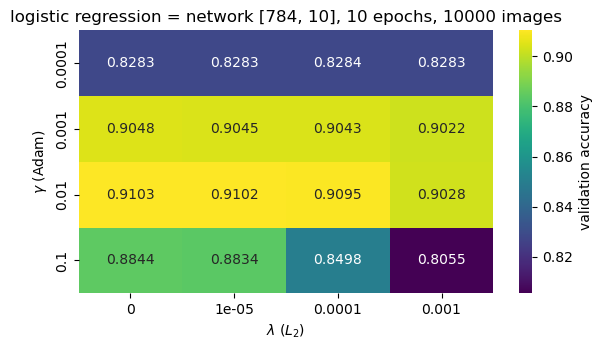

best: gamma = 0.01, lambda = 0, validation accuracy 0.9103
validation accuracy (rows: gamma = [0.0001, 0.001, 0.01, 0.1], columns: lambda = [0.0, 1e-05, 0.0001, 0.001])
 [[0.8283 0.8283 0.8284 0.8283]
 [0.9048 0.9045 0.9043 0.9022]
 [0.9103 0.9102 0.9095 0.9028]
 [0.8844 0.8834 0.8498 0.8055]]


In [40]:
gammas_lr, lambdas_lr = [1e-4, 1e-3, 1e-2, 1e-1], [0.0, 1e-5, 1e-4, 1e-3]  # grid of the scan
acc_lr = np.array([[run_mnist([], "relu", "adam", g, lam)[1] for lam in lambdas_lr] for g in gammas_lr])  # accuracies
i, j = np.unravel_index(np.nanargmax(acc_lr), acc_lr.shape)  # the best pair
LOGREG = dict(method="adam", gamma=gammas_lr[i], lmbda=lambdas_lr[j])  # selected optimiser, learning rate, penalty
fig, ax = plt.subplots(figsize=(6, 3.6))
sns.heatmap(acc_lr, annot=True, fmt=".4f", cmap="viridis", ax=ax, xticklabels=[f"{l:g}" for l in lambdas_lr],
            yticklabels=[f"{g:g}" for g in gammas_lr], cbar_kws={"label": "validation accuracy"})
ax.set_xlabel(r"$\lambda$ ($L_2$)"); ax.set_ylabel(r"$\gamma$ (Adam)")
ax.set_title("logistic regression = network [784, 10], 10 epochs, 10000 images")
plt.tight_layout()
plt.show()
print(f"best: gamma = {LOGREG['gamma']:g}, lambda = {LOGREG['lmbda']:g}, validation accuracy {acc_lr[i, j]:.4f}")
print(f"validation accuracy (rows: gamma = {gammas_lr}, columns: lambda = {lambdas_lr})\n", np.round(acc_lr, 4))

#### e.2 Figure for the report
**Source:** the validation accuracies of e.2 (`acc_lr`). **Modifications:** the selected cell framed in red, the colour
scale saturated below 0.88 so that the good cells stay distinct (every value is written in its cell), full axis labels.
No new results.
> **LLM note:** Written with Claude (Level 4). New plotting code.

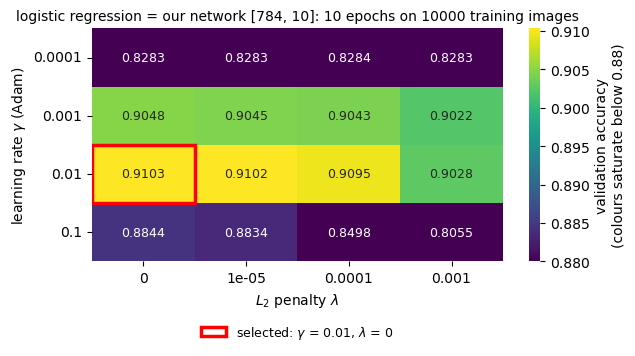

selected: gamma = 0.01, lambda = 0, validation accuracy 0.9103   (must equal LOGREG of e.2: {'method': 'adam', 'gamma': 0.01, 'lmbda': 0.0})


In [41]:
# ---- Figure for the report: e.2 redrawn (acc_lr of e.2; nothing is recomputed) ----
def report_heatmap(ax, values, xlabels, ylabels, cbar_label, vmin=None, vmax=None):
    """
    Annotated heat map of validation accuracies with the selected cell (the highest value) framed in red.
    Returns the row and column of the selected cell.

    LLM-assisted
    ------------
    Tool: Claude (Claude Opus 5.5, claude.ai)
    Role: Wrote the heat map helper of the report figures of part e).
    """
    sns.heatmap(values, annot=True, fmt=".4f", cmap="viridis", vmin=vmin, vmax=vmax, ax=ax, xticklabels=xlabels,
                yticklabels=ylabels, annot_kws={"size": 9}, cbar_kws={"label": cbar_label})
    i, j = np.unravel_index(np.nanargmax(values), values.shape)  # the selected cell: highest validation accuracy
    ax.add_patch(plt.Rectangle((j, i), 1, 1, fill=False, edgecolor="red", lw=2.5, zorder=5))  # frame it
    ax.tick_params(axis="y", rotation=0)                  # horizontal tick labels
    return i, j


fig, ax = plt.subplots(figsize=(6.5, 3.8))
i, j = report_heatmap(ax, acc_lr, [f"{l:g}" for l in lambdas_lr], [f"{g:g}" for g in gammas_lr],
                      "validation accuracy\n(colours saturate below 0.88)", vmin=0.88)  # the good cells stay distinct
ax.set_xlabel(r"$L_2$ penalty $\lambda$"); ax.set_ylabel(r"learning rate $\gamma$ (Adam)")
ax.set_title("logistic regression = our network [784, 10]: 10 epochs on 10000 training images", fontsize=10)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, fill=False, edgecolor="red", lw=2.5,
                                 label=f"selected: $\\gamma$ = {gammas_lr[i]:g}, $\\lambda$ = {lambdas_lr[j]:g}")],
          loc="upper center", bbox_to_anchor=(0.5, -0.22), frameon=False, fontsize=9)
plt.tight_layout()
save_figure(fig, "e2_logistic_regression")
plt.show()
print(f"selected: gamma = {gammas_lr[i]:g}, lambda = {lambdas_lr[j]:g}, validation accuracy {acc_lr[i, j]:.4f}"
      f"   (must equal LOGREG of e.2: {LOGREG})")

#### e.3 Gradient methods and learning rates on MNIST
**Source:** the learning rate scan per method of b.6 (`Project1.ipynb` f.2; `week38tuesday.ipynb`, Case 1, Step 4).
**Modifications:** one hidden layer of 128 ReLU nodes (He initialisation), minibatches of 128 (79 updates per epoch on 10000
images, the last one with 16 images), 10 epochs, plain SGD, RMSprop and Adam (the update rules the project text asks for, as in b.6), five learning rates
from $10^{-4}$ to 1;
the score is the validation accuracy, shown as a heat map. The best pair is used in e.4. The ReLU is the default of
Section 8.6.4, and 128 nodes is close to the 100 of the course example and one of the widths of e.5 (whose cell with one
layer of 128 nodes repeats this network): large enough to beat logistic regression clearly, small enough for the 15 runs
of the scan to stay short (the cell prints the time of the scan).
> **LLM note:** Written with Claude (Level 4), adapted from b.6.

scan done in 36 s


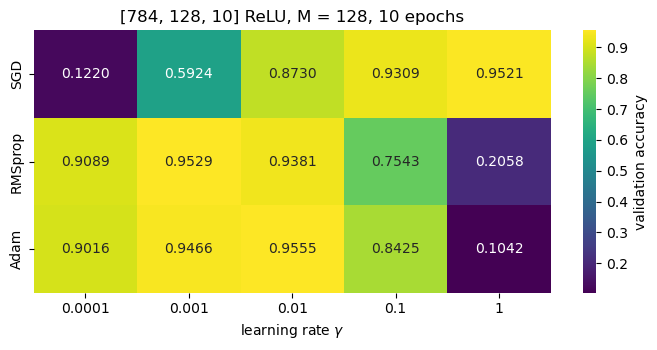

plain    : best validation accuracy 0.9521 at gamma = 1
rmsprop  : best validation accuracy 0.9529 at gamma = 0.001
adam     : best validation accuracy 0.9555 at gamma = 0.01


In [42]:
methods_e = ["plain", "rmsprop", "adam"]                  # the update rules of b.6
gammas_e = [1e-4, 1e-3, 1e-2, 1e-1, 1.0]                  # learning rates from 1e-4 to 1
t0 = time.perf_counter()                                  # start the clock
acc_opt = np.array([[run_mnist([128], "relu", m, g)[1] for g in gammas_e] for m in methods_e])  # (rule, gamma) grid
print(f"scan done in {time.perf_counter() - t0:.0f} s")
i, j = np.unravel_index(np.nanargmax(acc_opt), acc_opt.shape)  # the best pair
OPT_E = methods_e[i]                                      # the update rule used from now on
fig, ax = plt.subplots(figsize=(7, 3.6))
sns.heatmap(acc_opt, annot=True, fmt=".4f", cmap="viridis", ax=ax, xticklabels=[f"{g:g}" for g in gammas_e],
            yticklabels=["SGD", "RMSprop", "Adam"], cbar_kws={"label": "validation accuracy"})
ax.set_xlabel(r"learning rate $\gamma$")
ax.set_title("[784, 128, 10] ReLU, M = 128, 10 epochs" + (" (white: diverged)" if np.isnan(acc_opt).any() else ""))
plt.tight_layout()
plt.show()
for m, row in zip(methods_e, acc_opt):
    print(f"{m:9s}: best validation accuracy {np.nanmax(row):.4f} at gamma = {gammas_e[int(np.nanargmax(row))]:g}")

#### e.3 Figure for the report
**Source:** the validation accuracies of e.3 (`acc_opt`). **Modifications:** the selected cell framed in red and the best
learning rate of each other update rule framed in white, the colour scale saturated below 0.9 so that the good cells
stay distinct (every value is written in its cell), full axis labels. No new results.
> **LLM note:** Written with Claude (Level 4). New plotting code.

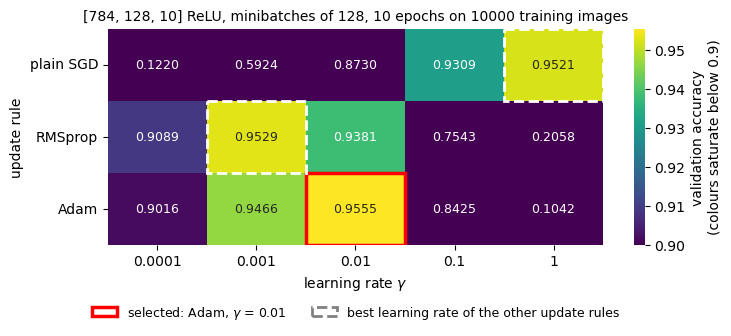

plain    : best validation accuracy 0.9521 at gamma = 1   (must equal e.3)
rmsprop  : best validation accuracy 0.9529 at gamma = 0.001   (must equal e.3)
adam     : best validation accuracy 0.9555 at gamma = 0.01   (must equal e.3)
selected update rule: adam   (must equal OPT_E of e.3: adam)


In [43]:
# ---- Figure for the report: e.3 redrawn (acc_opt of e.3; nothing is recomputed) ----
NAME_E = {"plain": "plain SGD", "rmsprop": "RMSprop", "adam": "Adam"}  # row labels
fig, ax = plt.subplots(figsize=(7.5, 3.6))
i, j = report_heatmap(ax, acc_opt, [f"{g:g}" for g in gammas_e], [NAME_E[m] for m in methods_e],
                      "validation accuracy\n(colours saturate below 0.9)", vmin=0.9)  # the good cells stay distinct
for r, row in enumerate(acc_opt):                         # best learning rate of every update rule
    c = int(np.nanargmax(row))                            # its column
    if (r, c) != (i, j):                                  # the overall best is already framed in red
        ax.add_patch(plt.Rectangle((c, r), 1, 1, fill=False, edgecolor="white", lw=2, ls="--", zorder=5))
ax.set_xlabel(r"learning rate $\gamma$"); ax.set_ylabel("update rule")
ax.set_title("[784, 128, 10] ReLU, minibatches of 128, 10 epochs on 10000 training images", fontsize=10)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, fill=False, edgecolor="red", lw=2.5,
                                 label=f"selected: {NAME_E[methods_e[i]]}, $\\gamma$ = {gammas_e[j]:g}"),
                   plt.Rectangle((0, 0), 1, 1, fill=False, edgecolor="gray", lw=2, ls="--",
                                 label="best learning rate of the other update rules")],
          loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2, frameon=False, fontsize=9)
plt.tight_layout()
save_figure(fig, "e3_methods_learning_rates")
plt.show()
for m, row in zip(methods_e, acc_opt):
    print(f"{m:9s}: best validation accuracy {np.nanmax(row):.4f} at gamma = {gammas_e[int(np.nanargmax(row))]:g}"
          f"   (must equal e.3)")
print(f"selected update rule: {methods_e[i]}   (must equal OPT_E of e.3: {OPT_E})")

#### e.4 Learning rate and $L_2$ penalty
**Source:** the heat map of learning rate against penalty of `week44tuesday.ipynb`, Case 2, Step 3, here for the classifier.
**Modifications:** the update rule selected in e.3, five learning rates around its best one, $\lambda$ from 0 to $10^{-3}$
($L_2$ on the weights), the same network and budget as e.3. Only $L_2$: part d) compared the two norms, and here the
question is whether a penalty helps at all; the grid stops at $10^{-3}$, where the penalty already lowered the accuracy
of logistic regression in e.2.
> **LLM note:** Written with Claude (Level 4), adapted from `week44tuesday.ipynb`.

scan done in 75 s


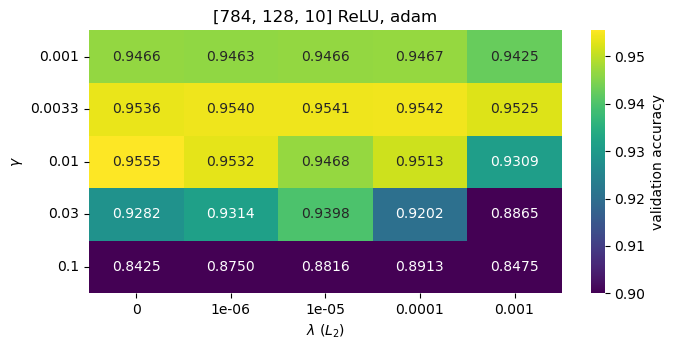

best: gamma = 1.0e-02, lambda = 0, validation accuracy 0.9555; without penalty at that gamma: 0.9555
validation accuracy (rows: gamma = [0.001, 0.00333, 0.01, 0.03, 0.1], columns: lambda = [0.0, 1e-06, 1e-05, 0.0001, 0.001])
 [[0.9466 0.9463 0.9466 0.9467 0.9425]
 [0.9536 0.954  0.9541 0.9542 0.9525]
 [0.9555 0.9532 0.9468 0.9513 0.9309]
 [0.9282 0.9314 0.9398 0.9202 0.8865]
 [0.8425 0.875  0.8816 0.8913 0.8475]]


In [44]:
g0 = gammas_e[int(np.nanargmax(acc_opt[methods_e.index(OPT_E)]))]  # best learning rate of the selected rule in e.3
gammas_e4 = [g0 / 10, g0 / 3, g0, 3 * g0, 10 * g0]        # around the best learning rate of e.3
lambdas_e4 = [0.0, 1e-6, 1e-5, 1e-4, 1e-3]                # L2 penalties
t0 = time.perf_counter()                                  # start the clock
acc_gl = np.array([[run_mnist([128], "relu", OPT_E, g, lam)[1] for lam in lambdas_e4] for g in gammas_e4])  # grid
print(f"scan done in {time.perf_counter() - t0:.0f} s")
i, j = np.unravel_index(np.nanargmax(acc_gl), acc_gl.shape)  # the best pair
GAMMA_E, LAMBDA_E = gammas_e4[i], lambdas_e4[j]           # learning rate and penalty used from now on
fig, ax = plt.subplots(figsize=(7, 3.6))
# colours saturate below 0.9, so that the differences between the good cells stay visible (the numbers are exact)
sns.heatmap(acc_gl, annot=True, fmt=".4f", cmap="viridis", ax=ax, xticklabels=[f"{l:g}" for l in lambdas_e4],
            yticklabels=[f"{g:.2g}" for g in gammas_e4], vmin=0.9, cbar_kws={"label": "validation accuracy"})
ax.tick_params(axis="y", rotation=0)                      # horizontal labels of the learning rates
ax.set_xlabel(r"$\lambda$ ($L_2$)"); ax.set_ylabel(r"$\gamma$"); ax.set_title(f"[784, 128, 10] ReLU, {OPT_E}")
plt.tight_layout()
plt.show()
print(f"best: gamma = {GAMMA_E:.1e}, lambda = {LAMBDA_E:g}, validation accuracy {acc_gl[i, j]:.4f}; "
      f"without penalty at that gamma: {acc_gl[i, 0]:.4f}")
print(f"validation accuracy (rows: gamma = {[float(f'{g:.3g}') for g in gammas_e4]}, columns: lambda = {lambdas_e4})\n",
      np.round(acc_gl, 4))

#### e.4 Figure for the report
**Source:** the validation accuracies of e.4 (`acc_gl`). **Modifications:** the selected cell framed in red, the
saturation of the colours below 0.9 stated in the colour bar, full axis labels and the setup in the title. No new
results.
> **LLM note:** Written with Claude (Level 4). New plotting code.

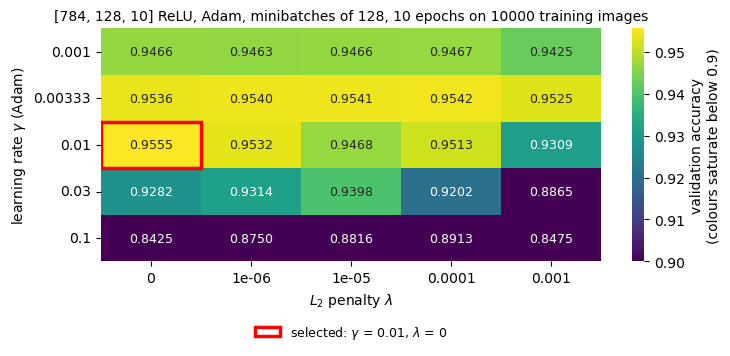

selected: gamma = 0.01, lambda = 0, validation accuracy 0.9555   (must equal GAMMA_E = 0.01, LAMBDA_E = 0 of e.4)


In [45]:
# ---- Figure for the report: e.4 redrawn (acc_gl of e.4; nothing is recomputed) ----
fig, ax = plt.subplots(figsize=(7.5, 3.8))
i, j = report_heatmap(ax, acc_gl, [f"{l:g}" for l in lambdas_e4], [f"{g:.3g}" for g in gammas_e4],
                      "validation accuracy\n(colours saturate below 0.9)", vmin=0.9)  # as in e.4
ax.set_xlabel(r"$L_2$ penalty $\lambda$"); ax.set_ylabel(rf"learning rate $\gamma$ ({NAME_E[OPT_E]})")
ax.set_title(f"[784, 128, 10] ReLU, {NAME_E[OPT_E]}, minibatches of 128, 10 epochs on 10000 training images",
             fontsize=10)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, fill=False, edgecolor="red", lw=2.5,
                                 label=f"selected: $\\gamma$ = {gammas_e4[i]:.3g}, $\\lambda$ = {lambdas_e4[j]:g}")],
          loc="upper center", bbox_to_anchor=(0.5, -0.22), frameon=False, fontsize=9)
plt.tight_layout()
save_figure(fig, "e4_learning_rate_lambda")
plt.show()
print(f"selected: gamma = {gammas_e4[i]:.3g}, lambda = {lambdas_e4[j]:g}, validation accuracy {acc_gl[i, j]:.4f}"
      f"   (must equal GAMMA_E = {GAMMA_E:.3g}, LAMBDA_E = {LAMBDA_E:g} of e.4)")

#### e.5 Depth and width
**Source:** the depth and width heat map of c.2, now for the classifier (project text, "Required analysis" 2).
**Modifications:** 1 to 3 hidden layers of 32 to 256 ReLU nodes (from a quarter to twice the 128 nodes of e.3, up to 335114
parameters, the largest networks we could afford in a scan), the update rule, learning rate and penalty of e.3 and e.4,
validation accuracy, and the number of parameters of every network.
> **LLM note:** Written with Claude (Level 4), adapted from c.2.

scan done in 78 s


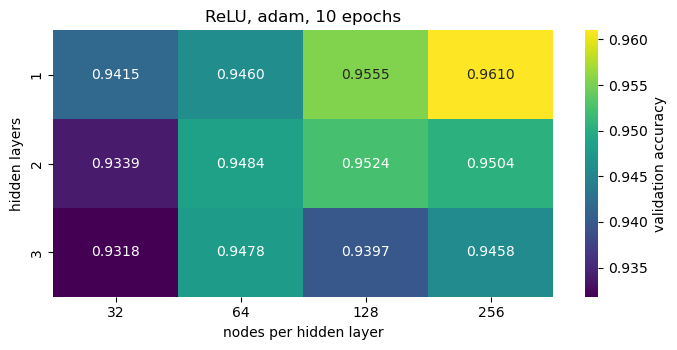

1 hidden layer(s): 32 nodes 0.9415 (25450 par.), 64 nodes 0.9460 (50890 par.), 128 nodes 0.9555 (101770 par.), 256 nodes 0.9610 (203530 par.)
2 hidden layer(s): 32 nodes 0.9339 (26506 par.), 64 nodes 0.9484 (55050 par.), 128 nodes 0.9524 (118282 par.), 256 nodes 0.9504 (269322 par.)
3 hidden layer(s): 32 nodes 0.9318 (27562 par.), 64 nodes 0.9478 (59210 par.), 128 nodes 0.9397 (134794 par.), 256 nodes 0.9458 (335114 par.)
selected architecture: [256]


In [46]:
depths_e, widths_e = [1, 2, 3], [32, 64, 128, 256]        # hidden layers, nodes per layer
t0 = time.perf_counter()                                  # start the clock
acc_dw = np.array([[run_mnist([w] * d, "relu", OPT_E, GAMMA_E, LAMBDA_E)[1] for w in widths_e] for d in depths_e])  # grid
print(f"scan done in {time.perf_counter() - t0:.0f} s")
i, j = np.unravel_index(np.nanargmax(acc_dw), acc_dw.shape)  # the best cell
HIDDEN_E = [widths_e[j]] * depths_e[i]                    # architecture used from now on
n_par_e = lambda hidden: sum(a * b + b for a, b in zip([784, *hidden], [*hidden, 10]))  # weights and biases
fig, ax = plt.subplots(figsize=(7, 3.6))
sns.heatmap(acc_dw, annot=True, fmt=".4f", cmap="viridis", ax=ax, xticklabels=widths_e, yticklabels=depths_e,
            cbar_kws={"label": "validation accuracy"})
ax.set_xlabel("nodes per hidden layer"); ax.set_ylabel("hidden layers"); ax.set_title(f"ReLU, {OPT_E}, 10 epochs")
plt.tight_layout()
plt.show()
for d, row in zip(depths_e, acc_dw):
    print(f"{d} hidden layer(s): " + ", ".join(f"{w} nodes {a:.4f} ({n_par_e([w] * d)} par.)" for w, a in zip(widths_e, row)))
print("selected architecture:", HIDDEN_E)

#### e.5 Figure for the report
**Source:** `acc_dw` of e.5. **Modifications:** the selected cell framed in red, full axis labels. No new results.
> **LLM note:** Written with Claude (Level 4). New plotting code.

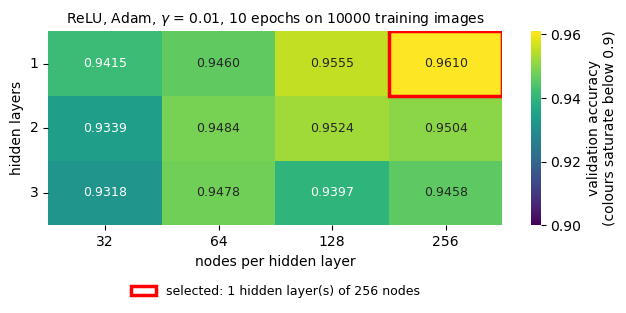

selected: 1 hidden layer(s) of 256 nodes, 0.9610   (must equal HIDDEN_E = [256])


In [47]:
# ---- Figure for the report: e.5 redrawn (acc_dw of e.5; nothing is recomputed) ----
fig, ax = plt.subplots(figsize=(6.5, 3.4))
i, j = report_heatmap(ax, acc_dw, widths_e, depths_e, "validation accuracy\n(colours saturate below 0.9)", vmin=0.9)
ax.set_xlabel("nodes per hidden layer"); ax.set_ylabel("hidden layers")
ax.set_title(rf"ReLU, {NAME_E[OPT_E]}, $\gamma$ = {GAMMA_E:g}, 10 epochs on 10000 training images", fontsize=10)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, fill=False, edgecolor="red", lw=2.5,
                                 label=f"selected: {depths_e[i]} hidden layer(s) of {widths_e[j]} nodes")],
          loc="upper center", bbox_to_anchor=(0.5, -0.25), frameon=False, fontsize=9)
plt.tight_layout()
save_figure(fig, "e5_depth_width")
plt.show()
print(f"selected: {depths_e[i]} hidden layer(s) of {widths_e[j]} nodes, {acc_dw[i, j]:.4f}   (must equal HIDDEN_E = {HIDDEN_E})")

#### e.6 Sigmoid, ReLU and leaky ReLU
**Source:** the comparison of activations of c.2 and of `week41monday.ipynb`, Part 4, Example 3 (sigmoid against ReLU on
MNIST), and Table 8.2 of the lecture notes. **Modifications:** the architecture of e.5 and a single hidden layer of 128
nodes, the three activations with their initialisation (b.2). Every activation gets its own learning rate from
$\{\gamma/3,\gamma,3\gamma,10\gamma\}$ around the one of e.4, as in c.1 and as in the course example, which trains the sigmoid
with $\gamma=0.5$ and the ReLU with $\gamma=0.1$ (`week41monday.ipynb`, Part 4, Example 3): the derivative of the sigmoid
is at most $1/4$, so its gradients are smaller and a fair comparison needs its own step. The figure shows the validation
accuracy after every epoch at the best learning rate of each network; the final network of e.7 takes the activation
with the highest validation accuracy at the architecture of e.5, with its own learning rate.
> **LLM note:** Written with Claude (Level 4). New code.

[128]       sigmoid   : validation accuracy 0.9465  0.9554  0.9464  0.9034   for gamma = 0.00333, 0.01, 0.03, 0.1  ->  gamma = 0.01
[128]       relu      : validation accuracy 0.9536  0.9555  0.9282  0.8425   for gamma = 0.00333, 0.01, 0.03, 0.1  ->  gamma = 0.01
[128]       leaky_relu: validation accuracy 0.9542  0.9481  0.9469  0.8698   for gamma = 0.00333, 0.01, 0.03, 0.1  ->  gamma = 0.00333
[256]       sigmoid   : validation accuracy 0.9478  0.9568  0.9488  0.8998   for gamma = 0.00333, 0.01, 0.03, 0.1  ->  gamma = 0.01
[256]       relu      : validation accuracy 0.9634  0.9610  0.9443  0.9060   for gamma = 0.00333, 0.01, 0.03, 0.1  ->  gamma = 0.00333
[256]       leaky_relu: validation accuracy 0.9624  0.9587  0.9361  0.8847   for gamma = 0.00333, 0.01, 0.03, 0.1  ->  gamma = 0.00333


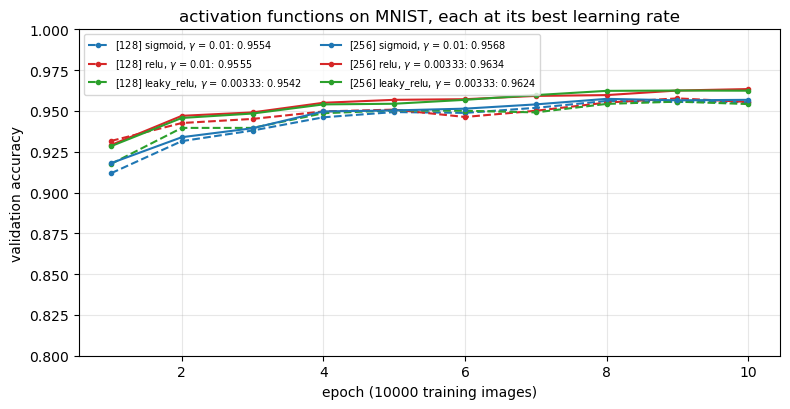

selected activation for [256] : relu with gamma = 0.00333


In [48]:
gammas_e6 = [GAMMA_E / 3, GAMMA_E, 3 * GAMMA_E, 10 * GAMMA_E]  # every activation gets its own learning rate, as in c.1
acc_act, gamma_act = {}, {}                               # best validation accuracy and its learning rate, per network
fig, ax = plt.subplots(figsize=(8, 4.2))
for hidden, style in [([128], "--"), (HIDDEN_E, "-")]:
    for act, color in zip(acts, ["C0", "C3", "C2"]):
        runs = [run_mnist(hidden, act, OPT_E, g, LAMBDA_E, record=True) for g in gammas_e6]  # one run per learning rate
        k = int(np.nanargmax([r[1] for r in runs]))       # the learning rate with the highest validation accuracy
        acc_act[(str(hidden), act)], gamma_act[(str(hidden), act)] = runs[k][1], gammas_e6[k]  # store the best
        print(f"{str(hidden):11s} {act:10s}: validation accuracy " + "  ".join(f"{r[1]:.4f}" for r in runs)
              + f"   for gamma = {', '.join(f'{g:.3g}' for g in gammas_e6)}  ->  gamma = {gammas_e6[k]:.3g}")
        hist = runs[k][2]                                 # the curve at the best learning rate
        ax.plot(hist["epoch"], hist["val_acc"], style, color=color, marker="o", ms=3,
                label=f"{hidden} {act}, $\\gamma$ = {gammas_e6[k]:.3g}: {runs[k][1]:.4f}")
ax.set_xlabel("epoch (10000 training images)"); ax.set_ylabel("validation accuracy"); ax.set_ylim(0.80, 1.0)
ax.legend(fontsize=7, ncol=2); ax.grid(alpha=0.3); ax.set_title("activation functions on MNIST, each at its best learning rate")
plt.tight_layout()
plt.show()
ACT_E = max(acts, key=lambda a: acc_act[(str(HIDDEN_E), a)])  # activation used for the final network
GAMMA_F = gamma_act[(str(HIDDEN_E), ACT_E)]               # and its own learning rate, used in e.7
print("selected activation for", HIDDEN_E, ":", ACT_E, "with gamma =", f"{GAMMA_F:.3g}")

#### e.6 Figure for the report
**Source:** the runs of e.6, repeated with the same function `run_mnist`, networks, seed and learning rates, because
e.6 keeps only the best accuracy of each network. **Modifications:** a heat map of all runs with the best learning rate
of each row and the selected network framed; the learning curves in one panel per width, on a scale from 0.90 to
0.97. No new results.
> **LLM note:** Written with Claude (Level 4). New plotting code.

[128]       sigmoid   : validation accuracy 0.9465  0.9554  0.9464  0.9034   for gamma = 0.00333, 0.01, 0.03, 0.1   (must equal e.6)
[128]       relu      : validation accuracy 0.9536  0.9555  0.9282  0.8425   for gamma = 0.00333, 0.01, 0.03, 0.1   (must equal e.6)
[128]       leaky_relu: validation accuracy 0.9542  0.9481  0.9469  0.8698   for gamma = 0.00333, 0.01, 0.03, 0.1   (must equal e.6)
[256]       sigmoid   : validation accuracy 0.9478  0.9568  0.9488  0.8998   for gamma = 0.00333, 0.01, 0.03, 0.1   (must equal e.6)
[256]       relu      : validation accuracy 0.9634  0.9610  0.9443  0.9060   for gamma = 0.00333, 0.01, 0.03, 0.1   (must equal e.6)
[256]       leaky_relu: validation accuracy 0.9624  0.9587  0.9361  0.8847   for gamma = 0.00333, 0.01, 0.03, 0.1   (must equal e.6)


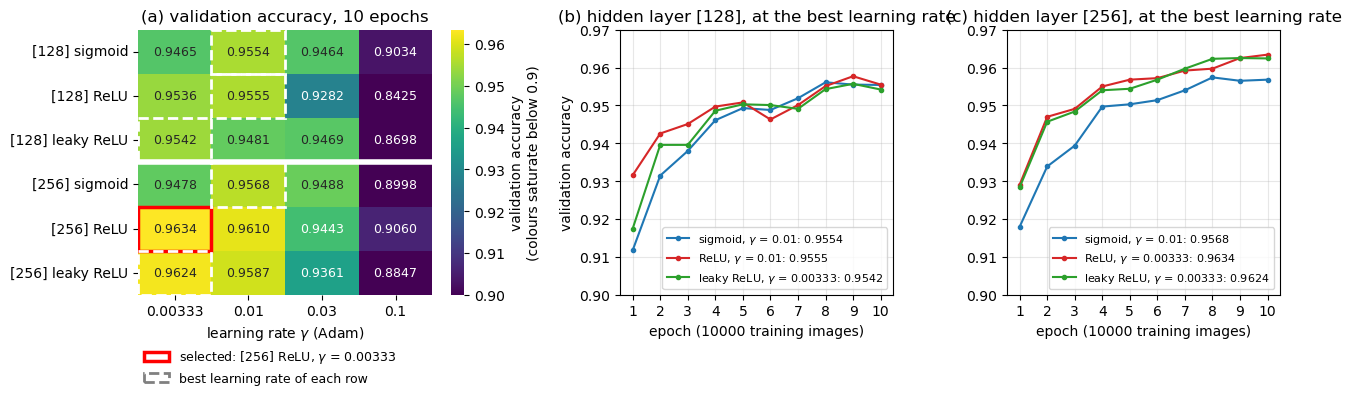

selected: [256] ReLU, gamma = 0.00333   (must equal ACT_E = relu, GAMMA_F = 0.00333 of e.6)


In [49]:
# ---- Figure for the report: e.6 redrawn (the runs of e.6 repeated with the same function, networks, seed and learning
# rates, because e.6 keeps only the best accuracy of each network; nothing else changes) ----
widths_e6 = [[128], HIDDEN_E]                             # the two networks of e.6
runs_e6 = {(str(h), a): [run_mnist(h, a, OPT_E, g, LAMBDA_E, record=True) for g in gammas_e6]
           for h in widths_e6 for a in acts}              # one run per learning rate, as in e.6
for (h, a), runs in runs_e6.items():                      # the same lines as e.6
    print(f"{h:11s} {a:10s}: validation accuracy " + "  ".join(f"{r[1]:.4f}" for r in runs)
          + f"   for gamma = {', '.join(f'{g:.3g}' for g in gammas_e6)}   (must equal e.6)")

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.35, 1, 1]})
# (a) validation accuracy of every network and activation at every learning rate
acc_rows = np.array([[r[1] for r in runs_e6[(str(h), a)]] for h in widths_e6 for a in acts])  # 6 rows, 4 columns
labels = [f"{h} {NICE[a]}" for h in widths_e6 for a in acts]  # row labels
i, j = report_heatmap(axes[0], acc_rows, [f"{g:.3g}" for g in gammas_e6], labels,
                      "validation accuracy\n(colours saturate below 0.9)", vmin=0.9)  # red: the overall best
for r, row in enumerate(acc_rows):                        # best learning rate of every network and activation
    c = int(np.nanargmax(row))
    if (r, c) != (i, j):
        axes[0].add_patch(plt.Rectangle((c, r), 1, 1, fill=False, edgecolor="white", lw=2, ls="--", zorder=5))
axes[0].axhline(len(acts), color="white", lw=4)           # separates the two widths
axes[0].set_xlabel(rf"learning rate $\gamma$ ({NAME_E[OPT_E]})"); axes[0].set_title("(a) validation accuracy, 10 epochs")
axes[0].legend(handles=[plt.Rectangle((0, 0), 1, 1, fill=False, edgecolor="red", lw=2.5,
                                      label=f"selected: {labels[i]}, $\\gamma$ = {gammas_e6[j]:.3g}"),
                        plt.Rectangle((0, 0), 1, 1, fill=False, edgecolor="gray", lw=2, ls="--",
                                      label="best learning rate of each row")],
               loc="upper center", bbox_to_anchor=(0.45, -0.16), ncol=1, frameon=False, fontsize=9)
# (b), (c) validation accuracy after every epoch, at the best learning rate of each activation
for ax, h, title in [(axes[1], widths_e6[0], "(b)"), (axes[2], widths_e6[1], "(c)")]:
    for a in acts:
        runs = runs_e6[(str(h), a)]
        k = int(np.nanargmax([r[1] for r in runs]))       # best learning rate of this activation
        hist = runs[k][2]                                 # its curve
        ax.plot(hist["epoch"], hist["val_acc"], "o-", ms=3, color=COLOR_A[a],
                label=rf"{NICE[a]}, $\gamma$ = {gammas_e6[k]:.3g}: {runs[k][1]:.4f}")
    ax.set_ylim(0.90, 0.97); ax.set_xticks(range(1, 11))
    ax.set_xlabel("epoch (10000 training images)"); ax.grid(alpha=0.3); ax.legend(fontsize=8, loc="lower right")
    ax.set_title(f"{title} hidden layer {h}, at the best learning rate")
axes[1].set_ylabel("validation accuracy"); axes[2].sharey(axes[1])
plt.tight_layout()
save_figure(fig, "e6_activations")
plt.show()
print(f"selected: {labels[i]}, gamma = {gammas_e6[j]:.3g}   (must equal ACT_E = {ACT_E}, GAMMA_F = {GAMMA_F:.3g} of e.6)")

#### e.7 The selected models on all 50000 training images, early stopping, and the test set once
**Source:** early stopping on a validation set, Section 8.12 of the lecture notes (and `week41monday.ipynb`, "Pause and
think 5": a validation set split off the training data decides when to stop); the comparison with `MLPClassifier` follows
Section 8.14 of the lecture notes; the standard error of an accuracy, $\sqrt{\hat p(1-\hat p)/n}$, is that of
`exercisesweek43_solutions.ipynb`, exercise 3d. **Modifications:** our two models selected above (logistic regression of
e.2 and the network of e.3 to e.6, each with its own optimiser, learning rate and penalty) are trained on all 50000
training images for up to 50 epochs, and the parameters of the epoch
with the highest validation accuracy are kept
(`keep_best` of b.3). Only then are they evaluated on the 10000 test images, once. `MLPClassifier` gets the same
architecture, activation, optimiser, learning rate, minibatch size and number of epochs as our network (Scikit-Learn has
no leaky ReLU and no RMSprop; the cell says what replaces them); its $L_2$ term is $\frac{\alpha}{2M}\|\boldsymbol
W\|_2^2$ per minibatch of $M$ samples, so our $\lambda$ corresponds to $\alpha=2M\lambda$. The library logistic regression
is the starter cell above (all 60000 training images). (This cell takes a few minutes.)
> **LLM note:** Written with Claude (Level 4). New code; the `MLPClassifier` call follows Section 8.14 of the lecture notes.

logistic regression (our code, no hidden layer): best validation accuracy 0.9224 at epoch 15; 8 s for 50 epochs
FFNN [256], relu (our code): best validation accuracy 0.9816 at epoch 49; 366 s for 50 epochs
MLPClassifier: activation 'relu' for our 'relu', {'solver': 'adam'} for our 'adam'

model                                              test accuracy +- s.e.   validation   training   epochs   parameters
logistic regression (our code, no hidden layer)    0.9241 +- 0.0026       0.9224       0.9347       15       7850
FFNN [256], relu (our code)                        0.9806 +- 0.0014       0.9816       0.9990       49     203530
Scikit-Learn MLPClassifier [256]                   0.9790 +- 0.0014       0.9795       0.9982       49     203530
Scikit-Learn LogisticRegression (starter cell)     0.9257 +- 0.0026            -            -      511       7850
guessing (most frequent digit)                     0.1135 +-      -            -            -        0          0


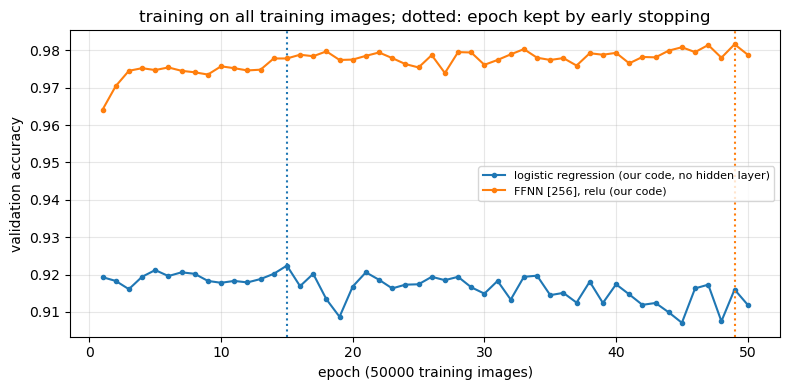

In [50]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

EPOCHS_E, M_E = 50, 128                                   # at most 50 epochs over the 50000 images, minibatches of 128
se_acc = lambda p, n: np.sqrt(p * (1 - p) / n)            # standard error of an accuracy p measured on n images
CLS = {}                                                  # classification results for part f)
final_nets = {}                                           # the trained final models and their histories
for name, hidden, act, method, gamma, lmbda in [("logistic regression (our code, no hidden layer)", [], "relu",
                                                  LOGREG["method"], LOGREG["gamma"], LOGREG["lmbda"]),
                                                 (f"FFNN {HIDDEN_E}, {ACT_E} (our code)", HIDDEN_E, ACT_E, OPT_E,
                                                  GAMMA_F, LAMBDA_E)]:
    net = FFNN([784, *hidden, 10], [act] * len(hidden) + ["softmax"], "cross_entropy", lmbda, "l2")  # the selected model
    t0 = time.perf_counter()                              # start the clock
    hist = train_network(net, X_tr, Y_tr, method=method, gamma=gamma, epochs=EPOCHS_E, batch_size=M_E,  # early stopping
                         monitor=lambda nt: {"val_err": 1.0 - accuracy_of(nt, X_val, y_val)}, keep_best="val_err")
    seconds = time.perf_counter() - t0                    # training time
    final_nets[name] = (net, hist)                        # keep the model
    acc_test = accuracy_of(net, x_test, y_test)           # the test set, once
    CLS[name] = dict(test=acc_test, test_se=se_acc(acc_test, len(y_test)), val=1 - min(hist["val_err"]),  # its numbers
                     train=accuracy_of(net, X_tr, y_tr), epochs=hist["best_epoch"], n_par=net.theta.size, seconds=seconds)
    print(f"{name}: best validation accuracy {CLS[name]['val']:.4f} at epoch {hist['best_epoch']}; "
          f"{seconds:.0f} s for {EPOCHS_E} epochs")

# Scikit-Learn's MLPClassifier with our settings, as many epochs as our best epoch. Scikit-Learn has no leaky ReLU and
# no RMSprop: they are replaced by the ReLU and by Adam. Its SGD has momentum 0.9 by default: momentum=0.0 makes it plain SGD.
sk_act = {"relu": "relu", "sigmoid": "logistic", "leaky_relu": "relu"}[ACT_E]
sk_solver = {"plain": dict(solver="sgd", momentum=0.0), "adam": dict(solver="adam"), "rmsprop": dict(solver="adam")}[OPT_E]
print(f"MLPClassifier: activation '{sk_act}' for our '{ACT_E}', {sk_solver} for our '{OPT_E}'")
mlp_c = MLPClassifier(hidden_layer_sizes=tuple(HIDDEN_E), activation=sk_act, alpha=2 * M_E * LAMBDA_E, batch_size=M_E,  # ours
                      learning_rate_init=GAMMA_F, max_iter=CLS[f"FFNN {HIDDEN_E}, {ACT_E} (our code)"]["epochs"],
                      tol=0.0, n_iter_no_change=1000, shuffle=True, random_state=SEED, **sk_solver)
t0 = time.perf_counter()                                  # start the clock
with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)   # max_iter is reached on purpose
    mlp_c.fit(X_tr, y_tr)                                 # the same 50000 training images
acc_mlp = accuracy_score(y_test, mlp_c.predict(x_test))   # the test set, once
CLS[f"Scikit-Learn MLPClassifier {HIDDEN_E}"] = dict(test=acc_mlp, test_se=se_acc(acc_mlp, len(y_test)),  # its numbers
                                                      val=accuracy_score(y_val, mlp_c.predict(X_val)),
                                                      train=accuracy_score(y_tr, mlp_c.predict(X_tr)),
                                                      epochs=mlp_c.n_iter_, n_par=n_par_e(HIDDEN_E),
                                                      seconds=time.perf_counter() - t0)
# the starter cell's Scikit-Learn logistic regression (trained on all 60000 images)
CLS["Scikit-Learn LogisticRegression (starter cell)"] = dict(test=accuracy, test_se=se_acc(accuracy, len(y_test)),  # starter
                                                              val=np.nan, train=np.nan, epochs=model.n_iter_[0],
                                                              n_par=785 * 10, seconds=np.nan)
CLS["guessing (most frequent digit)"] = dict(test=np.max(np.bincount(y_test)) / len(y_test), test_se=np.nan,  # guess
                                             val=np.nan, train=np.nan, epochs=0, n_par=0, seconds=0.0)

show = lambda v: "     -" if np.isnan(v) else f"{v:.4f}"  # "-" where a number does not exist (starter cell, guessing)
print("\nmodel                                              test accuracy +- s.e.   validation   training   epochs   parameters")
for name, r in CLS.items():
    print(f"{name:50s} {r['test']:.4f} +- {show(r['test_se'])}       {show(r['val'])}       {show(r['train'])}     "
          f"{r['epochs']:4d}   {r['n_par']:8d}")

fig, ax = plt.subplots(figsize=(8, 4))
for name, (net, hist) in final_nets.items():
    ax.plot(hist["epoch"], 1 - np.array(hist["val_err"]), "o-", ms=3, label=name)
    ax.axvline(hist["best_epoch"], ls=":", color=ax.lines[-1].get_color())
ax.set_xlabel("epoch (50000 training images)"); ax.set_ylabel("validation accuracy"); ax.legend(fontsize=8)
ax.grid(alpha=0.3); ax.set_title("training on all training images; dotted: epoch kept by early stopping")
plt.tight_layout()
plt.show()

#### e.7 Figure for the report
**Source:** the histories of the two final models of e.7 (`final_nets`) and their numbers (`CLS`). **Modifications:**
one panel per model, model names without "our code", the epoch kept by early stopping and its validation accuracy in
the legend. No new results.
> **LLM note:** Written with Claude (Level 4). New plotting code.

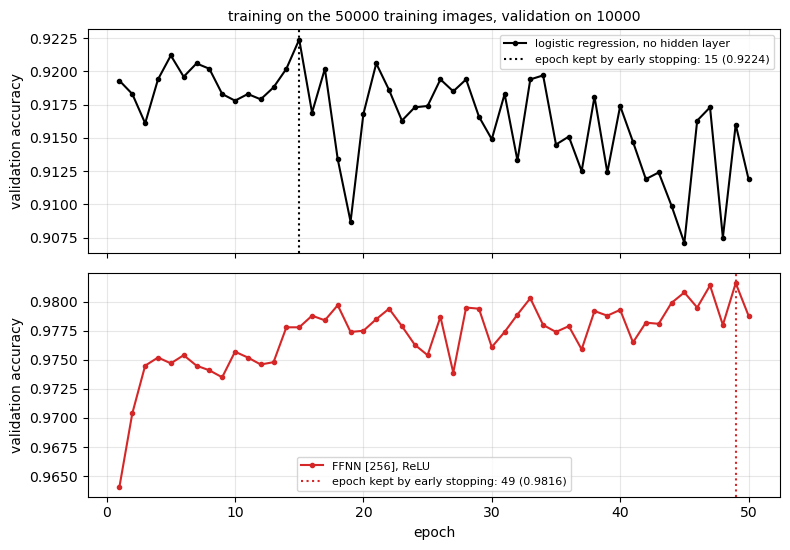

logistic regression, no hidden layer: kept epoch 15, validation accuracy 0.9224   (must equal e.7)
FFNN [256], ReLU: kept epoch 49, validation accuracy 0.9816   (must equal e.7)


In [51]:
# ---- Figure for the report: e.7 redrawn (the histories of final_nets; nothing is retrained) ----
short_e = lambda name: name.replace(" (our code, no hidden layer)", ", no hidden layer").replace(" (our code)", "")\
                           .replace("relu", "ReLU").replace("leaky_ReLU", "leaky ReLU")  # model names without "our code"
fig, axes = plt.subplots(2, 1, figsize=(8, 5.6), sharex=True)
for ax, (name, (net, hist)), color in zip(axes, final_nets.items(), ["k", "C3"]):
    ax.plot(hist["epoch"], 1 - np.array(hist["val_err"]), "o-", ms=3, color=color, label=short_e(name))
    ax.axvline(hist["best_epoch"], ls=":", color=color,
               label=f"epoch kept by early stopping: {hist['best_epoch']} ({CLS[name]['val']:.4f})")
    ax.set_ylabel("validation accuracy"); ax.grid(alpha=0.3); ax.legend(fontsize=8, loc="best")
axes[0].set_title("training on the 50000 training images, validation on 10000", fontsize=10)
axes[-1].set_xlabel("epoch")
plt.tight_layout()
save_figure(fig, "e7_final_models")
plt.show()
for name, (net, hist) in final_nets.items():
    print(f"{short_e(name)}: kept epoch {hist['best_epoch']}, validation accuracy {CLS[name]['val']:.4f}   (must equal e.7)")

#### e.8 Confusion matrices, precision, recall and $F_1$
**Source:** the confusion matrix and the measures read off it, lecture notes Section 5.12, Eqs. (5.67) to (5.70);
`confusion_matrix_multiclass` and `per_class_from_confusion` of `exercisesweek43_solutions.ipynb`, exercise 3 (rows are the
true digit, columns the predicted one; recall = row, precision = column); `ConfusionMatrixDisplay` as in
`exercisesweek43.ipynb`.
**Modifications:** our two final models side by side, so that the matrix shows which errors the hidden layer removes; our
handmade matrix is checked against `sklearn.metrics.confusion_matrix`, and the per class scores against
`classification_report`.
> **LLM note:** Written with Claude (Level 4), adapted from `exercisesweek43_solutions.ipynb` and `exercisesweek43.ipynb`.

logistic regression (our code, no hidden layer): 759 errors on 10000 test images
   precision: [0.963 0.96  0.907 0.907 0.933 0.899 0.95  0.922 0.862 0.932]
   recall:    [0.97  0.979 0.92  0.902 0.928 0.865 0.938 0.921 0.906 0.9  ]
   F1:        [0.966 0.969 0.913 0.905 0.931 0.882 0.944 0.922 0.883 0.916]   macro F1 0.9231
   most frequent confusions (true -> predicted: count): 5 -> 3: 41, 2 -> 8: 30, 5 -> 8: 30, 7 -> 2: 30, 9 -> 7: 30, 3 -> 2: 28
FFNN [256], relu (our code): 194 errors on 10000 test images
   precision: [0.987 0.991 0.986 0.96  0.987 0.993 0.978 0.975 0.97  0.98 ]
   recall:    [0.992 0.993 0.98  0.988 0.98  0.965 0.987 0.976 0.972 0.97 ]
   F1:        [0.989 0.992 0.983 0.974 0.983 0.979 0.983 0.975 0.971 0.975]   macro F1 0.9805
   most frequent confusions (true -> predicted: count): 5 -> 3: 15, 9 -> 4: 9, 8 -> 3: 8, 4 -> 9: 7, 7 -> 2: 7, 9 -> 3: 6


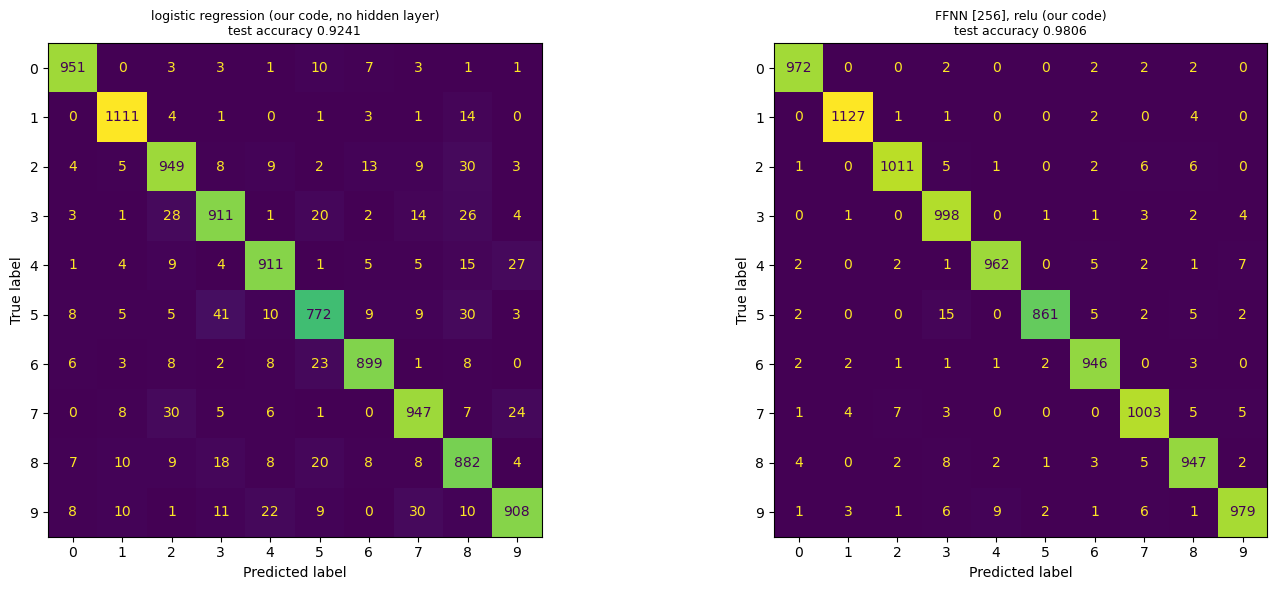

In [52]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix


def confusion_matrix_multiclass(y_true, y_pred, n_classes=10):
    # C[i, j] = number of images of true digit i predicted as digit j (exercisesweek43_solutions.ipynb, exercise 3)
    C = np.zeros((n_classes, n_classes), dtype=int)       # 10 x 10 counts
    np.add.at(C, (np.asarray(y_true), np.asarray(y_pred)), 1)  # add 1 at (true, predicted) for every image
    return C


def per_class_from_confusion(C):
    """
    Precision of class j = C[j, j] / column sum, recall of class i = C[i, i] / row sum, F1 = their harmonic mean.

    LLM-assisted
    ------------
    Tool: Claude (Claude Opus 5.5, claude.ai, October 2026)
    Role: Adapted per_class_from_confusion of exercisesweek43_solutions.ipynb (exercise 3); added the F1 score.
    """
    tp = np.diag(C).astype(float)                         # correct predictions per class (the diagonal)
    precision, recall = tp / C.sum(axis=0), tp / C.sum(axis=1)  # Eq. (5.69): column and row sums
    return precision, recall, 2 * precision * recall / (precision + recall)


fig, axes = plt.subplots(1, 2, figsize=(15, 6))
pred_test = {}                                            # predicted digit of every test image, per model
for ax, (name, (net, _)) in zip(axes, final_nets.items()):
    pred_test[name] = np.argmax(net.predict(x_test), axis=1)  # predicted digit of every test image
    C = confusion_matrix_multiclass(y_test, pred_test[name])  # our matrix
    assert np.array_equal(C, confusion_matrix(y_test, pred_test[name]))  # our matrix equals Scikit-Learn's
    ConfusionMatrixDisplay(C, display_labels=range(10)).plot(ax=ax, colorbar=False, values_format="d")  # drawn
    ax.set_title(f"{name}\ntest accuracy {np.trace(C) / C.sum():.4f}", fontsize=9)
    precision, recall, f1 = per_class_from_confusion(C)   # Eqs. (5.69), (5.70)
    rep = classification_report(y_test, pred_test[name], output_dict=True)  # Scikit-Learn's scores, for the check
    assert np.allclose(f1, [rep[str(k)]["f1-score"] for k in range(10)])  # agrees with Scikit-Learn
    off = C.copy(); np.fill_diagonal(off, 0)              # errors only
    worst = np.dstack(np.unravel_index(np.argsort(-off.ravel())[:6], off.shape))[0]  # six largest errors
    print(f"{name}: {off.sum()} errors on 10000 test images")
    print("   precision:", np.round(precision, 3)); print("   recall:   ", np.round(recall, 3))
    print("   F1:       ", np.round(f1, 3), f"  macro F1 {f1.mean():.4f}")
    print("   most frequent confusions (true -> predicted: count):", ", ".join(f"{i} -> {j}: {off[i, j]}" for i, j in worst))
plt.tight_layout()
plt.show()

#### e.8 Figure for the report
**Source:** `pred_test` of e.8. **Modifications:** one colour scale for both models, set by the largest error, so that the errors stay visible. No new results.
> **LLM note:** Written with Claude (Level 4). New plotting code.

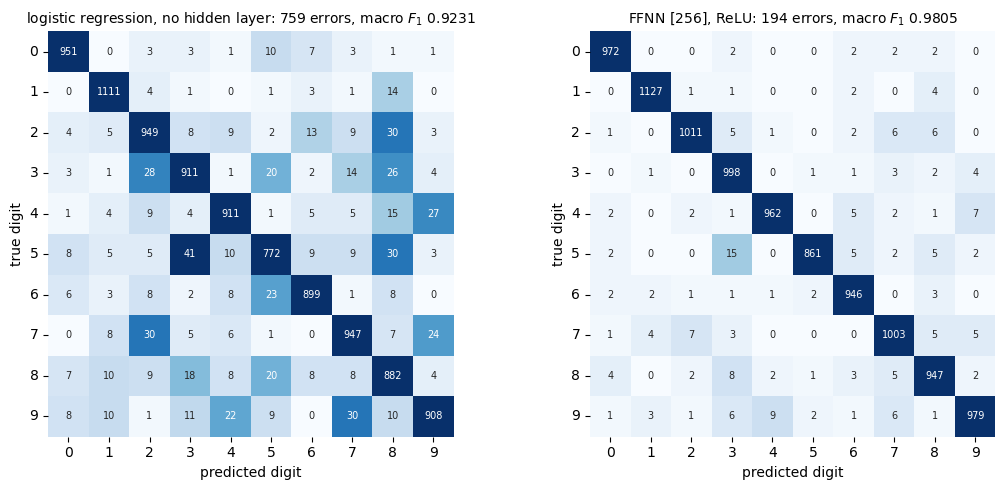

In [53]:
# ---- Figure for the report: e.8 redrawn (pred_test of e.8; nothing is recomputed) ----
mats = {name: confusion_matrix_multiclass(y_test, pred) for name, pred in pred_test.items()}  # the matrices of e.8
vmax_err = max((C - np.diag(np.diag(C))).max() for C in mats.values())  # the largest error of both: one colour scale
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, (name, C) in zip(axes, mats.items()):
    off = C.copy(); np.fill_diagonal(off, 0)              # errors only
    sns.heatmap(C, annot=True, fmt="d", cmap="Blues", vmax=vmax_err, cbar=False, square=True, ax=ax,
                annot_kws={"size": 7})                    # the diagonal saturates; the same scale for both models
    _, _, f1 = per_class_from_confusion(C)                # Eqs. (5.69), (5.70)
    ax.set_title(f"{short_e(name)}: {off.sum()} errors, macro $F_1$ {f1.mean():.4f}", fontsize=10)
    ax.set_xlabel("predicted digit"); ax.set_ylabel("true digit"); ax.tick_params(axis="y", rotation=0)
plt.tight_layout()
save_figure(fig, "e8_confusion_matrices")
plt.show()

#### e.9 Observations (integrated version, notes for the report)
> **LLM note:** Drafted with Claude from the outputs above and from our question-and-answer session with Claude, in
> which we went through part e) step by step (text Level 3 if used as it is). Rewrite in your own words for the report,
> and check every number against your own run. **[own]** marks reasoning that is not taken from the course material.
> Section and equation numbers refer to the lecture notes of 25 October 2026; a.6, b.8, c.6 and d.5 are cited with the
> numbering of their integrated versions.

**What the cells show (e.1 to e.8)**

1. **Setup and baselines (e.1).** The canonical split is used as the project text asks: a stratified validation set of
   10000 images is split off the 60000 training images, the networks are trained on the other 50000 (the scans of e.2
   to e.6 on the first 10000 of them, for 10 epochs), and the 10000 test images are used once, in e.7 (item 11). Always
   predicting the most frequent digit (1) gives 11.24 % on the validation set (e.1) and 0.1135 on the test set (e.7): this,
   and not 0, is the floor every accuracy below should be compared with (item 12; takeaway 9).

2. **Logistic regression as our network without hidden layers (e.2).** On the reduced set the best validation accuracy is
   0.9103 ($\gamma=10^{-2}$, $\lambda=0$). $\gamma=10^{-4}$ is too slow (0.8283 or 0.8284 for every $\lambda$), $\gamma=0.1$ is
   worse (0.8844) and, there, also sensitive to the penalty (0.8055 at $\lambda=10^{-3}$). The $L_2$ penalty never helps
   (at $\gamma=10^{-2}$: 0.9103, 0.9102, 0.9095 and 0.9028 for $\lambda=0$ to $10^{-3}$): the errors of the linear model
   come from bias, not from variance, so a penalty has nothing to remove (item 13). In the report figure (e.2, figure
   for the report) the selected cell is framed in red and the colours saturate below 0.88, so that the good cells
   stay distinct; every value is written in its cell.

3. **Gradient methods and learning rates (e.3; one hidden layer of 128 ReLU nodes, $M=128$, 10 epochs).** Best
   validation accuracy: plain SGD 0.9521 at $\gamma=1$, RMSprop 0.9529 at $10^{-3}$, Adam 0.9555 at $10^{-2}$. (i) The
   three best values differ only in the third decimal, by amounts comparable to the standard error of one accuracy
   on 10000 validation images, about 0.002 (setup of part e): with a good learning rate every method works. (ii) The good learning
   rates are very different: plain SGD needs the largest ($\gamma=1$), the adaptive methods much smaller
   ones ($10^{-3}$ for RMSprop, $10^{-2}$ for Adam). Plain SGD moves every weight by $\gamma$ times its minibatch gradient (Eqs. (4.15) and (4.37)); RMSprop takes a step of fixed length
   about $\gamma$ near a minimum (Eq. (4.66)); Adam's first step has length $\gamma$ whatever the gradient, and every
   step is at most about $\gamma$ (Section 4.11, Eq. (4.72)). So $\gamma=1$ destroys the adaptive methods (0.2058 and
   0.1042, figure), while it is the best plain SGD. (iii) For plain SGD $\gamma=1$ is the largest learning rate of the grid and
   the accuracy is still rising there (0.8730, 0.9309, 0.9521 for $\gamma=10^{-2}$, $0.1$, 1; figure), so 0.9521 is a lower
   bound for plain SGD. Adam at $\gamma=10^{-2}$ is selected, by a margin that is within the noise (item 14). In the
   report figure (e.3, figure for the report) the selected cell is framed in red and the best learning rate of plain
   SGD and of RMSprop in white; the colours saturate below 0.9, and every value is written in its cell.

4. **Learning rate and penalty (e.4).** Best: $\gamma=10^{-2}$ without penalty (0.9555). At the two smaller learning
   rates the penalty hardly changes the accuracy up to $\lambda=10^{-4}$ (0.9463 to 0.9467 at $\gamma=10^{-3}$,
   0.9536 to 0.9542 at $3.3\cdot10^{-3}$); at $\gamma=10^{-2}$ every penalty lowers it (0.9532, 0.9468,
   0.9513 and 0.9309 for $\lambda=10^{-6}$ to $10^{-3}$). The learning rate matters far more: from 0.9466 at
   $\gamma=10^{-3}$ to 0.9555 at $10^{-2}$, and down to between 0.8425 and 0.8913 at $\gamma=0.1$. With 10 epochs on 10000
   images this network does not overfit enough for a penalty to pay off, and "the learning rate is by far the most
   important" hyperparameter (Section 8.12). At the larger learning rates the results jump from cell to cell (0.9202 to
   0.9398 at $\gamma=0.03$ for $\lambda\le10^{-4}$, 0.8425 to 0.8913 at $\gamma=0.1$) [own reading]. In the report figure (e.4, figure for the report) the selected
   cell is framed in red; the colours saturate below 0.9, and every value is written in its cell.

5. **Depth and width (e.5).** With one hidden layer the validation accuracy grows with the width (0.9415, 0.9460,
   0.9555, 0.9610 for 32 to 256 nodes). 256 is the largest width of the grid and the row is still rising there; wider
   layers were not tried. Depth does not help in this scan: with two or three layers the accuracy no longer grows
   with the width, and the best deep cells, 0.9524 (two layers of 128 nodes) and 0.9478 (three layers of 64), are both
   below one layer of 128 or 256 nodes. Selected: one layer of 256 nodes (0.9610, 203530 parameters). This holds at the
   learning rate selected for one layer of 128 nodes ($\gamma=10^{-2}$, e.3 and e.4) and for 10 epochs: e.6 shows that one
   layer of 256 ReLU nodes prefers $\gamma=3.3\cdot10^{-3}$ (0.9634 against 0.9610), and the curves of e.6 are still
   rising at epoch 10 (figure). The same caveat holds for the
   depth maps of c.2 (c.6, item 3 (ii)). Many neighbouring cells are close to each other (for example 0.9524 and
   0.9504, or 0.9478 and 0.9458).

6. **Activations (e.6).** Every activation gets its own learning rate, as in c.1 and in the course example (which uses
   $\gamma=0.5$ for the sigmoid and $0.1$ for the ReLU). With one hidden layer of 128 nodes the three activations are equal
   within the noise: 0.9554 for the sigmoid, 0.9555 for the ReLU and 0.9542 for the leaky ReLU, as in the course example
   (97.5 % against 97.6 % after 20 epochs on all images) and as Section 8.14 explains: "With only one hidden layer the
   vanishing-gradient argument of Section 8.9 has little room to operate". With one layer of 256 nodes the sigmoid is
   behind: 0.9568 against 0.9634 for the ReLU and 0.9624 for the leaky ReLU, by more than the standard error of one
   accuracy (about 0.002). The best learning rate of the sigmoid is $10^{-2}$ in both networks; that of the ReLU is
   $10^{-2}$ with 128 nodes and $3.3\cdot10^{-3}$ with 256, that of the leaky ReLU $3.3\cdot10^{-3}$ in both. ReLU and
   leaky ReLU are equal within one standard error at [256], as in Table 8.2 of the lecture notes (Section 8.6.4); the
   ReLU is selected (0.9634 against 0.9624), by a margin smaller than that standard error, with $\gamma=3.3\cdot10^{-3}$. This is the smallest learning rate of the
   grid of e.6 ($\gamma/3$ to $10\gamma$), and it becomes the learning rate of the final network: smaller values were
   not tried. In the report figure (e.6, figure for the report) panel (a) shows the validation accuracy of every width
   and activation at every learning rate, with the best learning rate of each row framed in white and the selected
   network in red; panels (b) and (c) show the validation accuracy after every epoch at the best learning rate, one
   panel per width, on a scale from 0.90 to 0.97.

7. **The selected models on the test set (e.7).** Test accuracy ± one standard error:
   - our logistic regression: 0.9241 ± 0.0026 (best validation accuracy 0.9224 at epoch 15, training accuracy 0.9347,
     8 s for 50 epochs);
   - our network [256], ReLU, Adam with $\gamma=3.3\cdot10^{-3}$: **0.9806 ± 0.0014** (best validation 0.9816 at epoch 49,
     training accuracy 0.9990, 366 s for 50 epochs);
   - Scikit-Learn's `MLPClassifier`, same architecture, activation and optimiser: 0.9790 ± 0.0014 (299 s, table of
     part f);
   - Scikit-Learn's `LogisticRegression` of the starter cell (saga, all 60000 images, 511 epochs, 10 to 14 minutes):
     0.9257 ± 0.0026.

   (i) **Hidden layer against the baseline.** The network reaches 0.9806 against 0.9241 for our logistic regression,
   a difference far larger than their standard errors (0.0014 and 0.0026), and makes 194 errors instead of 759 (e.8). This is what a hidden
   layer is worth on MNIST: a classification network is logistic regression on features learned by the hidden layers
   (Section 8.11), while logistic regression must work with the raw pixels.
   (ii) **Our code against Scikit-Learn.** Our logistic regression and the starter cell agree within one standard error
   (0.9241 against 0.9257), although ours stops at epoch 15 on 50000 images and the saga solver runs 511 epochs on 60000;
   our network and `MLPClassifier` agree within their standard errors (0.9806 ± 0.0014 against
   0.9790 ± 0.0014). The implementation is at the level of an established library (takeaway 10; Section 8.14).
   (iii) **Overfitting and early stopping.** The network has a training accuracy of 0.9990 against a best validation
   accuracy of 0.9816; this gap is discussed in item 15. From epoch 15 to 50 its validation accuracy
   oscillates between about 0.974 and 0.982 (figure), with a slight upward drift: it fits almost all training images
   without losing accuracy on new ones. Early stopping keeps epoch 49 of 50 (0.9816), one of several peaks of similar
   height; the kept epoch is at the end of the budget, so early stopping did not stop anything here; more epochs
   were not tried. The test accuracy (0.9806) is close to that validation value, within one
   standard error. In the report figure (e.7, figure for the report) the two models are drawn in separate panels,
   each with the epoch kept by early stopping and its validation accuracy. The validation curve of the logistic regression jumps between 0.907 and 0.922 from epoch to epoch (figure):
   with a constant learning rate and minibatches the iterate keeps moving around the minimum (Eq. (4.51)), and early
   stopping picks one of those values [own reading]. Its test accuracy (0.9241) is not below the selected validation
   value, so the selection did not make it optimistic.
   (iv) **Baselines (takeaway 9):** guessing 0.1135, logistic regression 0.9241, our network 0.9806; convolutional networks,
   which use the two dimensional structure of the images that a dense network ignores, reach above 99 %.

8. **The confusion matrices (e.8).** Rows are true digits, columns predictions (Section 5.12). *Logistic regression:*
   the hardest digit is 5 (recall 0.865; 41 fives are read as 3 and 30 as 8), and 8 is the most frequent wrong answer
   (precision 0.862: many 2s, 3s and 5s are predicted as 8); the largest confusions are 5→3 (41), 2→8, 5→8, 7→2 and 9→7
   (30 each), 3→2 (28); macro $F_1$ 0.9231. A linear model scores every digit with one weight vector of 784 pixels,
   $z_k=\boldsymbol x^T\boldsymbol\theta_k+b_k$ (Eq. (5.27)), that is with one template per digit, so digits with
   overlapping templates (3, 5, 8; 4 and 9; 7 and 2) are confused [own reading]. *Network:* precision and recall of every
   digit are between 0.96 and 0.993 (macro $F_1$ 0.9805). The remaining confusions are the same kind of pairs, 5→3 (15),
   9→4 (9), 8→3 (8), 4→9 and 7→2 (7), 9→3 (6), but much rarer: 5→3 falls from 41 to 15, 2→8 from 30 to 6, 5→8 from 30 to 5,
   7→2 from 30 to 7 and 9→7 from 30 to 6. The accuracy alone would hide all of this.

9. **Caveats [own].** The hyperparameters were chosen with 10000 images and 10 epochs and then used with 50000 images and
   up to 50 epochs; they were not scanned again in that setting. Three choices sit on the edge
   of their grid: plain SGD at $\gamma=1$ (e.3), the width of 256 nodes (e.5) and the learning rate $3.3\cdot10^{-3}$ of
   the final network (e.6); the final network also kept the last but one of its 50 epochs (e.7). Every network was
   trained from one initialisation, and neighbouring cells of the scans in e.3 to e.6 often differ only in the third
   decimal, so only the large effects (the learning rate, a hidden layer against none) are firm.

**The concepts behind part e) (our discussion)**

10. **The quantities of part e).** The output layer has 10 softmax nodes (Eq. (5.27)), the cost is the multiclass cross
    entropy with one hot targets (Eq. (5.28)), and the pair gives $\boldsymbol\delta^L=(\boldsymbol a^L-\boldsymbol y)/n$
    (Eq. (8.69), Section 8.11; a.6, item 2); the predicted digit is the one with the largest probability. Logistic
    regression is the network [784, 10], with $784\times10$ weights and 10 biases, 7850 parameters (e.7); its cost is convex (Section 5.4, shown
    there for two classes). The accuracy is Eq. (5.68); it is a mean of zeros and ones, so its standard error is
    $\sqrt{p(1-p)/n}$ (Section 2.5; the same computation in Section 8.6.4): on the 10000 test images 0.0026 for the logistic
    regression (0.9241) and 0.0014 for the network (0.9806), e.7. In the confusion matrix the recall of a digit is read along its row and its precision down
    its column (Eq. (5.69)), and $F_1$ is their harmonic mean, "small unless both are large" (Eq. (5.70)). The minibatch
    size $M=128$ is the best one of Table 4.3 (Section 4.7.9), and with a constant learning rate the iterate settles in a
    cloud around the minimum whose cost is proportional to $\gamma/M$ (Eq. (4.51)).

11. **The test set used once, and why the starter cell does not break this.** The project text asks that all training,
    model selection and tuning use the training data only, and that "the test set is used once, at the very end, to
    report the performance of the models you have selected". The lecture notes give the same recipe: "Set aside a test
    set and do not look at it again" until the end, and the test set is touched "once, to report the generalisation
    error of the completed procedure" (Section 3.14); hyperparameters are chosen on a validation set, "never on the test
    set" (Section 8.12). The reason: a number used to make a choice is no longer an honest estimate, because the choice
    favours whatever happened to score well on those particular images; "the test set is a test set only as long as it
    has been used once" (Section 3.14). The starter cell of Scikit-Learn's `LogisticRegression` evaluates the test set
    early in the notebook, but it does not select anything: it is the course's code copied unchanged, with
    Scikit-Learn's default settings (an $L_2$ penalty with $C=1$), trained on the 60000 training images only, and no
    later choice uses its test accuracy; the variable is read only in e.7, where it is reported next to the other models.
    Our own models are fixed entirely on the validation set (e.2 to e.6) and only then evaluated on the test set, once
    each; `MLPClassifier` takes our settings and our best validation epoch. Reporting several fixed models on the same
    test set is allowed; choosing among them by their test accuracy would not be, and we do not: the network was
    selected on the validation set (0.9816 against 0.9224) [own reading].

12. **Why the most frequent digit is the floor.** A classifier that does not look at the image can only give the same
    answer, or a random one, for every image. Its expected accuracy is then at most the share of the most frequent
    class, reached by always answering that class [own reading]. In MNIST the classes are almost but not exactly
    balanced: always predicting the digit 1 gives 11.24 % on the validation images (e.1) and 0.1135 on the test images
    (e.7), more than the 10 % of a uniform guess (e.1). So 0.1135 is the score obtained for free, and only what a model gets above it comes from the pixels:
    "Always compare an accuracy against the proportion of the majority class, which is the score obtained for free"
    (Section 5.12). With unbalanced classes the free score can be very high, which is why Section 5.12 warns that an
    accuracy alone can mislead.

13. **Bias, not variance, in the logistic regression, and what follows.** In the decomposition of Section 2.10 (stated
    for continuous predictions, whose intuition "carries over to classification"), the bias "is the error caused by the
    simplifying assumptions built into the model: a straight line fitted to curved data has a large bias, and no
    quantity of data will remove it", while the variance "measures how much the prediction moves when the training set
    is redrawn". The logistic regression shows the signature of bias [own reading]. (i) It does not even fit the training
    images: 0.9347 on the images it was trained on, close to the 0.9224 of the validation set, whereas a model
    limited by variance fits its training set much better than new data (the network: 0.9990 against 0.9816, item 15).
    (ii) More data change little: 0.9103 on the validation set after 10 epochs on 10000 images (e.2), 0.9224 with 50000
    images (e.7), and 0.9257 on the test set for Scikit-Learn with all 60000 images. (iii) The $L_2$ penalty, which
    trades a little bias for less variance (Sections 2.10 and 8.12), only lowers the accuracy (item 2): there is no
    variance for it to remove. With 7850 parameters and 50000 images the model has plenty of data per parameter; what
    limits it is its form, one linear score per digit (item 8). What follows: to do better, regularisation or more data
    will not help, a more flexible model will; the hidden layer of the network lowers the bias (0.9806 against 0.9241,
    item 7 (i)), at the price of a larger variance (item 15) [own reading].

14. **Adam or RMSprop: the choice of e.3.** In e.3 Adam (0.9555 at $\gamma=10^{-2}$) and RMSprop (0.9529 at $10^{-3}$)
    are close (item 3), so e.3 alone does not choose between them. That the best learning rate of RMSprop is smaller
    ($10^{-3}$ against $10^{-2}$) is not a disadvantage in itself: each method has
    its own scale, as each activation had in c.1. Both take steps of about $\gamma$ per weight (Eqs. (4.66) and (4.72)),
    but near a minimum they behave differently: at a constant learning rate RMSprop keeps a step of fixed length and
    "ends in a limit cycle of amplitude of order $\gamma$" (Section 4.10), while for Adam the averaged gradient becomes
    small and "the fixed-length step of Eq. (4.66) has been averaged away" (Section 4.11). This fits e.3: RMSprop at the
    learning rate of Adam, $10^{-2}$, drops to 0.9381, while Adam at the learning rate of RMSprop, $10^{-3}$, still gives
    0.9466 [own reading]. b.6 points the same way: Adam had the widest range of good learning rates ($\gamma=3.2\cdot10^{-3}$ to $0.32$), and
    RMSprop was erratic at the larger ones (b.8, item 6). Choosing RMSprop would have moved every later scan to learning
    rates around $10^{-3}$ (e.4 scans around the best learning rate of e.3), and the final network would have been
    trained for 50 epochs at a constant learning rate with the method that cannot settle. We keep Adam on these grounds;
    we did not train RMSprop beyond e.3, so we cannot claim that it would have been worse [own reading].

15. **The gap between training and validation accuracy of the network.** The network has a training accuracy of 0.9990 on its
    50000 training images against a best validation accuracy of 0.9816 on the 10000 validation images (e.7).
    (i) The training accuracy is optimistic: the network has seen those images, and a flexible model always fits its
    training data better (Section 3.14, Eq. (3.91)). The gap is the variance of Section 2.10, the part of the fit that
    belongs to this particular sample of images; Section 8.14 shows the same picture on the digits data (Fig. 8.15): the
    training accuracy goes on to unity while the test accuracy reaches a plateau, and "the gap between the two curves is
    the variance term of Eq. (2.52)". (ii) The gap is not harmful overfitting here: overfitting in the sense of Sections
    4.7.8 and 8.12 is a validation curve that rises in error while the training error still falls, and the validation
    accuracy of the network does not fall over the 50 epochs (item 7 (iii)); fitting the training set ever better did not
    cost accuracy on new images. (iii) The comparison with the logistic regression is the bias–variance trade off of
    Section 2.10: the logistic regression has a small gap (training 0.9347, validation 0.9224) but a large bias, the
    network a larger gap (0.9990 and 0.9816) but a much higher validation accuracy; lowering the bias was worth far
    more than the variance it cost. (iv) A gap means there is variance left that a regulariser could remove; in our scans
    of e.4 (10 epochs on 10000 images) the $L_2$ penalty did not help, and the final 50 epoch network was not scanned
    again for $\lambda$ (item 9) [own reading].

16. **Points to state precisely in the report and the oral [own].** The test set is used once per selected model, and
    the starter logistic regression selects nothing (item 11). The floor is 0.1135 on the test set, the share of the most
    frequent digit, not 0 and not the 10 % of a uniform guess (item 12). The logistic regression is limited by bias, so a penalty cannot help it; the network
    lowers the bias at the price of some variance (items 13 and 15). Adam and RMSprop are tied in e.3; Adam is kept for
    the reasons of item 14, not because of its small lead in e.3. The network (0.9806) is far above the logistic
    regression (0.9241), the one firm result of part e), and equal to `MLPClassifier` within the noise (item 7). Depth did not
    help at the learning rate and the 10 epochs of e.5, which is not the same as "depth does not help" (item 5). The final
    learning rate, the width and the kept epoch sit on the edge of what was tried (item 9). Every number comes from one
    seed.

### Part f): Critical evaluation of the various algorithms

After all these glorious calculations, you should now summarize the various algorithms and come with a critical evaluation of their pros and cons. Which algorithm works best for the regression case and which is best for the classification case? Section [8.15](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#limitations-and-a-top-down-view) of the lecture notes gives a top-down view of what neural networks can and cannot do that you may find useful here. These codes can also be part of your final project 3, but now applied to other data sets.


## Code for part f): all results side by side, and a critical evaluation

**Source:** the numbers collected in the dictionaries `REG` (parts b to d) and `CLS` (part e); the top down view of what
neural networks can and cannot do is Section 8.15 of the lecture notes. **Modifications:** none; this cell only prints.
> **LLM note:** Written with Claude Opus 5.5 (claude.ai, October 2026) at Level 4. New code.

In [54]:
# Your code for part f) here
print("REGRESSION, Runge function, n = 100, sigma = 0.1, 80 training / 20 test points (sorted by the CV MSE)")
print(f"{'model':70s} {'CV MSE':>8s} {'s.e.':>7s} {'test MSE':>9s} {'s.e.':>7s} {'MSE to f':>9s} {'param.':>7s}")
for name, r in sorted(REG.items(), key=lambda item: item[1]["cv"]):
    print(f"{name:70s} {r['cv']:8.4f} {r['cv_se']:7.4f} {r['test']:9.4f} {r['test_se']:7.4f} {r['f_mse']:9.5f} {r['n_par']:7d}")
print(f"\nnoise floor sigma^2 = {0.1**2:.4f}")

fmt = lambda v, f: "-" if v is None or (isinstance(v, float) and np.isnan(v)) else format(v, f)  # "-" for missing values
print("\nCLASSIFICATION, MNIST, 10000 test images (sorted by the test accuracy)")
print(f"{'model':52s} {'test acc.':>9s} {'s.e.':>7s} {'param.':>8s} {'epochs':>7s} {'seconds':>8s}")
for name, r in sorted(CLS.items(), key=lambda item: -item[1]["test"]):
    print(f"{name:52s} {r['test']:9.4f} {fmt(r['test_se'], '.4f'):>7s} {r['n_par']:8d} {r['epochs']:7d} "
          f"{fmt(r['seconds'], '.0f'):>8s}")

REGRESSION, Runge function, n = 100, sigma = 0.1, 80 training / 20 test points (sorted by the CV MSE)
model                                                                    CV MSE    s.e.  test MSE    s.e.  MSE to f  param.
FFNN [100, 100], sigmoid (part b)                                        0.0168  0.0036    0.0116  0.0043   0.00104   10401
FFNN [5, 5], sigmoid (part c)                                            0.0171  0.0038    0.0133  0.0047   0.00100      46
FFNN [100, 100], leaky_relu (part c)                                     0.0172  0.0034    0.0118  0.0039   0.00158   10401
FFNN [25], relu (part c)                                                 0.0173  0.0036    0.0168  0.0056   0.00147      76
FFNN [50, 50], sigmoid (part b)                                          0.0173  0.0038    0.0136  0.0049   0.00084    2701
FFNN [50, 50, 50, 50], relu, L2, lambda = 0.001 (part d)                 0.0173  0.0038    0.0145  0.0049   0.00168    7801
FFNN [100], sigmoid (part b)  

#### f.1 Critical evaluation (integrated version, notes for the report)
> **LLM note:** Drafted with Claude from the outputs of parts b) to e), from the Observations a.6, b.8, c.6, d.5 and e.9
> and from our question-and-answer session with Claude (text Level 3 if used as it is). Rewrite in your own words for
> the report, and check every number against your own run. Every number is printed by a cell of this notebook, read
> from one of its figures, set in its code, or taken from the course material. **[own]** marks reasoning that is not
> taken from the course material. Section and equation numbers refer to the lecture notes of 25 October 2026.

**Which method works best (the table of cell 90 and parts b to e)**

1. **Regression.** The ten networks, nine of ours and `MLPRegressor`, have CV MSEs between 0.0168 and 0.0181 and MSEs to
   $f$ between 0.00081 and 0.00168; the polynomial models have CV MSEs between 0.0217 and 0.0273 and MSEs to $f$ between
   0.00480 and 0.00710 (cell 90). Paired on the same folds and test points, one layer of 50 sigmoid nodes against OLS of
   degree 8 gives $-0.0092\pm0.0068$ in CV, better in 4 of the 5 folds, and $-0.0054\pm0.0028$ on the test set (b.7).
   Among the networks the measures do not agree on a winner: the lowest CV MSE is the [100, 100] sigmoid network
   (0.0168), the lowest test MSE too (0.0116), but the lowest MSE to $f$ is `MLPRegressor` (0.00081), so the data do not
   separate the networks, and we would choose a small one [own reading]: one layer of 50 sigmoid nodes trained with full
   batch Adam, $\gamma=10^{-2}$, 1000 epochs (b.6, b.7), or two layers of 5 sigmoid nodes, 46 parameters, which do as
   well (c.5). The one standard error rule of Section 3.14 (Eq. (3.96)), applied to the architecture, would go further,
   to one layer of 5 sigmoid nodes (CV MSE 0.0175, c.2), which we did not evaluate on the test set (c.6, item 2). The
   networks win because of the basis, not the method: degree 8 cannot reach the top of the peak (b.8, item 9), and a
   penalty cannot change that: Ridge and Lasso of Project 1 have CV MSEs of 0.0273 and 0.0264, and Ridge selected by CV
   on the training data (degree 11, CV MSE 0.0217) has the largest MSE to $f$ of all models, 0.00710 (d.3; d.5, items 4
   and 13; takeaway 8). With 80 training and 20 test points and one seed the evidence is moderate (b.8, item 18).

2. **Classification.** One hidden layer of 256 ReLU nodes, trained with Adam ($\gamma=0.00333$, minibatches of 128, up to
   50 epochs, the epoch with the best validation accuracy kept): test accuracy 0.9806 ± 0.0014, against 0.9241 ± 0.0026
   for our logistic regression and 0.9257 ± 0.0026 for Scikit-Learn's, with 194 errors on the 10000 test images against
   759 (cell 90; e.8). The difference is far larger than the standard errors. The network and `MLPClassifier`
   (0.9790 ± 0.0014) agree within their standard errors, and so do the two logistic regressions (e.9, item 7). The
   network was selected on the validation set (0.9816 against 0.9224 for the logistic regression), not on the test set,
   which was used once for each selected model (e.9, item 11). Every accuracy is to be read against 0.1135, the score of
   always predicting the most frequent digit (e.9, item 12).

3. **Gradient methods and learning rates.** *Plain gradient descent* moves every parameter by $\gamma$ times its
   gradient (Eq. (4.15)), so it crawls where the cost is flat: with full batches on the regression problem the CV MSE
   stays between 0.0834 and 0.1031, close to predicting the mean, for every $\gamma\le3.2\cdot10^{-2}$, only $\gamma=0.1$
   reaches 0.0301, $\gamma=0.32$ is back at 0.0965 and $\gamma=1$ diverges (b.6; b.8, item 5); on the deep sigmoid
   network of c.4 it only learns the mean (training MSE 0.0939; the variance of $y$ is 0.0938, b.5). *SGD* makes several updates per
   epoch for the same arithmetic (Eq. (4.38)), with noisy curves and a plateau proportional to $\gamma/M$ (Eq. (4.51));
   on the 80 regression points an epoch takes longer than with full batches (0.45 to 0.55 against 0.16 to 0.17 ms, b.6),
   because the overhead of each call dominates (Section 4.7.2), and on MNIST we use minibatches of 128 (e.1).
   *RMSprop* keeps a step of fixed length near a minimum (Eq. (4.66)) and at a constant learning rate "ends in a limit
   cycle of amplitude of order $\gamma$" (Section 4.10): its CV MSE after a fixed number of epochs depends on where the
   last epoch falls, as the value 0.1253 at $\gamma=3.2\cdot10^{-2}$ between 0.0313 and 0.0213 shows (b.6; b.8, item 6).
   *Adam*'s first step has length $\gamma$ whatever the gradient and every step is at most about $\gamma$ (Section 4.11,
   Eq. (4.72)): it has the widest range of good learning rates (full batch CV MSE between 0.0175 and 0.0184 from
   $\gamma=3.2\cdot10^{-3}$ to 0.32, b.6) and trains the deep sigmoid network that plain gradient descent cannot move
   (training MSE 0.0117 after 1000 epochs, c.4). On MNIST the best values of the three methods are close (plain SGD
   0.9521 at $\gamma=1$, RMSprop 0.9529 at $10^{-3}$, Adam 0.9555 at $10^{-2}$, e.3), while the learning rate moves the
   validation accuracy from 0.1042 to 0.9555 within the same scan (e.3,
   figure): "the learning rate is by far the most important"
   hyperparameter (Section 8.12). Adam and RMSprop are tied in e.3; we keep Adam for its range of good learning rates
   and because RMSprop cannot settle at a constant learning rate (e.9, item 14). For a new problem, Adam with $\gamma$
   between $10^{-3}$ and $10^{-2}$ is the safest start in our runs: it gave the lowest CV MSE in b.6 (0.0175 ± 0.0038)
   and the highest validation accuracy in e.3 (0.9555) [own reading].

4. **Activations, architecture and regularisation.** *Regression:* the best networks of the three activations are
   equal within the noise (CV MSE 0.0171, 0.0173 and 0.0172, c.2), as Section 8.6.4 (Table 8.2) finds; the sigmoid map
   is flat (20 of 20 architectures within one standard error of the best), the ReLU and leaky ReLU maps are not (15 and
   13 of 20), and for the ReLU a second layer helps a narrow network (5 nodes: 0.0293 to 0.0178) but hurts at 50 nodes
   (0.0175 to 0.0237), at the learning rate of c.1 and for 1000 epochs (c.6, items 3 and 9). In depth the sigmoid trains
   only with an adaptive optimiser (c.4), which is why "ReLU is a sound default and the right thing to try first"
   (Section 8.6.4). *MNIST:* with one hidden layer of 128 nodes the three activations are equal within the noise (0.9554,
   0.9555 and 0.9542), with 256 nodes the sigmoid is behind (0.9568 against 0.9634 and 0.9624) (e.6); in e.5 width helped
   and depth did not, at the learning rate selected for 128 nodes and for 10 epochs, and 256 nodes is the widest network
   tried (e.9, item 5). *Regularisation:* the $L_2$ and $L_1$ penalties repair networks that are too large (four layers of
   50 ReLU nodes: CV MSE 0.0246 without penalty, 0.0182 and 0.0175 with $\lambda=10^{-3}$, d.1) but do not beat the best
   unpenalised networks (the sigmoid networks of b.7: 0.0168 to 0.0175; d.5, item 5); on MNIST the $L_2$ penalty did not
   help in our scans (e.2, e.4). $L_2$ shrinks the weights ($\sum w^2$ from 439.853 to 110.639, d.4), $L_1$ leaves many
   very small weights but no exact zeros, because our training takes subgradient steps (d.5, items 6 and 10). Early
   stopping is "the single most effective and cheapest regulariser available" (Section 8.12): in c.3 the four layers of
   100 ReLU nodes reach their lowest validation MSE at epoch 125 (0.0183), against 0.0251 at 1000 epochs. In e.7 the
   network kept epoch 49 of 50, so there early stopping did not stop anything (e.9, item 7).

**Pros and cons (Section 8.15 against our results)**

5. **The network for regression.** *Pros:* no basis has to be chosen; the hidden layer learns its own features from the
   raw $x$ (takeaway 1; b.8, item 14) and follows the narrow peak and the flat tails at the same time (figures of b.7,
   c.5 and d.3); with the sigmoid the result hardly depends on the architecture (c.2). *Cons*, the limitations of
   Section 8.15 as they appear here: it is "computationally expensive to train" and needs a learning rate, an optimiser,
   a number of epochs and an architecture, each chosen by cross validation (the scans of b.6 and c.2 alone took 68 s and
   120 s); "the optimisation is non-convex, so results depend on initialisation and on the random seed" (Section 8.15;
   Section 8.7), and single cells of our maps are not trends (the [50, 50] ReLU network at 0.0237, c.6, item 3 (iii)); it
   is "largely uninterpretable": the 151 parameters of the [50] network come with no standard errors (b.8, item 12);
   and networks "extrapolate unpredictably outside the range of the training data", which we did not test.

6. **OLS, Ridge and Lasso.** *Pros:* a closed form (OLS, Ridge) or a convex problem solved by coordinate descent
   (Lasso, Section 3.9); "for a linear model with modest $p$ the closed form is the cheapest option of all"
   (Section 4.7.2); deterministic, with one hyperparameter for OLS (the degree), and interpretable: the coefficients come
   with known variances (Eqs. (3.32) and (3.34); b.8, item 12). *Cons here:* the basis, not the method. Degree 8 cannot
   reach the top of the peak and oscillates near the edges (figure of b.7), the selected degree depends on which points
   the folds contain (degree 8 here, degree 11 in our Project 1 report; b.8, item 1), and a penalty removes variance but
   cannot give the polynomial basis the shape of the peak (d.5, item 13). Takeaway 8 calls a polynomial of well chosen
   degree a hard to beat benchmark for a smooth function of one variable; for the Runge function and 80 noisy points no
   degree is well chosen (b.8, item 12). With features adapted to the problem a linear model can win again: in the Ising
   example of Section 8.16 a network cannot find the answer from four hundred configurations, while the Lasso, "given
   features a physicist chose", reaches $R^2=0.99996$ (Section 8.15).

7. **The network for classification against logistic regression.** *Network, pros:* far more accurate (item 2); a
   classification network is logistic regression on features learned by its hidden layers (Section 8.11), and the
   confusions between similar digits become much rarer (5→3 from 41 to 15, 2→8 from 30 to 6, 7→2 from 30 to 7; e.8).
   *Network, cons:* 203530 parameters against 7850 (cell 90), 366 s against 8 s for 50 epochs (e.7), a search over the
   optimiser, the learning rate, the penalty, the architecture and the activation (e.3 to e.6), no interpretable
   weights, and a gap between training and validation accuracy (0.9990 against 0.9816), the variance of Section 2.10,
   which here does not lower the validation accuracy over the epochs (e.9, item 15). *Logistic regression:* a convex
   problem (Section 5.4, shown there for two classes), fast, with one weight vector per digit that can be looked at as
   an image (e.9, item 8); but it is limited by bias: it does not even fit its own training images (0.9347 against 0.9224
   on the validation set), and a penalty only lowers its accuracy (e.9, item 13). A convolutional network, which uses
   the two dimensional structure of the images, would be the next step, above 99 % (takeaway 9).

**How firm the conclusions are**

8. **What the numbers can and cannot carry [own].** Every network result comes from one initialisation; the regression
   data set has 100 points (80 for training and model selection, 20 for the test); the MNIST scans used 10000 images
   and 10 epochs. Several choices sit on the edge of what was tried: $\gamma=10^{-3}$ in d.2, plain SGD at $\gamma=1$
   in e.3, the width of 256 nodes in e.5 and the learning rate $0.00333$ of the final network in e.6 (d.5, item 3; e.9,
   item 9). We report standard errors everywhere and do not interpret differences below about one standard error. The
   firm results are the large ones: networks against polynomials in the MSE to $f$, the role of the learning rate,
   sigmoid against ReLU in depth (c.4), and a hidden layer against none on MNIST. To make the rest firmer we would repeat
   the key scans over several seeds, as Table 8.2 of the lecture notes does, use repeated cross validation for the
   regression, and try learning rate schedules (Section 4.7.8) instead of a constant $\gamma$.

9. **Reading the table of cell 90.** (i) The table prints $\sigma^2=0.0100$ as the noise floor; on our realised data
   the true $f$ has an MSE of 0.0150 on the training points and 0.0096 on the test points (b.5), and these are the floors
   to compare the CV and test MSEs with (b.8, item 2). (ii) The column "epochs" of the classification table means three
   different things: the epoch kept by early stopping for our two models (49 and 15), the number of epochs run for
   `MLPClassifier` (49, set equal to our kept epoch), and the iterations of the saga solver for Scikit-Learn's
   logistic regression (511). (iii) The tables are sorted by the CV MSE and by the test accuracy; among the networks this
   order is within the noise (item 1), and the test set reports the selected models, it does not select them (e.9,
   item 11). (iv) The MSE to $f$ is the sharpest comparison of the regression fits, and it exists only because we know
   $f$ (b.8, item 2).

10. **In one sentence [own].** Neural networks were the better tool on both problems, clearly so on MNIST, where the
    features are not known in advance and there are 50000 training images, and narrowly so on the Runge function, where
    they win because polynomials are a poor basis for its peak; they are also the more expensive, the less transparent
    and the less reproducible tools, so the choice should follow the problem, as Section 8.15 concludes: "it argues for
    choosing the method to suit the problem".

11. **Points to state precisely in the report and the oral [own].** For regression the networks are better than the
    polynomials on all three measures, but by moderate evidence, and they are equal among themselves (item 1). For
    classification the network is far better than logistic regression and equal to `MLPClassifier` (item 2). The
    learning rate matters more than the optimiser (item 3). The penalties repair networks that are too large but do not
    beat the right architecture, and early stopping did not stop the final MNIST network (item 4). The pros and cons are
    those of Section 8.15, each shown by one of our results or stated as not tested (items 5 to 7). The noise floor of the
    table is the realised one, not $\sigma^2$ (item 9). Every number comes from one seed (item 8).

## Summary of methods to implement and analyze

**Required implementation:**

1.  Reuse the regression code and results from project 1; these will act as a benchmark for seeing how suited a neural network is for this regression task.

2.  Implement a neural network with

    - a flexible number of layers;

    - a flexible number of nodes in each layer;

    - a changeable activation function in each layer (Sigmoid, ReLU, Leaky ReLU, as well as linear and softmax);

    - a changeable cost function, which will be set to the MSE for regression and the cross entropy for multiclass classification;

    - an optional $L_1$ or $L_2$ norm of the weights and biases in the cost function (only used for computing gradients, not as interpretable metrics).

3.  Implement the back propagation algorithm to compute the gradient of your neural network.

4.  Reuse the implementation of plain and stochastic gradient descent from project 1 (and adapt the code to work with your neural network)

    - with no optimization algorithm;

    - with RMSprop;

    - with Adam.

5.  Implement logistic regression as the baseline classification model (equivalent to a neural network with just the output layer, that is with zero hidden layers).

6.  Implement scaling and train-test splitting of your data, preferably using Scikit-Learn (MNIST comes with its own test set; tune on the training data and use the test set only for the final evaluation).

7.  Implement and compute metrics like the MSE, the accuracy and the confusion matrix.

**Required analysis:**

1.  Briefly show and argue for the advantages and disadvantages of the methods from project 1.

2.  Explore and show the impact of changing the number of layers, nodes per layer, choice of activation function, and inclusion of $L_1$ and $L_2$ norms. Present only the most interesting results from this exploration. 2D heat maps will be good for this: start with finding a well performing set of hyperparameters, then change two at a time in a range that shows good and bad performance.

3.  Show and argue for the advantages and disadvantages of using a neural network for regression on your data.

4.  Show and argue for the advantages and disadvantages of using a neural network for classification on your data. In particular, show whether and why a network with hidden layers performs better than the logistic-regression baseline (no hidden layers).

5.  Compute and interpret a confusion matrix of your best classification model (Section 5.12 of the lecture notes and <https://www.researchgate.net/figure/Confusion-matrix-of-MNIST-and-F-MNIST-embeddings_fig5_349758607>).

6.  Show and argue for the advantages and disadvantages of the different gradient methods and learning rates when training the neural network.



### Where each item of the summary is in this notebook

| Item | Cells |
|---|---|
| **Implementation 1:** regression code and results of Project 1 as benchmark | b.1 (copied functions, same data), b.5 (OLS degree 8 of Project 1 and OLS by CV), d.3 (Ridge and Lasso of Project 1, and by CV) |
| **Implementation 2:** flexible number of layers and nodes, changeable activation per layer (sigmoid, ReLU, leaky ReLU, linear, softmax), changeable cost (MSE, cross entropy), optional $L_1$ or $L_2$ penalty (on the weights only, see the conventions of part a) | a.2, a.3, b.2 (class `FFNN`) |
| **Implementation 3:** backpropagation | b.2 (`compute_gradient`), checked in b.4 against `jax.grad` and finite differences |
| **Implementation 4:** plain GD and SGD from Project 1, without optimiser, with RMSprop, with Adam | b.3 (`optimiser_step`, `train_network`), b.6, e.3 |
| **Implementation 5:** logistic regression as the network without hidden layers | e.2, e.7 |
| **Implementation 6:** scaling and train/test splitting with Scikit-Learn; MNIST tuned on the training data, test set once | b.1, b.5 (CV with scaling inside the folds), e.1, e.7 |
| **Implementation 7:** MSE, accuracy, confusion matrix | a.3, b.5, e.1, e.8 |
| **Analysis 1:** advantages and disadvantages of the methods of Project 1 | b.5, d.3, b.8, d.5, f.1 |
| **Analysis 2:** layers, nodes, activation, $L_1$ and $L_2$, with heat maps | c.2, c.3, c.4, d.1, d.2, d.4, e.4, e.5, e.6 |
| **Analysis 3:** neural network for regression, pros and cons | b.7, c.5, d.3, b.8, c.6, d.5, f.1 |
| **Analysis 4:** neural network for classification, against the logistic regression baseline | e.2, e.5, e.7, e.8, e.9, f.1 |
| **Analysis 5:** confusion matrix of the best classifier | e.8 |
| **Analysis 6:** gradient methods and learning rates | b.6, c.4, e.3, e.4, b.8, e.9, f.1 |
| **Verification** (takeaway 10): `jax.grad`, finite differences, closed forms of Project 1, Scikit-Learn | a.4, b.4, b.7, e.7, e.8 |

> **LLM note:** Written with Claude Opus 5.5 (claude.ai, October 2026), text Level 3 (a map of our own cells).


## Background literature

- The lecture notes of the course, in particular Chapter 8 (neural networks, at <https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html>), Chapter 4 (stochastic gradient descent, RMSprop, Adam and automatic differentiation) and Chapter 5 (the cross entropy, the softmax function and how to measure the quality of a classifier).

- The text of Michael Nielsen is highly recommended, see Nielsen’s book at <http://neuralnetworksanddeeplearning.com/>. It is an excellent read.

- Goodfellow, Bengio and Courville, Deep Learning, at <https://www.deeplearningbook.org/>. Here we recommend chapters 6, 7 and 8.

- Raschka et al. at <https://sebastianraschka.com/blog/2022/ml-pytorch-book.html>. Here we recommend chapters 11, 12 and 13.



### References used in this notebook

**Course material** (EducationalMaterialUiO/MachineLearningUiO on GitHub, fall 2026):

- M. Hjorth-Jensen, *Applied Data Analysis and Machine Learning*, lecture notes of the course (the Jupyter Book companion
  of the textbook *Machine Learning and the Physical Sciences*), Chapters 2, 3, 4, 5 and 8,
  <https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/intro.html>; Chapter 8 at
  <https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html> (section and
  equation numbers as in the PDF of October 25, 2026, `doc/BookML/Lecturebook.pdf` of the same repository).
- Weekly material: `week35tuesday.ipynb`, `week36tuesday.ipynb`, `week37tuesday.ipynb`, `week38monday.ipynb`,
  `week38tuesday.ipynb`, `week39monday.ipynb`, `week41monday.ipynb`, `exercisesweek41.ipynb`, `exercisesweek42.ipynb`,
  `exercisesweek42_solutions.ipynb`, `week42monday.ipynb`, `week42tuesday.ipynb`, `exercisesweek43.ipynb`,
  `exercisesweek43_solutions.ipynb`, `exercisesweek44.ipynb`, `week44monday.ipynb`, `week44tuesday.ipynb`, in
  <https://github.com/EducationalMaterialUiO/MachineLearningUiO/tree/main/doc/WeeklyMaterial>.
- The MNIST archive `doc/BookML/BookPrograms/chapter10_convolutional_networks/mnist.npz` of the same repository.
- The text of Project 2, `doc/Projects/2026/Project2/Project2.ipynb` and `Project2.pdf` of the same repository (cited as
  "the project text"), and `LLM_Usage_Declaration_Guidelines.md` of the same repository (Appendix).
- Our own Project 1 (`Project1.ipynb`, group repository <https://github.com/georgkot/FYS-STK4155>, folder `Project1`), whose
  functions are reused in parts b) to d).

**Data, methods and software:**

- T. Hastie, R. Tibshirani and J. Friedman, *The Elements of Statistical Learning*, 2nd edition, Springer, New York
  (2009) (Fig. 2.11, via our Project 1, part c).
- Y. LeCun, C. Cortes and C. J. C. Burges, *The MNIST database of handwritten digits*, <http://yann.lecun.com/exdb/mnist/>.
- X. Glorot and Y. Bengio, *Understanding the difficulty of training deep feedforward neural networks*, Proceedings of
  AISTATS 2010, PMLR 9, 249 to 256 (initialisation, Section 8.10 of the lecture notes).
- K. He, X. Zhang, S. Ren and J. Sun, *Delving deep into rectifiers: surpassing human-level performance on ImageNet
  classification*, ICCV 2015, arXiv:1502.01852 (He initialisation).
- D. P. Kingma and J. Ba, *Adam: a method for stochastic optimization*, arXiv:1412.6980 (2014).
- T. Tieleman and G. Hinton, *Lecture 6.5, RMSprop*, Coursera: Neural Networks for Machine Learning (2012).
- M. A. Nielsen, *Neural Networks and Deep Learning*, Determination Press (2015), <http://neuralnetworksanddeeplearning.com/>.
- I. Goodfellow, Y. Bengio and A. Courville, *Deep Learning*, MIT Press (2016), <https://www.deeplearningbook.org/>.
- F. Pedregosa et al., *Scikit-learn: machine learning in Python*, Journal of Machine Learning Research 12, 2825 to 2830 (2011).
- J. Bradbury et al., *JAX: composable transformations of Python+NumPy programs* (2018), <https://github.com/jax-ml/jax>.
- C. R. Harris et al., *Array programming with NumPy*, Nature 585, 357 to 362 (2020); J. D. Hunter, *Matplotlib: a 2D graphics
  environment*, Computing in Science and Engineering 9, 90 to 95 (2007); M. L. Waskom, *seaborn: statistical data
  visualization*, Journal of Open Source Software 6, 3021 (2021).



### Appendix: Use of AI/LLM tools

Following <https://github.com/EducationalMaterialUiO/MachineLearningUiO/blob/main/LLM_Usage_Declaration_Guidelines.md>.

**A.1 Tools used**

- Claude (Claude Opus 5.5, accessed via claude.ai, October 2026), for the code of this notebook, its comments, and drafts of
  the theory and observation cells. The functions copied from Project 1 keep their original declarations (Claude Opus 5.5,
  September 2026).

**A.2 Text contributions (this notebook; the report must have its own table)**

| Section | Level | Notes |
|---|---|---|
| a.0 Theory | 3 | Derivations drafted with Claude from lecture notes Sections 5.3 to 5.6, 8.6, 8.7, 8.8.4 and 8.12; every gradient checked against `jax.grad` (a.4) |
| Source tables and cell headers ("Source", "Modifications") | 3 | Written with Claude, which searched the course repository and our Project 1 for the sources; every reference was then checked against the repository and the lecture notes |
| Observations a.6, b.8, c.6, d.5, e.9 and the critical evaluation f.1 | 3 | Drafted with Claude from the printed outputs of a complete run; to be rewritten in our own words for the report, with every number checked against the outputs |
| Map of the summary items, references | 3 | Written with Claude; references checked against the sources |

*Level 3 note.* We gave Claude the course notebook `Project2.ipynb`, the project text and our `Project1.ipynb`, and asked
it to complete the notebook in the style of our Project 1 (sources table per part, LLM note per cell, a comment on every
line, observations for the report), reusing the course material on GitHub (weeks 38 to 44, lecture notes) and our Project
1 code, citing every piece, and finally to check every citation against the course repository. Equation and section
numbers were checked against the lecture notes, file, case and step names against the repository, and the numbers in the
observations against the outputs of a complete run. The observation cells are drafts: for the report we rewrite them in
our own words and check every number and reference again.

*Review.* After a complete run we asked Claude to review the notebook against the course repository, our Project 1
and the outputs, and to make the corrections it found: statements in the observation cells b.8, c.6, d.5, e.9 and
f.1, the source line of b.4, the colour scales of d.1 and d.2, the y range of d.4 and the code levels below. The training
MSE before the first update in c.4 was added in that review. In a second review, after checking the code against
the project text, we removed what the text does not ask for: the fold by fold check after b.6, the count of inactive
units at the end of d.4, the figure of misclassified test images in e.8 and the momentum update rule (b.3, b.6, e.3 and
e.7); the notebook was then run again from the start, and the observation cells were updated to the new outputs.

**A.3 Code contributions**

| Cells | Level | Description |
|---|---|---|
| a.1 to a.5 | 4 | Activations, costs, penalties and checks written with Claude from the course notebooks of the source table of part a) (mainly `week41monday.ipynb` and `exercisesweek42_solutions.ipynb`) |
| b.1 and b.5, the functions copied from Project 1 | 4 | Our Project 1 functions, copied unchanged with their `LLM-assisted` docstrings; written with Claude in Project 1 and declared there at Level 4 |
| b.1 (the new lines), b.2 to b.7 | 4 | Network class, training loop, checks, CV and scans written with Claude from the course code listed in the source tables; `optimiser_step` and `make_batches` are course code via Project 1 |
| c.1 to c.5, d.1 to d.4 | 4 | Scans, heat maps and figures written with Claude |
| e.0 to e.8 | 4 | MNIST code written with Claude from `week41monday.ipynb`, `week44tuesday.ipynb`, `exercisesweek43.ipynb`, `exercisesweek43_solutions.ipynb` and `exercisesweek44.ipynb`; the starter cells of `Project2.ipynb` are course code |
| f | 4 | Summary tables written with Claude |

Every function we wrote with Claude carries an `LLM-assisted` tag in its docstring (methods under the tag of
their class); the functions taken over from the course notebooks name their source in a comment or in the Source line
of their cell, and the functions copied from Project 1 keep their docstrings from there. Every code cell of ours has a
Markdown cell with an **LLM note** right above it (the course starter cells copied from `Project2.ipynb` have none). We are responsible for every line and every claim (Principle 3 of the guidelines).

## Introduction to numerical projects

Here follows a brief recipe and recommendation on how to answer the various questions when preparing your answers.

- Give a short description of the nature of the problem and the eventual numerical methods you have used.

- Describe the algorithm you have used and/or developed. Here you may find it convenient to use pseudocoding. In many cases you can describe the algorithm in the program itself.

- Include the source code of your program. Comment your program properly. You should have the code at your GitHub/GitLab link. You can also place the code in an appendix of your report.

- If possible, try to find analytic solutions, or known limits in order to test your program when developing the code. In this project the gradient from automatic differentiation and the closed-form OLS solution of project 1 are exactly such tests for your neural network code.

- Include your results either in figure form or in a table. Remember to label your results. All tables and figures should have relevant captions and labels on the axes.

- Try to evaluate the reliability and numerical stability/precision of your results. If possible, include a qualitative and/or quantitative discussion of the numerical stability, eventual loss of precision etc.

- Try to give an interpretation of your results in your answers to the problems.

- Critique: if possible include your comments and reflections about the exercise, whether you felt you learnt something, ideas for improvements and other thoughts you’ve made when solving the exercise. We wish to keep this course at the interactive level and your comments can help us improve it.

- Try to establish a practice where you log your work at the computer lab. You may find such a logbook very handy at later stages in your work, especially when you don’t properly remember what a previous test version of your program did. Here you could also record the time spent on solving the exercise, various algorithms you may have tested or other topics which you feel worthy of mentioning.


## Format for electronic delivery of report and programs

The preferred format for the report is a PDF file. You can also use DOC or postscript formats or an IPython notebook file. As programming language we prefer that you choose between C/C++, Fortran2008, Julia or Python. The following prescription should be followed when preparing the report:

- Use Canvas to hand in your projects, log in at <https://www.uio.no/english/services/it/education/canvas/> with your normal UiO username and password.

- Upload **only** the report file or the link to your GitHub/GitLab or similar type of repository! For the source code file(s) you have developed please provide us with your link to your GitHub/GitLab or similar domain. The report file should include all of your discussions and a list of the codes you have developed. Do not include library files which are available at the course homepage, unless you have made specific changes to them.

- In your GitHub/GitLab or similar repository, please include a folder which contains selected results. These can be in the form of output from your code for a selected set of runs and input parameters.

Finally, we encourage you to collaborate. Optimal working groups consist of 2–3 students. You can then hand in a common report.


## Software and needed installations

If you have Python installed (we recommend Python 3) and you feel pretty familiar with installing different packages, we recommend that you install the following Python packages via `pip` as

> `pip install numpy scipy matplotlib ipython jupyter scikit-learn`  
> `pip install pandas seaborn`  
> `pip install jax jaxlib`

(`autograd` is a lighter alternative to JAX if you want to check your back propagation code against automatic differentiation; PyTorch or TensorFlow are needed only if you choose them for the comparison with an established library). For Python 3, replace `pip` with `pip3` where needed.

For OSX users we recommend also, after having installed Xcode, to install `brew`. Brew allows for a seamless installation of additional software via for example `brew install python3`. For Linux users, with its variety of distributions like for example the widely popular Ubuntu distribution, you can use `pip` as well and simply install Python as `sudo apt-get install python3` etc.

If you don’t want to install various Python packages with their dependencies separately, we recommend [Anaconda](https://docs.anaconda.com/), an open source distribution of the Python and R programming languages for large-scale data processing, predictive analytics, and scientific computing, that aims to simplify package management and deployment. Package versions are managed by the package management system `conda`.

Popular software packages written in Python for ML are [Scikit-learn](http://scikit-learn.org/stable/), [JAX](https://jax.readthedocs.io), [TensorFlow](https://www.tensorflow.org/), [PyTorch](http://pytorch.org/) and [Keras](https://keras.io/). These are all freely available at their respective GitHub sites. They encompass communities of developers in the thousands or more, and the number of code developers and contributors keeps increasing.
